In [13]:
# ETAPA 0. CONFIGURACION DEL ENTORNO
# Ejecuta esta celda una vez por entorno. %pip instala en el kernel activo de VS Code.
%pip install -q pandas numpy folium requests geopandas pyproj shapely scikit-learn
print('Dependencias principales verificadas/instaladas. Reinicia el kernel si VS Code lo solicita y luego ejecuta Run All.')


Note: you may need to restart the kernel to use updated packages.
Dependencias principales verificadas/instaladas. Reinicia el kernel si VS Code lo solicita y luego ejecuta Run All.


In [14]:

# ============================================================
# PROYECTO: RCD IA
# ETAPA 1: CARGA, EXPLORACIÓN Y LIMPIEZA INICIAL DE DATOS
# ============================================================

import json
from pathlib import Path

import pandas as pd
import folium
from folium.plugins import MarkerCluster


# ------------------------------------------------------------
# 1. DEFINIR LAS RUTAS DE LOS ARCHIVOS
# ------------------------------------------------------------

# Buscar automáticamente la carpeta del proyecto sin depender de una ruta relativa fija.
_directorios = [Path.cwd(), *Path.cwd().parents]
CARPETA_PROYECTO = next(
    (p for p in _directorios if (p / "datos" / "generador_rcd.geojson").exists()
     and (p / "datos" / "gestor_rcd.geojson").exists()),
    Path.cwd()
)
CARPETA_DATOS = CARPETA_PROYECTO / "datos"
CARPETA_RESULTADOS = CARPETA_PROYECTO / "resultados"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)


ARCHIVO_GENERADORES = CARPETA_DATOS / "generador_rcd.geojson"
ARCHIVO_GESTORES = CARPETA_DATOS / "gestor_rcd.geojson"


# ------------------------------------------------------------
# 2. FUNCIÓN PARA LEER LOS ARCHIVOS GEOJSON
# ------------------------------------------------------------

def cargar_geojson(ruta, codificacion):
    """
    Lee un archivo GeoJSON y devuelve sus elementos.
    """

    with open(ruta, "r", encoding=codificacion) as archivo:
        datos = json.load(archivo)

    return datos


# Cargar los archivos
datos_generadores = cargar_geojson(
    ARCHIVO_GENERADORES, "latin1"
)

datos_gestores = cargar_geojson(
    ARCHIVO_GESTORES, "utf-8"
)

print("Archivos cargados correctamente.")


# ------------------------------------------------------------
# 3. CONVERTIR LOS GEOJSON EN TABLAS
# ------------------------------------------------------------

def geojson_a_dataframe(datos):
    """
    Convierte las propiedades y coordenadas de un GeoJSON
    en un DataFrame de pandas.
    """

    registros = []

    for elemento in datos["features"]:

        propiedades = elemento.get("properties", {})
        geometria = elemento.get("geometry")

        # Extraer coordenadas: GeoJSON almacena [longitud, latitud]
        if geometria and geometria["type"] == "Point":
            longitud, latitud = geometria["coordinates"]
        else:
            longitud, latitud = None, None

        registro = propiedades.copy()

        registro["longitud"] = longitud
        registro["latitud"] = latitud

        registros.append(registro)

    return pd.DataFrame(registros)


generadores = geojson_a_dataframe(datos_generadores)
gestores = geojson_a_dataframe(datos_gestores)


# ------------------------------------------------------------
# 4. REVISAR LA INFORMACIÓN GENERAL
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("RESUMEN DE LOS DATOS")
print("=" * 55)

print(f"\nNúmero de generadores: {len(generadores)}")
print(f"Número de gestores: {len(gestores)}")

print("\nColumnas de generadores:")
print(generadores.columns.tolist())

print("\nColumnas de gestores:")
print(gestores.columns.tolist())

print("\nPrimeros generadores:")
print(generadores.head())

print("\nPrimeros gestores:")
print(gestores.head())


# ------------------------------------------------------------
# 5. LIMPIEZA BÁSICA DE COORDENADAS
# ------------------------------------------------------------

for tabla in [generadores, gestores]:

    tabla["longitud"] = pd.to_numeric(
        tabla["longitud"], errors="coerce"
    )

    tabla["latitud"] = pd.to_numeric(
        tabla["latitud"], errors="coerce"
    )

    # Verificar que las coordenadas estén dentro de Bogotá
    # Se utiliza un rango amplio para detectar errores evidentes.
    tabla["coordenadas_validas"] = (
        tabla["longitud"].between(-75, -73)
        & tabla["latitud"].between(4, 5)
    )


# ------------------------------------------------------------
# 6. IDENTIFICAR REGISTROS REPETIDOS
# ------------------------------------------------------------

# No eliminamos duplicados todavía.
# Primero los identificamos para estudiar qué significan.

if "idproy" in generadores.columns:
    generadores["id_repetido"] = generadores.duplicated(
        subset=["idproy"], keep=False
    )

if "id_sitio_d" in gestores.columns:
    gestores["id_repetido"] = gestores.duplicated(
        subset=["id_sitio_d"], keep=False
    )


# ------------------------------------------------------------
# 7. GENERAR INFORME DE CALIDAD DE DATOS
# ------------------------------------------------------------

def informe_calidad(tabla, nombre, identificador):

    print("\n" + "-" * 55)
    print(f"CALIDAD DE DATOS: {nombre}")
    print("-" * 55)

    print("Registros totales:", len(tabla))

    print(
        "Registros con coordenadas válidas:",
        tabla["coordenadas_validas"].sum()
    )

    print(
        "Registros sin coordenadas válidas:",
        (~tabla["coordenadas_validas"]).sum()
    )

    print("\nValores faltantes por columna:")
    print(tabla.isna().sum())

    if identificador in tabla.columns:

        repetidos = tabla[identificador].duplicated().sum()

        print(
            f"\nIdentificadores repetidos ({identificador}):",
            repetidos
        )


informe_calidad(
    generadores,
    "GENERADORES",
    "idproy"
)

informe_calidad(
    gestores,
    "GESTORES",
    "id_sitio_d"
)


# ------------------------------------------------------------
# 8. GUARDAR TABLAS PROCESADAS
# ------------------------------------------------------------

generadores.to_csv(
    CARPETA_RESULTADOS / "generadores_explorados.csv",
    index=False,
    encoding="utf-8-sig"
)

gestores.to_csv(
    CARPETA_RESULTADOS / "gestores_explorados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTablas exploradas guardadas en la carpeta resultados.")


# ------------------------------------------------------------
# 9. CREAR MAPA INTERACTIVO DE BOGOTÁ
# ------------------------------------------------------------

# Crear mapa sin proveedor de fondo predeterminado
mapa = folium.Map(
    location=[4.65, -74.08],
    zoom_start=11,
    tiles=None
)

# Agregar mapa base de Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri and its contributors",
    name="Mapa de calles",
    overlay=False,
    control=True
).add_to(mapa)


# Capa de generadores
capa_generadores = folium.FeatureGroup(
    name="Generadores de RCD"
)

cluster_generadores = MarkerCluster().add_to(
    capa_generadores
)

for _, fila in generadores.iterrows():

    if fila["coordenadas_validas"]:

        nombre = fila.get("nombproy", "Sin nombre")
        direccion = fila.get("dirproy", "Sin dirección")

        popup = (
            f"<b>Generador:</b> {nombre}<br>"
            f"<b>Dirección:</b> {direccion}"
        )

        folium.CircleMarker(
            location=[
                fila["latitud"],
                fila["longitud"]
            ],
            radius=4,
            color="blue",
            fill=True,
            fill_opacity=0.6,
            popup=folium.Popup(popup, max_width=300)
        ).add_to(cluster_generadores)


capa_generadores.add_to(mapa)


# Capa de gestores
capa_gestores = folium.FeatureGroup(
    name="Gestores de RCD"
)

colores = {
    "Recuperador": "green",
    "Sitio de disposición final": "red",
    "Centro de tratamiento y aprovechamiento": "orange"
}

for _, fila in gestores.iterrows():

    if fila["coordenadas_validas"]:

        nombre = fila.get("nomb_disp_", "Sin nombre")
        categoria = fila.get("categoria_", "Sin categoría")
        materiales = fila.get("mat_a_disp", "Sin información")
        aprobacion = fila.get("aprobacion", "Sin información")

        color = colores.get(categoria, "gray")

        popup = (
            f"<b>Gestor:</b> {nombre}<br>"
            f"<b>Categoría:</b> {categoria}<br>"
            f"<b>Materiales:</b> {materiales}<br>"
            f"<b>Aprobación reportada:</b> {aprobacion}"
        )

        folium.Marker(
            location=[
                fila["latitud"],
                fila["longitud"]
            ],
            popup=folium.Popup(popup, max_width=350),
            tooltip=nombre,
            icon=folium.Icon(
                color=color,
                icon="industry",
                prefix="fa"
            )
        ).add_to(capa_gestores)


capa_gestores.add_to(mapa)

# ------------------------------------------------------------
# AJUSTAR EL MAPA A LOS PUNTOS DISPONIBLES
# ------------------------------------------------------------

coordenadas_mapa = []

for tabla in [generadores, gestores]:

    puntos_validos = tabla[
        tabla["coordenadas_validas"]
    ]

    for _, fila in puntos_validos.iterrows():

        coordenadas_mapa.append([
            fila["latitud"],
            fila["longitud"]
        ])

if coordenadas_mapa:

    mapa.fit_bounds(coordenadas_mapa)
    
# Mostrar y guardar las capas
folium.LayerControl().add_to(mapa)

ruta_mapa = CARPETA_RESULTADOS / "mapa_rcd_bogota.html"

mapa.save(str(ruta_mapa))

print("\nMapa creado correctamente.")
print("Ubicación:", ruta_mapa)

print("\n¡ETAPA 1 FINALIZADA!")


Archivos cargados correctamente.

RESUMEN DE LOS DATOS

Número de generadores: 2913
Número de gestores: 28

Columnas de generadores:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud']

Columnas de gestores:
['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']

Primeros generadores:
   idproy                  nombproy        dirproy         chip  \
0  000541                     TIANE  KR 14A 112 65  AAA0105DWOM   
1  000542           EDIFCIO FIRENZE  TV 56 106A 37                
2  000543         EDIFCIO BERMELLON  TV 56 106A 34  AAA0125TTHY   
3  000544        EDIFICIO BERMELLON  TV 56 106A 34  AAA0125TTHY   
4  000545  HOTEL HAPNITON BY HILTON    AK 7 118 30  AAA0101SRZE   

              coordx             coordy  fechcreaci  fechactual   longitud  \
0  1.03935178900e+05  1.10960719900e+05  30/06/2015  30/06/2015 -

In [15]:

# ============================================================
# ETAPA 2: CALCULO DE DISTANCIAS ENTRE GENERADORES Y GESTORES
# ============================================================

import json
from pathlib import Path

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. DEFINIR RUTAS
# ------------------------------------------------------------

# Reutilizar las rutas definidas en la etapa 1.
CARPETA_PROYECTO = Path(CARPETA_PROYECTO).resolve()
CARPETA_DATOS = CARPETA_PROYECTO / "datos"
CARPETA_RESULTADOS = CARPETA_PROYECTO / "resultados"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ARCHIVO_GENERADORES = CARPETA_DATOS / "generador_rcd.geojson"
ARCHIVO_GESTORES = CARPETA_DATOS / "gestor_rcd.geojson"


# ------------------------------------------------------------
# 2. CARGAR LOS ARCHIVOS
# ------------------------------------------------------------

def cargar_geojson(ruta, codificacion):

    with open(ruta, "r", encoding=codificacion) as archivo:
        return json.load(archivo)


datos_generadores = cargar_geojson(
    ARCHIVO_GENERADORES, "latin1"
)

datos_gestores = cargar_geojson(
    ARCHIVO_GESTORES, "utf-8"
)


# ------------------------------------------------------------
# 3. EXTRAER INFORMACION Y COORDENADAS
# ------------------------------------------------------------

def convertir_geojson(datos):

    registros = []

    for elemento in datos["features"]:

        propiedades = elemento.get("properties", {})
        geometria = elemento.get("geometry")

        if geometria and geometria["type"] == "Point":

            longitud, latitud = geometria["coordinates"]

        else:

            longitud, latitud = None, None

        registro = propiedades.copy()

        registro["longitud"] = longitud
        registro["latitud"] = latitud

        registros.append(registro)

    return pd.DataFrame(registros)


generadores = convertir_geojson(datos_generadores)
gestores = convertir_geojson(datos_gestores)


# ------------------------------------------------------------
# 4. VALIDAR COORDENADAS
# ------------------------------------------------------------

def validar_coordenadas(tabla):

    tabla["longitud"] = pd.to_numeric(
        tabla["longitud"], errors="coerce"
    )

    tabla["latitud"] = pd.to_numeric(
        tabla["latitud"], errors="coerce"
    )

    return tabla[
        tabla["longitud"].between(-75, -73)
        & tabla["latitud"].between(4, 5)
    ].copy()


generadores = validar_coordenadas(generadores)
gestores = validar_coordenadas(gestores)

print("Generadores con coordenadas válidas:", len(generadores))
print("Gestores con coordenadas válidas:", len(gestores))


# ------------------------------------------------------------
# 5. FUNCION PARA CALCULAR DISTANCIA HAVERSINE
# ------------------------------------------------------------

def calcular_distancia(lat1, lon1, lat2, lon2):

    """
    Calcula la distancia geodésica entre dos puntos
    utilizando la fórmula de Haversine.

    Resultado: kilómetros.
    """

    radio_tierra = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    diferencia_lat = lat2 - lat1
    diferencia_lon = lon2 - lon1

    a = (
        np.sin(diferencia_lat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(diferencia_lon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return radio_tierra * c


# ------------------------------------------------------------
# 6. CALCULAR DISTANCIAS ENTRE TODOS LOS PUNTOS
# ------------------------------------------------------------

resultados_distancias = []

for indice_generador, generador in generadores.iterrows():

    for _, gestor in gestores.iterrows():

        distancia = calcular_distancia(
            generador["latitud"],
            generador["longitud"],
            gestor["latitud"],
            gestor["longitud"]
        )

        resultados_distancias.append({

            # Identificador interno: distingue cada fila
            "fila_generador": indice_generador,

            # Identificador original de la fuente
            "id_generador": generador.get("idproy"),
            "nombre_generador": generador.get("nombproy"),
            "direccion_generador": generador.get("dirproy"),

            "id_gestor": gestor.get("id_sitio_d"),
            "nombre_gestor": gestor.get("nomb_disp_"),
            "categoria_gestor": gestor.get("categoria_"),
            "materiales_gestor": gestor.get("mat_a_disp"),
            "aprobacion_reportada": gestor.get("aprobacion"),

            "distancia_linea_recta_km": distancia
        })


distancias = pd.DataFrame(resultados_distancias)


# ------------------------------------------------------------
# 7. IDENTIFICAR LOS CINCO GESTORES MAS CERCANOS
# ------------------------------------------------------------

distancias = distancias.sort_values(
    by=["fila_generador", "distancia_linea_recta_km"]
)

cinco_mas_cercanos = (
    distancias
    .groupby("fila_generador")
    .head(5)
    .copy()
)

cinco_mas_cercanos["posicion_cercania"] = (
    cinco_mas_cercanos
    .groupby("fila_generador")
    .cumcount() + 1
)


# ------------------------------------------------------------
# 8. GUARDAR LOS RESULTADOS
# ------------------------------------------------------------

distancias.to_csv(
    CARPETA_RESULTADOS / "distancias_generador_gestor.csv",
    index=False,
    encoding="utf-8-sig"
)

cinco_mas_cercanos.to_csv(
    CARPETA_RESULTADOS / "cinco_gestores_mas_cercanos.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 9. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESULTADOS DEL ANALISIS DE DISTANCIAS")
print("=" * 60)

print("\nGeneradores analizados:", len(generadores))
print("Gestores analizados:", len(gestores))
print("Combinaciones calculadas:", len(distancias))

print(
    "\nGeneradores con cinco alternativas:",
    cinco_mas_cercanos["fila_generador"].nunique()
)

print("\nPrimeros resultados:")

print(
    cinco_mas_cercanos[
        [
            "fila_generador",
            "nombre_generador",
            "nombre_gestor",
            "categoria_gestor",
            "distancia_linea_recta_km",
            "posicion_cercania"
        ]
    ].head(15).to_string(index=False)
)

print("\nArchivos actualizados correctamente.")

print("\nETAPA 2 FINALIZADA")


Generadores con coordenadas válidas: 2913
Gestores con coordenadas válidas: 28

RESULTADOS DEL ANALISIS DE DISTANCIAS

Generadores analizados: 2913
Gestores analizados: 28
Combinaciones calculadas: 81564

Generadores con cinco alternativas: 2913

Primeros resultados:
 fila_generador  nombre_generador                    nombre_gestor categoria_gestor  distancia_linea_recta_km  posicion_cercania
              0             TIANE                 PAPELES EL NORTE      Recuperador                  2.677200                  1
              0             TIANE         EXIRECICLABLES MC S.A.S.      Recuperador                  4.564820                  2
              0             TIANE    SOLUCIONES AMBIENTALES\nREMET      Recuperador                  4.647424                  3
              0             TIANE  CHATARRERIA AMBIENTAL FM S.A.S.      Recuperador                  4.671868                  4
              0             TIANE    METALES & VARILLAS A.M S.A.S.      Recuperador    

In [16]:
# ============================================================
# REVISION DE MATERIALES DE LOS GESTORES
# ============================================================

print("\nMATERIALES REGISTRADOS POR GESTOR")
print("=" * 60)

for _, gestor in gestores.iterrows():

    print("\nGestor:", gestor.get("nomb_disp_"))

    print("Categoria:", gestor.get("categoria_"))

    print("Materiales:", gestor.get("mat_a_disp"))

    print("Aprobacion:", gestor.get("aprobacion"))


MATERIALES REGISTRADOS POR GESTOR

Gestor: HOLCIM MAQUINAS AMARILLAS
Categoria: Sitio de disposición final
Materiales: Escombros, excavación y materiales esteriles
Aprobacion: Resolución ANLA 1480 /04  Diciembre 2014

Gestor: FUNDACIÓN SAN ANTONIO
Categoria: Sitio de disposición final
Materiales: Escombros, excavación y materiales esteriles
Aprobacion: Resolución ANLA 0836 /16 Julio 2015

Gestor: CENTRAL DE MEZCLAS
Categoria: Sitio de disposición final
Materiales: Escombros, excavación y materiales esteriles
Aprobacion: Resolución 1280/ 15 Junio 2017

Gestor: MAQUINAS AMARILLAS SAS
Categoria: Centro de tratamiento y aprovechamiento
Materiales: Aprovechamiento y tratamiento de RCD
Aprobacion: Radicado SDA: 2019EE100840

Gestor: AMCON COLOMBIA SAS
Categoria: Centro de tratamiento y aprovechamiento
Materiales: Tratamiento y aprovechamiento de residuos de origen pétreo de manera in situ
Aprobacion: Radicado SDA: 2020EE84482

Gestor: ECOPLANET SOLUCIONES AR SAS
Categoria: Centro de tratami

In [17]:

# ============================================================
# ETAPA 3: INVENTARIO DE MATERIALES DE LOS GESTORES
# ============================================================

inventario_gestores = gestores[
    [
        "id_sitio_d",
        "nomb_disp_",
        "categoria_",
        "mat_a_disp",
        "aprobacion",
        "longitud",
        "latitud"
    ]
].copy()

# Renombrar columnas para facilitar su lectura
inventario_gestores = inventario_gestores.rename(
    columns={
        "id_sitio_d": "ID_gestor",
        "nomb_disp_": "Nombre_gestor",
        "categoria_": "Categoria",
        "mat_a_disp": "Materiales_aceptados_reportados",
        "aprobacion": "Aprobacion_reportada",
        "longitud": "Longitud",
        "latitud": "Latitud"
    }
)

# Ordenar por categoría y nombre
inventario_gestores = inventario_gestores.sort_values(
    by=["Categoria", "Nombre_gestor"]
)

# Guardar inventario completo
inventario_gestores.to_csv(
    CARPETA_RESULTADOS / "inventario_materiales_gestores.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nInventario completo de gestores guardado.")



Inventario completo de gestores guardado.


In [18]:

# ============================================================
# ETAPA 3: MATRIZ DE COMPATIBILIDAD DE RESIDUOS Y GESTORES
# ============================================================

import re
import unicodedata


# ------------------------------------------------------------
# 15. NORMALIZAR TEXTOS
# ------------------------------------------------------------

def normalizar_texto(texto):
    """
    Convierte el texto a minusculas, elimina tildes
    y facilita la busqueda de palabras clave.
    """

    if pd.isna(texto):
        return ""

    texto = str(texto).lower()

    texto = unicodedata.normalize("NFD", texto)

    texto = "".join(
        caracter for caracter in texto
        if unicodedata.category(caracter) != "Mn"
    )

    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()


# ------------------------------------------------------------
# 16. DEFINIR LOS TIPOS DE RESIDUOS
# ------------------------------------------------------------


materiales = {

    "R01": {
        "nombre": "Concreto y residuos cementicios",
        "palabras": [
            "concreto", "concretos",
            "cemento", "cementos",
            "mezcla de cemento",
            "mezclas de cemento",
            "residuos cementicios"
        ]
    },

    "R02": {
        "nombre": "Ladrillos, bloques y ceramicos",
        "palabras": [
            "ladrillo", "ladrillos",
            "bloque", "bloques",
            "mamposteria",
            "ceramica", "ceramicas"
        ]
    },

    "R03": {
        "nombre": "Material de excavacion y tierras",
        "palabras": [
            "excavacion",
            "tierras",
            "material de excavacion",
            "rocas de excavacion"
        ]
    },

    "R04": {
        "nombre": "Arenas, gravas y materiales petreos",
        "palabras": [
            "arena", "arenas",
            "grava", "gravas",
            "gravilla", "gravillas",
            "roca", "rocas",
            "petreo", "petreos"
        ]
    },

    "R05": {
        "nombre": "Madera",
        "palabras": ["madera"]
    },

    "R06": {
        "nombre": "Metales",
        "palabras": [
            "metales", "metal",
            "chatarra",
            "acero", "hierro",
            "cobre", "aluminio",
            "zinc", "estano"
        ]
    },

    "R07": {
        "nombre": "Plastico y PVC",
        "palabras": ["plastico", "pvc"]
    },

    "R08": {
        "nombre": "Papel y carton",
        "palabras": ["papel", "carton"]
    },

    "R09": {
        "nombre": "Drywall",
        "palabras": ["drywall"]
    },

    "R10": {
        "nombre": "Icopor",
        "palabras": [
            "icopor",
            "poliestireno expandido"
        ]
    },

    "R11": {
        "nombre": "Vidrio",
        "palabras": ["vidrio", "vidrios"]
    },

    "R12": {
        "nombre": "Mezclas asfalticas",
        "palabras": [
            "mezcla asfaltica",
            "mezclas asfalticas",
            "asfalto"
        ]
    }
}



# ------------------------------------------------------------
# 17. REGLAS DE COMPATIBILIDAD PARA RESIDUOS MEZCLADOS
# ------------------------------------------------------------

# No se considera compatible un gestor solo porque
# reciba algunos materiales de manera individual.

palabras_mezclados_confirmados = [
    "escombros mezclados",
    "residuos mezclados",
    "rcd mezclados",
    "rcd mixtos"
]

palabras_generales_rcd = [
    "aprovechamiento y tratamiento de rcd",
    "tratamiento de rcd",
    "gestion integral de rcd"
]


# ------------------------------------------------------------
# 18. CONSTRUIR LA MATRIZ
# ------------------------------------------------------------

matriz = []

for _, gestor in gestores.iterrows():

    descripcion_original = gestor.get("mat_a_disp", "")

    descripcion = normalizar_texto(descripcion_original)

    nombre = gestor.get("nomb_disp_", "Sin nombre")

    categoria = gestor.get("categoria_", "Sin categoria")

    # ....................................................
    # A. RESIDUOS SEPARADOS
    # ....................................................

    for codigo, material in materiales.items():

        coincidencias = []

        for palabra in material["palabras"]:

            palabra_normalizada = normalizar_texto(palabra)

            # Buscar palabras completas o expresiones
            patron = r"\b" + re.escape(palabra_normalizada) + r"\b"

            if re.search(patron, descripcion):
                coincidencias.append(palabra)

        if coincidencias:

            estado = "Compatible reportado"

            evidencia = ", ".join(
                sorted(set(coincidencias))
            )

        elif any(
            palabra in descripcion
            for palabra in palabras_generales_rcd
        ):

            estado = "Pendiente de verificacion"

            evidencia = (
                "Descripcion general de tratamiento o "
                "aprovechamiento de RCD"
            )

        else:

            estado = "No identificado como compatible"

            evidencia = "No se encontro evidencia textual"

        matriz.append({

            "ID_gestor": gestor.get("id_sitio_d"),
            "Nombre_gestor": nombre,
            "Categoria": categoria,

            "Modalidad": "Separado",

            "Codigo_residuo": codigo,
            "Tipo_residuo": material["nombre"],

            "Estado_compatibilidad": estado,
            "Evidencia": evidencia,

            "Descripcion_original": descripcion_original,

            "Aprobacion_reportada": gestor.get("aprobacion")

        })


    # ....................................................
    # B. RESIDUOS MEZCLADOS
    # ....................................................

    coincidencia_mezcla = [
        palabra
        for palabra in palabras_mezclados_confirmados
        if palabra in descripcion
    ]

    coincidencia_general = [
        palabra
        for palabra in palabras_generales_rcd
        if palabra in descripcion
    ]

    if coincidencia_mezcla:

        estado_mezclados = "Compatible reportado"

        evidencia_mezclados = ", ".join(coincidencia_mezcla)

    elif coincidencia_general:

        estado_mezclados = "Pendiente de verificacion"

        evidencia_mezclados = (
            "Mencion general de RCD; no confirma "
            "recepcion de residuos mezclados"
        )

    elif "escombros" in descripcion:

        estado_mezclados = "Pendiente de verificacion"

        evidencia_mezclados = (
            "Menciona escombros, pero no especifica "
            "si recibe mezclas de residuos"
        )

    else:

        estado_mezclados = "No identificado como compatible"

        evidencia_mezclados = (
            "No se encontro evidencia de recepcion "
            "de residuos mezclados"
        )

    matriz.append({

        "ID_gestor": gestor.get("id_sitio_d"),
        "Nombre_gestor": nombre,
        "Categoria": categoria,

        "Modalidad": "Mezclado",

        "Codigo_residuo": "RCD_MIX",
        "Tipo_residuo": "RCD mezclados",

        "Estado_compatibilidad": estado_mezclados,
        "Evidencia": evidencia_mezclados,

        "Descripcion_original": descripcion_original,

        "Aprobacion_reportada": gestor.get("aprobacion")

    })


# Convertir a DataFrame
matriz_compatibilidad = pd.DataFrame(matriz)


# ------------------------------------------------------------
# 19. CREAR RESUMEN POR GESTOR
# ------------------------------------------------------------

resumen = (
    matriz_compatibilidad
    .groupby(
        ["ID_gestor", "Nombre_gestor", "Categoria",
         "Modalidad", "Estado_compatibilidad"]
    )
    .size()
    .reset_index(name="Cantidad_de_tipos")
)


# ------------------------------------------------------------
# 20. GUARDAR ARCHIVOS
# ------------------------------------------------------------

matriz_compatibilidad.to_csv(
    CARPETA_RESULTADOS / "matriz_compatibilidad.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen.to_csv(
    CARPETA_RESULTADOS / "resumen_compatibilidad.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 21. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RESULTADOS DE COMPATIBILIDAD")
print("=" * 60)

print("\nTotal de combinaciones evaluadas:",
      len(matriz_compatibilidad))

print("\nResultados por modalidad y estado:")

print(
    matriz_compatibilidad.groupby(
        ["Modalidad", "Estado_compatibilidad"]
    ).size()
)

print("\nArchivos guardados:")

print("matriz_compatibilidad.csv")
print("resumen_compatibilidad.csv")

print("\nETAPA 3 FINALIZADA")



RESULTADOS DE COMPATIBILIDAD

Total de combinaciones evaluadas: 364

Resultados por modalidad y estado:
Modalidad  Estado_compatibilidad          
Mezclado   No identificado como compatible     22
           Pendiente de verificacion            6
Separado   Compatible reportado               106
           No identificado como compatible    218
           Pendiente de verificacion           12
dtype: int64

Archivos guardados:
matriz_compatibilidad.csv
resumen_compatibilidad.csv

ETAPA 3 FINALIZADA


In [19]:
import os

print("Carpeta actual:")
print(os.getcwd())

print("\nArchivos disponibles:")
print(os.listdir())

for carpeta, subcarpetas, archivos in os.walk(os.getcwd()):
    if "matriz_compatibilidad.csv" in archivos:
        print("Archivo encontrado:")
        print(os.path.join(carpeta, "matriz_compatibilidad.csv"))

matriz_compatibilidad = pd.read_csv(
    CARPETA_RESULTADOS / "matriz_compatibilidad.csv",
    encoding="utf-8-sig"
)

Carpeta actual:
c:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia

Archivos disponibles:
['app.py', 'cobertura_corregida_por_residuo.csv', 'cobertura_global_generadores_unicos.csv', 'datos', 'evidencia de compatibilidad arena.csv', 'evidencia de compatibilidad madera.csv', 'mapa_general_clusters_prioritarios.png', 'mapa_prioridad_integral_clusters.png', 'matriz_materiales_detallada.csv', 'matriz_materiales_por_gestor.csv', 'prueba.py', 'RCD-IA.ipynb', 'RCD-IA_corregido_etapa10.ipynb', 'resultados', '__pycache__']
Archivo encontrado:
c:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\matriz_compatibilidad.csv


In [20]:
# ============================================================
# ETAPA 4: INGRESO DE RESIDUOS Y FILTRADO DE GESTORES
# ============================================================

def ingresar_residuos():

    print("\n" + "=" * 55)
    print("INGRESO DE RESIDUOS DE CONSTRUCCIÓN Y DEMOLICIÓN")
    print("=" * 55)

    print("\nSelecciona la modalidad:")
    print("1. Residuos separados")
    print("2. Residuos mezclados")

    modalidad = input("\nEscribe 1 o 2: ").strip()

    # --------------------------------------------------------
    # OPCIÓN 1: RESIDUOS SEPARADOS
    # --------------------------------------------------------

    if modalidad == "1":

        materiales = {
            "R01": "Concreto y residuos cementicios",
            "R02": "Ladrillos, bloques y cerámicos",
            "R03": "Material de excavación y tierras",
            "R04": "Arenas, gravas y materiales pétreos",
            "R05": "Madera",
            "R06": "Metales",
            "R07": "Plástico y PVC",
            "R08": "Papel y cartón",
            "R09": "Drywall",
            "R10": "Icopor",
            "R11": "Vidrio",
            "R12": "Mezclas asfálticas"
        }

        print("\nTipos de residuos disponibles:")

        codigos = list(materiales.keys())

        for i, codigo in enumerate(codigos, start=1):
            print(f"{i}. {materiales[codigo]}")

        print("\nPuedes seleccionar varios materiales.")
        print("Escribe los números separados por comas.")
        print("Ejemplo: 1, 3, 6")

        seleccion = input("\nMateriales generados: ").strip()

        try:
            numeros = [
                int(x.strip()) for x in seleccion.split(",")
            ]

            if not numeros or any(n < 1 or n > len(codigos) for n in numeros):
                print("Error: selecciona números de la lista.")
                return

            if len(numeros) != len(set(numeros)):
                print("Error: no repitas materiales.")
                return

        except ValueError:
            print("Error: debes ingresar números separados por comas.")
            return

        residuos = []

        for numero in numeros:

            codigo = codigos[numero - 1]
            nombre = materiales[codigo]

            try:
                cantidad = float(
                    input(f"Cantidad de {nombre} (toneladas): ")
                )

                if cantidad <= 0:
                    print("La cantidad debe ser mayor que cero.")
                    return

            except ValueError:
                print("Error: ingresa una cantidad numérica.")
                return

            residuos.append({
                "Codigo_residuo": codigo,
                "Tipo_residuo": nombre,
                "Cantidad_toneladas": cantidad
            })

        modalidad_seleccionada = "Separado"

    # --------------------------------------------------------
    # OPCIÓN 2: RESIDUOS MEZCLADOS
    # --------------------------------------------------------

    elif modalidad == "2":

        try:
            cantidad = float(
                input("\nCantidad total de RCD mezclados (toneladas): ")
            )

            if cantidad <= 0:
                print("La cantidad debe ser mayor que cero.")
                return

        except ValueError:
            print("Error: ingresa una cantidad numérica.")
            return

        descripcion = input(
            "Describe la mezcla, si conoces su composición: "
        ).strip()

        residuos = [{
            "Codigo_residuo": "RCD_MIX",
            "Tipo_residuo": "RCD mezclados",
            "Cantidad_toneladas": cantidad,
            "Descripcion": descripcion
        }]

        modalidad_seleccionada = "Mezclado"

    else:
        print("Opción no válida.")
        return

    return modalidad_seleccionada, residuos


# ============================================================
# FILTRAR GESTORES SEGÚN LOS RESIDUOS INGRESADOS
# ============================================================

def filtrar_gestores(modalidad, residuos):

    codigos_seleccionados = [
        residuo["Codigo_residuo"] for residuo in residuos
    ]

    matriz_filtrada = matriz_compatibilidad[
        (matriz_compatibilidad["Modalidad"] == modalidad) &
        (matriz_compatibilidad["Codigo_residuo"].isin(codigos_seleccionados))
    ].copy()

    print("\n" + "=" * 55)
    print("RESULTADOS DE SELECCIÓN DE GESTORES")
    print("=" * 55)

    if modalidad == "Mezclado":

        print("\nNo se encontraron gestores con compatibilidad")
        print("explícitamente reportada para RCD mezclados.")

        pendientes = matriz_filtrada[
            matriz_filtrada["Estado_compatibilidad"]
            == "Pendiente de verificacion"
        ]

        if not pendientes.empty:
            print("\nGestores que requieren verificación:")
            print(
                pendientes[
                    ["ID_gestor", "Nombre_gestor", "Categoria"]
                ].drop_duplicates().to_string(index=False)
            )

        print("\nNo se recomendará ningún gestor como compatible")
        print("hasta verificar que acepta residuos mezclados.")

        return

    # Para residuos separados:
    # un gestor solo será recomendado si tiene compatibilidad
    # reportada para TODOS los materiales seleccionados.

    resultados = []

    for (id_gestor, nombre), grupo in matriz_filtrada.groupby(
        ["ID_gestor", "Nombre_gestor"]
    ):

        estados = grupo["Estado_compatibilidad"].tolist()

        if len(estados) != len(codigos_seleccionados):
            continue

        if all(estado == "Compatible reportado" for estado in estados):
            estado_final = "Compatible reportado"

        elif all(
            estado in [
                "Compatible reportado",
                "Pendiente de verificacion"
            ]
            for estado in estados
        ) and "Pendiente de verificacion" in estados:
            estado_final = "Pendiente de verificacion"

        else:
            continue

        resultados.append({
            "ID_gestor": id_gestor,
            "Nombre_gestor": nombre,
            "Estado_general": estado_final,
            "Categoria": grupo["Categoria"].iloc[0]
        })

    resultados_df = pd.DataFrame(resultados)

    if resultados_df.empty:
        print("\nNo hay gestores que cumplan los criterios seleccionados.")
        return

    compatibles = resultados_df[
        resultados_df["Estado_general"] == "Compatible reportado"
    ]

    pendientes = resultados_df[
        resultados_df["Estado_general"] == "Pendiente de verificacion"
    ]

    print("\nGESTORES CON COMPATIBILIDAD REPORTADA:")
    if compatibles.empty:
        print("No se encontraron gestores.")
    else:
        print(compatibles.to_string(index=False))

    print("\nGESTORES PENDIENTES DE VERIFICACIÓN:")
    if pendientes.empty:
        print("No se encontraron gestores.")
    else:
        print(pendientes.to_string(index=False))

    return resultados_df


# ============================================================
# EJECUTAR ETAPA 4
# ============================================================

entrada = ingresar_residuos()

if entrada is not None:

    modalidad, residuos = entrada

    print("\nRESUMEN DE RESIDUOS INGRESADOS:")
    print(pd.DataFrame(residuos).to_string(index=False))

    print(
        "\nCantidad total ingresada:",
        sum(r["Cantidad_toneladas"] for r in residuos),
        "toneladas"
    )

    resultados_gestores = filtrar_gestores(
        modalidad,
        residuos
    )


INGRESO DE RESIDUOS DE CONSTRUCCIÓN Y DEMOLICIÓN

Selecciona la modalidad:
1. Residuos separados
2. Residuos mezclados

Tipos de residuos disponibles:
1. Concreto y residuos cementicios
2. Ladrillos, bloques y cerámicos
3. Material de excavación y tierras
4. Arenas, gravas y materiales pétreos
5. Madera
6. Metales
7. Plástico y PVC
8. Papel y cartón
9. Drywall
10. Icopor
11. Vidrio
12. Mezclas asfálticas

Puedes seleccionar varios materiales.
Escribe los números separados por comas.
Ejemplo: 1, 3, 6

RESUMEN DE RESIDUOS INGRESADOS:
Codigo_residuo                     Tipo_residuo  Cantidad_toneladas
           R03 Material de excavación y tierras                 3.0

Cantidad total ingresada: 3.0 toneladas

RESULTADOS DE SELECCIÓN DE GESTORES

GESTORES CON COMPATIBILIDAD REPORTADA:
 ID_gestor                               Nombre_gestor       Estado_general                               Categoria
         1                            CEMEX-LA FISCALA Compatible reportado              Si

In [21]:
print(resultados_gestores.to_string(index=False))

 ID_gestor                               Nombre_gestor            Estado_general                               Categoria
         1                            CEMEX-LA FISCALA      Compatible reportado              Sitio de disposición final
         2                   HOLCIM MAQUINAS AMARILLAS      Compatible reportado              Sitio de disposición final
         3                       FUNDACIÓN SAN ANTONIO      Compatible reportado              Sitio de disposición final
         4                              CEMEX-TUNJUELO      Compatible reportado              Sitio de disposición final
         5                          CENTRAL DE MEZCLAS      Compatible reportado              Sitio de disposición final
         6                      MAQUINAS AMARILLAS SAS Pendiente de verificacion Centro de tratamiento y aprovechamiento
         9 GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS      Compatible reportado Centro de tratamiento y aprovechamiento


In [22]:
print("Columnas del archivo de distancias:")
print(distancias.columns.tolist())

print("\nPrimeras cinco filas:")
print(distancias.head().to_string(index=False))

print("\nColumnas de los gestores:")
print(gestores.columns.tolist())

Columnas del archivo de distancias:
['fila_generador', 'id_generador', 'nombre_generador', 'direccion_generador', 'id_gestor', 'nombre_gestor', 'categoria_gestor', 'materiales_gestor', 'aprobacion_reportada', 'distancia_linea_recta_km']

Primeras cinco filas:
 fila_generador id_generador nombre_generador direccion_generador  id_gestor                   nombre_gestor categoria_gestor                                                                                                                                                                                                                                          materiales_gestor                                                                                                             aprobacion_reportada  distancia_linea_recta_km
              0       000541            TIANE       KR 14A 112 65         17                PAPELES EL NORTE      Recuperador                                                                                   

In [23]:
# ============================================================
# ETAPA 4.2: ORDENAR GESTORES COMPATIBLES POR DISTANCIA
# ============================================================

def recomendar_gestores_por_distancia(resultados_gestores):

    print("\n" + "=" * 60)
    print("SELECCIÓN DEL GENERADOR DE RCD")
    print("=" * 60)

    # Crear listado de generadores únicos
    generadores_disponibles = (
        distancias[
            [
                "fila_generador",
                "id_generador",
                "nombre_generador",
                "direccion_generador"
            ]
        ]
        .drop_duplicates()
    )

    # Buscar generador
    busqueda = input(
        "\nEscribe el nombre, dirección o ID del generador: "
    ).strip().lower()

    coincidencias = generadores_disponibles[
        generadores_disponibles.apply(
            lambda fila: busqueda in " ".join(
                str(valor).lower()
                for valor in fila[
                    [
                        "id_generador",
                        "nombre_generador",
                        "direccion_generador"
                    ]
                ]
            ),
            axis=1
        )
    ]

    if coincidencias.empty:
        print("\nNo se encontraron generadores.")
        return

    print("\nGeneradores encontrados:")
    print(coincidencias.to_string(index=False))

    try:
        fila_seleccionada = int(
            input("\nEscribe el número de fila del generador: ")
        )
    except ValueError:
        print("Debes ingresar un número válido.")
        return

    if fila_seleccionada not in coincidencias[
        "fila_generador"
    ].values:
        print("El generador seleccionado no está en la lista.")
        return

    # Obtener distancias del generador seleccionado
    distancias_generador = distancias[
        distancias["fila_generador"] == fila_seleccionada
    ].copy()

    # Normalizar identificadores para asegurar que coincidan
    distancias_generador["id_gestor"] = pd.to_numeric(
        distancias_generador["id_gestor"],
        errors="coerce"
    )

    resultados_gestores = resultados_gestores.copy()

    resultados_gestores["ID_gestor"] = pd.to_numeric(
        resultados_gestores["ID_gestor"],
        errors="coerce"
    )

    # Cruzar distancias con resultados de compatibilidad
    recomendaciones = distancias_generador.merge(
        resultados_gestores,
        left_on="id_gestor",
        right_on="ID_gestor",
        how="inner"
    )

    # Separar compatibles y pendientes
    compatibles = recomendaciones[
        recomendaciones["Estado_general"] == "Compatible reportado"
    ].copy()

    pendientes = recomendaciones[
        recomendaciones["Estado_general"] == "Pendiente de verificacion"
    ].copy()

    # Ordenar por distancia
    compatibles = compatibles.sort_values(
        by="distancia_linea_recta_km"
    )

    pendientes = pendientes.sort_values(
        by="distancia_linea_recta_km"
    )

    print("\n" + "=" * 60)
    print("GENERADOR SELECCIONADO")
    print("=" * 60)

    print(
        coincidencias[
            coincidencias["fila_generador"] == fila_seleccionada
        ].to_string(index=False)
    )

    print("\n" + "=" * 60)
    print("GESTORES CON COMPATIBILIDAD REPORTADA")
    print("=" * 60)

    columnas_resultado = [
        "id_gestor",
        "nombre_gestor",
        "categoria_gestor",
        "distancia_linea_recta_km",
        "Estado_general"
    ]

    if compatibles.empty:
        print("No se encontraron gestores compatibles.")
    else:
        print(
            compatibles[columnas_resultado].to_string(index=False)
        )

    print("\n" + "=" * 60)
    print("GESTORES PENDIENTES DE VERIFICACIÓN")
    print("=" * 60)

    if pendientes.empty:
        print("No hay gestores pendientes.")
    else:
        print(
            pendientes[columnas_resultado].to_string(index=False)
        )

    # Guardar resultados
    compatibles.to_csv(
        "resultados/recomendaciones_por_distancia.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nArchivo guardado:")
    print("resultados/recomendaciones_por_distancia.csv")

    return compatibles, pendientes


# Ejecutar recomendador
recomendaciones_finales = recomendar_gestores_por_distancia(
    resultados_gestores
)


SELECCIÓN DEL GENERADOR DE RCD



Generadores encontrados:
 fila_generador id_generador  nombre_generador direccion_generador
              2       000543 EDIFCIO BERMELLON       TV 56 106A 34
El generador seleccionado no está en la lista.


In [24]:
# Las dependencias se instalan en la ETAPA 0.
import folium, requests
print('Folium:', folium.__version__)
print('Requests:', requests.__version__)


Folium: 0.20.0
Requests: 2.34.2


In [25]:
print("COLUMNAS DE GENERADORES:")
print(generadores.columns.tolist())

print("\nDATOS DE TIANE:")
print(
    generadores[
        generadores["nombproy"].astype(str).str.contains(
            "TIANE", case=False, na=False
        )
    ].head().to_string(index=False)
)

print("\nCOLUMNAS DE GESTORES:")
print(gestores.columns.tolist())

print("\nGESTORES COMPATIBLES:")
print(
    gestores[
        gestores["id_sitio_d"].isin(
            resultados_gestores[
                resultados_gestores["Estado_general"]
                == "Compatible reportado"
            ]["ID_gestor"]
        )
    ].to_string(index=False)
)

COLUMNAS DE GENERADORES:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud']

DATOS DE TIANE:
idproy nombproy       dirproy        chip            coordx            coordy fechcreaci fechactual   longitud  latitud
000541    TIANE KR 14A 112 65 AAA0105DWOM 1.03935178900e+05 1.10960719900e+05 30/06/2015 30/06/2015 -74.042078 4.695301

COLUMNAS DE GESTORES:
['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']

GESTORES COMPATIBLES:
 id_sitio_d                                  nomb_disp_ municipio  capacidad_ categoria fech_creac fech_actua                              categoria_                                                                                                                                                          mat_a_disp                                 aprobacion   longitud  latitud
          2         

In [26]:
# ============================================================
# ETAPA 5.1: RUTAS REALES POR CARRETERA CON OSRM
# ============================================================

import requests
import time

def calcular_rutas_osrm(id_generador):

    print("\n" + "=" * 60)
    print("CÁLCULO DE RUTAS POR CARRETERA")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. IDENTIFICAR GENERADOR
    # --------------------------------------------------------

    generador_seleccionado = generadores[
        generadores["idproy"].astype(str) == str(id_generador)
    ]

    if generador_seleccionado.empty:
        print("No se encontró el generador.")
        return

    origen = generador_seleccionado.iloc[0]

    lon_origen = float(origen["longitud"])
    lat_origen = float(origen["latitud"])

    print(f"\nGenerador: {origen['nombproy']}")
    print(f"Coordenadas: {lon_origen}, {lat_origen}")

    # --------------------------------------------------------
    # 2. IDENTIFICAR GESTORES COMPATIBLES
    # --------------------------------------------------------

    compatibles = resultados_gestores[
        resultados_gestores["Estado_general"]
        == "Compatible reportado"
    ].copy()

    compatibles["ID_gestor"] = pd.to_numeric(
        compatibles["ID_gestor"],
        errors="coerce"
    )

    gestores_seleccionados = gestores.copy()

    gestores_seleccionados["id_sitio_d"] = pd.to_numeric(
        gestores_seleccionados["id_sitio_d"],
        errors="coerce"
    )

    gestores_seleccionados = gestores_seleccionados.merge(
        compatibles,
        left_on="id_sitio_d",
        right_on="ID_gestor",
        how="inner"
    )

    # --------------------------------------------------------
    # 3. CONSULTAR RUTAS EN OSRM
    # --------------------------------------------------------

    resultados_rutas = []

    for _, gestor in gestores_seleccionados.iterrows():

        lon_destino = float(gestor["longitud"])
        lat_destino = float(gestor["latitud"])

        nombre = gestor["nomb_disp_"]

        print(f"\nConsultando ruta hacia: {nombre}")

        url = (
            "https://router.project-osrm.org/route/v1/driving/"
            f"{lon_origen},{lat_origen};"
            f"{lon_destino},{lat_destino}"
        )

        parametros = {
            "overview": "false"
        }

        try:
            respuesta = requests.get(
                url,
                params=parametros,
                timeout=30
            )

            respuesta.raise_for_status()

            datos = respuesta.json()

            if datos["code"] != "Ok":
                print("No se encontró una ruta para este gestor.")
                continue

            ruta = datos["routes"][0]

            distancia_km = ruta["distance"] / 1000
            tiempo_minutos = ruta["duration"] / 60

            resultados_rutas.append({
                "ID_gestor": gestor["id_sitio_d"],
                "Nombre_gestor": nombre,
                "Categoria": gestor["categoria_"],
                "Distancia_linea_recta_km": None,
                "Distancia_carretera_km": round(distancia_km, 2),
                "Tiempo_estimado_min": round(tiempo_minutos, 1)
            })

            print(f"Distancia: {distancia_km:.2f} km")
            print(f"Tiempo estimado: {tiempo_minutos:.1f} minutos")

        except requests.exceptions.RequestException as error:
            print(f"Error consultando OSRM: {error}")

        except (KeyError, IndexError, TypeError) as error:
            print(f"Error procesando la respuesta: {error}")

        # Respetar el servicio público: espaciar las consultas
        time.sleep(1.1)

    # --------------------------------------------------------
    # 4. ORGANIZAR RESULTADOS
    # --------------------------------------------------------

    rutas_df = pd.DataFrame(resultados_rutas)

    if rutas_df.empty:
        print("\nNo se pudieron calcular rutas.")
        return

    # Ordenar por distancia real de carretera
    rutas_df = rutas_df.sort_values(
        by="Distancia_carretera_km"
    ).reset_index(drop=True)

    rutas_df.insert(
        0,
        "Orden_recomendacion",
        range(1, len(rutas_df) + 1)
    )

    # --------------------------------------------------------
    # 5. MOSTRAR Y GUARDAR RESULTADOS
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("GESTORES ORDENADOS POR DISTANCIA EN CARRETERA")
    print("=" * 60)

    print(rutas_df.to_string(index=False))

    rutas_df.to_csv(
        "resultados/rutas_por_carretera.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nArchivo guardado:")
    print("resultados/rutas_por_carretera.csv")

    return rutas_df


# ============================================================
# EJECUTAR PRUEBA CON TIANE
# ============================================================

rutas_tiane = calcular_rutas_osrm("000541")


CÁLCULO DE RUTAS POR CARRETERA

Generador: TIANE
Coordenadas: -74.04207770499994, 4.695300805000045

Consultando ruta hacia: HOLCIM MAQUINAS AMARILLAS
Distancia: 27.91 km
Tiempo estimado: 35.7 minutos

Consultando ruta hacia: FUNDACIÓN SAN ANTONIO
Distancia: 27.58 km
Tiempo estimado: 35.1 minutos

Consultando ruta hacia: CENTRAL DE MEZCLAS
Distancia: 24.60 km
Tiempo estimado: 32.3 minutos

Consultando ruta hacia: CEMEX-LA FISCALA
Distancia: 26.83 km
Tiempo estimado: 34.8 minutos

Consultando ruta hacia: CEMEX-TUNJUELO
Distancia: 25.58 km
Tiempo estimado: 36.2 minutos

Consultando ruta hacia: GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS
Distancia: 27.58 km
Tiempo estimado: 35.1 minutos

GESTORES ORDENADOS POR DISTANCIA EN CARRETERA
 Orden_recomendacion  ID_gestor                               Nombre_gestor                               Categoria Distancia_linea_recta_km  Distancia_carretera_km  Tiempo_estimado_min
                   1          5                          CENTRAL DE MEZCL

In [27]:
print(
    rutas_tiane[
        [
            "Orden_recomendacion",
            "Nombre_gestor",
            "Distancia_carretera_km",
            "Tiempo_estimado_min"
        ]
    ].to_string(index=False)
)

 Orden_recomendacion                               Nombre_gestor  Distancia_carretera_km  Tiempo_estimado_min
                   1                          CENTRAL DE MEZCLAS                   24.60                 32.3
                   2                              CEMEX-TUNJUELO                   25.58                 36.2
                   3                            CEMEX-LA FISCALA                   26.83                 34.8
                   4                       FUNDACIÓN SAN ANTONIO                   27.58                 35.1
                   5 GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS                   27.58                 35.1
                   6                   HOLCIM MAQUINAS AMARILLAS                   27.91                 35.7


In [28]:

# ============================================================
# ETAPA 6: ESTIMACIÓN DE EMISIONES DE CO2
# ============================================================

import math


def calcular_emisiones_transporte(rutas_df, residuos):

    print("\n" + "=" * 60)
    print("ESTIMACIÓN DE EMISIONES DE CO2 DEL TRANSPORTE")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. CALCULAR CANTIDAD TOTAL DE RESIDUOS
    # --------------------------------------------------------

    cantidad_residuos = sum(
        r["Cantidad_toneladas"] for r in residuos
    )

    print(f"\nCantidad total de residuos: {cantidad_residuos:.2f} t")

    # --------------------------------------------------------
    # 2. INGRESAR DATOS DEL VEHÍCULO
    # --------------------------------------------------------

    print("\n" + "-" * 60)
    print("DATOS DEL VEHÍCULO")
    print("-" * 60)

    print("\nCAPACIDAD DE CARGA")
    print("Ingresa solamente el número, sin escribir la unidad.")
    print("Unidad: toneladas (t). Ejemplo: 10")

    try:
        capacidad = float(
            input("Capacidad del vehículo [t]: ").strip().replace(",", ".")
        )

        if capacidad <= 0:
            print("Error: la capacidad debe ser mayor que cero.")
            return

    except ValueError:
        print("Error: ingresa solamente un número. Ejemplo: 10")
        return

    print("\nCONSUMO DE COMBUSTIBLE")
    print("Ingresa solamente el número.")
    print("Unidad: litros por cada 100 kilómetros (L/100 km).")
    print("Ejemplo: 25")

    try:
        consumo = float(
            input("Consumo del vehículo [L/100 km]: ").strip().replace(",", ".")
        )

        if consumo <= 0:
            print("Error: el consumo debe ser mayor que cero.")
            return

    except ValueError:
        print("Error: ingresa solamente un número. Ejemplo: 25")
        return

    # --------------------------------------------------------
    # 3. SELECCIONAR COMBUSTIBLE
    # --------------------------------------------------------

    print("\nTIPO DE COMBUSTIBLE")
    print("1. Diésel B2 (ACPM)")
    print("2. Gasolina motor")

    combustible = input("Selecciona una opción (1 o 2): ").strip()

    # Factores de emisión FECOC 2016
    # Unidad: kg CO2 por galón

    factores_emision = {
        "1": {
            "nombre": "Diesel B2 (ACPM)",
            "factor_kg_galon": 10.149
        },
        "2": {
            "nombre": "Gasolina motor",
            "factor_kg_galon": 8.8085
        }
    }

    if combustible not in factores_emision:
        print("Error: selecciona 1 o 2.")
        return

    nombre_combustible = factores_emision[combustible]["nombre"]

    # --------------------------------------------------------
    # 4. CONVERTIR FACTOR DE EMISIÓN A KG CO2 POR LITRO
    # --------------------------------------------------------

    litros_por_galon = 3.78541

    factor_kg_litro = (
        factores_emision[combustible]["factor_kg_galon"]
        / litros_por_galon
    )

    # --------------------------------------------------------
    # 5. CALCULAR NÚMERO DE VIAJES
    # --------------------------------------------------------

    numero_viajes = math.ceil(
        cantidad_residuos / capacidad
    )

    # --------------------------------------------------------
    # 6. MOSTRAR RESUMEN DE DATOS
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("RESUMEN DE DATOS INGRESADOS")
    print("=" * 60)

    print(f"Cantidad total de RCD: {cantidad_residuos:.2f} t")
    print(f"Capacidad del vehículo: {capacidad:.2f} t")
    print(f"Número de viajes necesarios: {numero_viajes}")
    print(f"Consumo del vehículo: {consumo:.2f} L/100 km")
    print(f"Combustible: {nombre_combustible}")
    print(f"Factor de emisión: {factor_kg_litro:.4f} kg CO2/L")

    # --------------------------------------------------------
    # 7. CALCULAR EMISIONES PARA CADA GESTOR
    # --------------------------------------------------------

    resultados = rutas_df.copy()

    # Distancia total: ida y regreso por cada viaje
    resultados["Distancia_total_km"] = (
        resultados["Distancia_carretera_km"]
        * 2
        * numero_viajes
    )

    # Combustible consumido
    resultados["Combustible_litros"] = (
        resultados["Distancia_total_km"]
        * consumo / 100
    )

    # Emisiones de CO2 en kilogramos
    resultados["Emisiones_CO2_kg"] = (
        resultados["Combustible_litros"]
        * factor_kg_litro
    )

    # Conversión a toneladas de CO2
    resultados["Emisiones_CO2_ton"] = (
        resultados["Emisiones_CO2_kg"] / 1000
    )

    # --------------------------------------------------------
    # 8. ORDENAR GESTORES SEGÚN SUS EMISIONES
    # --------------------------------------------------------

    resultados = resultados.sort_values(
        by="Emisiones_CO2_kg",
        ascending=True
    ).reset_index(drop=True)

    resultados["Orden_emisiones"] = range(
        1, len(resultados) + 1
    )

    # --------------------------------------------------------
    # 9. MOSTRAR RESULTADOS
    # --------------------------------------------------------

    columnas = [
        "Orden_emisiones",
        "Nombre_gestor",
        "Distancia_carretera_km",
        "Distancia_total_km",
        "Combustible_litros",
        "Emisiones_CO2_kg",
        "Emisiones_CO2_ton"
    ]

    print("\n" + "=" * 60)
    print("RESULTADOS DE EMISIONES POR GESTOR")
    print("=" * 60)

    print(
        resultados[columnas].to_string(index=False)
    )

    # --------------------------------------------------------
    # 10. IDENTIFICAR ALTERNATIVA CON MENORES EMISIONES
    # --------------------------------------------------------

    mejor_alternativa = resultados.iloc[0]

    print("\n" + "=" * 60)
    print("ALTERNATIVA CON MENORES EMISIONES")
    print("=" * 60)

    print(f"Gestor: {mejor_alternativa['Nombre_gestor']}")
    print(
        f"Emisiones: "
        f"{mejor_alternativa['Emisiones_CO2_kg']:.2f} kg CO2"
    )
    print(
        f"Distancia por carretera: "
        f"{mejor_alternativa['Distancia_carretera_km']:.2f} km"
    )

    # --------------------------------------------------------
    # 11. GUARDAR RESULTADOS
    # --------------------------------------------------------

    resultados.to_csv(
        "resultados/emisiones_por_gestor.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nArchivo guardado:")
    print("resultados/emisiones_por_gestor.csv")

    return resultados


# ============================================================
# EJECUTAR ETAPA 6
# ============================================================

emisiones_tiane = calcular_emisiones_transporte(
    rutas_tiane,
    residuos
)



ESTIMACIÓN DE EMISIONES DE CO2 DEL TRANSPORTE

Cantidad total de residuos: 3.00 t

------------------------------------------------------------
DATOS DEL VEHÍCULO
------------------------------------------------------------

CAPACIDAD DE CARGA
Ingresa solamente el número, sin escribir la unidad.
Unidad: toneladas (t). Ejemplo: 10

CONSUMO DE COMBUSTIBLE
Ingresa solamente el número.
Unidad: litros por cada 100 kilómetros (L/100 km).
Ejemplo: 25

TIPO DE COMBUSTIBLE
1. Diésel B2 (ACPM)
2. Gasolina motor

RESUMEN DE DATOS INGRESADOS
Cantidad total de RCD: 3.00 t
Capacidad del vehículo: 10.00 t
Número de viajes necesarios: 1
Consumo del vehículo: 23.00 L/100 km
Combustible: Diesel B2 (ACPM)
Factor de emisión: 2.6811 kg CO2/L

RESULTADOS DE EMISIONES POR GESTOR
 Orden_emisiones                               Nombre_gestor  Distancia_carretera_km  Distancia_total_km  Combustible_litros  Emisiones_CO2_kg  Emisiones_CO2_ton
               1                          CENTRAL DE MEZCLAS          

In [29]:
print(emisiones_tiane[
    [
        "Nombre_gestor",
        "Distancia_carretera_km",
        "Distancia_total_km",
        "Combustible_litros",
        "Emisiones_CO2_kg",
        "Emisiones_CO2_ton"
    ]
].to_string(index=False))

                              Nombre_gestor  Distancia_carretera_km  Distancia_total_km  Combustible_litros  Emisiones_CO2_kg  Emisiones_CO2_ton
                         CENTRAL DE MEZCLAS                   24.60               49.20             11.3160         30.339140           0.030339
                             CEMEX-TUNJUELO                   25.58               51.16             11.7668         31.547772           0.031548
                           CEMEX-LA FISCALA                   26.83               53.66             12.3418         33.089395           0.033089
                      FUNDACIÓN SAN ANTONIO                   27.58               55.16             12.6868         34.014369           0.034014
GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS                   27.58               55.16             12.6868         34.014369           0.034014
                  HOLCIM MAQUINAS AMARILLAS                   27.91               55.82             12.8386         34.421358     

In [30]:

# ============================================================
# ETAPA 7: RECOMENDACIÓN INTEGRAL DE GESTORES
# ============================================================

def generar_recomendacion_integral(emisiones_df):

    print("\n" + "=" * 65)
    print("RECOMENDACIÓN INTEGRAL DEL SISTEMA RCD IA")
    print("=" * 65)

    if emisiones_df is None or emisiones_df.empty:
        print("No hay resultados disponibles para recomendar.")
        return

    # Ordenar por emisiones y tiempo
    recomendaciones = emisiones_df.sort_values(
        by=[
            "Emisiones_CO2_kg",
            "Tiempo_estimado_min"
        ],
        ascending=True
    ).reset_index(drop=True)

    # Identificar mejor alternativa
    mejor = recomendaciones.iloc[0]

    print("\nALTERNATIVA RECOMENDADA")
    print("-" * 65)

    print(f"Gestor: {mejor['Nombre_gestor']}")
    print(f"Categoría: {mejor['Categoria']}")

    print(
        f"Distancia por carretera: "
        f"{mejor['Distancia_carretera_km']:.2f} km"
    )

    print(
        f"Tiempo estimado: "
        f"{mejor['Tiempo_estimado_min']:.1f} minutos"
    )

    print(
        f"Emisiones estimadas: "
        f"{mejor['Emisiones_CO2_kg']:.2f} kg CO2"
    )

    # Comparación con la alternativa de mayores emisiones
    peor = recomendaciones.iloc[-1]

    diferencia = (
        peor["Emisiones_CO2_kg"]
        - mejor["Emisiones_CO2_kg"]
    )

    if peor["Emisiones_CO2_kg"] > 0:
        reduccion = (
            diferencia / peor["Emisiones_CO2_kg"]
        ) * 100
    else:
        reduccion = 0

    print("\nJUSTIFICACIÓN DE LA RECOMENDACIÓN")
    print("-" * 65)

    print(
        "El gestor seleccionado presenta las menores "
        "emisiones estimadas de CO2 entre las alternativas "
        "con compatibilidad reportada."
    )

    print(
        f"Frente a la alternativa con mayores emisiones, "
        f"la diferencia estimada es de {diferencia:.2f} kg CO2."
    )

    print(
        f"Esto representa una reducción potencial del "
        f"{reduccion:.2f}% bajo los mismos supuestos de transporte."
    )

    # Mostrar clasificación completa
    print("\nCLASIFICACIÓN DE ALTERNATIVAS")
    print("-" * 65)

    columnas = [
        "Nombre_gestor",
        "Distancia_carretera_km",
        "Tiempo_estimado_min",
        "Emisiones_CO2_kg"
    ]

    print(
        recomendaciones[columnas].to_string(index=False)
    )

    # Guardar recomendación
    recomendaciones.to_csv(
        "resultados/recomendacion_integral.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nArchivo guardado:")
    print("resultados/recomendacion_integral.csv")

    print("\n" + "=" * 65)
    print("FIN DE LA RECOMENDACIÓN")
    print("=" * 65)

    return recomendaciones


# ============================================================
# EJECUTAR ETAPA 7
# ============================================================

recomendacion_final = generar_recomendacion_integral(
    emisiones_tiane
)



RECOMENDACIÓN INTEGRAL DEL SISTEMA RCD IA

ALTERNATIVA RECOMENDADA
-----------------------------------------------------------------
Gestor: CENTRAL DE MEZCLAS
Categoría: Sitio de disposición final
Distancia por carretera: 24.60 km
Tiempo estimado: 32.3 minutos
Emisiones estimadas: 30.34 kg CO2

JUSTIFICACIÓN DE LA RECOMENDACIÓN
-----------------------------------------------------------------
El gestor seleccionado presenta las menores emisiones estimadas de CO2 entre las alternativas con compatibilidad reportada.
Frente a la alternativa con mayores emisiones, la diferencia estimada es de 4.08 kg CO2.
Esto representa una reducción potencial del 11.86% bajo los mismos supuestos de transporte.

CLASIFICACIÓN DE ALTERNATIVAS
-----------------------------------------------------------------
                              Nombre_gestor  Distancia_carretera_km  Tiempo_estimado_min  Emisiones_CO2_kg
                         CENTRAL DE MEZCLAS                   24.60                 32.3     

In [31]:
import os

print("Carpeta actual:")
print(os.getcwd())

print("\n¿Existe la carpeta resultados?")
print(os.path.exists("resultados"))

if os.path.exists("resultados"):
    print("\nArchivos dentro de resultados:")
    print(os.listdir("resultados"))

for carpeta, subcarpetas, archivos in os.walk(os.getcwd()):
    for archivo in archivos:
        if "mapa_recomendaciones" in archivo:
            print(os.path.join(carpeta, archivo))

Carpeta actual:
c:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia

¿Existe la carpeta resultados?
True

Archivos dentro de resultados:
['alternativa_compatible_por_generador_residuo.csv', 'auditoria_duplicados_generadores.csv', 'auditoria_nombres_diferentes.csv', 'base_integrada_distancia_compatibilidad.csv', 'caracteristicas_ids_repetidos.csv', 'caracterizacion_clusters_250m.csv', 'cinco_gestores_mas_cercanos.csv', 'clasificacion_tamanos_clusters_250m.csv', 'cobertura_alternativas_por_residuo.csv', 'cobertura_total_por_residuo.csv', 'comparacion_extension_geografica.csv', 'comparacion_parametros_dbscan.csv', 'compatibilidades_pendientes.csv', 'compatibilidades_reportadas.csv', 'compatibilidad_por_categoria.csv', 'compatibilidad_por_gestor.csv', 'compatibilidad_por_modalidad.csv', 'compatibilidad_por_residuo.csv', 'diagnostico_ids_repetidos.csv', 'distancias_generadores_gestores.csv', 'distancias_generador_gestor.csv', 'distancia_por_cluster_y_residuo.csv', 

In [32]:
from pyproj import Transformer

transformador = Transformer.from_crs(
    "EPSG:3116",
    "EPSG:4326",
    always_xy=True
)

longitud, latitud = transformador.transform(
    103935.1789,
    110960.7199
)

print("Longitud:", longitud)
print("Latitud:", latitud)

Longitud: -82.11469754437213
Latitud: -3.4098842193194354


In [33]:

# ============================================================
# ETAPA 8. MAPA INTERACTIVO RCD IA - VERSION 2
# ============================================================

import folium
import requests
import os
import time
import html
from pathlib import Path
from folium.plugins import MarkerCluster


# ============================================================
# 1. FUNCION PRINCIPAL
# ============================================================

def crear_mapa_recomendaciones(id_generador, emisiones_df):

    print("Generando mapa interactivo RCD IA - Version 2...")

    # --------------------------------------------------------
    # 1.1. CARPETA DE RESULTADOS
    # --------------------------------------------------------

    carpeta_resultados = Path.cwd() / "resultados"
    carpeta_resultados.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # 1.2. BUSCAR GENERADOR
    # --------------------------------------------------------

    generador = generadores[
        generadores["idproy"].astype(str).str.strip()
        == str(id_generador).strip()
    ]

    if generador.empty:
        print("No se encontro el generador.")
        return None

    generador = generador.iloc[0]

    nombre_generador = generador["nombproy"]
    direccion_generador = generador["dirproy"]

    # Coordenadas verificadas para TIANE
    if str(id_generador).strip() == "000541":

        lon_generador = -74.04207770499994
        lat_generador = 4.695300805000045

    else:
        print("No hay coordenadas verificadas para este generador.")
        return None

    print("Generador:", nombre_generador)

    # --------------------------------------------------------
    # 1.3. UNIR GESTORES Y EMISIONES
    # --------------------------------------------------------

    gestores_mapa = gestores.merge(
        emisiones_df,
        left_on="id_sitio_d",
        right_on="ID_gestor",
        how="inner"
    )

    if gestores_mapa.empty:
        print("No se encontraron gestores.")
        return None

    gestores_mapa = gestores_mapa.sort_values(
        by=["Emisiones_CO2_kg", "Tiempo_estimado_min"]
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 1.4. IDENTIFICAR MEJOR GESTOR
    # --------------------------------------------------------

    mejor_gestor = gestores_mapa.iloc[0]

    nombre_mejor = mejor_gestor["nomb_disp_"]
    distancia_mejor = float(
        mejor_gestor["Distancia_carretera_km"]
    )
    tiempo_mejor = float(
        mejor_gestor["Tiempo_estimado_min"]
    )
    emisiones_mejor = float(
        mejor_gestor["Emisiones_CO2_kg"]
    )

    id_mejor_gestor = mejor_gestor["id_sitio_d"]

    emisiones_maximas = float(
        gestores_mapa["Emisiones_CO2_kg"].max()
    )

    if emisiones_maximas > 0:
        reduccion = (
            (emisiones_maximas - emisiones_mejor)
            / emisiones_maximas
        ) * 100
    else:
        reduccion = 0

    # --------------------------------------------------------
    # 1.5. CREAR MAPA
    # --------------------------------------------------------

    mapa = folium.Map(
        location=[lat_generador, lon_generador],
        zoom_start=11,
        tiles=None
    )

    folium.TileLayer(
        tiles=(
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
        ),
        attr="Esri",
        name="Mapa de calles",
        control=True
    ).add_to(mapa)

    # --------------------------------------------------------
    # 1.6. MARCADOR DEL GENERADOR
    # --------------------------------------------------------

    folium.Marker(
        location=[lat_generador, lon_generador],
        popup=folium.Popup(
            f"""
            <b>GENERADOR DE RCD</b><br>
            Nombre: {html.escape(str(nombre_generador))}<br>
            Direccion: {html.escape(str(direccion_generador))}
            """,
            max_width=300
        ),
        tooltip="Generador: " + str(nombre_generador),
        icon=folium.Icon(
            color="blue",
            icon="home",
            prefix="fa"
        )
    ).add_to(mapa)

    # --------------------------------------------------------
    # 1.7. GRUPO DE MARCADORES
    # --------------------------------------------------------

    grupo_gestores = MarkerCluster(
        name="Gestores de RCD",
        options={
            "maxClusterRadius": 40,
            "disableClusteringAtZoom": 14,
            "spiderfyOnMaxZoom": True,
            "showCoverageOnHover": False
        }
    ).add_to(mapa)

    coordenadas_mapa = [
        [lat_generador, lon_generador]
    ]

    rutas_dibujadas = 0

    # ========================================================
    # 2. DIBUJAR RUTAS Y MARCADORES
    # ========================================================

    for _, gestor in gestores_mapa.iterrows():

        nombre = gestor["nomb_disp_"]
        categoria = gestor["categoria_"]

        try:

            # ------------------------------------------------
            # 2.1. COORDENADAS DEL GESTOR
            # ------------------------------------------------

            lon_gestor = float(gestor["longitud"])
            lat_gestor = float(gestor["latitud"])

            if not (
                -180 <= lon_gestor <= 180
                and -90 <= lat_gestor <= 90
            ):
                print("Coordenadas invalidas:", nombre)
                continue

            # ------------------------------------------------
            # 2.2. DATOS DEL GESTOR
            # ------------------------------------------------

            distancia = float(
                gestor["Distancia_carretera_km"]
            )

            tiempo = float(
                gestor["Tiempo_estimado_min"]
            )

            emisiones = float(
                gestor["Emisiones_CO2_kg"]
            )

            id_gestor = gestor["id_sitio_d"]

            # ------------------------------------------------
            # 2.3. IDENTIFICAR RECOMENDADO
            # ------------------------------------------------

            es_recomendado = (
                str(id_gestor) == str(id_mejor_gestor)
            )

            if es_recomendado:

                color = "#16803C"
                grosor = 7
                opacidad = 1.0
                etiqueta = "GESTOR RECOMENDADO"

            else:

                color = "#F2A23A"
                grosor = 3
                opacidad = 0.70
                etiqueta = "GESTOR ALTERNATIVO"

            # ------------------------------------------------
            # 2.4. CONSULTAR RUTA OSRM
            # ------------------------------------------------

            url = (
                "https://router.project-osrm.org/route/v1/driving/"
                f"{lon_generador},{lat_generador};"
                f"{lon_gestor},{lat_gestor}"
                "?overview=full&geometries=geojson"
            )

            respuesta = requests.get(
                url,
                timeout=30
            )

            respuesta.raise_for_status()

            datos_ruta = respuesta.json()

            if datos_ruta.get("code") != "Ok":
                print("No se encontro ruta:", nombre)
                continue

            coordenadas = (
                datos_ruta["routes"][0]["geometry"]["coordinates"]
            )

            coordenadas_folium = [
                [lat, lon]
                for lon, lat in coordenadas
            ]

            # ------------------------------------------------
            # 2.5. DIBUJAR RUTA
            # ------------------------------------------------

            folium.PolyLine(
                locations=coordenadas_folium,
                color=color,
                weight=grosor,
                opacity=opacidad,
                tooltip=f"{etiqueta}: {nombre}"
            ).add_to(mapa)

            # ------------------------------------------------
            # 2.6. FICHA INDIVIDUAL DEL GESTOR
            # ------------------------------------------------

            popup_html = f"""
            <div style="
                width:260px;
                font-family:Arial;
                font-size:13px;
                line-height:1.5;
            ">

                <h3 style="margin-bottom:5px;">
                    {html.escape(str(nombre))}
                </h3>

                <b style="color:{color};">
                    {etiqueta}
                </b>

                <hr>

                <b>Categoria:</b><br>
                {html.escape(str(categoria))}<br><br>

                <b>Distancia por carretera:</b><br>
                {distancia:.2f} km<br><br>

                <b>Tiempo estimado:</b><br>
                {tiempo:.1f} minutos<br><br>

                <b>Emisiones de CO2:</b><br>
                {emisiones:.2f} kg CO2

            </div>
            """

            # ------------------------------------------------
            # 2.7. MARCADOR INDIVIDUAL
            # ------------------------------------------------

            folium.Marker(
                location=[lat_gestor, lon_gestor],
                popup=folium.Popup(
                    popup_html,
                    max_width=320
                ),
                tooltip=str(nombre),
                icon=folium.Icon(
                    color="green" if es_recomendado else "orange",
                    icon="industry",
                    prefix="fa"
                )
            ).add_to(grupo_gestores)

            coordenadas_mapa.append(
                [lat_gestor, lon_gestor]
            )

            rutas_dibujadas += 1

            print("Ruta agregada:", nombre)

            time.sleep(0.5)

        except requests.exceptions.RequestException as error:

            print("Error consultando ruta:", nombre)
            print(error)

        except Exception as error:

            print("Error procesando gestor:", nombre)
            print(error)

    # ========================================================
    # 3. FICHA DE RESULTADOS SOBRE EL MAPA
    # ========================================================

    ficha_resultados = f"""
    <div style="
        position: fixed;
        top: 20px;
        right: 65px;
        width: 285px;
        background-color: white;
        border: 2px solid #16803C;
        border-radius: 10px;
        padding: 14px;
        z-index: 9999;
        font-family: Arial;
        font-size: 13px;
        box-shadow: 0 2px 8px rgba(0,0,0,0.25);
    ">

        <div style="
            font-size:17px;
            font-weight:bold;
            color:#16803C;
            margin-bottom:8px;
        ">
            RCD IA
        </div>

        <div style="
            font-size:12px;
            color:#777;
            margin-bottom:12px;
        ">
            RESULTADO DEL ANALISIS
        </div>

        <b>Generador:</b><br>
        {html.escape(str(nombre_generador))}

        <hr>

        <b>Gestor recomendado:</b><br>
        {html.escape(str(nombre_mejor))}

        <hr>

        <div style="margin-bottom:8px;">
            <span style="color:#777;">Distancia por carretera</span><br>
            <b style="font-size:17px;">
                {distancia_mejor:.2f} km
            </b>
        </div>

        <div style="margin-bottom:8px;">
            <span style="color:#777;">Tiempo estimado</span><br>
            <b style="font-size:17px;">
                {tiempo_mejor:.1f} min
            </b>
        </div>

        <div style="margin-bottom:8px;">
            <span style="color:#777;">Emisiones estimadas</span><br>
            <b style="font-size:17px;">
                {emisiones_mejor:.2f} kg CO2
            </b>
        </div>

        <hr>

        <div style="
            color:#16803C;
            font-weight:bold;
            font-size:14px;
        ">
            {reduccion:.2f}% menos emisiones
        </div>

        <div style="font-size:10px; color:#777;">
            Frente a la alternativa con mayores emisiones
            dentro de los gestores evaluados.
        </div>

    </div>
    """

    mapa.get_root().html.add_child(
        folium.Element(ficha_resultados)
    )

    # ========================================================
    # 4. LEYENDA
    # ========================================================

    leyenda = """
    <div style="
        position: fixed;
        bottom: 25px;
        left: 25px;
        width: 235px;
        background-color: white;
        border: 2px solid grey;
        z-index: 9999;
        font-family: Arial;
        font-size: 13px;
        padding: 12px;
        border-radius: 8px;
    ">

        <b style="font-size:15px;">
            RCD IA - LEYENDA
        </b>

        <hr>

        <span style="color:blue;">●</span>
        Generador de residuos<br><br>

        <span style="color:#16803C;">●</span>
        Gestor recomendado<br><br>

        <span style="color:#F2A23A;">●</span>
        Gestores alternativos

    </div>
    """

    mapa.get_root().html.add_child(
        folium.Element(leyenda)
    )

    # ========================================================
    # 5. AJUSTAR MAPA
    # ========================================================

    mapa.fit_bounds(coordenadas_mapa)

    folium.LayerControl().add_to(mapa)

    # ========================================================
    # 6. GUARDAR MAPA
    # ========================================================

    ruta_mapa = (
        carpeta_resultados / "mapa_recomendaciones_rcdia_v2.html"
    )

    mapa.save(str(ruta_mapa))

    print("\n========================================")
    print("MAPA RCD IA - VERSION 2 GENERADO")
    print("========================================")

    print("Generador:", nombre_generador)
    print("Gestor recomendado:", nombre_mejor)
    print("Gestores encontrados:", len(gestores_mapa))
    print("Rutas dibujadas:", rutas_dibujadas)
    print("Reduccion de emisiones:", round(reduccion, 2), "%")
    print("Archivo:", ruta_mapa.resolve())

    return mapa


# ============================================================
# 7. EJECUTAR
# ============================================================

mapa_rcdia = crear_mapa_recomendaciones(
    "000541",
    emisiones_tiane
)


Generando mapa interactivo RCD IA - Version 2...
Generador: TIANE
Ruta agregada: CENTRAL DE MEZCLAS
Ruta agregada: CEMEX-TUNJUELO
Ruta agregada: CEMEX-LA FISCALA
Ruta agregada: FUNDACIÓN SAN ANTONIO
Ruta agregada: GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS
Ruta agregada: HOLCIM MAQUINAS AMARILLAS

MAPA RCD IA - VERSION 2 GENERADO
Generador: TIANE
Gestor recomendado: CENTRAL DE MEZCLAS
Gestores encontrados: 6
Rutas dibujadas: 6
Reduccion de emisiones: 11.86 %
Archivo: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_recomendaciones_rcdia_v2.html


In [34]:
import os

ruta_mapa = os.path.abspath(
    "resultados/mapa_recomendaciones_rcdia.html"
)

if os.path.exists(ruta_mapa):
    os.startfile(ruta_mapa)
    print("Mapa abierto correctamente.")
else:
    print("No se encontró el archivo.")

Mapa abierto correctamente.


In [35]:
from pathlib import Path

ruta = Path("resultados/mapa_recomendaciones_rcdia_v2.html")

print("¿Existe el archivo?", ruta.exists())

if ruta.exists():
    contenido = ruta.read_text(encoding="utf-8")

    print(
        "¿Está incluida la ficha de resultados?",
        "RESULTADO DEL ANALISIS" in contenido
    )

    print(
        "¿Está incluido CENTRAL DE MEZCLAS?",
        "CENTRAL DE MEZCLAS" in contenido
    )

¿Existe el archivo? True
¿Está incluida la ficha de resultados? True
¿Está incluido CENTRAL DE MEZCLAS? True


In [36]:
import os

os.startfile(
    os.path.abspath(
        "resultados/mapa_recomendaciones_rcdia_v2.html"
    )
)

In [37]:

# ============================================================
# ETAPA 9.1. DIAGNOSTICO DE COORDENADAS DE GENERADORES
# ============================================================

import pandas as pd

# Revisar cantidad de generadores
print("TOTAL DE GENERADORES:", len(generadores))

# Revisar columnas de coordenadas
print("\nCOLUMNAS DE COORDENADAS:")
print(generadores[["coordx", "coordy"]].dtypes)

# Estadisticas generales
print("\nESTADISTICAS DE COORDENADAS:")
display(
    generadores[["coordx", "coordy"]].describe()
)

# Revisar valores faltantes
print("\nVALORES FALTANTES:")
print(generadores[["coordx", "coordy"]].isna().sum())

# Revisar algunos generadores
print("\nPRIMEROS 10 GENERADORES:")
display(
    generadores[
        ["idproy", "nombproy", "dirproy", "coordx", "coordy"]
    ].head(10)
)

# Revisar rangos de coordenadas
print("\nRANGOS:")
print("Coordx:", generadores["coordx"].min(),
      "a", generadores["coordx"].max())

print("Coordy:", generadores["coordy"].min(),
      "a", generadores["coordy"].max())

# Revisar si hay valores repetidos
print("\nGENERADORES CON COORDENADAS REPETIDAS:")
print(
    generadores.duplicated(
        subset=["coordx", "coordy"]
    ).sum()
)



TOTAL DE GENERADORES: 2913

COLUMNAS DE COORDENADAS:
coordx    str
coordy    str
dtype: object

ESTADISTICAS DE COORDENADAS:


,coordx,coordy
count,2913,2913
unique,1517,1516
top,9.41895118641e+04,1.13279126249e+05
freq,12,12



VALORES FALTANTES:
coordx    0
coordy    0
dtype: int64

PRIMEROS 10 GENERADORES:


,idproy,nombproy,dirproy,coordx,coordy
0,000541,TIANE,KR 14A 112 65,1.03935178900e+05,1.10960719900e+05
1,000542,EDIFCIO FIRENZE,TV 56 106A 37,1.01359672900e+05,1.10966732900e+05
2,000543,EDIFCIO BERMELLON,TV 56 106A 34,1.01399960200e+05,1.10980053000e+05
3,000544,EDIFICIO BERMELLON,TV 56 106A 34,1.01399960200e+05,1.10980053000e+05
4,000545,HOTEL HAPNITON BY HILTON,AK 7 118 30,1.05063626600e+05,1.10984733200e+05
5,000546,EDIFCIIO ASTURIAS 109,CL 109A 18 72,1.03140042300e+05,1.10986699400e+05
6,000547,PORTAL 106,KR 53 106 44,1.01676418400e+05,1.10986624200e+05
7,000548,GRAN RESERVA DE PONTEVEDRA,CL 95 71 75,9.92805567000e+04,1.11012508600e+05
8,000549,MIRADOR DE PONTEVEDRA,CL 95 71 75,9.92805567000e+04,1.11012508600e+05
9,000550,POTOSI 97,CL 97 71A 12,9.96183835000e+04,1.11023449700e+05



RANGOS:
Coordx: 0.00000000000e+00 a 9.99835074146e+04
Coordy: 0.00000000000e+00 a 9.99656753983e+04

GENERADORES CON COORDENADAS REPETIDAS:
1396


In [38]:

# ============================================================
# ETAPA 9.2. REVISION DEL GEOJSON ORIGINAL
# CORRECCION DE CODIFICACION
# ============================================================

import json
import geopandas as gpd
import pandas as pd
from shapely.geometry import shape

# ------------------------------------------------------------
# 1. LEER GEOJSON CON CODIFICACION LATIN1
# ------------------------------------------------------------

archivo_generadores = "datos/generador_rcd.geojson"

with open(
    archivo_generadores,
    "r",
    encoding="latin1"
) as archivo:

    datos_geojson = json.load(archivo)

print("ARCHIVO LEIDO CORRECTAMENTE")

# ------------------------------------------------------------
# 2. REVISAR ESTRUCTURA DEL GEOJSON
# ------------------------------------------------------------

print("\nCLAVES PRINCIPALES:")
print(datos_geojson.keys())

print("\nSISTEMA DE REFERENCIA DECLARADO:")
print(datos_geojson.get("crs", "No aparece declarado"))

# ------------------------------------------------------------
# 3. CONSTRUIR GEODATAFRAME
# ------------------------------------------------------------

registros = []

for elemento in datos_geojson["features"]:

    propiedades = elemento["properties"]
    geometria = elemento["geometry"]

    registro = propiedades.copy()

    if geometria is not None:
        registro["geometry"] = shape(geometria)
    else:
        registro["geometry"] = None

    registros.append(registro)

generadores_original = gpd.GeoDataFrame(
    registros,
    geometry="geometry"
)

# No asignamos un CRS todavía.
# Primero debemos identificar cuál utiliza el archivo.

# ------------------------------------------------------------
# 4. REVISAR INFORMACION GENERAL
# ------------------------------------------------------------

print("\nTOTAL DE GENERADORES:")
print(len(generadores_original))

print("\nCOLUMNAS:")
print(generadores_original.columns.tolist())

print("\nCRS DEL GEODATAFRAME:")
print(generadores_original.crs)

# ------------------------------------------------------------
# 5. REVISAR EXTENSION ESPACIAL
# ------------------------------------------------------------

print("\nLIMITES DE LAS GEOMETRIAS:")

print(
    generadores_original.total_bounds
)

# ------------------------------------------------------------
# 6. REVISAR PRIMEROS GENERADORES
# ------------------------------------------------------------

print("\nPRIMEROS CINCO GENERADORES:")

display(
    generadores_original[
        ["idproy", "nombproy", "geometry"]
    ].head()
)

# ------------------------------------------------------------
# 7. REVISAR GEOMETRIA DE TIANE
# ------------------------------------------------------------

tiane_original = generadores_original[
    generadores_original["idproy"].astype(str).str.strip()
    == "000541"
]

print("\nGEOMETRIA ORIGINAL DE TIANE:")

display(
    tiane_original[
        ["idproy", "nombproy", "geometry"]
    ]
)

# ------------------------------------------------------------
# 8. COMPARAR COORDENADAS DE PROPIEDADES Y GEOMETRIA
# ------------------------------------------------------------

print("\nCOORDENADAS DE TIANE EN LAS PROPIEDADES:")

display(
    tiane_original[
        ["coordx", "coordy"]
    ]
)

print("\nFIN DEL DIAGNOSTICO")


ARCHIVO LEIDO CORRECTAMENTE

CLAVES PRINCIPALES:
dict_keys(['type', 'name', 'features'])

SISTEMA DE REFERENCIA DECLARADO:
No aparece declarado

TOTAL DE GENERADORES:
2913

COLUMNAS:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'geometry']

CRS DEL GEODATAFRAME:
None

LIMITES DE LAS GEOMETRIAS:
[-74.21505947   4.47326845 -74.02164511   4.8000678 ]

PRIMEROS CINCO GENERADORES:


,idproy,nombproy,geometry
0,000541,TIANE,POINT (-74.04208 4.6953)
1,000542,EDIFCIO FIRENZE,POINT (-74.06528 4.69536)
2,000543,EDIFCIO BERMELLON,POINT (-74.06492 4.69548)
3,000544,EDIFICIO BERMELLON,POINT (-74.06492 4.69548)
4,000545,HOTEL HAPNITON BY HILTON,POINT (-74.03191 4.69552)



GEOMETRIA ORIGINAL DE TIANE:


,idproy,nombproy,geometry
0,000541,TIANE,POINT (-74.04208 4.6953)



COORDENADAS DE TIANE EN LAS PROPIEDADES:


,coordx,coordy
0,1.03935178900e+05,1.10960719900e+05



FIN DEL DIAGNOSTICO


In [39]:

# ============================================================
# ETAPA 9.3. CREAR COORDENADAS GEOGRAFICAS
# ============================================================

import pandas as pd
import geopandas as gpd

# Crear una copia de la base original
generadores_geo = generadores_original.copy()

# Extraer longitud y latitud desde las geometrias
generadores_geo["longitud_geo"] = (
    generadores_geo.geometry.x
)

generadores_geo["latitud_geo"] = (
    generadores_geo.geometry.y
)

# Verificar coordenadas faltantes
print("COORDENADAS FALTANTES:")

print(
    generadores_geo[
        ["longitud_geo", "latitud_geo"]
    ].isna().sum()
)

# Verificar rangos geograficos
print("\nRANGOS DE LONGITUD Y LATITUD:")

print(
    "Longitud:",
    generadores_geo["longitud_geo"].min(),
    "a",
    generadores_geo["longitud_geo"].max()
)

print(
    "Latitud:",
    generadores_geo["latitud_geo"].min(),
    "a",
    generadores_geo["latitud_geo"].max()
)

# Verificar que las coordenadas esten dentro
# de los rangos geograficos aproximados de Bogota

generadores_geo["ubicacion_valida"] = (
    generadores_geo["longitud_geo"].between(-75, -73)
    &
    generadores_geo["latitud_geo"].between(4, 5)
)

print("\nGENERADORES CON UBICACION VALIDA:")

print(
    generadores_geo["ubicacion_valida"].sum()
)

print("\nGENERADORES CON UBICACION NO VALIDA:")

print(
    (~generadores_geo["ubicacion_valida"]).sum()
)

# Revisar TIANE
print("\nVERIFICACION DE TIANE:")

display(
    generadores_geo[
        generadores_geo["idproy"].astype(str).str.strip()
        == "000541"
    ][
        [
            "idproy",
            "nombproy",
            "dirproy",
            "longitud_geo",
            "latitud_geo",
            "ubicacion_valida"
        ]
    ]
)

# Mostrar primeros 10 registros
print("\nPRIMEROS 10 GENERADORES:")

display(
    generadores_geo[
        [
            "idproy",
            "nombproy",
            "dirproy",
            "longitud_geo",
            "latitud_geo"
        ]
    ].head(10)
)

# Guardar nueva base con coordenadas geograficas
generadores_geo.drop(
    columns="geometry"
).to_csv(
    "resultados/generadores_con_coordenadas_geograficas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nBase de coordenadas geograficas guardada correctamente.")


COORDENADAS FALTANTES:
longitud_geo    0
latitud_geo     0
dtype: int64

RANGOS DE LONGITUD Y LATITUD:
Longitud: -74.21505947399999 a -74.02164510699998
Latitud: 4.473268447000066 a 4.800067798000043

GENERADORES CON UBICACION VALIDA:
2913

GENERADORES CON UBICACION NO VALIDA:
0

VERIFICACION DE TIANE:


,idproy,nombproy,dirproy,longitud_geo,latitud_geo,ubicacion_valida
0,000541,TIANE,KR 14A 112 65,-74.042078,4.695301,True



PRIMEROS 10 GENERADORES:


,idproy,nombproy,dirproy,longitud_geo,latitud_geo
0,000541,TIANE,KR 14A 112 65,-74.042078,4.695301
1,000542,EDIFCIO FIRENZE,TV 56 106A 37,-74.065282,4.695358
2,000543,EDIFCIO BERMELLON,TV 56 106A 34,-74.064919,4.695479
3,000544,EDIFICIO BERMELLON,TV 56 106A 34,-74.064919,4.695479
4,000545,HOTEL HAPNITON BY HILTON,AK 7 118 30,-74.031911,4.695516
5,000546,EDIFCIIO ASTURIAS 109,CL 109A 18 72,-74.049242,4.695537
6,000547,PORTAL 106,KR 53 106 44,-74.062428,4.695538
7,000548,GRAN RESERVA DE PONTEVEDRA,CL 95 71 75,-74.084014,4.695774
8,000549,MIRADOR DE PONTEVEDRA,CL 95 71 75,-74.084014,4.695774
9,000550,POTOSI 97,CL 97 71A 12,-74.080970,4.695873



Base de coordenadas geograficas guardada correctamente.


In [40]:

# ============================================================
# ETAPA 9.4. BUSQUEDA DINAMICA DE GENERADORES
# ============================================================

import pandas as pd

def buscar_generador():

    print("\n" + "=" * 60)
    print("          BUSQUEDA DE GENERADORES RCD")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. VALIDAR BASE DE DATOS
    # --------------------------------------------------------

    if "generadores_geo" not in globals():
        raise NameError(
            "No existe generadores_geo. "
            "Ejecuta primero las etapas 9.2 y 9.3."
        )

    base = generadores_geo.copy()

    # --------------------------------------------------------
    # 2. INGRESAR CRITERIO DE BUSQUEDA
    # --------------------------------------------------------

    consulta = input(
        "\nEscribe el nombre, direccion o ID del generador: "
    ).strip()

    if not consulta:
        print("No ingresaste ningun criterio.")
        return None

    consulta = consulta.lower()

    # --------------------------------------------------------
    # 3. BUSCAR COINCIDENCIAS
    # --------------------------------------------------------

    coincidencias = base[
        base["idproy"].astype(str).str.lower().str.contains(
            consulta, na=False
        )
        |
        base["nombproy"].astype(str).str.lower().str.contains(
            consulta, na=False
        )
        |
        base["dirproy"].astype(str).str.lower().str.contains(
            consulta, na=False
        )
    ].copy()

    # Conservar ubicaciones validas

    coincidencias = coincidencias[
        coincidencias["ubicacion_valida"].eq(True)
    ].copy()

    if coincidencias.empty:
        print("\nNo se encontraron generadores con ubicacion valida.")
        return None

    # --------------------------------------------------------
    # 4. MOSTRAR RESULTADOS
    # --------------------------------------------------------

    columnas = [
        "idproy",
        "nombproy",
        "dirproy",
        "longitud_geo",
        "latitud_geo"
    ]

    print("\nGENERADORES ENCONTRADOS:")

    display(coincidencias[columnas].head(20))

    # --------------------------------------------------------
    # 5. SELECCIONAR GENERADOR
    # --------------------------------------------------------

    seleccion = input(
        "\nEscribe el ID exacto del generador que deseas utilizar: "
    ).strip()

    resultado = coincidencias[
        coincidencias["idproy"].astype(str).str.strip()
        == seleccion
    ]

    if resultado.empty:
        print("\nEl ID no corresponde a los resultados.")
        return None

    generador = resultado.iloc[0].copy()

    # --------------------------------------------------------
    # 6. VALIDAR COORDENADAS
    # --------------------------------------------------------

    generador["longitud_geo"] = pd.to_numeric(
        generador["longitud_geo"], errors="coerce"
    )

    generador["latitud_geo"] = pd.to_numeric(
        generador["latitud_geo"], errors="coerce"
    )

    if pd.isna(generador["longitud_geo"]) or pd.isna(
        generador["latitud_geo"]
    ):
        print("El generador no tiene coordenadas validas.")
        return None

    # --------------------------------------------------------
    # 7. CONFIRMAR SELECCION
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("GENERADOR SELECCIONADO")
    print("=" * 60)

    print("ID:", generador["idproy"])
    print("Nombre:", generador["nombproy"])
    print("Direccion:", generador["dirproy"])
    print("Longitud:", generador["longitud_geo"])
    print("Latitud:", generador["latitud_geo"])

    return generador


# ------------------------------------------------------------
# EJECUTAR BUSQUEDA
# ------------------------------------------------------------

generador_seleccionado = buscar_generador()

if generador_seleccionado is None:
    print("\nNo se puede continuar sin seleccionar un generador.")
else:
    print("\nSeleccion completada correctamente.")



          BUSQUEDA DE GENERADORES RCD

GENERADORES ENCONTRADOS:


,idproy,nombproy,dirproy,longitud_geo,latitud_geo
2,000543,EDIFCIO BERMELLON,TV 56 106A 34,-74.064919,4.695479



GENERADOR SELECCIONADO
ID: 000543
Nombre: EDIFCIO BERMELLON
Direccion: TV 56 106A 34
Longitud: -74.06491895199997
Latitud: 4.695478614000024

Seleccion completada correctamente.


In [41]:

# ============================================================
# ETAPA 9.5. DISTANCIAS PARA EL GENERADOR SELECCIONADO
# ============================================================

import numpy as np
import pandas as pd

def calcular_gestores_cercanos(generador, gestores):

    if generador is None:
        raise ValueError("Primero debes seleccionar un generador.")

    print("\n" + "=" * 60)
    print("ANALISIS DE DISTANCIAS A GESTORES")
    print("=" * 60)

    # --------------------------------------------------------
    # 1. COORDENADAS DEL GENERADOR
    # --------------------------------------------------------

    lon_generador = float(generador["longitud_geo"])
    lat_generador = float(generador["latitud_geo"])

    print("Generador:", generador["nombproy"])
    print("ID:", generador["idproy"])

    # --------------------------------------------------------
    # 2. PREPARAR GESTORES
    # --------------------------------------------------------

    gestores_calculo = gestores.copy()

    gestores_calculo["longitud"] = pd.to_numeric(
        gestores_calculo["longitud"], errors="coerce"
    )

    gestores_calculo["latitud"] = pd.to_numeric(
        gestores_calculo["latitud"], errors="coerce"
    )

    gestores_calculo = gestores_calculo.dropna(
        subset=["longitud", "latitud"]
    ).copy()

    # --------------------------------------------------------
    # 3. FUNCION HAVERSINE
    # --------------------------------------------------------

    def haversine(lon1, lat1, lon2, lat2):

        radio_tierra = 6371.0

        lon1, lat1, lon2, lat2 = np.radians(
            [lon1, lat1, lon2, lat2]
        )

        dlon = lon2 - lon1
        dlat = lat2 - lat1

        a = (
            np.sin(dlat / 2)**2
            + np.cos(lat1) * np.cos(lat2)
            * np.sin(dlon / 2)**2
        )

        return radio_tierra * 2 * np.arcsin(np.sqrt(a))

    # --------------------------------------------------------
    # 4. CALCULAR DISTANCIAS
    # --------------------------------------------------------

    gestores_calculo["distancia_linea_recta_km"] = (
        gestores_calculo.apply(
            lambda fila: haversine(
                lon_generador,
                lat_generador,
                fila["longitud"],
                fila["latitud"]
            ),
            axis=1
        )
    )

    # --------------------------------------------------------
    # 5. ORDENAR GESTORES
    # --------------------------------------------------------

    gestores_calculo = gestores_calculo.sort_values(
        "distancia_linea_recta_km"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 6. MOSTRAR CINCO MAS CERCANOS
    # --------------------------------------------------------

    print("\nCINCO GESTORES MAS CERCANOS:")

    columnas = [
        "id_sitio_d",
        "nomb_disp_",
        "categoria_",
        "distancia_linea_recta_km"
    ]

    display(gestores_calculo[columnas].head(5))

    print("\nTotal de gestores con coordenadas validas:",
          len(gestores_calculo))

    return gestores_calculo


# ------------------------------------------------------------
# EJECUTAR ANALISIS
# ------------------------------------------------------------

if generador_seleccionado is not None:

    gestores_cercanos_seleccionado = calcular_gestores_cercanos(
        generador_seleccionado,
        gestores
    )

else:
    gestores_cercanos_seleccionado = None



ANALISIS DE DISTANCIAS A GESTORES
Generador: EDIFCIO BERMELLON
ID: 000543

CINCO GESTORES MAS CERCANOS:


,id_sitio_d,nomb_disp_,categoria_,distancia_linea_recta_km
0,17,PAPELES EL NORTE,Recuperador,2.115784
1,15,EXIRECICLABLES MC S.A.S.,Recuperador,2.207240
2,11,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,2.253200
3,24,SOLUCIONES AMBIENTALES\nREMET,Recuperador,2.254330
4,14,RECUPERADORA AMBIENTAL LAS VEGAS,Recuperador,2.369618



Total de gestores con coordenadas validas: 28


In [42]:

# ============================================================
# ETAPA 9.6. INGRESO DE RESIDUOS Y FILTRO DE COMPATIBILIDAD
# ============================================================

import pandas as pd

def analizar_compatibilidad_generador(
    generador,
    gestores_cercanos,
    matriz
):

    print("\n" + "=" * 65)
    print("ANALISIS DE COMPATIBILIDAD DE GESTORES")
    print("=" * 65)

    if generador is None:
        raise ValueError("No existe un generador seleccionado.")

    if gestores_cercanos is None or gestores_cercanos.empty:
        raise ValueError("No existen gestores con distancias calculadas.")

    # --------------------------------------------------------
    # 1. INGRESAR RESIDUOS
    # --------------------------------------------------------

    entrada = ingresar_residuos()

    if entrada is None:
        raise ValueError("No se ingresaron residuos validos.")

    modalidad, residuos_seleccionados = entrada

    if not residuos_seleccionados:
        raise ValueError("La lista de residuos esta vacia.")

    print("\nRESIDUOS SELECCIONADOS:")

    display(pd.DataFrame(residuos_seleccionados))

    cantidad_total = sum(
        float(r["Cantidad_toneladas"])
        for r in residuos_seleccionados
    )

    print(f"\nCantidad total: {cantidad_total:.2f} toneladas")
    print("Modalidad:", modalidad)

    # --------------------------------------------------------
    # 2. PREPARAR MATRIZ DE COMPATIBILIDAD
    # --------------------------------------------------------

    matriz = matriz.copy()

    matriz["Codigo_residuo"] = (
        matriz["Codigo_residuo"].astype(str).str.strip()
    )

    matriz["ID_gestor"] = (
        matriz["ID_gestor"].astype(str).str.strip()
    )

    matriz["Modalidad"] = (
        matriz["Modalidad"].astype(str).str.strip()
    )

    modalidad_busqueda = (
        "Mezclado" if modalidad == "Mezclado" else "Separado"
    )

    codigos = [
        str(r["Codigo_residuo"]).strip()
        for r in residuos_seleccionados
    ]

    matriz_filtrada = matriz[
        (matriz["Modalidad"] == modalidad_busqueda)
        & (matriz["Codigo_residuo"].isin(codigos))
    ].copy()

    if matriz_filtrada.empty:
        raise ValueError(
            "No existen registros para los residuos y modalidad seleccionados."
        )

    # --------------------------------------------------------
    # 3. EVALUAR CADA GESTOR
    # --------------------------------------------------------

    resultados = []

    for id_gestor, grupo in matriz_filtrada.groupby("ID_gestor"):

        estados_por_codigo = {}

        for codigo in codigos:

            registros_codigo = grupo[
                grupo["Codigo_residuo"] == codigo
            ]

            if registros_codigo.empty:
                estados_por_codigo[codigo] = (
                    "No identificado como compatible"
                )
            elif (
                registros_codigo["Estado_compatibilidad"]
                == "Compatible reportado"
            ).any():
                estados_por_codigo[codigo] = (
                    "Compatible reportado"
                )
            elif (
                registros_codigo["Estado_compatibilidad"]
                == "Pendiente de verificacion"
            ).any():
                estados_por_codigo[codigo] = (
                    "Pendiente de verificacion"
                )
            else:
                estados_por_codigo[codigo] = (
                    "No identificado como compatible"
                )

        estados = list(estados_por_codigo.values())

        if all(e == "Compatible reportado" for e in estados):
            estado_general = "Compatible reportado"

        elif any(e == "Pendiente de verificacion" for e in estados):
            estado_general = "Pendiente de verificacion"

        else:
            estado_general = "No identificado como compatible"

        resultados.append({
            "ID_gestor": id_gestor,
            "Estado_general": estado_general
        })

    resumen = pd.DataFrame(resultados)

    # --------------------------------------------------------
    # 4. CRUZAR CON DISTANCIAS
    # --------------------------------------------------------

    distancias = gestores_cercanos.copy()

    distancias["id_sitio_d"] = (
        distancias["id_sitio_d"].astype(str).str.strip()
    )

    recomendaciones_todas = distancias.merge(
        resumen,
        left_on="id_sitio_d",
        right_on="ID_gestor",
        how="inner"
    )

    recomendaciones_todas = recomendaciones_todas.sort_values(
        "distancia_linea_recta_km"
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # 5. SEPARAR COMPATIBLES Y PENDIENTES
    # --------------------------------------------------------

    compatibles = recomendaciones_todas[
        recomendaciones_todas["Estado_general"]
        == "Compatible reportado"
    ].copy()

    pendientes = recomendaciones_todas[
        recomendaciones_todas["Estado_general"]
        == "Pendiente de verificacion"
    ].copy()

    no_identificados = recomendaciones_todas[
        recomendaciones_todas["Estado_general"]
        == "No identificado como compatible"
    ].copy()

    compatibles.insert(
        0,
        "Orden_recomendacion",
        range(1, len(compatibles) + 1)
    )

    # --------------------------------------------------------
    # 6. MOSTRAR RESULTADOS
    # --------------------------------------------------------

    print("\nGESTORES CON COMPATIBILIDAD REPORTADA:")

    if compatibles.empty:
        print("No se encontraron gestores compatibles para todos los materiales.")
    else:
        display(
            compatibles[
                [
                    "Orden_recomendacion",
                    "nomb_disp_",
                    "categoria_",
                    "distancia_linea_recta_km"
                ]
            ]
        )

    print("\nGESTORES PENDIENTES DE VERIFICACION:")

    if pendientes.empty:
        print("No se encontraron gestores pendientes.")
    else:
        display(
            pendientes[
                [
                    "nomb_disp_",
                    "categoria_",
                    "distancia_linea_recta_km"
                ]
            ]
        )

    print("\nGestores no identificados:", len(no_identificados))

    # --------------------------------------------------------
    # 7. DEVOLVER RESULTADOS CONSOLIDADOS
    # --------------------------------------------------------

    analisis_generador = {
        "generador": generador.copy(),
        "modalidad": modalidad,
        "residuos": residuos_seleccionados,
        "cantidad_total_toneladas": cantidad_total,
        "gestores_todos": recomendaciones_todas,
        "gestores_compatibles": compatibles,
        "gestores_pendientes": pendientes,
        "gestores_no_identificados": no_identificados
    }

    return analisis_generador


# ------------------------------------------------------------
# EJECUTAR ANALISIS INTEGRADO
# ------------------------------------------------------------

analisis_generador = analizar_compatibilidad_generador(
    generador_seleccionado,
    gestores_cercanos_seleccionado,
    matriz_compatibilidad
)

# Variables de referencia para las siguientes etapas

residuos = analisis_generador["residuos"]
modalidad = analisis_generador["modalidad"]

recomendaciones_generador = analisis_generador[
    "gestores_compatibles"
]

gestores_pendientes_generador = analisis_generador[
    "gestores_pendientes"
]



ANALISIS DE COMPATIBILIDAD DE GESTORES

INGRESO DE RESIDUOS DE CONSTRUCCIÓN Y DEMOLICIÓN

Selecciona la modalidad:
1. Residuos separados
2. Residuos mezclados

Tipos de residuos disponibles:
1. Concreto y residuos cementicios
2. Ladrillos, bloques y cerámicos
3. Material de excavación y tierras
4. Arenas, gravas y materiales pétreos
5. Madera
6. Metales
7. Plástico y PVC
8. Papel y cartón
9. Drywall
10. Icopor
11. Vidrio
12. Mezclas asfálticas

Puedes seleccionar varios materiales.
Escribe los números separados por comas.
Ejemplo: 1, 3, 6

RESIDUOS SELECCIONADOS:


,Codigo_residuo,Tipo_residuo,Cantidad_toneladas
0,R02,"Ladrillos, bloques y cerámicos",22.0



Cantidad total: 22.00 toneladas
Modalidad: Separado

GESTORES CON COMPATIBILIDAD REPORTADA:


,Orden_recomendacion,nomb_disp_,categoria_,distancia_linea_recta_km
24,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,18.597684



GESTORES PENDIENTES DE VERIFICACION:


,nomb_disp_,categoria_,distancia_linea_recta_km
26,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,18.613341



Gestores no identificados: 26


In [43]:

# ============================================================
# ETAPA 9.6.1. VERIFICACION DE GESTORES COMPATIBLES
# ============================================================

print("COLUMNAS DE LAS RECOMENDACIONES:")
print(recomendaciones_generador.columns.tolist())

print("\nGESTORES Y MATERIALES REPORTADOS:")

columnas_revision = [
    columna for columna in [
        "nomb_disp_",
        "mat_a_disp",
        "Codigo_residuo",
        "Tipo_residuo",
        "Estado_compatibilidad",
        "Evidencia",
        "distancia_linea_recta_km"
    ]
    if columna in recomendaciones_generador.columns
]

display(
    recomendaciones_generador[columnas_revision]
)

print("\nESTADOS DE COMPATIBILIDAD:")

if "Estado_compatibilidad" in recomendaciones_generador.columns:
    print(
        recomendaciones_generador[
            "Estado_compatibilidad"
        ].value_counts()
    )


COLUMNAS DE LAS RECOMENDACIONES:
['Orden_recomendacion', 'id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'distancia_linea_recta_km', 'ID_gestor', 'Estado_general']

GESTORES Y MATERIALES REPORTADOS:


,nomb_disp_,mat_a_disp,distancia_linea_recta_km
24,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,"RCD petreos, arenas , gravas, gravillas, rocas...",18.597684



ESTADOS DE COMPATIBILIDAD:


In [44]:

# ============================================================
# ETAPA 9.6.2. VERIFICACION DE COMPATIBILIDAD
# ============================================================

print("\n" + "=" * 65)
print("ESTADOS GENERALES DE COMPATIBILIDAD")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFICAR RESULTADOS
# ------------------------------------------------------------

if recomendaciones_generador is None:
    raise ValueError("No existen recomendaciones para mostrar.")

if recomendaciones_generador.empty:
    print("\nNo hay gestores con compatibilidad reportada.")
else:

    # --------------------------------------------------------
    # 2. MOSTRAR DISTRIBUCION DE ESTADOS
    # --------------------------------------------------------

    print("\nESTADOS GENERALES DE COMPATIBILIDAD:")

    if "Estado_general" in recomendaciones_generador.columns:

        display(
            recomendaciones_generador[
                "Estado_general"
            ].value_counts()
        )

    else:
        raise KeyError(
            "No se encuentra la columna Estado_general."
        )

    # --------------------------------------------------------
    # 3. MOSTRAR DETALLE DE GESTORES
    # --------------------------------------------------------

    print("\nDETALLE DE GESTORES COMPATIBLES:")

    columnas_disponibles = [
        columna
        for columna in [
            "Orden_recomendacion",
            "nomb_disp_",
            "ID_gestor",
            "id_sitio_d",
            "categoria_",
            "distancia_linea_recta_km",
            "Estado_general"
        ]
        if columna in recomendaciones_generador.columns
    ]

    if columnas_disponibles:

        display(
            recomendaciones_generador[
                columnas_disponibles
            ].reset_index(drop=True)
        )

    else:
        print("No se encontraron columnas para mostrar.")

    # --------------------------------------------------------
    # 4. MOSTRAR NUMERO DE GESTORES
    # --------------------------------------------------------

    print(
        "\nTotal de gestores con compatibilidad reportada:",
        len(recomendaciones_generador)
    )

# ------------------------------------------------------------
# 5. VERIFICAR COLUMNAS DISPONIBLES
# ------------------------------------------------------------

print("\nCOLUMNAS DISPONIBLES:")

print(recomendaciones_generador.columns.tolist())



ESTADOS GENERALES DE COMPATIBILIDAD

ESTADOS GENERALES DE COMPATIBILIDAD:


Estado_general
Compatible reportado    1
Name: count, dtype: int64


DETALLE DE GESTORES COMPATIBLES:


,Orden_recomendacion,nomb_disp_,ID_gestor,id_sitio_d,categoria_,distancia_linea_recta_km,Estado_general
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9,9,Centro de tratamiento y aprovechamiento,18.597684,Compatible reportado



Total de gestores con compatibilidad reportada: 1

COLUMNAS DISPONIBLES:
['Orden_recomendacion', 'id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'distancia_linea_recta_km', 'ID_gestor', 'Estado_general']


In [45]:

# ============================================================
# REVISION DE VARIABLES - ETAPA 9.6
# ============================================================

print("\n" + "=" * 60)
print("REVISION DE VARIABLES DE LA ETAPA 9.6")
print("=" * 60)

if recomendaciones_generador is None:
    print("No se generaron recomendaciones.")

elif recomendaciones_generador.empty:
    print("No se encontraron gestores con compatibilidad reportada.")

else:
    print("\nESTADOS GENERALES DE COMPATIBILIDAD:")
    display(recomendaciones_generador["Estado_general"].value_counts())

    print("\nDETALLE DE LOS GESTORES COMPATIBLES:")

    # Identificar el nombre de la columna de categoría
    if "Categoria" in recomendaciones_generador.columns:
        columna_categoria = "Categoria"
    elif "categoria_" in recomendaciones_generador.columns:
        columna_categoria = "categoria_"
    elif "categoria" in recomendaciones_generador.columns:
        columna_categoria = "categoria"
    else:
        columna_categoria = None

    columnas_mostrar = [
        columna for columna in [
            "Orden_recomendacion",
            "nomb_disp_",
            "ID_gestor",
            "id_sitio_d",
            columna_categoria,
            "distancia_linea_recta_km",
            "Estado_general"
        ]
        if columna is not None
        and columna in recomendaciones_generador.columns
    ]

    display(
        recomendaciones_generador[columnas_mostrar]
        .reset_index(drop=True)
    )

    print(
        "\nTotal de gestores compatibles:",
        len(recomendaciones_generador)
    )

print("\nCOLUMNAS DISPONIBLES EN recomendaciones_generador:")
print(recomendaciones_generador.columns.tolist())



REVISION DE VARIABLES DE LA ETAPA 9.6

ESTADOS GENERALES DE COMPATIBILIDAD:


Estado_general
Compatible reportado    1
Name: count, dtype: int64


DETALLE DE LOS GESTORES COMPATIBLES:


,Orden_recomendacion,nomb_disp_,ID_gestor,id_sitio_d,categoria_,distancia_linea_recta_km,Estado_general
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9,9,Centro de tratamiento y aprovechamiento,18.597684,Compatible reportado



Total de gestores compatibles: 1

COLUMNAS DISPONIBLES EN recomendaciones_generador:
['Orden_recomendacion', 'id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'distancia_linea_recta_km', 'ID_gestor', 'Estado_general']


In [46]:

# ============================================================
# ETAPA 9.6.3. VERIFICAR EVIDENCIA PARA R03
# ============================================================

print("RESIDUO SELECCIONADO: R03")
print("Material de excavación y tierras")
print("Cantidad: 3 toneladas")

# Consultar matriz original de compatibilidad
revision_R03 = matriz_compatibilidad[
    matriz_compatibilidad["Codigo_residuo"] == "R03"
].copy()

# Mostrar clasificación y evidencia
revision_R03 = revision_R03.sort_values(
    by="Estado_compatibilidad"
)

display(
    revision_R03[
        [
            "Nombre_gestor",
            "Estado_compatibilidad",
            "Evidencia",
            "Descripcion_original"
        ]
    ]
)

print("\nRESUMEN DE ESTADOS:")

print(
    revision_R03["Estado_compatibilidad"].value_counts()
)


RESIDUO SELECCIONADO: R03
Material de excavación y tierras
Cantidad: 3 toneladas


,Nombre_gestor,Estado_compatibilidad,Evidencia,Descripcion_original
2,HOLCIM MAQUINAS AMARILLAS,Compatible reportado,excavacion,"Escombros, excavación y materiales esteriles"
15,FUNDACIÓN SAN ANTONIO,Compatible reportado,excavacion,"Escombros, excavación y materiales esteriles"
28,CENTRAL DE MEZCLAS,Compatible reportado,excavacion,"Escombros, excavación y materiales esteriles"
288,CEMEX-LA FISCALA,Compatible reportado,excavacion,"Escombros, excavación y materiales esteriles"
301,CEMEX-TUNJUELO,Compatible reportado,excavacion,"Escombros, excavación y materiales esteriles"
314,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Compatible reportado,"excavacion, rocas de excavacion","RCD petreos, arenas , gravas, gravillas, rocas..."
54,AMCON COLOMBIA SAS,No identificado como compatible,No se encontro evidencia textual,Tratamiento y aprovechamiento de residuos de o...
67,ECOPLANET SOLUCIONES AR SAS,No identificado como compatible,No se encontro evidencia textual,Acopio y transformación de Drywall
80,RECOLECTORA EL TRIUNFO S.A.S.,No identificado como compatible,No se encontro evidencia textual,La empresa Recolectora El Triunfo S.A.S. reali...
93,CHATARRERIA AMBIENTAL FM S.A.S.,No identificado como compatible,No se encontro evidencia textual,"La empresa Chatarrería Ambiental FM S.A.S., de..."



RESUMEN DE ESTADOS:
Estado_compatibilidad
No identificado como compatible    21
Compatible reportado                6
Pendiente de verificacion           1
Name: count, dtype: int64


In [47]:

# ============================================================
# ETAPA 9.6.4. CORRECCION DEL FILTRO DE COMPATIBILIDAD
# ============================================================

def filtrar_gestores_por_evidencia(
    residuos,
    modalidad,
    distancias_df
):

    print("\n========================================")
    print("FILTRO DE COMPATIBILIDAD POR EVIDENCIA")
    print("========================================")

    # 1. Obtener codigos de residuos seleccionados
    codigos = [
        str(residuo["Codigo_residuo"]).strip()
        for residuo in residuos
    ]

    # 2. Filtrar matriz por modalidad y materiales
    matriz = matriz_compatibilidad.copy()

    matriz["Codigo_residuo"] = (
        matriz["Codigo_residuo"].astype(str).str.strip()
    )

    matriz["Modalidad"] = (
        matriz["Modalidad"].astype(str).str.lower().str.strip()
    )

    modalidad_busqueda = str(modalidad).lower()

    if "mezcl" in modalidad_busqueda:
        matriz = matriz[
            matriz["Modalidad"].str.contains("mezcl", na=False)
        ]
    else:
        matriz = matriz[
            matriz["Modalidad"].str.contains("separ", na=False)
        ]

    matriz = matriz[
        matriz["Codigo_residuo"].isin(codigos)
    ].copy()

    # 3. Verificar que existan todos los materiales
    if matriz.empty:
        print("No se encontraron registros en la matriz.")
        return None

    # 4. Crear resumen por gestor
    resultados = []

    for id_gestor, grupo in matriz.groupby("ID_gestor"):

        estados = grupo["Estado_compatibilidad"].astype(str)

        # Comprobar que exista un registro por cada material
        materiales_encontrados = set(
            grupo["Codigo_residuo"]
        )

        todos_registrados = set(codigos).issubset(
            materiales_encontrados
        )

        todos_compatibles = (
            todos_registrados
            and len(grupo) == len(codigos)
            and estados.eq("Compatible reportado").all()
        )

        hay_pendiente = estados.eq(
            "Pendiente de verificacion"
        ).any()

        if todos_compatibles:
            estado_final = "Compatible reportado"

        elif hay_pendiente:
            estado_final = "Pendiente de verificacion"

        else:
            estado_final = "No identificado como compatible"

        resultados.append({
            "ID_gestor": id_gestor,
            "Estado_general": estado_final
        })

    resumen = pd.DataFrame(resultados)

    # 5. Conservar únicamente gestores compatibles
    compatibles = resumen[
        resumen["Estado_general"] == "Compatible reportado"
    ].copy()

    pendientes = resumen[
        resumen["Estado_general"] == "Pendiente de verificacion"
    ].copy()

    # 6. Cruzar con las distancias
    recomendaciones = distancias_df.merge(
        compatibles,
        left_on="id_sitio_d",
        right_on="ID_gestor",
        how="inner"
    )

    recomendaciones = recomendaciones.sort_values(
        by="distancia_linea_recta_km"
    ).reset_index(drop=True)

    recomendaciones.insert(
        0,
        "Orden_recomendacion",
        range(1, len(recomendaciones) + 1)
    )

    # 7. Mostrar resultados
    print("\nGESTORES COMPATIBLES:")

    display(
        recomendaciones[
            [
                "Orden_recomendacion",
                "nomb_disp_",
                "categoria_",
                "distancia_linea_recta_km"
            ]
        ]
    )

    print("\nGestores compatibles:", len(recomendaciones))
    print("Gestores pendientes:", len(pendientes))

    return recomendaciones


# ============================================================
# EJECUTAR CORRECCION
# ============================================================

recomendaciones_generador = filtrar_gestores_por_evidencia(
    residuos,
    modalidad,
    gestores_cercanos_seleccionado
)



FILTRO DE COMPATIBILIDAD POR EVIDENCIA

GESTORES COMPATIBLES:


,Orden_recomendacion,nomb_disp_,categoria_,distancia_linea_recta_km
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,18.597684



Gestores compatibles: 1
Gestores pendientes: 1


In [48]:

# ============================================================
# ETAPA 9.7. CALCULO DE RUTAS POR CARRETERA
# ============================================================

import requests
import pandas as pd
import time

def calcular_rutas_generador_dinamico(
    generador_seleccionado,
    recomendaciones
):

    print("\n========================================")
    print("CALCULO DE RUTAS POR CARRETERA")
    print("========================================")

    # Coordenadas del generador
    lon_generador = float(
        generador_seleccionado["longitud_geo"]
    )

    lat_generador = float(
        generador_seleccionado["latitud_geo"]
    )

    resultados_rutas = []

    for _, gestor in recomendaciones.iterrows():

        nombre = gestor["nomb_disp_"]
        lon_gestor = float(gestor["longitud"])
        lat_gestor = float(gestor["latitud"])

        url = (
            "https://router.project-osrm.org/route/v1/driving/"
            f"{lon_generador},{lat_generador};"
            f"{lon_gestor},{lat_gestor}"
            "?overview=false"
        )

        try:
            respuesta = requests.get(url, timeout=30)
            datos = respuesta.json()

            if datos["code"] == "Ok":

                ruta = datos["routes"][0]

                distancia_km = ruta["distance"] / 1000
                tiempo_min = ruta["duration"] / 60

                resultados_rutas.append({
                    "Nombre_gestor": nombre,
                    "ID_gestor": gestor["ID_gestor"],
                    "Categoria": gestor["categoria_"],
                    "Distancia_linea_recta_km":
                        gestor["distancia_linea_recta_km"],
                    "Distancia_carretera_km": distancia_km,
                    "Tiempo_estimado_min": tiempo_min
                })

            else:
                print(f"No se encontró ruta para: {nombre}")

        except Exception as e:
            print(f"Error consultando {nombre}: {e}")

        time.sleep(1)

    rutas_generador = pd.DataFrame(resultados_rutas)

    if not rutas_generador.empty:

        rutas_generador = rutas_generador.sort_values(
            by="Distancia_carretera_km"
        ).reset_index(drop=True)

        rutas_generador.insert(
            0,
            "Orden_recomendacion",
            range(1, len(rutas_generador) + 1)
        )

        display(rutas_generador)

        rutas_generador.to_csv(
            "resultados/rutas_generador_seleccionado.csv",
            index=False,
            encoding="utf-8-sig"
        )

        print("\nArchivo guardado correctamente.")
        print("Rutas calculadas:", len(rutas_generador))

    else:
        print("No fue posible calcular ninguna ruta.")

    return rutas_generador


# EJECUTAR
rutas_generador = calcular_rutas_generador_dinamico(
    generador_seleccionado,
    recomendaciones_generador
)



CALCULO DE RUTAS POR CARRETERA


,Orden_recomendacion,Nombre_gestor,ID_gestor,Categoria,Distancia_linea_recta_km,Distancia_carretera_km,Tiempo_estimado_min
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9,Centro de tratamiento y aprovechamiento,18.597684,25.2267,33.81



Archivo guardado correctamente.
Rutas calculadas: 1


In [49]:
# ============================================================
# ETAPA 9.8. VERIFICAR COMPATIBILIDAD CON MODULO DE EMISIONES
# ============================================================

print("Columnas de las rutas dinámicas:")
print(rutas_generador.columns.tolist())

print("\nResiduos seleccionados:")
print(residuos)

print("\nFunción de emisiones disponible:")
print(calcular_emisiones_transporte)

Columnas de las rutas dinámicas:
['Orden_recomendacion', 'Nombre_gestor', 'ID_gestor', 'Categoria', 'Distancia_linea_recta_km', 'Distancia_carretera_km', 'Tiempo_estimado_min']

Residuos seleccionados:
[{'Codigo_residuo': 'R02', 'Tipo_residuo': 'Ladrillos, bloques y cerámicos', 'Cantidad_toneladas': 22.0}]

Función de emisiones disponible:
<function calcular_emisiones_transporte at 0x000001D56FFDB6A0>


In [50]:

# ============================================================
# ETAPA 9.8. CALCULO DINAMICO DE EMISIONES DE CO2
# ============================================================

emisiones_generador = calcular_emisiones_transporte(
    rutas_generador,
    residuos
)

print("\n========================================")
print("RESULTADOS DE EMISIONES DEL GENERADOR")
print("========================================")

display(emisiones_generador)



ESTIMACIÓN DE EMISIONES DE CO2 DEL TRANSPORTE

Cantidad total de residuos: 22.00 t

------------------------------------------------------------
DATOS DEL VEHÍCULO
------------------------------------------------------------

CAPACIDAD DE CARGA
Ingresa solamente el número, sin escribir la unidad.
Unidad: toneladas (t). Ejemplo: 10

CONSUMO DE COMBUSTIBLE
Ingresa solamente el número.
Unidad: litros por cada 100 kilómetros (L/100 km).
Ejemplo: 25

TIPO DE COMBUSTIBLE
1. Diésel B2 (ACPM)
2. Gasolina motor

RESUMEN DE DATOS INGRESADOS
Cantidad total de RCD: 22.00 t
Capacidad del vehículo: 12.00 t
Número de viajes necesarios: 2
Consumo del vehículo: 22.00 L/100 km
Combustible: Diesel B2 (ACPM)
Factor de emisión: 2.6811 kg CO2/L

RESULTADOS DE EMISIONES POR GESTOR
 Orden_emisiones                               Nombre_gestor  Distancia_carretera_km  Distancia_total_km  Combustible_litros  Emisiones_CO2_kg  Emisiones_CO2_ton
               1 GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS        

,Orden_recomendacion,Nombre_gestor,ID_gestor,Categoria,Distancia_linea_recta_km,Distancia_carretera_km,Tiempo_estimado_min,Distancia_total_km,Combustible_litros,Emisiones_CO2_kg,Emisiones_CO2_ton,Orden_emisiones
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9,Centro de tratamiento y aprovechamiento,18.597684,25.2267,33.81,100.9068,22.199496,59.518701,0.059519,1


In [51]:
# ============================================================
# ETAPA 9.9. REVISION DE RESULTADOS PARA RECOMENDACION INTEGRAL
# ============================================================

print("COLUMNAS DE EMISIONES:")
print(emisiones_generador.columns.tolist())

print("\nPRIMERAS FILAS:")
display(emisiones_generador.head())

print("\nDATOS DEL GENERADOR:")
print(generador_seleccionado[
    ["idproy", "nombproy", "dirproy"]
])

print("\nRESIDUOS SELECCIONADOS:")
print(residuos)

COLUMNAS DE EMISIONES:
['Orden_recomendacion', 'Nombre_gestor', 'ID_gestor', 'Categoria', 'Distancia_linea_recta_km', 'Distancia_carretera_km', 'Tiempo_estimado_min', 'Distancia_total_km', 'Combustible_litros', 'Emisiones_CO2_kg', 'Emisiones_CO2_ton', 'Orden_emisiones']

PRIMERAS FILAS:


,Orden_recomendacion,Nombre_gestor,ID_gestor,Categoria,Distancia_linea_recta_km,Distancia_carretera_km,Tiempo_estimado_min,Distancia_total_km,Combustible_litros,Emisiones_CO2_kg,Emisiones_CO2_ton,Orden_emisiones
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9,Centro de tratamiento y aprovechamiento,18.597684,25.2267,33.81,100.9068,22.199496,59.518701,0.059519,1



DATOS DEL GENERADOR:
idproy                 000543
nombproy    EDIFCIO BERMELLON
dirproy         TV 56 106A 34
Name: 2, dtype: object

RESIDUOS SELECCIONADOS:
[{'Codigo_residuo': 'R02', 'Tipo_residuo': 'Ladrillos, bloques y cerámicos', 'Cantidad_toneladas': 22.0}]


In [52]:

# ============================================================
# ETAPA 9.9. RECOMENDACION INTEGRAL DINAMICA
# ============================================================

def generar_recomendacion_integral_dinamica(
    generador,
    residuos,
    emisiones_df
):

    print("\n" + "=" * 65)
    print("              RECOMENDACION INTEGRAL RCD IA")
    print("=" * 65)

    # --------------------------------------------------------
    # 1. INFORMACION DEL GENERADOR
    # --------------------------------------------------------

    nombre_generador = generador["nombproy"]
    id_generador = generador["idproy"]
    direccion = generador["dirproy"]

    # --------------------------------------------------------
    # 2. INFORMACION DE LOS RESIDUOS
    # --------------------------------------------------------

    cantidad_total = sum(
        float(r["Cantidad_toneladas"])
        for r in residuos
    )

    print("\n1. INFORMACION DEL GENERADOR")
    print("----------------------------------------")
    print("Nombre:", nombre_generador)
    print("ID:", id_generador)
    print("Direccion:", direccion)

    print("\n2. RESIDUOS SELECCIONADOS")
    print("----------------------------------------")

    for residuo in residuos:
        print(
            residuo["Codigo_residuo"],
            "-",
            residuo["Tipo_residuo"],
            "-",
            residuo["Cantidad_toneladas"],
            "toneladas"
        )

    print(f"\nCantidad total: {cantidad_total:.2f} toneladas")

    # --------------------------------------------------------
    # 3. ORGANIZAR RESULTADOS
    # --------------------------------------------------------

    resultados = emisiones_df.copy()

    columnas_necesarias = [
        "Nombre_gestor",
        "ID_gestor",
        "Categoria",
        "Distancia_carretera_km",
        "Tiempo_estimado_min",
        "Emisiones_CO2_kg"
    ]

    faltantes = [
        columna for columna in columnas_necesarias
        if columna not in resultados.columns
    ]

    if faltantes:
        print("\nFaltan columnas necesarias:", faltantes)
        return None

    resultados = resultados.sort_values(
        by="Emisiones_CO2_kg"
    ).reset_index(drop=True)

    resultados["Orden_final"] = range(
        1, len(resultados) + 1
    )

    # --------------------------------------------------------
    # 4. IDENTIFICAR GESTOR RECOMENDADO
    # --------------------------------------------------------

    mejor = resultados.iloc[0]

    gestor_recomendado = mejor["Nombre_gestor"]
    emisiones_minimas = float(mejor["Emisiones_CO2_kg"])

    emisiones_maximas = float(
        resultados["Emisiones_CO2_kg"].max()
    )

    if emisiones_maximas > 0:
        reduccion = (
            (emisiones_maximas - emisiones_minimas)
            / emisiones_maximas
        ) * 100
    else:
        reduccion = 0

    # --------------------------------------------------------
    # 5. PRESENTAR RECOMENDACION
    # --------------------------------------------------------

    print("\n3. GESTOR RECOMENDADO")
    print("----------------------------------------")
    print("Gestor:", gestor_recomendado)
    print("Categoria:", mejor["Categoria"])
    print(
        f"Distancia por carretera: "
        f"{mejor['Distancia_carretera_km']:.2f} km"
    )
    print(
        f"Tiempo estimado: "
        f"{mejor['Tiempo_estimado_min']:.2f} minutos"
    )
    print(
        f"Emisiones estimadas: "
        f"{emisiones_minimas:.2f} kg CO2"
    )

    print("\n4. COMPARACION CON LAS ALTERNATIVAS")
    print("----------------------------------------")

    display(
        resultados[
            [
                "Orden_final",
                "Nombre_gestor",
                "Categoria",
                "Distancia_carretera_km",
                "Tiempo_estimado_min",
                "Emisiones_CO2_kg"
            ]
        ]
    )

    print(
        f"\nDiferencia de emisiones frente a la "
        f"alternativa de mayores emisiones: "
        f"{reduccion:.2f}%"
    )

    # --------------------------------------------------------
    # 6. JUSTIFICACION
    # --------------------------------------------------------

    print("\n5. JUSTIFICACION DE LA RECOMENDACION")
    print("----------------------------------------")

    print(
        f"Para el generador {nombre_generador}, "
        f"que requiere gestionar {cantidad_total:.2f} "
        f"toneladas de RCD, se recomienda "
        f"{gestor_recomendado}."
    )

    print(
        "Esta alternativa presenta las menores emisiones "
        "estimadas de transporte entre los gestores "
        "con compatibilidad reportada."
    )

    print(
        f"El recorrido estimado es de "
        f"{mejor['Distancia_carretera_km']:.2f} km "
        f"por trayecto, con un tiempo de "
        f"{mejor['Tiempo_estimado_min']:.2f} minutos."
    )

    # --------------------------------------------------------
    # 7. ADVERTENCIAS Y LIMITACIONES
    # --------------------------------------------------------

    print("\n6. CONSIDERACIONES IMPORTANTES")
    print("----------------------------------------")

    print(
        "- La compatibilidad se basa en la evidencia "
        "textual disponible."
    )

    print(
        "- Se debe verificar la vigencia de las "
        "autorizaciones y la capacidad disponible "
        "del gestor."
    )

    print(
        "- Las rutas y tiempos son estimaciones de OSRM "
        "con perfil de automóvil."
    )

    print(
        "- Las emisiones corresponden al transporte "
        "estimado, no a la huella total de gestión del RCD."
    )

    print(
        "- El cálculo depende de la capacidad, consumo "
        "y combustible del vehículo ingresados."
    )

    print("\n" + "=" * 65)
    print("       RECOMENDACION INTEGRAL GENERADA")
    print("=" * 65)

    # --------------------------------------------------------
    # 8. GUARDAR RESULTADOS
    # --------------------------------------------------------

    resultados.to_csv(
        "resultados/recomendacion_integral_dinamica.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "\nArchivo guardado en: "
        "resultados/recomendacion_integral_dinamica.csv"
    )

    return resultados


# ============================================================
# EJECUTAR RECOMENDACION
# ============================================================

recomendacion_final = generar_recomendacion_integral_dinamica(
    generador_seleccionado,
    residuos,
    emisiones_generador
)



              RECOMENDACION INTEGRAL RCD IA

1. INFORMACION DEL GENERADOR
----------------------------------------
Nombre: EDIFCIO BERMELLON
ID: 000543
Direccion: TV 56 106A 34

2. RESIDUOS SELECCIONADOS
----------------------------------------
R02 - Ladrillos, bloques y cerámicos - 22.0 toneladas

Cantidad total: 22.00 toneladas

3. GESTOR RECOMENDADO
----------------------------------------
Gestor: GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS
Categoria: Centro de tratamiento y aprovechamiento
Distancia por carretera: 25.23 km
Tiempo estimado: 33.81 minutos
Emisiones estimadas: 59.52 kg CO2

4. COMPARACION CON LAS ALTERNATIVAS
----------------------------------------


,Orden_final,Nombre_gestor,Categoria,Distancia_carretera_km,Tiempo_estimado_min,Emisiones_CO2_kg
0,1,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,25.2267,33.81,59.518701



Diferencia de emisiones frente a la alternativa de mayores emisiones: 0.00%

5. JUSTIFICACION DE LA RECOMENDACION
----------------------------------------
Para el generador EDIFCIO BERMELLON, que requiere gestionar 22.00 toneladas de RCD, se recomienda GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS.
Esta alternativa presenta las menores emisiones estimadas de transporte entre los gestores con compatibilidad reportada.
El recorrido estimado es de 25.23 km por trayecto, con un tiempo de 33.81 minutos.

6. CONSIDERACIONES IMPORTANTES
----------------------------------------
- La compatibilidad se basa en la evidencia textual disponible.
- Se debe verificar la vigencia de las autorizaciones y la capacidad disponible del gestor.
- Las rutas y tiempos son estimaciones de OSRM con perfil de automóvil.
- Las emisiones corresponden al transporte estimado, no a la huella total de gestión del RCD.
- El cálculo depende de la capacidad, consumo y combustible del vehículo ingresados.

       RECOMENDA

In [53]:

# ============================================================
# ETAPA 9.10. MAPA INTERACTIVO DINAMICO RCD IA
# ============================================================

import folium
import requests
import os
import html


def crear_mapa_dinamico_rcdia(
    generador,
    recomendaciones,
    rutas,
    emisiones,
    residuos
):

    print("\n" + "=" * 65)
    print("GENERANDO MAPA DINAMICO RCD IA")
    print("=" * 65)

    # --------------------------------------------------------
    # 1. COORDENADAS DEL GENERADOR
    # --------------------------------------------------------

    lat_generador = float(generador["latitud_geo"])
    lon_generador = float(generador["longitud_geo"])

    nombre_generador = str(generador["nombproy"])
    id_generador = str(generador["idproy"])
    direccion = str(generador["dirproy"])

    # --------------------------------------------------------
    # 2. UNIR RUTAS, EMISIONES Y GESTORES
    # --------------------------------------------------------

    mapa_datos = rutas.merge(
        emisiones[
            [
                "ID_gestor",
                "Emisiones_CO2_kg"
            ]
        ],
        on="ID_gestor",
        how="left"
    )

    # Incorporar datos de ubicación de los gestores
    columnas_gestores = [
        "id_sitio_d",
        "nomb_disp_",
        "longitud",
        "latitud",
        "categoria_"
    ]

    datos_gestores = gestores[columnas_gestores].copy()

    mapa_datos = mapa_datos.merge(
        datos_gestores,
        left_on="ID_gestor",
        right_on="id_sitio_d",
        how="left"
    )

    # Ordenar por emisiones
    mapa_datos = mapa_datos.sort_values(
        "Emisiones_CO2_kg"
    ).reset_index(drop=True)

    if mapa_datos.empty:
        print("No hay gestores para representar.")
        return None

    # --------------------------------------------------------
    # 3. CREAR MAPA
    # --------------------------------------------------------

    mapa = folium.Map(
        location=[lat_generador, lon_generador],
        zoom_start=11,
        tiles=None
    )

    # Mapa base de Esri
    folium.TileLayer(
        tiles=(
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
        ),
        attr="Esri, HERE, Garmin, OpenStreetMap contributors",
        name="Esri World Street Map",
        control=True
    ).add_to(mapa)

    # --------------------------------------------------------
    # 4. MARCADOR DEL GENERADOR
    # --------------------------------------------------------

    popup_generador = f"""
    <div style="width:250px">
        <h4>Generador de RCD</h4>
        <b>Nombre:</b> {html.escape(nombre_generador)}<br>
        <b>ID:</b> {html.escape(id_generador)}<br>
        <b>Dirección:</b> {html.escape(direccion)}
    </div>
    """

    folium.Marker(
        location=[lat_generador, lon_generador],
        popup=folium.Popup(popup_generador, max_width=300),
        tooltip=f"Generador: {nombre_generador}",
        icon=folium.Icon(
            color="blue",
            icon="home",
            prefix="fa"
        )
    ).add_to(mapa)

    # --------------------------------------------------------
    # 5. INFORMACION DE RESIDUOS
    # --------------------------------------------------------

    texto_residuos = ""
    cantidad_total = 0

    for residuo in residuos:

        cantidad = float(
            residuo["Cantidad_toneladas"]
        )

        cantidad_total += cantidad

        texto_residuos += (
            f"<li>{html.escape(residuo['Tipo_residuo'])}: "
            f"{cantidad:.2f} toneladas</li>"
        )

    # --------------------------------------------------------
    # 6. AGREGAR RUTAS Y MARCADORES DE GESTORES
    # --------------------------------------------------------

    rutas_dibujadas = 0
    errores_rutas = 0

    for posicion, gestor in mapa_datos.iterrows():

        nombre = str(gestor["Nombre_gestor"])
        id_gestor = gestor["ID_gestor"]

        lon_gestor = float(gestor["longitud"])
        lat_gestor = float(gestor["latitud"])

        distancia = float(
            gestor["Distancia_carretera_km"]
        )

        tiempo = float(
            gestor["Tiempo_estimado_min"]
        )

        co2 = float(
            gestor["Emisiones_CO2_kg"]
        )

        categoria = str(gestor["Categoria"])

        es_recomendado = posicion == 0

        color = "green" if es_recomendado else "orange"

        # Consultar geometría de la ruta a OSRM
        url = (
            "https://router.project-osrm.org/route/v1/driving/"
            f"{lon_generador},{lat_generador};"
            f"{lon_gestor},{lat_gestor}"
            "?overview=full&geometries=geojson"
        )

        try:

            respuesta = requests.get(
                url,
                timeout=30
            )

            datos = respuesta.json()

            if datos.get("code") == "Ok":

                coordenadas = datos["routes"][0][
                    "geometry"
                ]["coordinates"]

                # OSRM entrega longitud, latitud.
                # Folium requiere latitud, longitud.
                puntos_ruta = [
                    [lat, lon]
                    for lon, lat in coordenadas
                ]

                folium.PolyLine(
                    locations=puntos_ruta,
                    color=color,
                    weight=5 if es_recomendado else 3,
                    opacity=0.85,
                    tooltip=(
                        f"{nombre} | "
                        f"{distancia:.2f} km"
                    )
                ).add_to(mapa)

                rutas_dibujadas += 1

            else:

                errores_rutas += 1

                print(
                    f"No se pudo dibujar la ruta hacia {nombre}"
                )

        except Exception as e:

            errores_rutas += 1

            print(
                f"Error obteniendo geometría de {nombre}: {e}"
            )

        # Popup del gestor
        estado = (
            "GESTOR RECOMENDADO"
            if es_recomendado
            else "GESTOR ALTERNATIVO"
        )

        popup_gestor = f"""
        <div style="width:270px">
            <h4>{html.escape(estado)}</h4>
            <b>Gestor:</b> {html.escape(nombre)}<br>
            <b>Categoría:</b> {html.escape(categoria)}<br>
            <b>Distancia por carretera:</b> {distancia:.2f} km<br>
            <b>Tiempo estimado:</b> {tiempo:.2f} minutos<br>
            <b>Emisiones estimadas:</b> {co2:.2f} kg CO2
        </div>
        """

        folium.Marker(
            location=[lat_gestor, lon_gestor],
            popup=folium.Popup(
                popup_gestor,
                max_width=320
            ),
            tooltip=nombre,
            icon=folium.Icon(
                color=color,
                icon="industry",
                prefix="fa"
            )
        ).add_to(mapa)

        print(
            "Gestor agregado:",
            nombre
        )

    # --------------------------------------------------------
    # 6.5. AJUSTAR ZOOM AUTOMATICAMENTE
    # --------------------------------------------------------

    # Incluir la ubicación del generador
    puntos_mapa = [
        [lat_generador, lon_generador]
    ]

    # Incluir ubicación de cada gestor
    for _, gestor in mapa_datos.iterrows():

        puntos_mapa.append([
            float(gestor["latitud"]),
            float(gestor["longitud"])
        ])

    # Ajustar el mapa para mostrar todos los puntos
    mapa.fit_bounds(
        puntos_mapa,
        padding=(40, 40)
    )

    # --------------------------------------------------------
    # 7. FICHA RESUMEN Y TABLA COMPARATIVA
    # --------------------------------------------------------

    mejor = mapa_datos.iloc[0]

    # Crear filas de la tabla de comparación
    filas_tabla = ""

    for posicion, gestor in mapa_datos.iterrows():

        nombre = html.escape(
            str(gestor["Nombre_gestor"])
        )

        distancia = float(
            gestor["Distancia_carretera_km"]
        )

        tiempo = float(
            gestor["Tiempo_estimado_min"]
        )

        co2 = float(
            gestor["Emisiones_CO2_kg"]
        )

        if posicion == 0:

            estilo = (
                "background-color:#e5f4e8;"
                "font-weight:bold;"
            )

            etiqueta = " ★"

        else:

            estilo = ""
            etiqueta = ""

        filas_tabla += f"""
        <tr style="{estilo}">
            <td style="padding:7px;border-bottom:1px solid #ddd;">
                {posicion + 1}
            </td>

            <td style="padding:7px;border-bottom:1px solid #ddd;">
                {nombre}{etiqueta}
            </td>

            <td style="padding:7px;border-bottom:1px solid #ddd;">
                {distancia:.2f}
            </td>

            <td style="padding:7px;border-bottom:1px solid #ddd;">
                {tiempo:.1f}
            </td>

            <td style="padding:7px;border-bottom:1px solid #ddd;">
                {co2:.2f}
            </td>
        </tr>
        """

    # Construir ficha
    ficha = f"""
    <div style="
        position: fixed;
        top: 15px;
        right: 15px;
        width: 390px;
        max-height: 80vh;
        overflow-y: auto;
        z-index: 9999;
        background-color: white;
        padding: 15px;
        border: 2px solid #555;
        border-radius: 10px;
        box-shadow: 2px 2px 8px rgba(0,0,0,0.25);
        font-size: 12px;
    ">

        <h2 style="margin-top:0;color:#263746;">
            RCD IA - Resultados
        </h2>

        <hr>

        <h3>Generador seleccionado</h3>

        <b>Nombre:</b> {html.escape(nombre_generador)}<br>
        <b>ID:</b> {html.escape(id_generador)}<br>
        <b>Dirección:</b> {html.escape(direccion)}<br>
        <b>Total de residuos:</b> {cantidad_total:.2f} toneladas

        <hr>

        <h3>Residuos seleccionados</h3>

        <ul>
            {texto_residuos}
        </ul>

        <hr>

        <h3 style="color:#278443;">
            ★ Gestor recomendado
        </h3>

        <b>{html.escape(str(mejor['Nombre_gestor']))}</b><br>

        <b>Distancia:</b>
        {float(mejor['Distancia_carretera_km']):.2f} km<br>

        <b>Tiempo estimado:</b>
        {float(mejor['Tiempo_estimado_min']):.2f} min<br>

        <b>Emisiones:</b>
        {float(mejor['Emisiones_CO2_kg']):.2f} kg CO2

        <hr>

        <h3>Comparación de gestores</h3>

        <div style="overflow-x:auto;">

            <table style="
                width:100%;
                border-collapse:collapse;
                font-size:11px;
                text-align:left;
            ">

                <thead style="
                    background-color:#263746;
                    color:white;
                ">

                    <tr>
                        <th style="padding:7px;">#</th>
                        <th style="padding:7px;">Gestor</th>
                        <th style="padding:7px;">Km</th>
                        <th style="padding:7px;">Min</th>
                        <th style="padding:7px;">CO2 kg</th>
                    </tr>

                </thead>

                <tbody>
                    {filas_tabla}
                </tbody>

            </table>

        </div>

        <hr>

        <h3>Información del mapa</h3>

        <b>Gestores representados:</b>
        {len(mapa_datos)}<br>

        <b>Rutas dibujadas:</b>
        {rutas_dibujadas}<br>

        <b>Errores de geometría:</b>
        {errores_rutas}

        <hr>

        <b>Convenciones:</b><br>

        <span style="color:blue;">●</span> Generador<br>
        <span style="color:green;">●</span> Gestor recomendado<br>
        <span style="color:orange;">●</span> Gestores alternativos

    </div>
    """

    mapa.get_root().html.add_child(
        folium.Element(ficha)
    )

    # --------------------------------------------------------
    # 8. CONTROLES DEL MAPA
    # --------------------------------------------------------

    folium.LayerControl().add_to(mapa)

    # --------------------------------------------------------
    # 9. GUARDAR MAPA
    # --------------------------------------------------------

    os.makedirs(
        "resultados",
        exist_ok=True
    )

    ruta_archivo = (
        "resultados/mapa_dinamico_rcdia.html"
    )

    mapa.save(ruta_archivo)

    print("\n" + "=" * 65)
    print("MAPA DINAMICO GENERADO")
    print("=" * 65)

    print("Generador:", nombre_generador)
    print("Gestores representados:", len(mapa_datos))
    print("Rutas dibujadas:", rutas_dibujadas)
    print("Errores de geometría:", errores_rutas)
    print("Gestor recomendado:", mejor["Nombre_gestor"])
    print("Archivo:", os.path.abspath(ruta_archivo))

    return mapa


# ============================================================
# EJECUTAR MAPA DINAMICO
# ============================================================

mapa_dinamico = crear_mapa_dinamico_rcdia(
    generador_seleccionado,
    recomendaciones_generador,
    rutas_generador,
    emisiones_generador,
    residuos
)

# Mostrar mapa directamente en el notebook
if mapa_dinamico is not None:
    display(mapa_dinamico)



GENERANDO MAPA DINAMICO RCD IA
Gestor agregado: GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS

MAPA DINAMICO GENERADO
Generador: EDIFCIO BERMELLON
Gestores representados: 1
Rutas dibujadas: 1
Errores de geometría: 0
Gestor recomendado: GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS
Archivo: c:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_dinamico_rcdia.html


# ETAPA 10. CARACTERIZACIÓN, CALIDAD DE DATOS Y CLUSTERING TERRITORIAL

Esta etapa amplía el análisis hacia la inteligencia territorial para la Secretaría Distrital de Ambiente. Se revisa la calidad de los registros y se identifican concentraciones espaciales de generadores mediante DBSCAN. Los clusters representan concentración de **registros de generadores**, no toneladas de RCD ni capacidad de atención.

**Precaución:** los gestores tienen pocos registros y no se conoce su capacidad disponible; por tanto, no se interpretarán como déficit real de servicio.

In [54]:
# ============================================================
# ETAPA 10.1. CALIDAD Y COMPLETITUD DE LOS DATOS
# ============================================================
import numpy as np
import pandas as pd
from IPython.display import display

# Confirmar que las bases de datos existen en memoria
if 'generadores' not in globals() or 'gestores' not in globals():
    raise NameError('No se encontraron generadores/gestores. Ejecuta primero las etapas 1 y 2.')

def resumen_calidad(tabla, nombre, id_col):
    print(f'\n{nombre}: {len(tabla):,} registros y {len(tabla.columns)} variables')
    resumen = pd.DataFrame({
        'tipo': tabla.dtypes.astype(str),
        'faltantes': tabla.isna().sum(),
        'porcentaje_faltantes': (tabla.isna().mean() * 100).round(2),
        'valores_unicos': tabla.nunique(dropna=True)
    })
    display(resumen.sort_values('porcentaje_faltantes', ascending=False))
    if id_col in tabla.columns:
        print('IDs duplicados:', int(tabla[id_col].duplicated(keep='first').sum()))
    if {'longitud','latitud'}.issubset(tabla.columns):
        lon = pd.to_numeric(tabla['longitud'], errors='coerce')
        lat = pd.to_numeric(tabla['latitud'], errors='coerce')
        validas = lon.between(-75,-73) & lat.between(4,5)
        print('Coordenadas válidas (rango amplio Bogotá):', int(validas.sum()), '/', len(tabla))
        print('Coordenadas faltantes/no válidas:', int((~validas).sum()))
    return resumen

calidad_generadores = resumen_calidad(generadores, 'GENERADORES', 'idproy')
calidad_gestores = resumen_calidad(gestores, 'GESTORES', 'id_sitio_d')

# Tabla compacta de campos clave para revisar su disponibilidad
campos_clave = ['idproy','nombproy','dirproy','longitud','latitud']
print('Campos clave disponibles en generadores:', [c for c in campos_clave if c in generadores.columns])
campos_gestores = ['id_sitio_d','nomb_disp_','categoria_','mat_a_disp','aprobacion','longitud','latitud','capacidad_']
print('Campos clave disponibles en gestores:', [c for c in campos_gestores if c in gestores.columns])

# ============================================================
# ETAPA 10.2. CLUSTERING ESPACIAL DE GENERADORES CON DBSCAN
# ============================================================
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Usar coordenadas extraídas de la geometría GeoJSON (longitud/latitud).
datos_cluster = generadores.copy()
datos_cluster['longitud'] = pd.to_numeric(datos_cluster['longitud'], errors='coerce')
datos_cluster['latitud'] = pd.to_numeric(datos_cluster['latitud'], errors='coerce')
datos_cluster = datos_cluster[
    datos_cluster['longitud'].between(-75,-73) & datos_cluster['latitud'].between(4,5)
].copy()
if len(datos_cluster) < 5:
    raise ValueError('Hay menos de 5 generadores con coordenadas válidas; no es posible ejecutar DBSCAN con min_samples=5.')

# DBSCAN con métrica Haversine: las coordenadas se convierten a radianes.
# eps=500 m es un parámetro inicial exploratorio, no una frontera administrativa.
coordenadas_rad = np.radians(datos_cluster[['latitud','longitud']].to_numpy())
radio_tierra_m = 6_371_000
dbscan = DBSCAN(eps=500 / radio_tierra_m, min_samples=5, metric='haversine')
datos_cluster['cluster_dbscan'] = dbscan.fit_predict(coordenadas_rad)

resumen_clusters = (
    datos_cluster[datos_cluster['cluster_dbscan'] != -1]
    .groupby('cluster_dbscan')
    .agg(
        numero_registros=('cluster_dbscan','size'),
        latitud_centro=('latitud','mean'),
        longitud_centro=('longitud','mean')
    )
    .sort_values('numero_registros', ascending=False)
    .reset_index()
)
ruido = int((datos_cluster['cluster_dbscan'] == -1).sum())
print('Generadores con coordenadas analizados:', len(datos_cluster))
print('Clusters identificados:', datos_cluster.loc[datos_cluster.cluster_dbscan != -1, 'cluster_dbscan'].nunique())
print('Registros clasificados como ruido/no asignados:', ruido)
display(resumen_clusters)

# Indicador descriptivo: porcentaje de registros agrupados (no equivale a generación de residuos).
porcentaje_agrupado = 100 * (len(datos_cluster) - ruido) / len(datos_cluster)
print(f'Porcentaje de registros incluidos en clusters: {porcentaje_agrupado:.1f}%')

# Guardar resultados de la etapa 10
datos_cluster.to_csv(CARPETA_RESULTADOS / 'generadores_clusters_dbscan.csv', index=False, encoding='utf-8-sig')
resumen_clusters.to_csv(CARPETA_RESULTADOS / 'resumen_clusters_dbscan.csv', index=False, encoding='utf-8-sig')
print('Resultados guardados en:', CARPETA_RESULTADOS)

# ============================================================
# ETAPA 10.3. MAPA EXPLORATORIO DE CLUSTERS
# ============================================================
import folium
from folium.plugins import MarkerCluster
mapa_clusters = folium.Map(location=[4.65, -74.08], zoom_start=11, tiles='OpenStreetMap')
colores_clusters = ['red','blue','green','purple','orange','darkred','cadetblue','darkgreen','pink','gray']
for etiqueta, grupo in datos_cluster.groupby('cluster_dbscan'):
    color = 'lightgray' if etiqueta == -1 else colores_clusters[int(etiqueta) % len(colores_clusters)]
    capa = folium.FeatureGroup(name=('Ruido/no agrupado' if etiqueta == -1 else f'Cluster {etiqueta}'))
    for _, fila in grupo.iterrows():
        nombre = str(fila.get('nombproy','Generador'))
        folium.CircleMarker(
            location=[fila['latitud'], fila['longitud']], radius=3, color=color,
            fill=True, fill_opacity=0.65, tooltip=f'{nombre} | cluster {etiqueta}'
        ).add_to(capa)
    capa.add_to(mapa_clusters)
folium.LayerControl(collapsed=False).add_to(mapa_clusters)
mapa_clusters.save(str(CARPETA_RESULTADOS / 'mapa_clusters_generadores.html'))
display(mapa_clusters)

print('Interpretación: DBSCAN agrupa ubicaciones cercanas según eps=500 m y min_samples=5.')
print('Los clusters describen concentración espacial de registros; no estiman toneladas, actividad actual ni demanda real.')
print('No se infiere déficit de gestores: la base no contiene capacidad disponible validada.')



GENERADORES: 2,913 registros y 10 variables


,tipo,faltantes,porcentaje_faltantes,valores_unicos
idproy,str,0,0.0,1990
nombproy,str,0,0.0,1574
dirproy,str,0,0.0,1464
chip,str,0,0.0,282
coordx,str,0,0.0,1517
coordy,str,0,0.0,1516
fechcreaci,str,0,0.0,3
fechactual,str,0,0.0,3
longitud,float64,0,0.0,1577
latitud,float64,0,0.0,1549


IDs duplicados: 923
Coordenadas válidas (rango amplio Bogotá): 2913 / 2913
Coordenadas faltantes/no válidas: 0

GESTORES: 28 registros y 12 variables


,tipo,faltantes,porcentaje_faltantes,valores_unicos
municipio,object,28,100.0,0
id_sitio_d,int64,0,0.0,28
nomb_disp_,str,0,0.0,27
capacidad_,float64,0,0.0,1
categoria,str,0,0.0,3
fech_creac,str,0,0.0,7
fech_actua,str,0,0.0,1
categoria_,str,0,0.0,3
mat_a_disp,str,0,0.0,23
aprobacion,str,0,0.0,27


IDs duplicados: 0
Coordenadas válidas (rango amplio Bogotá): 28 / 28
Coordenadas faltantes/no válidas: 0
Campos clave disponibles en generadores: ['idproy', 'nombproy', 'dirproy', 'longitud', 'latitud']
Campos clave disponibles en gestores: ['id_sitio_d', 'nomb_disp_', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'capacidad_']
Generadores con coordenadas analizados: 2913
Clusters identificados: 77
Registros clasificados como ruido/no asignados: 334


,cluster_dbscan,numero_registros,latitud_centro,longitud_centro
0,0,1511,4.672923,-74.055522
1,4,125,4.755753,-74.033620
2,7,75,4.647101,-74.150677
3,33,58,4.660238,-74.110683
4,6,57,4.719600,-74.130912
...,...,...,...,...
72,65,5,4.676535,-74.097257
73,67,5,4.584732,-74.131005
74,72,5,4.505960,-74.102000
75,75,5,4.606023,-74.105384


Porcentaje de registros incluidos en clusters: 88.5%
Resultados guardados en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


Interpretación: DBSCAN agrupa ubicaciones cercanas según eps=500 m y min_samples=5.
Los clusters describen concentración espacial de registros; no estiman toneladas, actividad actual ni demanda real.
No se infiere déficit de gestores: la base no contiene capacidad disponible validada.


In [55]:

# ============================================================
# ETAPA 10.1.1. DIAGNÓSTICO DE IDENTIFICADORES REPETIDOS
# ============================================================

# 1. Identificar los ID que aparecen más de una vez
frecuencia_ids = (
    generadores.groupby('idproy')
    .size()
    .reset_index(name='numero_registros')
)

ids_repetidos = frecuencia_ids[
    frecuencia_ids['numero_registros'] > 1
].sort_values('numero_registros', ascending=False)

print('RESUMEN DE IDENTIFICADORES')
print('Total de registros:', len(generadores))
print('Total de ID únicos:', generadores['idproy'].nunique())
print('Cantidad de ID que aparecen más de una vez:', len(ids_repetidos))
print('Registros adicionales por repetición:',
      int(ids_repetidos['numero_registros'].sum() - len(ids_repetidos)))

print('\nDistribución de frecuencia de los ID repetidos:')
display(
    ids_repetidos['numero_registros']
    .value_counts()
    .sort_index()
    .rename_axis('veces_que_aparece')
    .reset_index(name='cantidad_de_ID')
)

# 2. Revisar si los registros repetidos tienen nombres,
# direcciones o coordenadas diferentes
columnas_revision = [
    c for c in [
        'idproy', 'nombproy', 'dirproy',
        'chip', 'longitud', 'latitud'
    ]
    if c in generadores.columns
]

diagnostico_repetidos = (
    generadores[
        generadores['idproy'].isin(ids_repetidos['idproy'])
    ]
    .groupby('idproy')
    .agg(
        numero_registros=('idproy', 'size'),
        nombres_diferentes=('nombproy', 'nunique'),
        direcciones_diferentes=('dirproy', 'nunique'),
        chips_diferentes=('chip', 'nunique'),
        coordenadas_diferentes=(
            'longitud',
            lambda x: x.nunique()
        )
    )
    .reset_index()
)

print('\nCaracterísticas de los ID repetidos:')
display(diagnostico_repetidos.head(20))

# 3. Identificar duplicados exactos en toda la base
duplicados_exactos = generadores.duplicated(keep=False)

print('\nDUPLICADOS EXACTOS')
print('Filas que forman parte de duplicados exactos:',
      int(duplicados_exactos.sum()))

display(
    generadores.loc[duplicados_exactos, columnas_revision]
    .head(20)
)

# 4. Guardar resultados del diagnóstico
ids_repetidos.to_csv(
    CARPETA_RESULTADOS / 'diagnostico_ids_repetidos.csv',
    index=False,
    encoding='utf-8-sig'
)

diagnostico_repetidos.to_csv(
    CARPETA_RESULTADOS / 'caracteristicas_ids_repetidos.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\nDiagnóstico guardado en:', CARPETA_RESULTADOS)


RESUMEN DE IDENTIFICADORES
Total de registros: 2913
Total de ID únicos: 1990
Cantidad de ID que aparecen más de una vez: 923
Registros adicionales por repetición: 923

Distribución de frecuencia de los ID repetidos:


,veces_que_aparece,cantidad_de_ID
0,2,923



Características de los ID repetidos:


,idproy,numero_registros,nombres_diferentes,direcciones_diferentes,chips_diferentes,coordenadas_diferentes
0,000979,2,1,1,1,1
1,000980,2,1,1,1,1
2,000981,2,1,1,1,1
3,000982,2,1,1,1,1
4,000983,2,1,1,1,1
5,000984,2,1,1,1,1
6,000985,2,1,1,1,1
7,000986,2,1,1,1,1
8,000987,2,1,1,1,1
9,000988,2,1,1,1,1



DUPLICADOS EXACTOS
Filas que forman parte de duplicados exactos: 1820


,idproy,nombproy,dirproy,chip,longitud,latitud
412,000979,CODENSA-Parque SimÃ³n Bolivar,KR 63 63 00,,-74.085489,4.670273
413,000980,Proyecto PMP 1088225,CL 24A 51 00,,-74.097984,4.638476
414,000981,Codensa-Proyecto PMP 1088225,CL 24A 51 00,,-74.097984,4.638476
415,000982,Codensa-Proyecto PMP 1088225,AK 50 24 02,,-74.097210,4.637926
416,000983,Ciudad Salitre Emergencia,KR 69B 25 01,,-74.109152,4.658432
417,000984,Abizanda,KR 94 22 73,,-74.133737,4.670639
418,000985,La Gran Reserva de Oporto,CL 26 70 51,,-74.110257,4.663456
419,000986,Obra DefensorÃ­a del Pueblo.,CL 54 12 00,,-74.064910,4.641369
420,000987,Serrania de los Nogales,CL 79B 4 26,,-74.049098,4.660019
421,000988,Proyecto Premium,CL 49 14 65,,-74.067664,4.636515



Diagnóstico guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [56]:

# ============================================================
# ETAPA 10.1.1. DIAGNÓSTICO DE IDENTIFICADORES REPETIDOS
# ============================================================

# 1. Identificar los ID que aparecen más de una vez
frecuencia_ids = (
    generadores.groupby('idproy')
    .size()
    .reset_index(name='numero_registros')
)

ids_repetidos = frecuencia_ids[
    frecuencia_ids['numero_registros'] > 1
].sort_values('numero_registros', ascending=False)

print('RESUMEN DE IDENTIFICADORES')
print('Total de registros:', len(generadores))
print('Total de ID únicos:', generadores['idproy'].nunique())
print('Cantidad de ID que aparecen más de una vez:', len(ids_repetidos))
print('Registros adicionales por repetición:',
      int(ids_repetidos['numero_registros'].sum() - len(ids_repetidos)))

print('\nDistribución de frecuencia de los ID repetidos:')
display(
    ids_repetidos['numero_registros']
    .value_counts()
    .sort_index()
    .rename_axis('veces_que_aparece')
    .reset_index(name='cantidad_de_ID')
)

# 2. Revisar si los registros repetidos tienen nombres,
# direcciones o coordenadas diferentes
columnas_revision = [
    c for c in [
        'idproy', 'nombproy', 'dirproy',
        'chip', 'longitud', 'latitud'
    ]
    if c in generadores.columns
]

diagnostico_repetidos = (
    generadores[
        generadores['idproy'].isin(ids_repetidos['idproy'])
    ]
    .groupby('idproy')
    .agg(
        numero_registros=('idproy', 'size'),
        nombres_diferentes=('nombproy', 'nunique'),
        direcciones_diferentes=('dirproy', 'nunique'),
        chips_diferentes=('chip', 'nunique'),
        coordenadas_diferentes=(
            'longitud',
            lambda x: x.nunique()
        )
    )
    .reset_index()
)

print('\nCaracterísticas de los ID repetidos:')
display(diagnostico_repetidos.head(20))

# 3. Identificar duplicados exactos en toda la base
duplicados_exactos = generadores.duplicated(keep=False)

print('\nDUPLICADOS EXACTOS')
print('Filas que forman parte de duplicados exactos:',
      int(duplicados_exactos.sum()))

display(
    generadores.loc[duplicados_exactos, columnas_revision]
    .head(20)
)

# 4. Guardar resultados del diagnóstico
ids_repetidos.to_csv(
    CARPETA_RESULTADOS / 'diagnostico_ids_repetidos.csv',
    index=False,
    encoding='utf-8-sig'
)

diagnostico_repetidos.to_csv(
    CARPETA_RESULTADOS / 'caracteristicas_ids_repetidos.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\nDiagnóstico guardado en:', CARPETA_RESULTADOS)


RESUMEN DE IDENTIFICADORES
Total de registros: 2913
Total de ID únicos: 1990
Cantidad de ID que aparecen más de una vez: 923
Registros adicionales por repetición: 923

Distribución de frecuencia de los ID repetidos:


,veces_que_aparece,cantidad_de_ID
0,2,923



Características de los ID repetidos:


,idproy,numero_registros,nombres_diferentes,direcciones_diferentes,chips_diferentes,coordenadas_diferentes
0,000979,2,1,1,1,1
1,000980,2,1,1,1,1
2,000981,2,1,1,1,1
3,000982,2,1,1,1,1
4,000983,2,1,1,1,1
5,000984,2,1,1,1,1
6,000985,2,1,1,1,1
7,000986,2,1,1,1,1
8,000987,2,1,1,1,1
9,000988,2,1,1,1,1



DUPLICADOS EXACTOS
Filas que forman parte de duplicados exactos: 1820


,idproy,nombproy,dirproy,chip,longitud,latitud
412,000979,CODENSA-Parque SimÃ³n Bolivar,KR 63 63 00,,-74.085489,4.670273
413,000980,Proyecto PMP 1088225,CL 24A 51 00,,-74.097984,4.638476
414,000981,Codensa-Proyecto PMP 1088225,CL 24A 51 00,,-74.097984,4.638476
415,000982,Codensa-Proyecto PMP 1088225,AK 50 24 02,,-74.097210,4.637926
416,000983,Ciudad Salitre Emergencia,KR 69B 25 01,,-74.109152,4.658432
417,000984,Abizanda,KR 94 22 73,,-74.133737,4.670639
418,000985,La Gran Reserva de Oporto,CL 26 70 51,,-74.110257,4.663456
419,000986,Obra DefensorÃ­a del Pueblo.,CL 54 12 00,,-74.064910,4.641369
420,000987,Serrania de los Nogales,CL 79B 4 26,,-74.049098,4.660019
421,000988,Proyecto Premium,CL 49 14 65,,-74.067664,4.636515



Diagnóstico guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [57]:

# ============================================================
# ETAPA 10.1.2. REVISIÓN DE REGISTROS REPETIDOS NO IDÉNTICOS
# ============================================================

# Identificar los ID repetidos que no tienen filas completamente idénticas
ids_no_identicos = []

for id_proyecto, grupo in generadores.groupby('idproy'):
    if len(grupo) > 1 and not grupo.drop_duplicates().shape[0] == 1:
        ids_no_identicos.append(id_proyecto)

print('Cantidad de ID repetidos no idénticos:', len(ids_no_identicos))

# Identificar las columnas que presentan diferencias
diferencias_ids = []

for id_proyecto in ids_no_identicos:
    grupo = generadores[generadores['idproy'] == id_proyecto]

    columnas_diferentes = [
        columna for columna in generadores.columns
        if grupo[columna].nunique(dropna=False) > 1
    ]

    diferencias_ids.append({
        'idproy': id_proyecto,
        'columnas_diferentes': ', '.join(columnas_diferentes)
    })

resumen_diferencias = pd.DataFrame(diferencias_ids)

display(resumen_diferencias)

# Mostrar los registros completos de esos ID
columnas_disponibles = [
    c for c in [
        'idproy', 'nombproy', 'dirproy', 'chip',
        'coordx', 'coordy', 'fechcreaci', 'fechactual',
        'longitud', 'latitud'
    ]
    if c in generadores.columns
]

print('\nREGISTROS COMPLETOS PARA REVISIÓN:')
display(
    generadores[
        generadores['idproy'].isin(ids_no_identicos)
    ][columnas_disponibles]
    .sort_values('idproy')
)

# Guardar el diagnóstico
resumen_diferencias.to_csv(
    CARPETA_RESULTADOS / 'revision_ids_no_identicos.csv',
    index=False,
    encoding='utf-8-sig'
)


Cantidad de ID repetidos no idénticos: 13


,idproy,columnas_diferentes
0,001315,nombproy
1,001360,nombproy
2,001500,nombproy
3,001509,nombproy
4,001698,nombproy
5,001727,nombproy
6,001764,nombproy
7,001773,nombproy
8,001900,nombproy
9,001949,nombproy



REGISTROS COMPLETOS PARA REVISIÓN:


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud
1325,001315,PeatonalizaciÃ³n calle 42 Pontificia Universid...,KR 7 40A 54,,1.01336537918e+05,1.03364979137e+05,27/12/2018,7/03/2019,-74.065498,4.626643
2202,001315,PeatonalizaciÃ³n calle 42 Universidad Javeriana,KR 7 40A 54,,1.01336537918e+05,1.03364979137e+05,27/12/2018,7/03/2019,-74.065498,4.626643
1362,001360,ConstrucciÃ³n sede Ministerio de vivienda ciud...,CL 12C 4 21,,1.00694148831e+05,1.00331830144e+05,27/12/2018,7/03/2019,-74.071288,4.599225
2313,001360,ConstrucciÃ³n sede MINVIVIENDA,CL 12C 4 21,,1.00694148831e+05,1.00331830144e+05,27/12/2018,7/03/2019,-74.071288,4.599225
1424,001500,Ed. Jose Gabriel Maldonado - Reforzamiento Est...,CL 40B 5 80,,1.01462448101e+05,1.03398171267e+05,27/12/2018,7/03/2019,-74.064364,4.626942
2613,001500,Ed. Jose Gabriel Maldonado - Reforzamiento,CL 40B 5 80,,1.01462448101e+05,1.03398171267e+05,27/12/2018,7/03/2019,-74.064364,4.626942
1433,001509,CONSTRUCTORA VALHER - PARQUE URBANIZACION TUNJ...,AC 13 56 35,,9.62960409244e+04,1.03788879124e+05,27/12/2018,7/03/2019,-74.110906,4.630478
2622,001509,PARQUE URBANIZACION TUNJUELITO,AC 13 56 35,,9.62960409244e+04,1.03788879124e+05,27/12/2018,7/03/2019,-74.110906,4.630478
1493,001698,CENTRO INTERNACIONAL DE COMERCIO POPULAR SAN V...,KR 11 9 19,,9.97450255739e+04,1.00309111911e+05,27/12/2018,7/03/2019,-74.079838,4.599021
2485,001698,OMERCIO POPULAR SAN VICTORINO,KR 11 9 19,,9.97450255739e+04,1.00309111911e+05,27/12/2018,7/03/2019,-74.079838,4.599021


In [58]:

# ============================================================
# ETAPA 10.1.3. DEPURACIÓN DE REGISTROS REPETIDOS
# ============================================================

# Crear una copia de la base original
generadores_limpios = generadores.copy()

# Calcular la longitud del nombre para conservar la descripción
# más completa cuando un mismo ID tenga nombres diferentes
generadores_limpios['_longitud_nombre'] = (
    generadores_limpios['nombproy']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.len()
)

# Ordenar para conservar primero el nombre más largo
generadores_limpios = generadores_limpios.sort_values(
    '_longitud_nombre',
    ascending=False
)

# Conservar un solo registro por identificador
generadores_limpios = (
    generadores_limpios
    .drop_duplicates(subset='idproy', keep='first')
    .drop(columns='_longitud_nombre')
    .reset_index(drop=True)
)

# Comparar resultados
print('RESULTADOS DE LA DEPURACIÓN')
print('Registros originales:', len(generadores))
print('Registros después de depurar:', len(generadores_limpios))
print('Registros excluidos por ID repetido:',
      len(generadores) - len(generadores_limpios))
print('ID únicos en la base depurada:',
      generadores_limpios['idproy'].nunique())
print('ID duplicados restantes:',
      int(generadores_limpios['idproy'].duplicated().sum()))

# Verificar que no se hayan perdido coordenadas válidas
print('\nVALIDACIÓN DE COORDENADAS')
print(
    'Coordenadas válidas:',
    int(
        generadores_limpios['longitud'].between(-75, -73).sum()
        & generadores_limpios['latitud'].between(4, 5).sum()
    )
)

# Guardar la nueva base
generadores_limpios.to_csv(
    CARPETA_RESULTADOS / 'generadores_depurados.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\nBase depurada guardada en:', CARPETA_RESULTADOS)


RESULTADOS DE LA DEPURACIÓN
Registros originales: 2913
Registros después de depurar: 1990
Registros excluidos por ID repetido: 923
ID únicos en la base depurada: 1990
ID duplicados restantes: 0

VALIDACIÓN DE COORDENADAS
Coordenadas válidas: 1990

Base depurada guardada en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [59]:

# ============================================================
# ETAPA 10.2.1. REGISTRO DE RESULTADOS ORIGINALES
# ============================================================

import pandas as pd
import numpy as np

resultados_dbscan_originales = {
    'registros_analizados': 2913,
    'numero_clusters': 77,
    'registros_ruido': 334,
    'registros_agrupados': 2579,
    'porcentaje_agrupado': 88.50,
    'eps_metros': 500,
    'min_samples': 5
}

print('RESULTADOS ORIGINALES DE DBSCAN')
display(pd.DataFrame([resultados_dbscan_originales]))


RESULTADOS ORIGINALES DE DBSCAN


,registros_analizados,numero_clusters,registros_ruido,registros_agrupados,porcentaje_agrupado,eps_metros,min_samples
0,2913,77,334,2579,88.5,500,5


In [60]:

# ============================================================
# ETAPA 10.2.2. CLUSTERING ESPACIAL DE GENERADORES DEPURADOS
# ============================================================

from sklearn.cluster import DBSCAN

# Trabajar con la base depurada
datos_cluster = generadores_limpios.copy()

# Asegurar que las coordenadas sean numéricas
datos_cluster['longitud'] = pd.to_numeric(
    datos_cluster['longitud'], errors='coerce'
)

datos_cluster['latitud'] = pd.to_numeric(
    datos_cluster['latitud'], errors='coerce'
)

# Conservar únicamente coordenadas válidas
datos_cluster = datos_cluster[
    datos_cluster['longitud'].between(-75, -73) &
    datos_cluster['latitud'].between(4, 5)
].copy()

if len(datos_cluster) < 5:
    raise ValueError(
        'Hay menos de 5 generadores con coordenadas válidas.'
    )

# Parámetros iniciales de DBSCAN
eps_metros = 500
min_samples = 5
radio_tierra_m = 6_371_000

# Convertir coordenadas a radianes para la métrica Haversine
coordenadas_rad = np.radians(
    datos_cluster[['latitud', 'longitud']].to_numpy()
)

# Ejecutar DBSCAN
dbscan = DBSCAN(
    eps=eps_metros / radio_tierra_m,
    min_samples=min_samples,
    metric='haversine'
)

datos_cluster['cluster_dbscan'] = dbscan.fit_predict(
    coordenadas_rad
)

# Construir resumen de clusters
resumen_clusters = (
    datos_cluster[
        datos_cluster['cluster_dbscan'] != -1
    ]
    .groupby('cluster_dbscan')
    .agg(
        numero_registros=('cluster_dbscan', 'size'),
        latitud_centro=('latitud', 'mean'),
        longitud_centro=('longitud', 'mean')
    )
    .sort_values('numero_registros', ascending=False)
    .reset_index()
)

# Calcular indicadores
ruido = int(
    (datos_cluster['cluster_dbscan'] == -1).sum()
)

numero_clusters = int(
    datos_cluster.loc[
        datos_cluster['cluster_dbscan'] != -1,
        'cluster_dbscan'
    ].nunique()
)

registros_agrupados = len(datos_cluster) - ruido

porcentaje_agrupado = (
    registros_agrupados / len(datos_cluster) * 100
)

# Mostrar resultados
print('RESULTADOS DBSCAN CON BASE DEPURADA')
print('Generadores analizados:', len(datos_cluster))
print('Clusters identificados:', numero_clusters)
print('Registros clasificados como ruido:', ruido)
print('Registros incluidos en clusters:', registros_agrupados)
print(f'Porcentaje agrupado: {porcentaje_agrupado:.2f}%')

print('\nRESUMEN DE CLUSTERS:')
display(resumen_clusters)

# Guardar resultados
datos_cluster.to_csv(
    CARPETA_RESULTADOS / 'generadores_clusters_dbscan.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_clusters.to_csv(
    CARPETA_RESULTADOS / 'resumen_clusters_dbscan.csv',
    index=False,
    encoding='utf-8-sig'
)

print('\nResultados guardados en:', CARPETA_RESULTADOS)


RESULTADOS DBSCAN CON BASE DEPURADA
Generadores analizados: 1990
Clusters identificados: 50
Registros clasificados como ruido: 348
Registros incluidos en clusters: 1642
Porcentaje agrupado: 82.51%

RESUMEN DE CLUSTERS:


,cluster_dbscan,numero_registros,latitud_centro,longitud_centro
0,2,1028,4.675038,-74.054882
1,10,61,4.752141,-74.036280
2,27,48,4.647287,-74.150367
3,7,40,4.719811,-74.131015
4,5,40,4.659910,-74.111432
5,13,26,4.761331,-74.027535
6,23,21,4.666100,-74.138236
7,24,19,4.745004,-74.086152
8,32,18,4.742211,-74.068612
9,30,17,4.657117,-74.128570



Resultados guardados en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [61]:

# ============================================================
# ETAPA 10.2.4. VALIDACIÓN DE RESULTADOS DBSCAN
# ============================================================

# Calcular nuevamente el tamaño de cada cluster directamente
# desde los registros clasificados por DBSCAN

validacion_clusters = (
    datos_cluster[datos_cluster['cluster_dbscan'] != -1]
    .groupby('cluster_dbscan')
    .size()
    .reset_index(name='numero_registros')
    .sort_values('numero_registros')
)

print('VALIDACIÓN DEL TAMAÑO DE LOS CLUSTERS')
display(validacion_clusters)

# Identificar clusters con menos registros que min_samples
clusters_pequenos = validacion_clusters[
    validacion_clusters['numero_registros'] < min_samples
]

if clusters_pequenos.empty:
    print(
        '\nValidación correcta: todos los clusters tienen '
        'al menos', min_samples, 'registros.'
    )
else:
    print('\nATENCIÓN: se encontraron clusters con menos registros')
    display(clusters_pequenos)

# Comprobar que el resumen coincide con los datos originales
print('\nCOMPROBACIÓN DEL RESUMEN')

print(
    '¿Coinciden los tamaños del resumen con los datos?',
    resumen_clusters.set_index('cluster_dbscan')['numero_registros']
    .sort_index()
    .equals(
        validacion_clusters.set_index('cluster_dbscan')['numero_registros']
        .sort_index()
    )
)


VALIDACIÓN DEL TAMAÑO DE LOS CLUSTERS


,cluster_dbscan,numero_registros
42,42,3
12,12,5
17,17,5
18,18,5
43,43,5
41,41,5
37,37,5
16,16,5
48,48,5
25,25,6



ATENCIÓN: se encontraron clusters con menos registros


,cluster_dbscan,numero_registros
42,42,3



COMPROBACIÓN DEL RESUMEN
¿Coinciden los tamaños del resumen con los datos? True


In [62]:

# ============================================================
# ETAPA 10.2.5. DIAGNÓSTICO DE CLUSTERS PEQUEÑOS
# ============================================================

# Verificar parámetros reales del modelo
print('PARÁMETROS DEL MODELO DBSCAN')
print('Eps:', dbscan.eps)
print('Min_samples:', dbscan.min_samples)
print('Métrica:', dbscan.metric)

# Identificar los índices de los puntos núcleo
indices_nucleo = set(dbscan.core_sample_indices_)

# Crear una columna que identifique puntos núcleo
datos_cluster['es_punto_nucleo'] = [
    indice in indices_nucleo
    for indice in datos_cluster.index
]

# Revisar los registros del cluster 42
cluster_revisar = 42

registros_cluster_42 = datos_cluster[
    datos_cluster['cluster_dbscan'] == cluster_revisar
].copy()

print('\nREGISTROS DEL CLUSTER', cluster_revisar)
print('Cantidad de registros:', len(registros_cluster_42))

columnas_revision = [
    c for c in [
        'idproy',
        'nombproy',
        'dirproy',
        'longitud',
        'latitud',
        'cluster_dbscan',
        'es_punto_nucleo'
    ]
    if c in registros_cluster_42.columns
]

display(registros_cluster_42[columnas_revision])

# Contar puntos núcleo y puntos frontera
print('\nTIPO DE PUNTOS')
print(
    'Puntos núcleo:',
    int(registros_cluster_42['es_punto_nucleo'].sum())
)
print(
    'Puntos frontera:',
    int((~registros_cluster_42['es_punto_nucleo']).sum())
)

# Revisar si el cluster tiene al menos un punto núcleo
if registros_cluster_42['es_punto_nucleo'].any():
    print('\nEl cluster contiene al menos un punto núcleo.')
else:
    print('\nATENCIÓN: no se encontraron puntos núcleo en este cluster.')


PARÁMETROS DEL MODELO DBSCAN
Eps: 7.848061528802385e-05
Min_samples: 5
Métrica: haversine

REGISTROS DEL CLUSTER 42
Cantidad de registros: 3


,idproy,nombproy,dirproy,longitud,latitud,cluster_dbscan,es_punto_nucleo
548,001699,PERFUMERIA RIGARCHEM SAS,KR 67 10 81,-74.119732,4.632772,42,True
627,001009,IED - Nicolas Esguerra,CL 9C 68 52,-74.122603,4.632326,42,False
1148,001250,NICOLAS ESGUERRA,CL 9C 68 52,-74.122603,4.632326,42,False



TIPO DE PUNTOS
Puntos núcleo: 1
Puntos frontera: 2

El cluster contiene al menos un punto núcleo.


In [63]:

# ============================================================
# ETAPA 10.2.6. EVALUACIÓN DE PARÁMETROS DBSCAN
# ============================================================

from sklearn.cluster import DBSCAN

# Radios de búsqueda que vamos a comparar
radios_metros = [250, 500, 750, 1000]

# Mantener el mismo mínimo de puntos
min_samples_prueba = 5

# Coordenadas en radianes
coordenadas_rad = np.radians(
    datos_cluster[['latitud', 'longitud']].to_numpy()
)

radio_tierra_m = 6_371_000

resultados_parametros = []
modelos_dbscan = {}

for radio in radios_metros:

    modelo = DBSCAN(
        eps=radio / radio_tierra_m,
        min_samples=min_samples_prueba,
        metric='haversine'
    )

    etiquetas = modelo.fit_predict(coordenadas_rad)

    # Número de clusters sin contar el ruido
    numero_clusters = len(set(etiquetas)) - (
        1 if -1 in etiquetas else 0
    )

    # Cantidad de registros clasificados como ruido
    cantidad_ruido = int((etiquetas == -1).sum())

    # Cantidad de registros agrupados
    cantidad_agrupados = len(etiquetas) - cantidad_ruido

    # Porcentaje agrupado
    porcentaje_agrupado = (
        cantidad_agrupados / len(etiquetas) * 100
    )

    # Tamaño del cluster más grande
    tamanos = pd.Series(etiquetas[etiquetas != -1]).value_counts()

    cluster_mayor = (
        int(tamanos.max()) if not tamanos.empty else 0
    )

    porcentaje_cluster_mayor = (
        cluster_mayor / len(etiquetas) * 100
    )

    resultados_parametros.append({
        'radio_metros': radio,
        'min_samples': min_samples_prueba,
        'numero_clusters': numero_clusters,
        'registros_ruido': cantidad_ruido,
        'registros_agrupados': cantidad_agrupados,
        'porcentaje_agrupado': round(porcentaje_agrupado, 2),
        'cluster_mayor': cluster_mayor,
        'porcentaje_cluster_mayor': round(
            porcentaje_cluster_mayor, 2
        )
    })

    # Conservar cada modelo y sus etiquetas
    modelos_dbscan[radio] = {
        'modelo': modelo,
        'etiquetas': etiquetas
    }

# Construir tabla comparativa
comparacion_parametros = pd.DataFrame(
    resultados_parametros
)

print('COMPARACIÓN DE PARÁMETROS DBSCAN')
display(comparacion_parametros)

# Guardar resultados
comparacion_parametros.to_csv(
    CARPETA_RESULTADOS / 'comparacion_parametros_dbscan.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Resultados guardados en:', CARPETA_RESULTADOS)


COMPARACIÓN DE PARÁMETROS DBSCAN


,radio_metros,min_samples,numero_clusters,registros_ruido,registros_agrupados,porcentaje_agrupado,cluster_mayor,porcentaje_cluster_mayor
0,250,5,75,833,1157,58.14,309,15.53
1,500,5,50,348,1642,82.51,1028,51.66
2,750,5,23,131,1859,93.42,1495,75.13
3,1000,5,10,41,1949,97.94,1807,90.80


Resultados guardados en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [64]:
# ============================================================
# ETAPA 10.2.7
# ANALISIS DE EXTENSION GEOGRAFICA DE LOS CLUSTERES
# ============================================================

from sklearn.metrics import pairwise_distances
import numpy as np
import pandas as pd

resultados_extension = []

for radio, modelo_info in modelos_dbscan.items():

    etiquetas = modelo_info['etiquetas']

    datos_radio = datos_cluster.copy()
    datos_radio['cluster_dbscan'] = etiquetas

    # Excluir registros clasificados como ruido
    datos_agrupados = datos_radio[
        datos_radio['cluster_dbscan'] != -1
    ].copy()

    for cluster_id, grupo in datos_agrupados.groupby('cluster_dbscan'):

        coordenadas = grupo[
            ['latitud', 'longitud']
        ].to_numpy()

        # Distancias Haversine entre todos los puntos
        coordenadas_rad = np.radians(coordenadas)

        distancias = pairwise_distances(
            coordenadas_rad,
            metric='haversine'
        ) * 6371000

        # Distancia máxima entre dos puntos del clúster
        diametro_m = distancias.max()

        # Centro geográfico aproximado
        lat_centro = grupo['latitud'].mean()
        lon_centro = grupo['longitud'].mean()

        resultados_extension.append({
            'radio_metros': radio,
            'cluster': cluster_id,
            'numero_generadores': len(grupo),
            'latitud_centro': lat_centro,
            'longitud_centro': lon_centro,
            'diametro_maximo_metros': diametro_m
        })

extension_clusters = pd.DataFrame(resultados_extension)

# Ordenar por radio y tamaño del clúster
extension_clusters = extension_clusters.sort_values(
    ['radio_metros', 'numero_generadores'],
    ascending=[True, False]
)

print("EXTENSION GEOGRAFICA DE LOS CLUSTERES")
display(extension_clusters.head(20))

# Guardar resultados
extension_clusters.to_csv(
    CARPETA_RESULTADOS / 'extension_geografica_clusters.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Archivo guardado correctamente.")

EXTENSION GEOGRAFICA DE LOS CLUSTERES


,radio_metros,cluster,numero_generadores,latitud_centro,longitud_centro,diametro_maximo_metros
15,250,15,309,4.677215,-74.051873,4414.513817
14,250,14,87,4.725208,-74.039316,2320.932565
8,250,8,54,4.644116,-74.060606,1422.281574
20,250,20,48,4.698813,-74.031308,1789.243836
4,250,4,37,4.606444,-74.068885,1039.983204
23,250,23,30,4.703653,-74.051364,1251.981948
26,250,26,29,4.716187,-74.033694,879.434620
24,250,24,24,4.694399,-74.064185,830.514512
10,250,10,22,4.723423,-74.133314,950.979255
40,250,40,18,4.662295,-74.112295,783.289068


Archivo guardado correctamente.


In [65]:
# ============================================================
# ETAPA 10.2.8
# COMPARACION DE EXTENSION GEOGRAFICA POR RADIO
# ============================================================

resumen_extension = []

for radio, grupo_radio in extension_clusters.groupby('radio_metros'):

    # Ordenar los clústeres por número de generadores
    grupo_ordenado = grupo_radio.sort_values(
        'numero_generadores',
        ascending=False
    )

    # Identificar el clúster más grande
    cluster_mayor = grupo_ordenado.iloc[0]

    resumen_extension.append({

        'radio_metros': radio,

        'numero_clusters': len(grupo_radio),

        'generadores_cluster_mayor':
            int(cluster_mayor['numero_generadores']),

        'diametro_cluster_mayor_m':
            round(cluster_mayor['diametro_maximo_metros'], 2),

        'diametro_promedio_m':
            round(grupo_radio['diametro_maximo_metros'].mean(), 2),

        'diametro_mediano_m':
            round(grupo_radio['diametro_maximo_metros'].median(), 2),

        'diametro_maximo_m':
            round(grupo_radio['diametro_maximo_metros'].max(), 2),

        'diametro_percentil_75_m':
            round(
                grupo_radio['diametro_maximo_metros'].quantile(0.75),
                2
            )
    })

comparacion_extension = pd.DataFrame(resumen_extension)

comparacion_extension = comparacion_extension.sort_values(
    'radio_metros'
).reset_index(drop=True)

print("COMPARACION DE EXTENSION GEOGRAFICA POR RADIO")

display(comparacion_extension)

# Guardar resultados
comparacion_extension.to_csv(
    CARPETA_RESULTADOS / 'comparacion_extension_geografica.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Archivo guardado correctamente.")

COMPARACION DE EXTENSION GEOGRAFICA POR RADIO


,radio_metros,numero_clusters,generadores_cluster_mayor,diametro_cluster_mayor_m,diametro_promedio_m,diametro_mediano_m,diametro_maximo_m,diametro_percentil_75_m
0,250,75,309,4414.51,520.68,368.72,4414.51,532.99
1,500,50,1028,17298.40,1254.90,731.29,17298.40,1155.26
2,750,23,1495,23829.99,2589.89,1429.09,23829.99,2575.16
3,1000,10,1807,26815.08,4772.38,2092.49,26815.08,3580.10


Archivo guardado correctamente.


In [66]:

import folium
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Centro del mapa
centro_bogota = [
    datos_cluster['latitud'].mean(),
    datos_cluster['longitud'].mean()
]

# Radios que vamos a visualizar
radios_a_visualizar = [250, 500, 750, 1000]

for radio in radios_a_visualizar:

    # Recuperar las etiquetas del DBSCAN correspondiente
    etiquetas = modelos_dbscan[radio]['etiquetas']

    datos_mapa = datos_cluster.copy()
    datos_mapa['cluster_dbscan'] = etiquetas

    # Crear el mapa sin una capa base predeterminada
    mapa = folium.Map(
        location=centro_bogota,
        zoom_start=11,
        tiles=None
    )

    # Agregar fondo cartográfico de Esri
    folium.TileLayer(
        tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
        attr='Esri, HERE, Garmin, OpenStreetMap contributors',
        name='Esri World Street Map',
        overlay=False,
        control=True
    ).add_to(mapa)

    # Identificar los clústeres
    clusters = sorted(
        datos_mapa[
            datos_mapa['cluster_dbscan'] != -1
        ]['cluster_dbscan'].unique()
    )

    # Generar colores
    colores = plt.get_cmap('nipy_spectral', max(len(clusters), 1))

    # Dibujar cada clúster
    for i, cluster_id in enumerate(clusters):

        grupo = datos_mapa[
            datos_mapa['cluster_dbscan'] == cluster_id
        ]

        color = mcolors.to_hex(colores(i))

        capa = folium.FeatureGroup(
            name=f'Clúster {cluster_id} ({len(grupo)} generadores)',
            show=True
        )

        for _, fila in grupo.iterrows():

            folium.CircleMarker(
                location=[
                    fila['latitud'],
                    fila['longitud']
                ],
                radius=3,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.7,
                weight=1,
                popup=(
                    f"ID: {fila['idproy']}<br>"
                    f"Proyecto: {fila['nombproy']}<br>"
                    f"Clúster: {cluster_id}"
                )
            ).add_to(capa)

        capa.add_to(mapa)

    # Dibujar generadores clasificados como ruido
    ruido = datos_mapa[
        datos_mapa['cluster_dbscan'] == -1
    ]

    capa_ruido = folium.FeatureGroup(
        name=f'Ruido ({len(ruido)} generadores)',
        show=True
    )

    for _, fila in ruido.iterrows():

        folium.CircleMarker(
            location=[
                fila['latitud'],
                fila['longitud']
            ],
            radius=2,
            color='gray',
            fill=True,
            fill_color='gray',
            fill_opacity=0.4,
            weight=1
        ).add_to(capa_ruido)

    capa_ruido.add_to(mapa)

    # Control de capas
    folium.LayerControl(collapsed=False).add_to(mapa)

    # Guardar mapa
    ruta_mapa = (
        CARPETA_RESULTADOS /
        f'mapa_comparativo_dbscan_{radio}m.html'
    )

    mapa.save(str(ruta_mapa))

    print(f'Mapa de {radio} metros guardado en: {ruta_mapa}')

print('\nSe generaron los cuatro mapas correctamente.')


Mapa de 250 metros guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_comparativo_dbscan_250m.html
Mapa de 500 metros guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_comparativo_dbscan_500m.html
Mapa de 750 metros guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_comparativo_dbscan_750m.html
Mapa de 1000 metros guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_comparativo_dbscan_1000m.html

Se generaron los cuatro mapas correctamente.


In [67]:

# ============================================================
# ETAPA 11.1. BASE DE GENERADORES CON CLÚSTER SELECCIONADO
# ============================================================

# Seleccionar el radio de análisis preliminar
radio_seleccionado = 250

# Crear una copia de la base depurada
generadores_cluster_final = datos_cluster.copy()

# Asignar las etiquetas del DBSCAN de 250 metros
generadores_cluster_final['cluster_dbscan'] = (
    modelos_dbscan[radio_seleccionado]['etiquetas']
)

# Verificar cantidad de registros
print("CARACTERIZACIÓN DE GENERADORES POR CLÚSTER")
print("--------------------------------------------")

print("Radio seleccionado:", radio_seleccionado, "metros")
print("Total de generadores:", len(generadores_cluster_final))

print(
    "Número de clústeres:",
    generadores_cluster_final[
        generadores_cluster_final['cluster_dbscan'] != -1
    ]['cluster_dbscan'].nunique()
)

print(
    "Generadores clasificados como ruido:",
    (generadores_cluster_final['cluster_dbscan'] == -1).sum()
)

print(
    "Generadores agrupados:",
    (generadores_cluster_final['cluster_dbscan'] != -1).sum()
)

# Guardar la base con las etiquetas
ruta_base_clustering = (
    CARPETA_RESULTADOS / 'generadores_clasificados_250m.csv'
)

generadores_cluster_final.to_csv(
    ruta_base_clustering,
    index=False,
    encoding='utf-8-sig'
)

print("\nBase guardada en:", ruta_base_clustering)


CARACTERIZACIÓN DE GENERADORES POR CLÚSTER
--------------------------------------------
Radio seleccionado: 250 metros
Total de generadores: 1990
Número de clústeres: 75
Generadores clasificados como ruido: 833
Generadores agrupados: 1157

Base guardada en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\generadores_clasificados_250m.csv


In [68]:

# ============================================================
# ETAPA 11.2. CARACTERIZACIÓN GENERAL DE LOS CLÚSTERES
# ============================================================

from sklearn.metrics.pairwise import haversine_distances

radio_tierra_m = 6_371_000

# Total de generadores en la base
total_generadores = len(generadores_cluster_final)

# Excluir ruido para caracterizar únicamente los clústeres
datos_sin_ruido = generadores_cluster_final[
    generadores_cluster_final['cluster_dbscan'] != -1
].copy()

# Lista para almacenar los resultados
resumen_caracterizacion = []

# Recorrer cada clúster
for cluster_id, grupo in datos_sin_ruido.groupby('cluster_dbscan'):

    # Coordenadas geográficas
    coordenadas = grupo[['latitud', 'longitud']].to_numpy()

    # Convertir coordenadas a radianes
    coordenadas_rad = np.radians(coordenadas)

    # Calcular matriz de distancias Haversine
    matriz_distancias = haversine_distances(coordenadas_rad)

    # Convertir distancias a metros
    matriz_distancias_m = matriz_distancias * radio_tierra_m

    # Diámetro máximo del clúster
    diametro_maximo = matriz_distancias_m.max()

    # Cantidad de generadores
    cantidad = len(grupo)

    # Calcular centro geográfico aproximado
    latitud_centro = grupo['latitud'].mean()
    longitud_centro = grupo['longitud'].mean()

    # Almacenar resultados
    resumen_caracterizacion.append({
        'cluster': cluster_id,
        'numero_generadores': cantidad,
        'porcentaje_total': cantidad / total_generadores * 100,
        'latitud_centro': latitud_centro,
        'longitud_centro': longitud_centro,
        'latitud_min': grupo['latitud'].min(),
        'latitud_max': grupo['latitud'].max(),
        'longitud_min': grupo['longitud'].min(),
        'longitud_max': grupo['longitud'].max(),
        'diametro_maximo_m': diametro_maximo
    })

# Convertir resultados en DataFrame
resumen_caracterizacion = pd.DataFrame(resumen_caracterizacion)

# Ordenar de mayor a menor según cantidad de generadores
resumen_caracterizacion = resumen_caracterizacion.sort_values(
    by='numero_generadores',
    ascending=False
).reset_index(drop=True)

# Redondear valores para facilitar lectura
columnas_redondear = [
    'porcentaje_total',
    'latitud_centro',
    'longitud_centro',
    'latitud_min',
    'latitud_max',
    'longitud_min',
    'longitud_max',
    'diametro_maximo_m'
]

resumen_caracterizacion[columnas_redondear] = (
    resumen_caracterizacion[columnas_redondear].round(4)
)

# Mostrar los resultados
display(resumen_caracterizacion)

# Guardar tabla
ruta_resumen = (
    CARPETA_RESULTADOS / 'caracterizacion_clusters_250m.csv'
)

resumen_caracterizacion.to_csv(
    ruta_resumen,
    index=False,
    encoding='utf-8-sig'
)

print("\nTabla guardada en:", ruta_resumen)


,cluster,numero_generadores,porcentaje_total,latitud_centro,longitud_centro,latitud_min,latitud_max,longitud_min,longitud_max,diametro_maximo_m
0,15,309,15.5276,4.6772,-74.0519,4.6566,4.6955,-74.0615,-74.0400,4414.5138
1,14,87,4.3719,4.7252,-74.0393,4.7218,4.7290,-74.0503,-74.0294,2320.9326
2,8,54,2.7136,4.6441,-74.0606,4.6398,4.6492,-74.0660,-74.0543,1422.2816
3,20,48,2.4121,4.6988,-74.0313,4.6923,4.7061,-74.0368,-74.0258,1789.2438
4,4,37,1.8593,4.6064,-74.0689,4.6014,4.6100,-74.0704,-74.0657,1039.9832
...,...,...,...,...,...,...,...,...,...,...
70,67,5,0.2513,4.6152,-74.2043,4.6144,4.6160,-74.2054,-74.2031,304.1520
71,73,5,0.2513,4.6751,-74.0434,4.6751,4.6751,-74.0434,-74.0434,0.4177
72,72,5,0.2513,4.6985,-74.0457,4.6980,4.6990,-74.0476,-74.0441,386.4923
73,74,5,0.2513,4.6312,-74.0936,4.6300,4.6325,-74.0941,-74.0924,339.4289



Tabla guardada en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\caracterizacion_clusters_250m.csv


In [69]:

# ============================================================
# ETAPA 11.3. IDENTIFICACIÓN DE CLÚSTERES PRIORITARIOS
# ============================================================

# Mostrar los 10 clústeres con mayor número de generadores
top_10_clusters = resumen_caracterizacion.head(10).copy()

print("TOP 10 DE CLÚSTERES CON MÁS GENERADORES")
print("----------------------------------------")

display(
    top_10_clusters[
        [
            'cluster',
            'numero_generadores',
            'porcentaje_total',
            'latitud_centro',
            'longitud_centro',
            'diametro_maximo_m'
        ]
    ]
)

# Estadísticas generales de los clústeres
print("\nESTADÍSTICAS GENERALES")
print("----------------------")

print(
    "Número total de clústeres:",
    len(resumen_caracterizacion)
)

print(
    "Promedio de generadores por clúster:",
    round(resumen_caracterizacion['numero_generadores'].mean(), 2)
)

print(
    "Mediana de generadores por clúster:",
    round(resumen_caracterizacion['numero_generadores'].median(), 2)
)

print(
    "Clúster más grande:",
    int(resumen_caracterizacion.iloc[0]['cluster'])
)

print(
    "Generadores en el clúster más grande:",
    int(resumen_caracterizacion.iloc[0]['numero_generadores'])
)

print(
    "Diámetro del clúster más grande (m):",
    round(resumen_caracterizacion.iloc[0]['diametro_maximo_m'], 2)
)

# Porcentaje de generadores clasificados como ruido
total_ruido = (
    generadores_cluster_final['cluster_dbscan'] == -1
).sum()

print(
    "\nGeneradores clasificados como ruido:",
    total_ruido
)

print(
    "Porcentaje de ruido:",
    round(total_ruido / total_generadores * 100, 2),
    "%"
)


TOP 10 DE CLÚSTERES CON MÁS GENERADORES
----------------------------------------


,cluster,numero_generadores,porcentaje_total,latitud_centro,longitud_centro,diametro_maximo_m
0,15,309,15.5276,4.6772,-74.0519,4414.5138
1,14,87,4.3719,4.7252,-74.0393,2320.9326
2,8,54,2.7136,4.6441,-74.0606,1422.2816
3,20,48,2.4121,4.6988,-74.0313,1789.2438
4,4,37,1.8593,4.6064,-74.0689,1039.9832
5,23,30,1.5075,4.7037,-74.0514,1251.9819
6,26,29,1.4573,4.7162,-74.0337,879.4346
7,24,24,1.2060,4.6944,-74.0642,830.5145
8,10,22,1.1055,4.7234,-74.1333,950.9793
9,44,18,0.9045,4.6568,-74.0541,818.4604



ESTADÍSTICAS GENERALES
----------------------
Número total de clústeres: 75
Promedio de generadores por clúster: 15.43
Mediana de generadores por clúster: 7.0
Clúster más grande: 15
Generadores en el clúster más grande: 309
Diámetro del clúster más grande (m): 4414.51

Generadores clasificados como ruido: 833
Porcentaje de ruido: 41.86 %


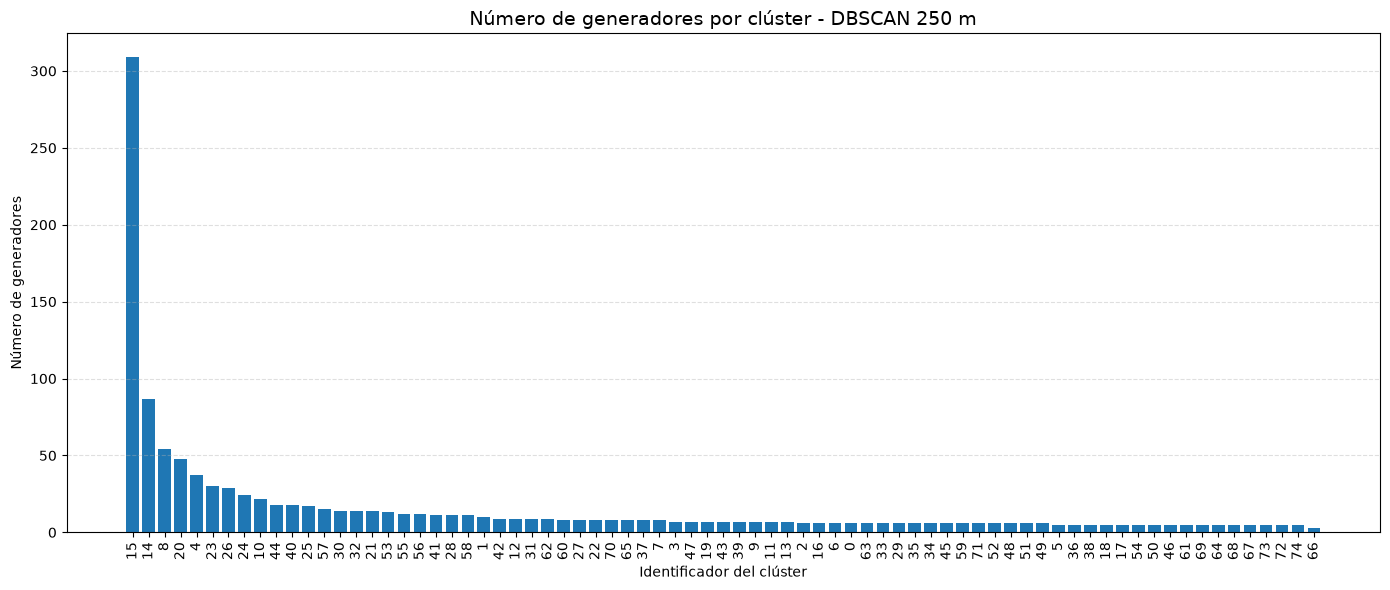

In [70]:

# ============================================================
# ETAPA 11.4. DISTRIBUCIÓN DEL TAMAÑO DE LOS CLÚSTERES
# ============================================================

import matplotlib.pyplot as plt

# Ordenar clústeres por cantidad de generadores
datos_grafica = resumen_caracterizacion.sort_values(
    by='numero_generadores',
    ascending=False
)

plt.figure(figsize=(14, 6))

plt.bar(
    datos_grafica['cluster'].astype(str),
    datos_grafica['numero_generadores']
)

plt.title(
    'Número de generadores por clúster - DBSCAN 250 m',
    fontsize=14
)

plt.xlabel('Identificador del clúster')
plt.ylabel('Número de generadores')

plt.xticks(rotation=90)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.4
)

plt.tight_layout()
plt.show()


In [71]:

# ============================================================
# ETAPA 11.5. CLASIFICACIÓN DE CLÚSTERES POR TAMAÑO
# ============================================================

# Calcular percentiles de la cantidad de generadores
p25 = resumen_caracterizacion['numero_generadores'].quantile(0.25)
p50 = resumen_caracterizacion['numero_generadores'].quantile(0.50)
p75 = resumen_caracterizacion['numero_generadores'].quantile(0.75)

print("PERCENTILES DEL TAMAÑO DE LOS CLÚSTERES")
print("---------------------------------------")
print("Percentil 25:", p25)
print("Percentil 50 (mediana):", p50)
print("Percentil 75:", p75)

# Crear una clasificación según los cuartiles
def clasificar_cluster(cantidad):

    if cantidad <= p25:
        return 'Pequeño'

    elif cantidad <= p50:
        return 'Mediano'

    elif cantidad <= p75:
        return 'Grande'

    else:
        return 'Muy grande'

resumen_caracterizacion['categoria_tamano'] = (
    resumen_caracterizacion['numero_generadores'].apply(
        clasificar_cluster
    )
)

# Resumir cantidad de clústeres y generadores por categoría
resumen_tamanos = (
    resumen_caracterizacion
    .groupby('categoria_tamano')
    .agg(
        numero_clusters=('cluster', 'count'),
        total_generadores=('numero_generadores', 'sum'),
        promedio_generadores=('numero_generadores', 'mean')
    )
    .reset_index()
)

# Mostrar resultados
display(resumen_tamanos)

# Guardar resultados
ruta_categorias = (
    CARPETA_RESULTADOS / 'clasificacion_tamanos_clusters_250m.csv'
)

resumen_caracterizacion.to_csv(
    ruta_categorias,
    index=False,
    encoding='utf-8-sig'
)

print("\nClasificación guardada en:", ruta_categorias)


PERCENTILES DEL TAMAÑO DE LOS CLÚSTERES
---------------------------------------
Percentil 25: 6.0
Percentil 50 (mediana): 7.0
Percentil 75: 11.5


,categoria_tamano,numero_clusters,total_generadores,promedio_generadores
0,Grande,15,135,9.000000
1,Mediano,8,56,7.000000
2,Muy grande,19,787,41.421053
3,Pequeño,33,179,5.424242



Clasificación guardada en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\clasificacion_tamanos_clusters_250m.csv


In [72]:

# ============================================================
# ETAPA 12.1. DIAGNÓSTICO DE LA BASE DE GESTORES
# ============================================================

# Crear una copia para trabajar sin modificar la base original
gestores_analisis = gestores.copy()

print("DIAGNÓSTICO DE LA BASE DE GESTORES")
print("----------------------------------")

print("Número de registros:", len(gestores_analisis))
print("Número de variables:", len(gestores_analisis.columns))

print("\nColumnas disponibles:")
print(gestores_analisis.columns.tolist())

# ------------------------------------------------------------
# 1. Información general de las variables
# ------------------------------------------------------------

print("\nINFORMACIÓN GENERAL")
display(gestores_analisis.info())

# ------------------------------------------------------------
# 2. Valores faltantes
# ------------------------------------------------------------

faltantes_gestores = pd.DataFrame({
    'variable': gestores_analisis.columns,
    'valores_faltantes': gestores_analisis.isna().sum().values,
    'porcentaje_faltante': (
        gestores_analisis.isna().mean().values * 100
    ).round(2)
})

faltantes_gestores = faltantes_gestores.sort_values(
    by='porcentaje_faltante',
    ascending=False
)

print("\nVALORES FALTANTES POR VARIABLE")
display(faltantes_gestores)

# ------------------------------------------------------------
# 3. Registros duplicados
# ------------------------------------------------------------

print("\nREGISTROS DUPLICADOS")
print(
    "Filas completamente duplicadas:",
    gestores_analisis.duplicated().sum()
)

print(
    "IDs de gestores duplicados:",
    gestores_analisis['id_sitio_d'].duplicated().sum()
)

# ------------------------------------------------------------
# 4. Revisión de coordenadas
# ------------------------------------------------------------

gestores_analisis['longitud'] = pd.to_numeric(
    gestores_analisis['longitud'],
    errors='coerce'
)

gestores_analisis['latitud'] = pd.to_numeric(
    gestores_analisis['latitud'],
    errors='coerce'
)

coordenadas_validas = (
    gestores_analisis['longitud'].between(-180, 180) &
    gestores_analisis['latitud'].between(-90, 90) &
    gestores_analisis['longitud'].notna() &
    gestores_analisis['latitud'].notna()
)

print("\nREVISIÓN DE COORDENADAS")
print("Coordenadas válidas:", coordenadas_validas.sum())
print("Coordenadas no válidas:", (~coordenadas_validas).sum())

# ------------------------------------------------------------
# 5. Revisión de variables importantes
# ------------------------------------------------------------

print("\nVALORES ÚNICOS DE VARIABLES CLAVE")

for columna in [
    'categoria',
    'categoria_',
    'mat_a_disp',
    'aprobacion',
    'municipio',
    'capacidad_'
]:
    if columna in gestores_analisis.columns:
        print(f"\n{columna}:")
        print(
            gestores_analisis[columna]
            .value_counts(dropna=False)
            .head(20)
        )


DIAGNÓSTICO DE LA BASE DE GESTORES
----------------------------------
Número de registros: 28
Número de variables: 12

Columnas disponibles:
['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']

INFORMACIÓN GENERAL
<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id_sitio_d  28 non-null     int64  
 1   nomb_disp_  28 non-null     str    
 2   municipio   0 non-null      object 
 3   capacidad_  28 non-null     float64
 4   categoria   28 non-null     str    
 5   fech_creac  28 non-null     str    
 6   fech_actua  28 non-null     str    
 7   categoria_  28 non-null     str    
 8   mat_a_disp  28 non-null     str    
 9   aprobacion  28 non-null     str    
 10  longitud    28 non-null     float64
 11  latitud     28 non-null     float64
dtypes: fl

None


VALORES FALTANTES POR VARIABLE


,variable,valores_faltantes,porcentaje_faltante
2,municipio,28,100.0
0,id_sitio_d,0,0.0
1,nomb_disp_,0,0.0
3,capacidad_,0,0.0
4,categoria,0,0.0
5,fech_creac,0,0.0
6,fech_actua,0,0.0
7,categoria_,0,0.0
8,mat_a_disp,0,0.0
9,aprobacion,0,0.0



REGISTROS DUPLICADOS
Filas completamente duplicadas: 0
IDs de gestores duplicados: 0

REVISIÓN DE COORDENADAS
Coordenadas válidas: 28
Coordenadas no válidas: 0

VALORES ÚNICOS DE VARIABLES CLAVE

categoria:
categoria
3    19
1     5
2     4
Name: count, dtype: int64

categoria_:
categoria_
Recuperador                                19
Sitio de disposición final                  5
Centro de tratamiento y aprovechamiento     4
Name: count, dtype: int64

mat_a_disp:
mat_a_disp
Escombros, excavación y materiales esteriles                                                                                                                                                                                                                  5
Papel, cartón, plástico, PVC, Drywall, icopor (poliestireno expandido), madera y metales (acero, hierro, cobre, aluminio, zinc, estaño).                                                                                                                      2
Aprovech

In [73]:

# ==========================================
# ETAPA 12.1 - PREPARACIÓN DE LA BASE DE GESTORES
# ==========================================

import pandas as pd
import numpy as np

# Crear una copia para trabajar sin modificar la base original
gestores_limpios = gestores.copy()

# Convertir coordenadas a formato numérico
gestores_limpios['longitud'] = pd.to_numeric(
    gestores_limpios['longitud'], errors='coerce'
)

gestores_limpios['latitud'] = pd.to_numeric(
    gestores_limpios['latitud'], errors='coerce'
)

# Eliminar registros sin coordenadas válidas
gestores_limpios = gestores_limpios.dropna(
    subset=['longitud', 'latitud']
).copy()

# Eliminar espacios innecesarios en variables de texto
columnas_texto = gestores_limpios.select_dtypes(
    include=['object', 'str']
).columns

for columna in columnas_texto:
    gestores_limpios[columna] = (
        gestores_limpios[columna]
        .astype(str)
        .str.strip()
    )

# Reiniciar índices
gestores_limpios = gestores_limpios.reset_index(drop=True)

# Mostrar resultados
print("PREPARACIÓN DE LA BASE DE GESTORES")
print("----------------------------------")
print(f"Registros originales: {len(gestores)}")
print(f"Registros después de la limpieza: {len(gestores_limpios)}")
print(f"Registros excluidos: {len(gestores) - len(gestores_limpios)}")

print("\nCoordenadas:")
print(f"Longitudes válidas: {gestores_limpios['longitud'].notna().sum()}")
print(f"Latitudes válidas: {gestores_limpios['latitud'].notna().sum()}")

print("\nPrimeros registros:")
display(gestores_limpios.head())

# Guardar la base preparada
ruta_gestores_limpios = CARPETA_RESULTADOS / 'gestores_limpios.csv'
gestores_limpios.to_csv(
    ruta_gestores_limpios,
    index=False,
    encoding='utf-8-sig'
)

print(f"\nBase guardada en: {ruta_gestores_limpios}")


PREPARACIÓN DE LA BASE DE GESTORES
----------------------------------
Registros originales: 28
Registros después de la limpieza: 28
Registros excluidos: 0

Coordenadas:
Longitudes válidas: 28
Latitudes válidas: 28

Primeros registros:


,id_sitio_d,nomb_disp_,municipio,capacidad_,categoria,fech_creac,fech_actua,categoria_,mat_a_disp,aprobacion,longitud,latitud
0,2,HOLCIM MAQUINAS AMARILLAS,NaN,0.0,1,2013-01-31,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 1480 /04 Diciembre 2014,-74.129290,4.540869
1,3,FUNDACIÓN SAN ANTONIO,NaN,0.0,1,2013-01-31,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 0836 /16 Julio 2015,-74.124917,4.539283
2,5,CENTRAL DE MEZCLAS,NaN,0.0,1,2020-01-30,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución 1280/ 15 Junio 2017,-74.132539,4.548119
3,6,MAQUINAS AMARILLAS SAS,NaN,0.0,2,2019-04-03,2022-11-30,Centro de tratamiento y aprovechamiento,Aprovechamiento y tratamiento de RCD,Radicado SDA: 2019EE100840,-74.129290,4.540869
4,7,AMCON COLOMBIA SAS,NaN,0.0,2,2020-05-11,2022-11-30,Centro de tratamiento y aprovechamiento,Tratamiento y aprovechamiento de residuos de o...,Radicado SDA: 2020EE84482,-74.149480,4.690445



Base guardada en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\gestores_limpios.csv


In [74]:

# ==========================================
# ETAPA 12.2 - CARACTERIZACIÓN DE LOS GESTORES
# ==========================================

variables_categoricas = [
    'categoria',
    'categoria_',
    'mat_a_disp',
    'aprobacion'
]

for variable in variables_categoricas:

    print("\n" + "=" * 60)
    print(f"DISTRIBUCIÓN DE: {variable}")
    print("=" * 60)

    if variable in gestores_limpios.columns:

        frecuencias = (
            gestores_limpios[variable]
            .fillna('Sin información')
            .value_counts(dropna=False)
            .reset_index()
        )

        frecuencias.columns = ['valor', 'cantidad']

        frecuencias['porcentaje'] = (
            frecuencias['cantidad'] /
            len(gestores_limpios) * 100
        ).round(2)

        display(frecuencias)

    else:
        print(f"La variable {variable} no existe en la base.")

# Resumen de gestores por categoría descriptiva
resumen_categorias = (
    gestores_limpios
    .groupby('categoria_', dropna=False)
    .agg(
        numero_gestores=('id_sitio_d', 'count')
    )
    .reset_index()
)

resumen_categorias['porcentaje'] = (
    resumen_categorias['numero_gestores'] /
    len(gestores_limpios) * 100
).round(2)

print("\nRESUMEN POR TIPO DE GESTOR")
display(resumen_categorias)

# Guardar resumen
ruta_resumen_gestores = (
    CARPETA_RESULTADOS / 'resumen_categorias_gestores.csv'
)

resumen_categorias.to_csv(
    ruta_resumen_gestores,
    index=False,
    encoding='utf-8-sig'
)



DISTRIBUCIÓN DE: categoria


,valor,cantidad,porcentaje
0,3,19,67.86
1,1,5,17.86
2,2,4,14.29



DISTRIBUCIÓN DE: categoria_


,valor,cantidad,porcentaje
0,Recuperador,19,67.86
1,Sitio de disposición final,5,17.86
2,Centro de tratamiento y aprovechamiento,4,14.29



DISTRIBUCIÓN DE: mat_a_disp


,valor,cantidad,porcentaje
0,"Escombros, excavación y materiales esteriles",5,17.86
1,"Papel, cartón, plástico, PVC, Drywall, icopor ...",2,7.14
2,Aprovechamiento y tratamiento de RCD,1,3.57
3,Tratamiento y aprovechamiento de residuos de o...,1,3.57
4,Acopio y transformación de Drywall,1,3.57
5,La empresa Recolectora El Triunfo S.A.S. reali...,1,3.57
6,"La empresa Chatarrería Ambiental FM S.A.S., de...",1,3.57
7,La empresa Metales y varillas realiza dentro d...,1,3.57
8,Aprobado como Recuperador Específico de RCD ap...,1,3.57
9,Aprobado como Recuperador Específico de RCD: P...,1,3.57



DISTRIBUCIÓN DE: aprobacion


,valor,cantidad,porcentaje
0,Resolución ANLA 1480 /04 Diciembre 2014,2,7.14
1,Resolución ANLA 0836 /16 Julio 2015,1,3.57
2,Resolución 1280/ 15 Junio 2017,1,3.57
3,Radicado SDA: 2019EE100840,1,3.57
4,Radicado SDA: 2020EE84482,1,3.57
5,Radicado SDA: 2019EE301364,1,3.57
6,Radicado SDA - 2018ER50154 - 2018EE78872 y pro...,1,3.57
7,Radicado SDA: 2018EE266302,1,3.57
8,Radicado SDA: 2019EE20080,1,3.57
9,Radicado SDA: 2019EE56883,1,3.57



RESUMEN POR TIPO DE GESTOR


,categoria_,numero_gestores,porcentaje
0,Centro de tratamiento y aprovechamiento,4,14.29
1,Recuperador,19,67.86
2,Sitio de disposición final,5,17.86


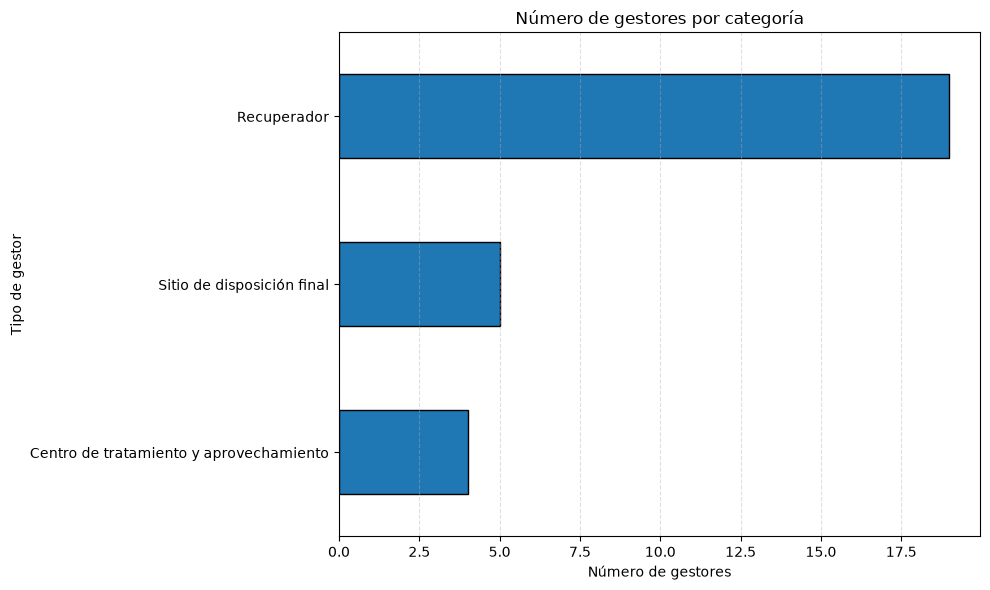

Gráfico guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\distribucion_tipos_gestores.png


In [75]:

# ==========================================
# ETAPA 12.3 - GRÁFICO DE TIPOS DE GESTORES
# ==========================================

import matplotlib.pyplot as plt

conteo_categorias = (
    gestores_limpios['categoria_']
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

conteo_categorias.plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Número de gestores por categoría')
plt.xlabel('Número de gestores')
plt.ylabel('Tipo de gestor')
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()

ruta_grafico_gestores = (
    CARPETA_RESULTADOS / 'distribucion_tipos_gestores.png'
)

plt.savefig(ruta_grafico_gestores, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {ruta_grafico_gestores}")


In [76]:

# ==========================================
# ETAPA 12.4 - MAPA DE GESTORES
# ==========================================

import folium

# Centro del mapa a partir de las coordenadas de los gestores
centro_gestores = [
    gestores_limpios['latitud'].mean(),
    gestores_limpios['longitud'].mean()
]

mapa_gestores = folium.Map(
    location=centro_gestores,
    zoom_start=11,
    tiles='OpenStreetMap'
)

# Colores por categoría
colores_gestores = {
    'Recuperador': 'green',
    'Sitio de disposición final': 'red',
    'Centro de tratamiento y aprovechamiento': 'blue'
}

# Crear una capa por categoría
for categoria in gestores_limpios['categoria_'].dropna().unique():

    grupo = gestores_limpios[
        gestores_limpios['categoria_'] == categoria
    ]

    color = colores_gestores.get(categoria, 'gray')

    capa = folium.FeatureGroup(
        name=f'{categoria} ({len(grupo)} gestores)',
        show=True
    )

    for _, fila in grupo.iterrows():

        popup = f"""
        <b>Gestor:</b> {fila['nomb_disp_']}<br>
        <b>ID:</b> {fila['id_sitio_d']}<br>
        <b>Categoría:</b> {fila['categoria_']}<br>
        <b>Materiales:</b> {fila['mat_a_disp']}<br>
        <b>Aprobación:</b> {fila['aprobacion']}
        """

        folium.CircleMarker(
            location=[fila['latitud'], fila['longitud']],
            radius=7,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.8,
            popup=folium.Popup(popup, max_width=350)
        ).add_to(capa)

    capa.add_to(mapa_gestores)

folium.LayerControl(collapsed=False).add_to(mapa_gestores)

# Guardar mapa
ruta_mapa_gestores = (
    CARPETA_RESULTADOS / 'mapa_ubicacion_gestores.html'
)

mapa_gestores.save(str(ruta_mapa_gestores))

print(f"Mapa guardado en: {ruta_mapa_gestores}")

mapa_gestores


Mapa guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_ubicacion_gestores.html


In [77]:

# ==========================================
# ETAPA 13.1 - DISTANCIA AL GESTOR MAS CERCANO
# ==========================================

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import haversine_distances

# Copiar la base de generadores depurados
generadores_cobertura = datos_cluster.copy()

# Incorporar las etiquetas del DBSCAN de 250 metros
generadores_cobertura['cluster_dbscan'] = (
    modelos_dbscan[250]['etiquetas']
)

# Coordenadas de generadores: [latitud, longitud]
coords_generadores = np.radians(
    generadores_cobertura[['latitud', 'longitud']].to_numpy()
)

# Coordenadas de gestores: [latitud, longitud]
coords_gestores = np.radians(
    gestores_limpios[['latitud', 'longitud']].to_numpy()
)

# Matriz de distancias Haversine
# Filas: generadores
# Columnas: gestores
radio_tierra_m = 6_371_000

matriz_distancias = haversine_distances(
    coords_generadores,
    coords_gestores
) * radio_tierra_m

# Identificar el gestor más cercano para cada generador
indice_gestor_cercano = np.argmin(
    matriz_distancias,
    axis=1
)

distancia_minima = np.min(
    matriz_distancias,
    axis=1
)

# Agregar resultados a la base
generadores_cobertura['distancia_gestor_cercano_m'] = (
    distancia_minima
)

generadores_cobertura['id_gestor_cercano'] = (
    gestores_limpios.iloc[indice_gestor_cercano]
    ['id_sitio_d'].to_numpy()
)

generadores_cobertura['nombre_gestor_cercano'] = (
    gestores_limpios.iloc[indice_gestor_cercano]
    ['nomb_disp_'].to_numpy()
)

generadores_cobertura['categoria_gestor_cercano'] = (
    gestores_limpios.iloc[indice_gestor_cercano]
    ['categoria_'].to_numpy()
)

# Convertir distancia a kilómetros
generadores_cobertura['distancia_gestor_cercano_km'] = (
    generadores_cobertura['distancia_gestor_cercano_m'] / 1000
)

# Mostrar resultados
print("DISTANCIA AL GESTOR MÁS CERCANO")
print("--------------------------------")
print(f"Generadores analizados: {len(generadores_cobertura)}")
print(
    "Distancia promedio (km):",
    round(generadores_cobertura['distancia_gestor_cercano_km'].mean(), 2)
)
print(
    "Distancia mediana (km):",
    round(generadores_cobertura['distancia_gestor_cercano_km'].median(), 2)
)
print(
    "Distancia mínima (km):",
    round(generadores_cobertura['distancia_gestor_cercano_km'].min(), 2)
)
print(
    "Distancia máxima (km):",
    round(generadores_cobertura['distancia_gestor_cercano_km'].max(), 2)
)

display(
    generadores_cobertura[
        [
            'idproy',
            'nombproy',
            'cluster_dbscan',
            'nombre_gestor_cercano',
            'categoria_gestor_cercano',
            'distancia_gestor_cercano_km'
        ]
    ].head(10)
)

# Guardar resultados
ruta_distancias = (
    CARPETA_RESULTADOS / 'distancias_generadores_gestores.csv'
)

generadores_cobertura.to_csv(
    ruta_distancias,
    index=False,
    encoding='utf-8-sig'
)

print(f"\nArchivo guardado en: {ruta_distancias}")


DISTANCIA AL GESTOR MÁS CERCANO
--------------------------------
Generadores analizados: 1990
Distancia promedio (km): 2.88
Distancia mediana (km): 2.94
Distancia mínima (km): 0.11
Distancia máxima (km): 9.89


,idproy,nombproy,cluster_dbscan,nombre_gestor_cercano,categoria_gestor_cercano,distancia_gestor_cercano_km
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,3.568983
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,-1,PAPELES EL NORTE,Recuperador,4.213131
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",-1,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,3.095289
3,001360,ConstrucciÃ³n sede Ministerio de vivienda ciud...,35,GREEN WORLD J.E. SAS,Recuperador,1.472826
4,000286,SEGUNDA ETAPA OBRAS DE INTERVENCION CASA DE LA...,18,GREEN WORLD J.E. SAS,Recuperador,1.796332
5,000085,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,-1,PAPELES EL NORTE,Recuperador,4.213131
6,001384,Reforzamiento y RestauraciÃ³n del Gimnasio Mod...,44,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,4.139716
7,001773,ConstrucciÃ³n InstituciÃ³n Educativa RepÃºblic...,-1,GREEN WORLD J.E. SAS,Recuperador,3.787019
8,000475,AMERICA (CENTRO MUNDIAL NEGOCIOS)- PLAN PARCIA...,0,PAPELES EL NORTE,Recuperador,4.164952
9,001005,PolÃ­gono de protecciÃ³n por riesgo de Altos d...,-1,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,4.621894



Archivo guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\distancias_generadores_gestores.csv


In [78]:

# ==========================================
# ETAPA 13.2 - CLASIFICACION DE PROXIMIDAD
# ==========================================

def clasificar_distancia(distancia_km):

    if distancia_km <= 1:
        return 'Hasta 1 km'

    elif distancia_km <= 3:
        return 'Entre 1 y 3 km'

    elif distancia_km <= 5:
        return 'Entre 3 y 5 km'

    else:
        return 'Más de 5 km'


generadores_cobertura['rango_distancia'] = (
    generadores_cobertura['distancia_gestor_cercano_km']
    .apply(clasificar_distancia)
)

orden_rangos = [
    'Hasta 1 km',
    'Entre 1 y 3 km',
    'Entre 3 y 5 km',
    'Más de 5 km'
]

resumen_distancias = (
    generadores_cobertura['rango_distancia']
    .value_counts()
    .reindex(orden_rangos, fill_value=0)
    .reset_index()
)

resumen_distancias.columns = [
    'rango_distancia',
    'numero_generadores'
]

resumen_distancias['porcentaje'] = (
    resumen_distancias['numero_generadores'] /
    len(generadores_cobertura) * 100
).round(2)

print("GENERADORES SEGÚN DISTANCIA AL GESTOR MÁS CERCANO")
display(resumen_distancias)

# Guardar resumen
ruta_resumen_distancias = (
    CARPETA_RESULTADOS / 'resumen_distancias_gestores.csv'
)

resumen_distancias.to_csv(
    ruta_resumen_distancias,
    index=False,
    encoding='utf-8-sig'
)


GENERADORES SEGÚN DISTANCIA AL GESTOR MÁS CERCANO


,rango_distancia,numero_generadores,porcentaje
0,Hasta 1 km,154,7.74
1,Entre 1 y 3 km,893,44.87
2,Entre 3 y 5 km,829,41.66
3,Más de 5 km,114,5.73


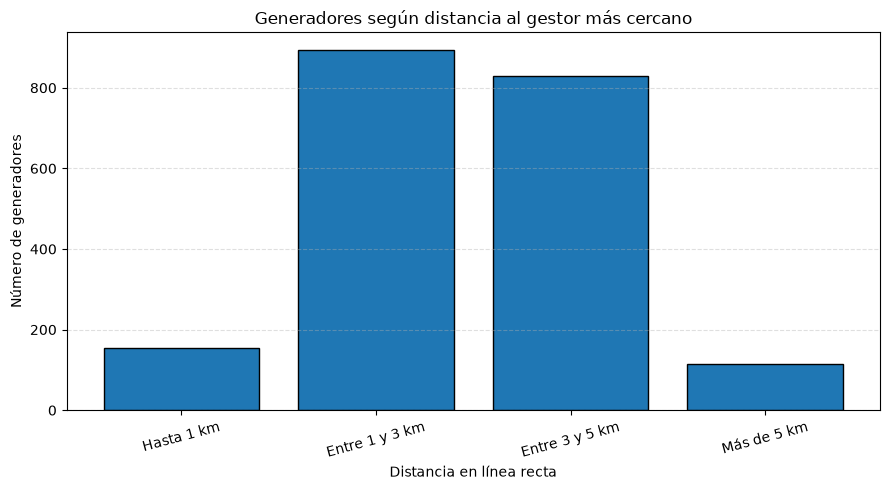

Gráfico guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\distribucion_distancias_gestores.png


In [79]:

# ==========================================
# ETAPA 13.3 - GRAFICO DE DISTANCIAS
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    resumen_distancias['rango_distancia'],
    resumen_distancias['numero_generadores'],
    edgecolor='black'
)

plt.title('Generadores según distancia al gestor más cercano')
plt.xlabel('Distancia en línea recta')
plt.ylabel('Número de generadores')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()

ruta_grafico_distancias = (
    CARPETA_RESULTADOS / 'distribucion_distancias_gestores.png'
)

plt.savefig(
    ruta_grafico_distancias,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(f"Gráfico guardado en: {ruta_grafico_distancias}")


In [80]:

# ==========================================
# ETAPA 13.4 - DISTANCIA AL GESTOR POR GENERADOR
# ==========================================

import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances

# 1. Crear copia de los generadores depurados
generadores_250 = datos_cluster.copy()

# Asociar las etiquetas de DBSCAN de 250 metros
generadores_250['cluster_dbscan'] = modelos_dbscan[250]['etiquetas']

# 2. Preparar coordenadas de generadores
generadores_250['latitud'] = pd.to_numeric(
    generadores_250['latitud'], errors='coerce'
)
generadores_250['longitud'] = pd.to_numeric(
    generadores_250['longitud'], errors='coerce'
)

generadores_250 = generadores_250.dropna(
    subset=['latitud', 'longitud']
).copy()

# 3. Preparar coordenadas de gestores
gestores_validos = gestores.copy()

gestores_validos['latitud'] = pd.to_numeric(
    gestores_validos['latitud'], errors='coerce'
)
gestores_validos['longitud'] = pd.to_numeric(
    gestores_validos['longitud'], errors='coerce'
)

gestores_validos = gestores_validos.dropna(
    subset=['latitud', 'longitud']
).copy()

# 4. Convertir coordenadas a radianes
coords_generadores = np.radians(
    generadores_250[['latitud', 'longitud']].to_numpy()
)

coords_gestores = np.radians(
    gestores_validos[['latitud', 'longitud']].to_numpy()
)

# 5. Calcular distancias Haversine
distancias = pairwise_distances(
    coords_generadores,
    coords_gestores,
    metric='haversine'
)

radio_tierra_m = 6_371_000
distancias_km = distancias * radio_tierra_m / 1000

# 6. Identificar el gestor más cercano
indices_gestor_cercano = np.argmin(distancias_km, axis=1)

generadores_250['distancia_gestor_cercano_km'] = (
    distancias_km[
        np.arange(len(generadores_250)),
        indices_gestor_cercano
    ]
)

# 7. Asociar información del gestor más cercano
gestores_cercanos = gestores_validos.iloc[
    indices_gestor_cercano
].reset_index(drop=True)

generadores_250 = generadores_250.reset_index(drop=True)

generadores_250['nombre_gestor_cercano'] = (
    gestores_cercanos['nomb_disp_']
)

generadores_250['categoria_gestor_cercano'] = (
    gestores_cercanos['categoria_']
)

generadores_250['materiales_gestor_cercano'] = (
    gestores_cercanos['mat_a_disp']
)

# 8. Crear rangos de distancia
generadores_250['rango_distancia'] = pd.cut(
    generadores_250['distancia_gestor_cercano_km'],
    bins=[0, 1, 3, 5, np.inf],
    labels=[
        'Hasta 1 km',
        'Entre 1 y 3 km',
        'Entre 3 y 5 km',
        'Más de 5 km'
    ],
    include_lowest=True
)

# 9. Mostrar resultados
print("GENERADORES CON INFORMACIÓN DEL GESTOR MÁS CERCANO")
print("-----------------------------------------------")
print(f"Generadores analizados: {len(generadores_250)}")
print(f"Gestores analizados: {len(gestores_validos)}")

display(
    generadores_250[
        [
            'idproy',
            'cluster_dbscan',
            'nombre_gestor_cercano',
            'categoria_gestor_cercano',
            'distancia_gestor_cercano_km',
            'rango_distancia'
        ]
    ].head(10)
)

# 10. Guardar resultados
ruta_distancias_cluster = (
    CARPETA_RESULTADOS / 'generadores_distancia_gestor_cluster_250m.csv'
)

generadores_250.to_csv(
    ruta_distancias_cluster,
    index=False,
    encoding='utf-8-sig'
)

print(f"\nArchivo guardado en: {ruta_distancias_cluster}")


GENERADORES CON INFORMACIÓN DEL GESTOR MÁS CERCANO
-----------------------------------------------
Generadores analizados: 1990
Gestores analizados: 28


,idproy,cluster_dbscan,nombre_gestor_cercano,categoria_gestor_cercano,distancia_gestor_cercano_km,rango_distancia
0,000991,-1,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,3.568983,Entre 3 y 5 km
1,000743,-1,PAPELES EL NORTE,Recuperador,4.213131,Entre 3 y 5 km
2,000321,-1,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,3.095289,Entre 3 y 5 km
3,001360,35,GREEN WORLD J.E. SAS,Recuperador,1.472826,Entre 1 y 3 km
4,000286,18,GREEN WORLD J.E. SAS,Recuperador,1.796332,Entre 1 y 3 km
5,000085,-1,PAPELES EL NORTE,Recuperador,4.213131,Entre 3 y 5 km
6,001384,44,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,4.139716,Entre 3 y 5 km
7,001773,-1,GREEN WORLD J.E. SAS,Recuperador,3.787019,Entre 3 y 5 km
8,000475,0,PAPELES EL NORTE,Recuperador,4.164952,Entre 3 y 5 km
9,001005,-1,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,4.621894,Entre 3 y 5 km



Archivo guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\generadores_distancia_gestor_cluster_250m.csv


In [81]:

# ==========================================
# ETAPA 13.5 - COBERTURA POR CLUSTER
# ==========================================

resumen_cobertura = (
    generadores_250
    .groupby('cluster_dbscan')
    .agg(
        numero_generadores=('idproy', 'count'),
        distancia_promedio_km=(
            'distancia_gestor_cercano_km', 'mean'
        ),
        distancia_mediana_km=(
            'distancia_gestor_cercano_km', 'median'
        ),
        distancia_maxima_km=(
            'distancia_gestor_cercano_km', 'max'
        ),
        generadores_mas_5km=(
            'distancia_gestor_cercano_km',
            lambda x: (x > 5).sum()
        )
    )
    .reset_index()
)

# Porcentaje de generadores a más de 5 km
resumen_cobertura['porcentaje_mas_5km'] = (
    resumen_cobertura['generadores_mas_5km']
    / resumen_cobertura['numero_generadores'] * 100
)

# Identificar la categoría de gestor más frecuente
categorias_frecuentes = (
    generadores_250
    .groupby('cluster_dbscan')['categoria_gestor_cercano']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'Sin dato')
    .reset_index(name='categoria_gestor_mas_frecuente')
)

resumen_cobertura = resumen_cobertura.merge(
    categorias_frecuentes,
    on='cluster_dbscan',
    how='left'
)

# Ordenar por distancia promedio, de mayor a menor
resumen_cobertura = resumen_cobertura.sort_values(
    'distancia_promedio_km',
    ascending=False
)

print("COBERTURA DE GESTORES POR CLÚSTER - DBSCAN 250 m")
print("------------------------------------------------")

display(
    resumen_cobertura.round(2)
)

# Guardar resultados
ruta_resumen_cobertura = (
    CARPETA_RESULTADOS / 'resumen_cobertura_clusters_250m.csv'
)

resumen_cobertura.to_csv(
    ruta_resumen_cobertura,
    index=False,
    encoding='utf-8-sig'
)

print(f"\nResumen guardado en: {ruta_resumen_cobertura}")


COBERTURA DE GESTORES POR CLÚSTER - DBSCAN 250 m
------------------------------------------------


,cluster_dbscan,numero_generadores,distancia_promedio_km,distancia_mediana_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km,categoria_gestor_mas_frecuente
23,22,8,6.56,6.57,6.69,8,100.00,Recuperador
65,64,5,6.45,6.46,6.51,5,100.00,Sitio de disposición final
62,61,5,6.10,6.11,6.24,5,100.00,Recuperador
18,17,5,6.06,6.00,6.14,5,100.00,Recuperador
54,53,13,5.10,5.01,5.38,11,84.62,Recuperador
...,...,...,...,...,...,...,...,...
71,70,8,0.84,0.82,0.96,0,0.00,Recuperador
68,67,5,0.66,0.66,0.67,0,0.00,Recuperador
30,29,6,0.44,0.43,0.53,0,0.00,Recuperador
17,16,6,0.41,0.39,0.56,0,0.00,Recuperador



Resumen guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\resumen_cobertura_clusters_250m.csv


In [82]:

# ==========================================
# ETAPA 13.6 - PRIORIZACION DE CLUSTERS
# ==========================================

# 1. Separar los clústeres reales del ruido
# El valor -1 representa generadores que DBSCAN no agrupó.

clusters_reales = resumen_cobertura[
    resumen_cobertura['cluster_dbscan'] != -1
].copy()

ruido = generadores_250[
    generadores_250['cluster_dbscan'] == -1
].copy()

# 2. Ordenar clústeres según el número de generadores
# que están a más de 5 km de su gestor más cercano.

clusters_prioritarios = clusters_reales.sort_values(
    by=[
        'generadores_mas_5km',
        'porcentaje_mas_5km',
        'numero_generadores'
    ],
    ascending=[False, False, False]
).copy()

# 3. Crear una clasificación preliminar
def clasificar_prioridad(fila):
    if fila['generadores_mas_5km'] == 0:
        return 'Sin alerta por distancia'
    elif (
        fila['porcentaje_mas_5km'] >= 75
        and fila['generadores_mas_5km'] >= 5
    ):
        return 'Prioridad alta'
    elif fila['porcentaje_mas_5km'] >= 50:
        return 'Prioridad media'
    else:
        return 'Prioridad por seguimiento'

clusters_prioritarios['prioridad'] = (
    clusters_prioritarios.apply(clasificar_prioridad, axis=1)
)

# 4. Mostrar los 15 clústeres con mayor número
# de generadores a más de 5 km.

columnas_resultado = [
    'cluster_dbscan',
    'numero_generadores',
    'generadores_mas_5km',
    'porcentaje_mas_5km',
    'distancia_promedio_km',
    'distancia_maxima_km',
    'prioridad'
]

print("15 CLUSTERS CON MAYOR NUMERO DE GENERADORES A MAS DE 5 KM")
print("----------------------------------------------------------")

display(
    clusters_prioritarios[columnas_resultado]
    .head(15)
    .round(2)
)

# 5. Resumen independiente de los generadores clasificados como ruido

print("\nGENERADORES CLASIFICADOS COMO RUIDO")
print("-----------------------------------")
print(f"Total de generadores: {len(ruido)}")

if len(ruido) > 0:
    print(
        "Distancia promedio al gestor más cercano (km):",
        round(ruido['distancia_gestor_cercano_km'].mean(), 2)
    )
    print(
        "Generadores a más de 5 km:",
        (ruido['distancia_gestor_cercano_km'] > 5).sum()
    )
    print(
        "Porcentaje a más de 5 km:",
        round(
            (ruido['distancia_gestor_cercano_km'] > 5).mean() * 100,
            2
        )
    )

# 6. Comprobar que los generadores a más de 5 km
# coincidan con el análisis general.

total_mas_5km = (
    generadores_250['distancia_gestor_cercano_km'] > 5
).sum()

print("\nVALIDACIÓN GENERAL")
print("------------------")
print(f"Total de generadores: {len(generadores_250)}")
print(f"Generadores a más de 5 km: {total_mas_5km}")

# 7. Guardar el ranking completo
ruta_prioridades = (
    CARPETA_RESULTADOS / 'priorizacion_clusters_cobertura_250m.csv'
)

clusters_prioritarios.to_csv(
    ruta_prioridades,
    index=False,
    encoding='utf-8-sig'
)

print(f"\nRanking guardado en: {ruta_prioridades}")


15 CLUSTERS CON MAYOR NUMERO DE GENERADORES A MAS DE 5 KM
----------------------------------------------------------


,cluster_dbscan,numero_generadores,generadores_mas_5km,porcentaje_mas_5km,distancia_promedio_km,distancia_maxima_km,prioridad
54,53,13,11,84.62,5.10,5.38,Prioridad alta
23,22,8,8,100.00,6.56,6.69,Prioridad alta
42,41,11,7,63.64,5.08,5.30,Prioridad media
60,59,6,6,100.00,5.08,5.13,Prioridad alta
40,39,7,6,85.71,5.10,5.22,Prioridad alta
43,42,9,6,66.67,5.06,5.32,Prioridad media
65,64,5,5,100.00,6.45,6.51,Prioridad alta
62,61,5,5,100.00,6.10,6.24,Prioridad alta
18,17,5,5,100.00,6.06,6.14,Prioridad alta
16,15,309,0,0.00,3.40,4.90,Sin alerta por distancia



GENERADORES CLASIFICADOS COMO RUIDO
-----------------------------------
Total de generadores: 833
Distancia promedio al gestor más cercano (km): 2.8
Generadores a más de 5 km: 55
Porcentaje a más de 5 km: 6.6

VALIDACIÓN GENERAL
------------------
Total de generadores: 1990
Generadores a más de 5 km: 114

Ranking guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\priorizacion_clusters_cobertura_250m.csv


In [83]:

# ==========================================
# ETAPA 13.7 - MAPA DE PRIORIZACION TERRITORIAL
# ==========================================

import folium

# 1. Colores por nivel de prioridad

colores_prioridad = {
    'Prioridad alta': 'red',
    'Prioridad media': 'orange',
    'Prioridad por seguimiento': 'purple',
    'Sin alerta por distancia': 'green'
}

# 2. Relacionar cada cluster con su prioridad

prioridades_por_cluster = (
    clusters_prioritarios
    .set_index('cluster_dbscan')['prioridad']
    .to_dict()
)

# 3. Preparar los generadores

datos_mapa_prioridad = generadores_250.copy()

datos_mapa_prioridad['prioridad'] = (
    datos_mapa_prioridad['cluster_dbscan']
    .map(prioridades_por_cluster)
)

datos_mapa_prioridad.loc[
    datos_mapa_prioridad['cluster_dbscan'] == -1,
    'prioridad'
] = 'Ruido DBSCAN'

# 4. Crear el mapa sin mapa base inicial

centro_mapa = [
    datos_mapa_prioridad['latitud'].mean(),
    datos_mapa_prioridad['longitud'].mean()
]

mapa_prioridades = folium.Map(
    location=centro_mapa,
    zoom_start=11,
    tiles=None
)

# 5. Agregar mapa base de Esri

folium.TileLayer(
    tiles=(
        'https://server.arcgisonline.com/ArcGIS/rest/services/'
        'World_Street_Map/MapServer/tile/{z}/{y}/{x}'
    ),
    attr='Tiles © Esri',
    name='Mapa de calles - Esri',
    overlay=False,
    control=True
).add_to(mapa_prioridades)

# 6. Dibujar los clusters según su prioridad

for prioridad, color in colores_prioridad.items():

    grupo = datos_mapa_prioridad[
        datos_mapa_prioridad['prioridad'] == prioridad
    ]

    capa = folium.FeatureGroup(
        name=f'{prioridad} ({len(grupo)} generadores)',
        show=True
    )

    for _, fila in grupo.iterrows():

        folium.CircleMarker(
            location=[
                fila['latitud'],
                fila['longitud']
            ],
            radius=4,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75,
            weight=1,
            popup=(
                f"ID: {fila['idproy']}<br>"
                f"Proyecto: {fila['nombproy']}<br>"
                f"Cluster: {fila['cluster_dbscan']}<br>"
                f"Prioridad: {prioridad}<br>"
                f"Distancia al gestor más cercano: "
                f"{fila['distancia_gestor_cercano_km']:.2f} km"
            )
        ).add_to(capa)

    capa.add_to(mapa_prioridades)

# 7. Agregar los generadores clasificados como ruido

grupo_ruido = datos_mapa_prioridad[
    datos_mapa_prioridad['prioridad'] == 'Ruido DBSCAN'
]

capa_ruido = folium.FeatureGroup(
    name=f'Ruido DBSCAN ({len(grupo_ruido)} generadores)',
    show=True
)

for _, fila in grupo_ruido.iterrows():

    folium.CircleMarker(
        location=[
            fila['latitud'],
            fila['longitud']
        ],
        radius=3,
        color='gray',
        fill=True,
        fill_color='gray',
        fill_opacity=0.6,
        weight=1,
        popup=(
            f"ID: {fila['idproy']}<br>"
            f"Proyecto: {fila['nombproy']}<br>"
            f"Clasificación: Ruido DBSCAN<br>"
            f"Distancia al gestor más cercano: "
            f"{fila['distancia_gestor_cercano_km']:.2f} km"
        )
    ).add_to(capa_ruido)

capa_ruido.add_to(mapa_prioridades)

# 8. Agregar control de capas

folium.LayerControl(collapsed=False).add_to(mapa_prioridades)

# 9. Guardar mapa

ruta_mapa_prioridades = (
    CARPETA_RESULTADOS / 'mapa_priorizacion_territorial_250m.html'
)

mapa_prioridades.save(str(ruta_mapa_prioridades))

print("MAPA DE PRIORIZACION TERRITORIAL")
print("--------------------------------")
print(f"Generadores representados: {len(datos_mapa_prioridad)}")
print(f"Prioridad alta: {(datos_mapa_prioridad['prioridad'] == 'Prioridad alta').sum()}")
print(f"Prioridad media: {(datos_mapa_prioridad['prioridad'] == 'Prioridad media').sum()}")
print(f"Sin alerta: {(datos_mapa_prioridad['prioridad'] == 'Sin alerta por distancia').sum()}")
print(f"Ruido DBSCAN: {len(grupo_ruido)}")
print(f"\nMapa guardado en: {ruta_mapa_prioridades}")


MAPA DE PRIORIZACION TERRITORIAL
--------------------------------
Generadores representados: 1990
Prioridad alta: 49
Prioridad media: 20
Sin alerta: 1088
Ruido DBSCAN: 833

Mapa guardado en: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\mapa_priorizacion_territorial_250m.html


In [84]:

# ==========================================
# ETAPA 13.7 - CLASIFICACION TERRITORIAL DE GENERADORES
# ==========================================

# 1. Crear una copia de la base de generadores
generadores_priorizados = generadores_250.copy()

# 2. Construir una tabla con la prioridad de cada cluster
tabla_prioridades = clusters_prioritarios[
    ['cluster_dbscan', 'prioridad']
].copy()

# 3. Incorporar la prioridad a cada generador
generadores_priorizados = generadores_priorizados.merge(
    tabla_prioridades,
    on='cluster_dbscan',
    how='left'
)

# 4. Clasificar los registros que DBSCAN identificó como ruido
generadores_priorizados.loc[
    generadores_priorizados['cluster_dbscan'] == -1,
    'prioridad'
] = 'Ruido DBSCAN'

# 5. Mostrar el número de generadores por categoría
resumen_prioridades_generadores = (
    generadores_priorizados['prioridad']
    .value_counts()
    .reset_index()
)

resumen_prioridades_generadores.columns = [
    'categoria_prioridad',
    'numero_generadores'
]

resumen_prioridades_generadores['porcentaje'] = (
    resumen_prioridades_generadores['numero_generadores']
    / len(generadores_priorizados) * 100
)

print("CLASIFICACION TERRITORIAL DE GENERADORES")
print("----------------------------------------")
print(f"Total de generadores: {len(generadores_priorizados)}")

display(
    resumen_prioridades_generadores.round(2)
)

# 6. Validar que todos los generadores hayan sido clasificados
print("\nVALIDACION")
print("----------")
print(
    "Generadores clasificados:",
    generadores_priorizados['prioridad'].notna().sum()
)
print(
    "Generadores sin clasificar:",
    generadores_priorizados['prioridad'].isna().sum()
)

# 7. Guardar la base completa
ruta_generadores_priorizados = (
    CARPETA_RESULTADOS / 'generadores_priorizados_250m.csv'
)

generadores_priorizados.to_csv(
    ruta_generadores_priorizados,
    index=False,
    encoding='utf-8-sig'
)

# 8. Guardar el resumen
ruta_resumen_prioridades = (
    CARPETA_RESULTADOS / 'resumen_prioridades_generadores_250m.csv'
)

resumen_prioridades_generadores.to_csv(
    ruta_resumen_prioridades,
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivos guardados correctamente:")
print(ruta_generadores_priorizados)
print(ruta_resumen_prioridades)


CLASIFICACION TERRITORIAL DE GENERADORES
----------------------------------------
Total de generadores: 1990


,categoria_prioridad,numero_generadores,porcentaje
0,Sin alerta por distancia,1088,54.67
1,Ruido DBSCAN,833,41.86
2,Prioridad alta,49,2.46
3,Prioridad media,20,1.01



VALIDACION
----------
Generadores clasificados: 1990
Generadores sin clasificar: 0

Archivos guardados correctamente:
C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\generadores_priorizados_250m.csv
C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados\resumen_prioridades_generadores_250m.csv


In [85]:

# ==========================================
# ETAPA 13.8 - DIAGNOSTICO DE COMPATIBILIDAD
# ==========================================

import pandas as pd

# Variables que esperamos encontrar en la matriz
columnas_compatibilidad = [
    'ID_gestor',
    'Codigo_residuo',
    'Modalidad',
    'Estado_compatibilidad'
]

print("DIAGNOSTICO DE BASES DE COMPATIBILIDAD")
print("--------------------------------------")

bases_encontradas = []

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):

        columnas = list(objeto.columns)

        coincidencias = [
            columna for columna in columnas_compatibilidad
            if columna in columnas
        ]

        if len(coincidencias) > 0:

            bases_encontradas.append({
                'nombre_base': nombre,
                'numero_registros': len(objeto),
                'numero_variables': len(columnas),
                'variables_encontradas': coincidencias,
                'columnas_completas': columnas
            })

if len(bases_encontradas) > 0:

    for base in bases_encontradas:

        print("\nBase:", base['nombre_base'])
        print("Registros:", base['numero_registros'])
        print("Variables:", base['numero_variables'])
        print("Coincidencias:", base['variables_encontradas'])
        print("Columnas:", base['columnas_completas'])

else:

    print("No se encontró una matriz con las variables esperadas.")
    print("\nDataFrames disponibles:")

    for nombre, objeto in globals().copy().items():

        if isinstance(objeto, pd.DataFrame):

            print(
                nombre,
                "| Registros:", len(objeto),
                "| Columnas:", list(objeto.columns)
            )


DIAGNOSTICO DE BASES DE COMPATIBILIDAD
--------------------------------------

Base: inventario_gestores
Registros: 28
Variables: 7
Coincidencias: ['ID_gestor']
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Materiales_aceptados_reportados', 'Aprobacion_reportada', 'Longitud', 'Latitud']

Base: matriz_compatibilidad
Registros: 364
Variables: 10
Coincidencias: ['ID_gestor', 'Codigo_residuo', 'Modalidad', 'Estado_compatibilidad']
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'Evidencia', 'Descripcion_original', 'Aprobacion_reportada']

Base: resumen
Registros: 83
Variables: 6
Coincidencias: ['ID_gestor', 'Modalidad', 'Estado_compatibilidad']
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Estado_compatibilidad', 'Cantidad_de_tipos']

Base: resultados_gestores
Registros: 7
Variables: 4
Coincidencias: ['ID_gestor']
Columnas: ['ID_gestor', 'Nombre_gestor', 'Estado_general', 'Categoria

In [86]:

# ==========================================
# ETAPA 13.8.2 - ANALISIS DE MATRIZ DE COMPATIBILIDAD
# ==========================================

# Trabajar sobre una copia
matriz_analisis = matriz_compatibilidad.copy()

# 1. Revisar dimensiones y registros
print("DIMENSIONES DE LA MATRIZ")
print("------------------------")
print(f"Registros: {len(matriz_analisis)}")
print(f"Variables: {len(matriz_analisis.columns)}")

# 2. Revisar valores únicos de las variables principales

variables_revisar = [
    'Categoria',
    'Modalidad',
    'Codigo_residuo',
    'Tipo_residuo',
    'Estado_compatibilidad'
]

for variable in variables_revisar:

    print(f"\nVALORES DE: {variable}")
    print("-" * 55)

    print(
        matriz_analisis[variable]
        .value_counts(dropna=False)
        .to_string()
    )

# 3. Revisar registros faltantes

print("\n\nDATOS FALTANTES")
print("----------------")

faltantes = pd.DataFrame({
    'variable': matriz_analisis.columns,
    'faltantes': matriz_analisis.isna().sum().values,
    'porcentaje_faltante': (
        matriz_analisis.isna().mean().values * 100
    )
})

display(faltantes.round(2))

# 4. Distribución general de estados de compatibilidad

print("\nDISTRIBUCION DE ESTADOS DE COMPATIBILIDAD")
print("-----------------------------------------")

resumen_estados = (
    matriz_analisis['Estado_compatibilidad']
    .value_counts(dropna=False)
    .reset_index()
)

resumen_estados.columns = [
    'estado_compatibilidad',
    'cantidad'
]

resumen_estados['porcentaje'] = (
    resumen_estados['cantidad']
    / len(matriz_analisis) * 100
)

display(resumen_estados.round(2))

# 5. Revisar cantidad de gestores y residuos

print("\nCOBERTURA DE LA MATRIZ")
print("----------------------")

print(
    "Gestores únicos:",
    matriz_analisis['ID_gestor'].nunique()
)

print(
    "Códigos de residuos únicos:",
    matriz_analisis['Codigo_residuo'].nunique()
)

print(
    "Modalidades únicas:",
    matriz_analisis['Modalidad'].nunique()
)

# 6. Revisar posibles duplicados

print("\nREGISTROS DUPLICADOS")
print("--------------------")

columnas_clave = [
    'ID_gestor',
    'Modalidad',
    'Codigo_residuo'
]

print(
    "Duplicados según gestor, modalidad y código:",
    matriz_analisis.duplicated(
        subset=columnas_clave
    ).sum()
)


DIMENSIONES DE LA MATRIZ
------------------------
Registros: 364
Variables: 10

VALORES DE: Categoria
-------------------------------------------------------
Categoria
Recuperador                                247
Sitio de disposición final                  65
Centro de tratamiento y aprovechamiento     52

VALORES DE: Modalidad
-------------------------------------------------------
Modalidad
Separado    336
Mezclado     28

VALORES DE: Codigo_residuo
-------------------------------------------------------
Codigo_residuo
R01        28
R02        28
R03        28
R04        28
R05        28
R06        28
R07        28
R08        28
R09        28
R10        28
R11        28
R12        28
RCD_MIX    28

VALORES DE: Tipo_residuo
-------------------------------------------------------
Tipo_residuo
Concreto y residuos cementicios        28
Ladrillos, bloques y ceramicos         28
Material de excavacion y tierras       28
Arenas, gravas y materiales petreos    28
Madera                    

,variable,faltantes,porcentaje_faltante
0,ID_gestor,0,0.0
1,Nombre_gestor,0,0.0
2,Categoria,0,0.0
3,Modalidad,0,0.0
4,Codigo_residuo,0,0.0
5,Tipo_residuo,0,0.0
6,Estado_compatibilidad,0,0.0
7,Evidencia,0,0.0
8,Descripcion_original,0,0.0
9,Aprobacion_reportada,0,0.0



DISTRIBUCION DE ESTADOS DE COMPATIBILIDAD
-----------------------------------------


,estado_compatibilidad,cantidad,porcentaje
0,No identificado como compatible,240,65.93
1,Compatible reportado,106,29.12
2,Pendiente de verificacion,18,4.95



COBERTURA DE LA MATRIZ
----------------------
Gestores únicos: 28
Códigos de residuos únicos: 13
Modalidades únicas: 2

REGISTROS DUPLICADOS
--------------------
Duplicados según gestor, modalidad y código: 0


In [87]:

# ============================================================
# ETAPA 13.8.3
# ANALISIS DETALLADO DE COMPATIBILIDAD
# ============================================================

matriz_detalle = matriz_compatibilidad.copy()

# ------------------------------------------------------------
# 1. COMPATIBILIDAD POR TIPO DE RESIDUO
# ------------------------------------------------------------

compatibilidad_residuos = (
    matriz_detalle
    .groupby(
        ['Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad']
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Calcular total de registros por residuo
columnas_estados = [
    col for col in compatibilidad_residuos.columns
    if col not in ['Codigo_residuo', 'Tipo_residuo']
]

compatibilidad_residuos['Total_registros'] = (
    compatibilidad_residuos[columnas_estados].sum(axis=1)
)

# Porcentaje de compatibilidad reportada
if 'Compatible reportado' in compatibilidad_residuos.columns:
    compatibilidad_residuos['Porcentaje_compatible_reportado'] = (
        compatibilidad_residuos['Compatible reportado']
        / compatibilidad_residuos['Total_registros'] * 100
    )
else:
    compatibilidad_residuos['Porcentaje_compatible_reportado'] = 0

compatibilidad_residuos = compatibilidad_residuos.sort_values(
    'Porcentaje_compatible_reportado',
    ascending=False
)

print("COMPATIBILIDAD POR TIPO DE RESIDUO")
display(compatibilidad_residuos)


# ------------------------------------------------------------
# 2. COMPATIBILIDAD POR CATEGORIA DE GESTOR
# ------------------------------------------------------------

compatibilidad_categorias = (
    matriz_detalle
    .groupby(['Categoria', 'Estado_compatibilidad'])
    .size()
    .unstack(fill_value=0)
)

compatibilidad_categorias['Total_registros'] = (
    compatibilidad_categorias.sum(axis=1)
)

if 'Compatible reportado' in compatibilidad_categorias.columns:
    compatibilidad_categorias['Porcentaje_compatible_reportado'] = (
        compatibilidad_categorias['Compatible reportado']
        / compatibilidad_categorias['Total_registros'] * 100
    )

print("\nCOMPATIBILIDAD POR CATEGORIA DE GESTOR")
display(compatibilidad_categorias)


# ------------------------------------------------------------
# 3. COMPATIBILIDAD POR MODALIDAD
# ------------------------------------------------------------

compatibilidad_modalidades = (
    matriz_detalle
    .groupby(['Modalidad', 'Estado_compatibilidad'])
    .size()
    .unstack(fill_value=0)
)

compatibilidad_modalidades['Total_registros'] = (
    compatibilidad_modalidades.sum(axis=1)
)

if 'Compatible reportado' in compatibilidad_modalidades.columns:
    compatibilidad_modalidades['Porcentaje_compatible_reportado'] = (
        compatibilidad_modalidades['Compatible reportado']
        / compatibilidad_modalidades['Total_registros'] * 100
    )

print("\nCOMPATIBILIDAD POR MODALIDAD")
display(compatibilidad_modalidades)


# ------------------------------------------------------------
# 4. RESUMEN POR GESTOR
# ------------------------------------------------------------

compatibilidad_gestores = (
    matriz_detalle
    .groupby(['ID_gestor', 'Nombre_gestor', 'Categoria'])
    .agg(
        total_registros=('Codigo_residuo', 'count'),
        residuos_compatibles_reportados=(
            'Estado_compatibilidad',
            lambda x: (x == 'Compatible reportado').sum()
        ),
        pendientes=(
            'Estado_compatibilidad',
            lambda x: (x == 'Pendiente de verificacion').sum()
        ),
        no_identificados=(
            'Estado_compatibilidad',
            lambda x: (x == 'No identificado como compatible').sum()
        ),
        tipos_residuo=('Tipo_residuo', 'nunique')
    )
    .reset_index()
)

compatibilidad_gestores['Porcentaje_compatible_reportado'] = (
    compatibilidad_gestores['residuos_compatibles_reportados']
    / compatibilidad_gestores['total_registros'] * 100
)

compatibilidad_gestores = compatibilidad_gestores.sort_values(
    ['Porcentaje_compatible_reportado',
     'residuos_compatibles_reportados'],
    ascending=False
)

print("\nRESUMEN DE COMPATIBILIDAD POR GESTOR")
display(compatibilidad_gestores)


# ------------------------------------------------------------
# 5. GUARDAR RESULTADOS
# ------------------------------------------------------------

compatibilidad_residuos.to_csv(
    CARPETA_RESULTADOS / 'compatibilidad_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

compatibilidad_categorias.to_csv(
    CARPETA_RESULTADOS / 'compatibilidad_por_categoria.csv',
    encoding='utf-8-sig'
)

compatibilidad_modalidades.to_csv(
    CARPETA_RESULTADOS / 'compatibilidad_por_modalidad.csv',
    encoding='utf-8-sig'
)

compatibilidad_gestores.to_csv(
    CARPETA_RESULTADOS / 'compatibilidad_por_gestor.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivos de análisis guardados correctamente.")


COMPATIBILIDAD POR TIPO DE RESIDUO


Estado_compatibilidad,Codigo_residuo,Tipo_residuo,Compatible reportado,No identificado como compatible,Pendiente de verificacion,Total_registros,Porcentaje_compatible_reportado
5,R06,Metales,17,10,1,28,60.714286
6,R07,Plastico y PVC,17,10,1,28,60.714286
7,R08,Papel y carton,16,11,1,28,57.142857
8,R09,Drywall,16,11,1,28,57.142857
4,R05,Madera,16,11,1,28,57.142857
9,R10,Icopor,10,17,1,28,35.714286
2,R03,Material de excavacion y tierras,6,21,1,28,21.428571
10,R11,Vidrio,3,24,1,28,10.714286
3,R04,"Arenas, gravas y materiales petreos",2,25,1,28,7.142857
1,R02,"Ladrillos, bloques y ceramicos",1,26,1,28,3.571429



COMPATIBILIDAD POR CATEGORIA DE GESTOR


Estado_compatibilidad,Compatible reportado,No identificado como compatible,Pendiente de verificacion,Total_registros,Porcentaje_compatible_reportado
Categoria,,,,,
Centro de tratamiento y aprovechamiento,7,32,13,52,13.461538
Recuperador,94,153,0,247,38.056680
Sitio de disposición final,5,55,5,65,7.692308



COMPATIBILIDAD POR MODALIDAD


Estado_compatibilidad,Compatible reportado,No identificado como compatible,Pendiente de verificacion,Total_registros,Porcentaje_compatible_reportado
Modalidad,,,,,
Mezclado,0,22,6,28,0.000000
Separado,106,218,12,336,31.547619



RESUMEN DE COMPATIBILIDAD POR GESTOR


,ID_gestor,Nombre_gestor,Categoria,total_registros,residuos_compatibles_reportados,pendientes,no_identificados,tipos_residuo,Porcentaje_compatible_reportado
14,15,EXIRECICLABLES MC S.A.S.,Recuperador,13,7,0,6,13,53.846154
11,12,METALES & VARILLAS A.M S.A.S.,Recuperador,13,6,0,7,13,46.153846
13,14,RECUPERADORA AMBIENTAL LAS VEGAS,Recuperador,13,6,0,7,13,46.153846
18,19,BIORECICLAJE CASALLAS & S.A.S.,Recuperador,13,6,0,7,13,46.153846
24,25,GLOBO METAL F.M S.A.S,Recuperador,13,6,0,7,13,46.153846
25,26,CAR INGENIERÍA S.A.S.,Recuperador,13,6,0,7,13,46.153846
26,27,DEPÓSITO SAN VICENTE 1 S.A.S,Recuperador,13,6,0,7,13,46.153846
27,28,GREEN WORLD J.E. SAS,Recuperador,13,6,0,7,13,46.153846
8,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,13,5,0,8,13,38.461538
9,10,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,13,5,0,8,13,38.461538



Archivos de análisis guardados correctamente.


In [88]:

# ============================================================
# ETAPA 13.8.4
# MATRIZ DE COMPATIBILIDAD POR GESTOR Y RESIDUO
# ============================================================

matriz_detalle = matriz_compatibilidad.copy()

# ------------------------------------------------------------
# 1. CONSTRUIR MATRIZ GESTOR x RESIDUO
# ------------------------------------------------------------

matriz_gestor_residuo = matriz_detalle.pivot(
    index=['ID_gestor', 'Nombre_gestor', 'Categoria'],
    columns='Codigo_residuo',
    values='Estado_compatibilidad'
).reset_index()

print("MATRIZ DE COMPATIBILIDAD POR GESTOR Y RESIDUO")
display(matriz_gestor_residuo)


# ------------------------------------------------------------
# 2. IDENTIFICAR COMPATIBILIDADES REPORTADAS
# ------------------------------------------------------------

compatibilidades_reportadas = matriz_detalle[
    matriz_detalle['Estado_compatibilidad'] == 'Compatible reportado'
].copy()

compatibilidades_reportadas = compatibilidades_reportadas[
    [
        'ID_gestor',
        'Nombre_gestor',
        'Categoria',
        'Codigo_residuo',
        'Tipo_residuo',
        'Modalidad',
        'Evidencia',
        'Descripcion_original'
    ]
].sort_values(
    ['Codigo_residuo', 'Nombre_gestor']
)

print("\nCOMPATIBILIDADES REPORTADAS")
display(compatibilidades_reportadas)


# ------------------------------------------------------------
# 3. IDENTIFICAR CASOS PENDIENTES
# ------------------------------------------------------------

compatibilidades_pendientes = matriz_detalle[
    matriz_detalle['Estado_compatibilidad'] == 'Pendiente de verificacion'
].copy()

compatibilidades_pendientes = compatibilidades_pendientes[
    [
        'ID_gestor',
        'Nombre_gestor',
        'Categoria',
        'Codigo_residuo',
        'Tipo_residuo',
        'Modalidad',
        'Evidencia',
        'Descripcion_original'
    ]
].sort_values(
    ['Codigo_residuo', 'Nombre_gestor']
)

print("\nCOMPATIBILIDADES PENDIENTES DE VERIFICACION")
display(compatibilidades_pendientes)


# ------------------------------------------------------------
# 4. RESUMEN DE OFERTA REPORTADA POR RESIDUO
# ------------------------------------------------------------

resumen_oferta_residuos = (
    matriz_detalle
    .groupby(['Codigo_residuo', 'Tipo_residuo'])
    .agg(
        gestores_con_compatibilidad=(
            'Estado_compatibilidad',
            lambda x: (x == 'Compatible reportado').sum()
        ),
        gestores_pendientes=(
            'Estado_compatibilidad',
            lambda x: (x == 'Pendiente de verificacion').sum()
        ),
        gestores_sin_compatibilidad_identificada=(
            'Estado_compatibilidad',
            lambda x: (x == 'No identificado como compatible').sum()
        )
    )
    .reset_index()
)

resumen_oferta_residuos = resumen_oferta_residuos.sort_values(
    'gestores_con_compatibilidad',
    ascending=True
)

print("\nRESUMEN DE OFERTA REPORTADA POR RESIDUO")
display(resumen_oferta_residuos)


# ------------------------------------------------------------
# 5. GUARDAR RESULTADOS
# ------------------------------------------------------------

matriz_gestor_residuo.to_csv(
    CARPETA_RESULTADOS / 'matriz_gestor_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

compatibilidades_reportadas.to_csv(
    CARPETA_RESULTADOS / 'compatibilidades_reportadas.csv',
    index=False,
    encoding='utf-8-sig'
)

compatibilidades_pendientes.to_csv(
    CARPETA_RESULTADOS / 'compatibilidades_pendientes.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_oferta_residuos.to_csv(
    CARPETA_RESULTADOS / 'resumen_oferta_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivos de la etapa 13.8.4 guardados correctamente.")


MATRIZ DE COMPATIBILIDAD POR GESTOR Y RESIDUO


Codigo_residuo,ID_gestor,Nombre_gestor,Categoria,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,RCD_MIX
0,1,CEMEX-LA FISCALA,Sitio de disposición final,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Pendiente de verificacion
1,2,HOLCIM MAQUINAS AMARILLAS,Sitio de disposición final,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Pendiente de verificacion
2,3,FUNDACIÓN SAN ANTONIO,Sitio de disposición final,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Pendiente de verificacion
3,4,CEMEX-TUNJUELO,Sitio de disposición final,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Pendiente de verificacion
4,5,CENTRAL DE MEZCLAS,Sitio de disposición final,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Pendiente de verificacion
5,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion,Pendiente de verificacion
6,7,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,No identificado como compatible,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible
7,8,ECOPLANET SOLUCIONES AR SAS,Centro de tratamiento y aprovechamiento,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compatible
8,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,Compatible reportado,Compatible reportado,Compatible reportado,Compatible reportado,No identificado como compatible,No identificado como compatible,No identificado como compatible,No identificado como compati


COMPATIBILIDADES REPORTADAS


,ID_gestor,Nombre_gestor,Categoria,Codigo_residuo,Tipo_residuo,Modalidad,Evidencia,Descripcion_original
312,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,R01,Concreto y residuos cementicios,Separado,"cementos, concretos","RCD petreos, arenas , gravas, gravillas, rocas..."
313,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,R02,"Ladrillos, bloques y ceramicos",Separado,"ceramicas, mamposteria","RCD petreos, arenas , gravas, gravillas, rocas..."
288,1,CEMEX-LA FISCALA,Sitio de disposición final,R03,Material de excavacion y tierras,Separado,excavacion,"Escombros, excavación y materiales esteriles"
301,4,CEMEX-TUNJUELO,Sitio de disposición final,R03,Material de excavacion y tierras,Separado,excavacion,"Escombros, excavación y materiales esteriles"
28,5,CENTRAL DE MEZCLAS,Sitio de disposición final,R03,Material de excavacion y tierras,Separado,excavacion,"Escombros, excavación y materiales esteriles"
...,...,...,...,...,...,...,...,...
139,14,RECUPERADORA AMBIENTAL LAS VEGAS,Recuperador,R10,Icopor,Separado,icopor,Aprobado como Recuperador Específico de RCD: P...
218,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Recuperador,R11,Vidrio,Separado,vidrio,"Recolección, acopio y comercialización de resi..."
153,15,EXIRECICLABLES MC S.A.S.,Recuperador,R11,Vidrio,Separado,vidrio,Tipo de material autorizado para disponer: pap...
166,16,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,R11,Vidrio,Separado,vidrio,"Recolección, almacenamiento y comercialización..."



COMPATIBILIDADES PENDIENTES DE VERIFICACION


,ID_gestor,Nombre_gestor,Categoria,Codigo_residuo,Tipo_residuo,Modalidad,Evidencia,Descripcion_original
39,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R01,Concreto y residuos cementicios,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
40,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R02,"Ladrillos, bloques y ceramicos",Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
41,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R03,Material de excavacion y tierras,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
42,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R04,"Arenas, gravas y materiales petreos",Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
43,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R05,Madera,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
44,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R06,Metales,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
45,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R07,Plastico y PVC,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
46,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R08,Papel y carton,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
47,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R09,Drywall,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD
48,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,R10,Icopor,Separado,Descripcion general de tratamiento o aprovecha...,Aprovechamiento y tratamiento de RCD



RESUMEN DE OFERTA REPORTADA POR RESIDUO


,Codigo_residuo,Tipo_residuo,gestores_con_compatibilidad,gestores_pendientes,gestores_sin_compatibilidad_identificada
12,RCD_MIX,RCD mezclados,0,6,22
0,R01,Concreto y residuos cementicios,1,1,26
11,R12,Mezclas asfalticas,1,1,26
1,R02,"Ladrillos, bloques y ceramicos",1,1,26
3,R04,"Arenas, gravas y materiales petreos",2,1,25
10,R11,Vidrio,3,1,24
2,R03,Material de excavacion y tierras,6,1,21
9,R10,Icopor,10,1,17
8,R09,Drywall,16,1,11
4,R05,Madera,16,1,11



Archivos de la etapa 13.8.4 guardados correctamente.


In [89]:

# ============================================================
# ETAPA 13.8.5
# DIAGNOSTICO PARA INTEGRAR DISTANCIA Y COMPATIBILIDAD
# ============================================================

print("GENERADORES CON CLUSTER DE 250 METROS")
print("Columnas:", generadores_250.columns.tolist())
print("Registros:", len(generadores_250))

print("\nGESTORES")
print("Columnas:", gestores.columns.tolist())
print("Registros:", len(gestores))

print("\nMATRIZ DE COMPATIBILIDAD")
print("Columnas:", matriz_compatibilidad.columns.tolist())
print("Registros:", len(matriz_compatibilidad))

print("\nVARIABLES DE DISTANCIA Y GESTOR CERCANO")

columnas_busqueda = [
    'nombre_gestor_cercano',
    'categoria_gestor_cercano',
    'distancia_gestor_cercano_km'
]

for columna in columnas_busqueda:
    print(
        columna,
        "->",
        columna in generadores_250.columns
    )

print("\nMUESTRA DE GENERADORES")
display(generadores_250.head(3))

print("\nMUESTRA DE GESTORES")
display(gestores.head(3))


GENERADORES CON CLUSTER DE 250 METROS
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia']
Registros: 1990

GESTORES
Columnas: ['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']
Registros: 28

MATRIZ DE COMPATIBILIDAD
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'Evidencia', 'Descripcion_original', 'Aprobacion_reportada']
Registros: 364

VARIABLES DE DISTANCIA Y GESTOR CERCANO
nombre_gestor_cercano -> True
categoria_gestor_cercano -> True
distancia_gestor_cercano_km -> True

MUESTRA DE GENERADORES


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,-1,False,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,CL 139 94 55,AAA0130LZKL,9.89026032000e+04,1.15624393800e+05,30/06/2015,30/06/2015,-74.087416,4.737463,-1,True,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",AK 80 2 51,AAA0050YDFT,9.09102454000e+04,1.03801857400e+05,30/06/2015,30/06/2015,-74.159426,4.630596,-1,True,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km



MUESTRA DE GESTORES


,id_sitio_d,nomb_disp_,municipio,capacidad_,categoria,fech_creac,fech_actua,categoria_,mat_a_disp,aprobacion,longitud,latitud
0,2,HOLCIM MAQUINAS AMARILLAS,None,0.0,1,2013-01-31,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 1480 /04 Diciembre 2014,-74.129290,4.540869
1,3,FUNDACIÓN SAN ANTONIO,None,0.0,1,2013-01-31,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 0836 /16 Julio 2015,-74.124917,4.539283
2,5,CENTRAL DE MEZCLAS,None,0.0,1,2020-01-30,2022-11-30,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución 1280/ 15 Junio 2017,-74.132539,4.548119


In [91]:
# ============================================================
# DIAGNÓSTICO DE TABLAS PARA LA ETAPA 13.8.6
# ============================================================

print("DATAFRAMES DISPONIBLES")
print("=" * 80)

for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        columnas = list(objeto.columns)

        if any(
            palabra in " ".join(columnas).lower()
            for palabra in [
                "cluster",
                "residuo",
                "generadores",
                "distancia"
            ]
        ):
            print(f"\nTabla: {nombre}")
            print(f"Registros: {len(objeto)}")
            print(f"Columnas: {columnas}")

DATAFRAMES DISPONIBLES

Tabla: cinco_mas_cercanos
Registros: 14565
Columnas: ['fila_generador', 'id_generador', 'nombre_generador', 'direccion_generador', 'id_gestor', 'nombre_gestor', 'categoria_gestor', 'materiales_gestor', 'aprobacion_reportada', 'distancia_linea_recta_km', 'posicion_cercania']

Tabla: matriz_compatibilidad
Registros: 364
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'Evidencia', 'Descripcion_original', 'Aprobacion_reportada']

Tabla: rutas_tiane
Registros: 6
Columnas: ['Orden_recomendacion', 'ID_gestor', 'Nombre_gestor', 'Categoria', 'Distancia_linea_recta_km', 'Distancia_carretera_km', 'Tiempo_estimado_min']

Tabla: emisiones_tiane
Registros: 6
Columnas: ['Orden_recomendacion', 'ID_gestor', 'Nombre_gestor', 'Categoria', 'Distancia_linea_recta_km', 'Distancia_carretera_km', 'Tiempo_estimado_min', 'Distancia_total_km', 'Combustible_litros', 'Emisiones_CO2_kg', 'Emisiones_CO2_ton', 'Orden

In [93]:
# ============================================================
# IDENTIFICAR LA BASE DE COBERTURA POR CLUSTER
# ============================================================

columnas_requeridas = {
    'cluster_dbscan',
    'Codigo_residuo',
    'Tipo_residuo',
    'numero_generadores',
    'generadores_con_alternativa',
    'distancia_media_km',
    'distancia_maxima_km',
    'generadores_mas_5km',
    'porcentaje_mas_5km'
}

candidatos = []

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):

        columnas = set(objeto.columns)

        coincidencias = columnas_requeridas.intersection(columnas)

        if len(coincidencias) > 0:

            print("\nTabla:", nombre)
            print("Registros:", len(objeto))
            print("Columnas encontradas:", len(coincidencias), "de", len(columnas_requeridas))
            print("Columnas faltantes:", columnas_requeridas - columnas)

            if columnas_requeridas.issubset(columnas):
                candidatos.append((nombre, objeto))

print("\nTablas completas encontradas:", len(candidatos))


Tabla: matriz_compatibilidad
Registros: 364
Columnas encontradas: 2 de 9
Columnas faltantes: {'cluster_dbscan', 'porcentaje_mas_5km', 'distancia_maxima_km', 'distancia_media_km', 'generadores_mas_5km', 'generadores_con_alternativa', 'numero_generadores'}

Tabla: revision_R03
Registros: 28
Columnas encontradas: 2 de 9
Columnas faltantes: {'cluster_dbscan', 'porcentaje_mas_5km', 'distancia_maxima_km', 'distancia_media_km', 'generadores_mas_5km', 'generadores_con_alternativa', 'numero_generadores'}

Tabla: datos_cluster
Registros: 1990
Columnas encontradas: 1 de 9
Columnas faltantes: {'porcentaje_mas_5km', 'Codigo_residuo', 'distancia_maxima_km', 'Tipo_residuo', 'distancia_media_km', 'generadores_mas_5km', 'generadores_con_alternativa', 'numero_generadores'}

Tabla: resumen_clusters
Registros: 50
Columnas encontradas: 1 de 9
Columnas faltantes: {'porcentaje_mas_5km', 'Codigo_residuo', 'distancia_maxima_km', 'Tipo_residuo', 'distancia_media_km', 'generadores_mas_5km', 'generadores_con_alt

In [94]:
# ============================================================
# DIAGNÓSTICO DE LA TABLA DE COBERTURA POR CLUSTER Y RESIDUO
# ============================================================

print("VARIABLES DISPONIBLES")
print("=" * 70)

for nombre in ["tabla", "resumen_cluster_residuo",
               "resumen_clusters", "cobertura_total_residuo"]:

    if nombre in globals():
        objeto = globals()[nombre]

        if isinstance(objeto, pd.DataFrame):
            print(f"\nVariable: {nombre}")
            print("Dimensiones:", objeto.shape)
            print("Columnas:", objeto.columns.tolist())
            print(objeto.head(3))
        else:
            print(f"\n{nombre}: existe, pero no es un DataFrame")
    else:
        print(f"\n{nombre}: NO EXISTE")

VARIABLES DISPONIBLES

Variable: tabla
Dimensiones: (28, 14)
Columnas: ['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'coordenadas_validas', 'id_repetido']
   id_sitio_d                 nomb_disp_ municipio  capacidad_ categoria  \
0           2  HOLCIM MAQUINAS AMARILLAS      None         0.0         1   
1           3      FUNDACIÓN SAN ANTONIO      None         0.0         1   
2           5         CENTRAL DE MEZCLAS      None         0.0         1   

   fech_creac  fech_actua                  categoria_  \
0  2013-01-31  2022-11-30  Sitio de disposición final   
1  2013-01-31  2022-11-30  Sitio de disposición final   
2  2020-01-30  2022-11-30  Sitio de disposición final   

                                     mat_a_disp  \
0  Escombros, excavación y materiales esteriles   
1  Escombros, excavación y materiales esteriles   
2  Escombros, excavación y materiales este

In [95]:
# ============================================================
# LOCALIZAR TABLAS RELACIONADAS CON COBERTURA TERRITORIAL
# ============================================================

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):

        if len(objeto) > 500:
            print("\n" + "=" * 70)
            print("VARIABLE:", nombre)
            print("DIMENSIONES:", objeto.shape)
            print("COLUMNAS:", objeto.columns.tolist())


VARIABLE: generadores
DIMENSIONES: (2913, 10)
COLUMNAS: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud']

VARIABLE: cinco_mas_cercanos
DIMENSIONES: (14565, 11)
COLUMNAS: ['fila_generador', 'id_generador', 'nombre_generador', 'direccion_generador', 'id_gestor', 'nombre_gestor', 'categoria_gestor', 'materiales_gestor', 'aprobacion_reportada', 'distancia_linea_recta_km', 'posicion_cercania']

VARIABLE: generadores_original
DIMENSIONES: (2913, 9)
COLUMNAS: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'geometry']

VARIABLE: generadores_geo
DIMENSIONES: (2913, 12)
COLUMNAS: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'geometry', 'longitud_geo', 'latitud_geo', 'ubicacion_valida']

VARIABLE: datos_cluster
DIMENSIONES: (1990, 12)
COLUMNAS: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', '

In [96]:
# ============================================================
# BUSCAR TABLAS DE COBERTURA Y RESUMEN TERRITORIAL
# ============================================================

print("TABLAS CERCANAS A 988 REGISTROS")
print("=" * 70)

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):

        if 900 <= len(objeto) <= 1100:
            print("\nVariable:", nombre)
            print("Dimensiones:", objeto.shape)
            print("Columnas:", objeto.columns.tolist())

print("\n\nTABLAS CON INFORMACIÓN DE CLUSTERS Y RESIDUOS")
print("=" * 70)

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):

        columnas = set(objeto.columns)

        tiene_cluster = "cluster_dbscan" in columnas
        tiene_residuo = "Codigo_residuo" in columnas

        if tiene_cluster or tiene_residuo:
            print(
                nombre,
                objeto.shape,
                "| cluster:", tiene_cluster,
                "| residuo:", tiene_residuo
            )

TABLAS CERCANAS A 988 REGISTROS

Variable: grupo
Dimensiones: (1088, 18)
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'prioridad']

Variable: ids_repetidos
Dimensiones: (923, 2)
Columnas: ['idproy', 'numero_registros']

Variable: diagnostico_repetidos
Dimensiones: (923, 6)
Columnas: ['idproy', 'numero_registros', 'nombres_diferentes', 'direcciones_diferentes', 'chips_diferentes', 'coordenadas_diferentes']


TABLAS CON INFORMACIÓN DE CLUSTERS Y RESIDUOS
matriz_compatibilidad (364, 10) | cluster: False | residuo: True
revision_R03 (28, 10) | cluster: False | residuo: True
datos_cluster (1990, 12) | cluster: True | residuo: False
resumen_clusters (50, 4) | cluster: True | residuo: False
ruido (833, 17) | cluster: True | residuo: False
grupo (1088

In [97]:
print("¿Existe resumen_cluster_residuo?:",
      "resumen_cluster_residuo" in globals())

print("\nVariables relacionadas con resumen o cobertura:")

for nombre in globals():
    if any(p in nombre.lower() for p in ["resumen", "cobertura", "cluster_residuo"]):
        objeto = globals()[nombre]
        if isinstance(objeto, pd.DataFrame):
            print(nombre, objeto.shape, objeto.columns.tolist())

¿Existe resumen_cluster_residuo?: False

Variables relacionadas con resumen o cobertura:
resumen (83, 6) ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Estado_compatibilidad', 'Cantidad_de_tipos']
resumen_clusters (50, 4) ['cluster_dbscan', 'numero_registros', 'latitud_centro', 'longitud_centro']
resumen_diferencias (13, 2) ['idproy', 'columnas_diferentes']
resumen_caracterizacion (75, 11) ['cluster', 'numero_generadores', 'porcentaje_total', 'latitud_centro', 'longitud_centro', 'latitud_min', 'latitud_max', 'longitud_min', 'longitud_max', 'diametro_maximo_m', 'categoria_tamano']
resumen_tamanos (4, 4) ['categoria_tamano', 'numero_clusters', 'total_generadores', 'promedio_generadores']
resumen_categorias (3, 3) ['categoria_', 'numero_gestores', 'porcentaje']
generadores_cobertura (1990, 18) ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_m', 'id_ges

In [98]:
# Revisar las tablas intermedias de la etapa de compatibilidad

variables_revisar = [
    "base_integrada",
    "resumen_alternativas",
    "alternativas_generador_residuo",
    "tres_gestores_cercanos",
    "cinco_mas_cercanos",
    "generadores_cobertura",
    "datos_generadores",
    "matriz_compatibilidad"
]

for nombre in variables_revisar:
    print("\n" + "=" * 60)
    print("VARIABLE:", nombre)

    if nombre in globals():
        objeto = globals()[nombre]

        if isinstance(objeto, pd.DataFrame):
            print("Dimensiones:", objeto.shape)
            print("Columnas:", objeto.columns.tolist())
            print(objeto.head(2).to_string(index=False))
        else:
            print("Existe, pero no es un DataFrame.")
    else:
        print("No existe en la sesión.")


VARIABLE: base_integrada
No existe en la sesión.

VARIABLE: resumen_alternativas
No existe en la sesión.

VARIABLE: alternativas_generador_residuo
No existe en la sesión.

VARIABLE: tres_gestores_cercanos
No existe en la sesión.

VARIABLE: cinco_mas_cercanos
Dimensiones: (14565, 11)
Columnas: ['fila_generador', 'id_generador', 'nombre_generador', 'direccion_generador', 'id_gestor', 'nombre_gestor', 'categoria_gestor', 'materiales_gestor', 'aprobacion_reportada', 'distancia_linea_recta_km', 'posicion_cercania']
 fila_generador id_generador nombre_generador direccion_generador  id_gestor            nombre_gestor categoria_gestor                                                                                                                                                                           materiales_gestor                                                                                                             aprobacion_reportada  distancia_linea_recta_km  posicion_cercania
  

In [100]:
print("Tipo de datos_gestores:", type(datos_gestores))

if isinstance(datos_gestores, dict):
    print("\nClaves disponibles:")
    print(datos_gestores.keys())

    for clave, valor in datos_gestores.items():
        print("\nClave:", clave)
        print("Tipo:", type(valor))

        if isinstance(valor, pd.DataFrame):
            print("Dimensiones:", valor.shape)
            print("Columnas:", valor.columns.tolist())
            print(valor.head(2).to_string(index=False))

Tipo de datos_gestores: <class 'dict'>

Claves disponibles:
dict_keys(['type', 'name', 'crs', 'features'])

Clave: type
Tipo: <class 'str'>

Clave: name
Tipo: <class 'str'>

Clave: crs
Tipo: <class 'dict'>

Clave: features
Tipo: <class 'list'>


In [102]:

# ============================================================
# ETAPA 13.8.6
# MATRIZ DE PRIORIZACION TERRITORIAL POR CLUSTER Y RESIDUO
# VERSION RECONSTRUIDA
# ============================================================

import pandas as pd
import numpy as np
import os

# ------------------------------------------------------------
# 1. VALIDAR FUENTES
# ------------------------------------------------------------

fuentes = [
    "generadores_cobertura",
    "inventario_gestores",
    "matriz_compatibilidad"
]

for nombre in fuentes:
    if nombre not in globals():
        raise NameError(f"No existe la variable necesaria: {nombre}")

# Copias para no modificar las tablas originales
gen = generadores_cobertura.copy()
gest = inventario_gestores.copy()
comp = matriz_compatibilidad.copy()

# Identificador único por fila de generador
gen = gen.reset_index(drop=True)
gen["_id_fila"] = np.arange(len(gen))

# ------------------------------------------------------------
# 2. PREPARAR TABLA DE GESTORES
# ------------------------------------------------------------

gest = gest.rename(columns={
    "Longitud": "longitud_gestor",
    "Latitud": "latitud_gestor"
})

gest["ID_gestor"] = gest["ID_gestor"].astype(str)

gest = gest[
    [
        "ID_gestor",
        "Nombre_gestor",
        "Categoria",
        "longitud_gestor",
        "latitud_gestor"
    ]
].drop_duplicates(subset="ID_gestor")

# ------------------------------------------------------------
# 3. PREPARAR MATRIZ DE COMPATIBILIDAD
# ------------------------------------------------------------

comp["ID_gestor"] = comp["ID_gestor"].astype(str)

comp_residuos = comp[
    [
        "ID_gestor",
        "Codigo_residuo",
        "Tipo_residuo",
        "Estado_compatibilidad"
    ]
].drop_duplicates(
    subset=["ID_gestor", "Codigo_residuo"]
)

# Excluir RCD mezclados: se incorporan como brecha
# de información en una sección posterior.
comp_residuos = comp_residuos[
    comp_residuos["Codigo_residuo"] != "RCD_MIX"
].copy()

comp_residuos["compatibilidad_confirmada"] = (
    comp_residuos["Estado_compatibilidad"]
    == "Compatible reportado"
)

# ------------------------------------------------------------
# 4. CONSTRUIR DISTANCIAS GENERADOR-GESTOR
# ------------------------------------------------------------

gen_dist = gen[
    [
        "_id_fila",
        "idproy",
        "nombproy",
        "dirproy",
        "cluster_dbscan",
        "longitud",
        "latitud"
    ]
].copy()

gen_dist = gen_dist.dropna(
    subset=["longitud", "latitud"]
)

gest_dist = gest.dropna(
    subset=["longitud_gestor", "latitud_gestor"]
).copy()

# Producto cartesiano: cada generador con cada gestor
gen_dist["_key"] = 1
gest_dist["_key"] = 1

distancias = gen_dist.merge(
    gest_dist,
    on="_key"
).drop(columns="_key")

# Distancia Haversine en kilómetros
lat1 = np.radians(distancias["latitud"].to_numpy())
lon1 = np.radians(distancias["longitud"].to_numpy())
lat2 = np.radians(distancias["latitud_gestor"].to_numpy())
lon2 = np.radians(distancias["longitud_gestor"].to_numpy())

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

distancias["distancia_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

# ------------------------------------------------------------
# 5. INTEGRAR DISTANCIAS Y COMPATIBILIDAD
# ------------------------------------------------------------

base_integrada_136 = distancias.merge(
    comp_residuos,
    on="ID_gestor",
    how="inner"
)

print("BASE INTEGRADA")
print("Dimensiones:", base_integrada_136.shape)
print(
    "Generadores únicos:",
    base_integrada_136["_id_fila"].nunique()
)
print(
    "Gestores únicos:",
    base_integrada_136["ID_gestor"].nunique()
)
print(
    "Residuos:",
    base_integrada_136["Codigo_residuo"].nunique()
)

# ------------------------------------------------------------
# 6. IDENTIFICAR EL GESTOR COMPATIBLE MÁS CERCANO
# ------------------------------------------------------------

alternativas = base_integrada_136[
    base_integrada_136["compatibilidad_confirmada"]
].copy()

alternativas = alternativas.sort_values(
    "distancia_km"
)

alternativas_cercanas = alternativas.drop_duplicates(
    subset=["_id_fila", "Codigo_residuo"],
    keep="first"
)


# ------------------------------------------------------------
# 7. RESUMIR COBERTURA POR CLUSTER Y RESIDUO
# ------------------------------------------------------------

# Contar generadores por cluster
conteo_generadores = (
    gen.groupby("cluster_dbscan")
    .agg(
        numero_generadores=("_id_fila", "nunique")
    )
    .reset_index()
)

# Catálogo de residuos
residuos = (
    comp_residuos[
        ["Codigo_residuo", "Tipo_residuo"]
    ]
    .drop_duplicates()
    .sort_values("Codigo_residuo")
)

clusters = conteo_generadores["cluster_dbscan"].drop_duplicates()

# Crear todas las combinaciones cluster-residuo
combinaciones = pd.MultiIndex.from_product(
    [clusters, residuos["Codigo_residuo"]],
    names=["cluster_dbscan", "Codigo_residuo"]
).to_frame(index=False)

combinaciones = combinaciones.merge(
    conteo_generadores,
    on="cluster_dbscan",
    how="left"
)

combinaciones = combinaciones.merge(
    residuos,
    on="Codigo_residuo",
    how="left"
)

# IMPORTANTE:
# alternativas_cercanas ya contiene cluster_dbscan.
# No se debe volver a cruzar con gen.

resumen_distancias_cluster = (
    alternativas_cercanas
    .groupby(["cluster_dbscan", "Codigo_residuo"])
    .agg(
        generadores_con_alternativa=("_id_fila", "nunique"),
        distancia_media_km=("distancia_km", "mean"),
        distancia_maxima_km=("distancia_km", "max"),
        generadores_mas_5km=(
            "distancia_km",
            lambda x: (x > 5).sum()
        )
    )
    .reset_index()
)

# Integrar resultados
cobertura_base = combinaciones.merge(
    resumen_distancias_cluster,
    on=["cluster_dbscan", "Codigo_residuo"],
    how="left"
)

# Los grupos sin alternativas confirmadas quedan en cero
cobertura_base["generadores_con_alternativa"] = (
    cobertura_base["generadores_con_alternativa"]
    .fillna(0)
    .astype(int)
)

cobertura_base["generadores_mas_5km"] = (
    cobertura_base["generadores_mas_5km"]
    .fillna(0)
    .astype(int)
)

# Calcular generadores sin alternativa confirmada
cobertura_base["generadores_sin_alternativa"] = (
    cobertura_base["numero_generadores"]
    - cobertura_base["generadores_con_alternativa"]
)

# Calcular porcentajes
cobertura_base["porcentaje_mas_5km"] = (
    cobertura_base["generadores_mas_5km"]
    / cobertura_base["numero_generadores"].replace(0, np.nan)
    * 100
)

cobertura_base["porcentaje_sin_alternativa"] = (
    cobertura_base["generadores_sin_alternativa"]
    / cobertura_base["numero_generadores"].replace(0, np.nan)
    * 100
)

print("\nCOBERTURA BASE RECONSTRUIDA")
print("Dimensiones:", cobertura_base.shape)
print("Clusters:", cobertura_base["cluster_dbscan"].nunique())
print("Residuos:", cobertura_base["Codigo_residuo"].nunique())

display(cobertura_base.head(10))


# ------------------------------------------------------------
# 8. INCORPORAR RCD MEZCLADOS
# ------------------------------------------------------------

conteo_clusters = (
    gen.groupby("cluster_dbscan")
    .agg(
        numero_generadores=("_id_fila", "nunique")
    )
    .reset_index()
)

filas_rcd_mix = conteo_clusters.copy()

filas_rcd_mix["Codigo_residuo"] = "RCD_MIX"
filas_rcd_mix["Tipo_residuo"] = "RCD mezclados"
filas_rcd_mix["generadores_con_alternativa"] = 0
filas_rcd_mix["distancia_media_km"] = np.nan
filas_rcd_mix["distancia_maxima_km"] = np.nan
filas_rcd_mix["generadores_mas_5km"] = 0
filas_rcd_mix["generadores_sin_alternativa"] = (
    filas_rcd_mix["numero_generadores"]
)
filas_rcd_mix["porcentaje_mas_5km"] = np.nan
filas_rcd_mix["porcentaje_sin_alternativa"] = 100.0

# ------------------------------------------------------------
# 9. CONSTRUIR MATRIZ DE PRIORIZACIÓN
# ------------------------------------------------------------

matriz_priorizacion = pd.concat(
    [
        cobertura_base,
        filas_rcd_mix
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 10. CLASIFICAR PRIORIDADES
# ------------------------------------------------------------

def clasificar_prioridad(fila):

    if fila["Codigo_residuo"] == "RCD_MIX":
        return "Brecha de informacion"

    if fila["cluster_dbscan"] == -1:
        return "Puntos dispersos - seguimiento individual"

    if fila["generadores_mas_5km"] == 0:
        return "Sin alerta por distancia"

    if (
        fila["porcentaje_mas_5km"] >= 75
        and fila["generadores_mas_5km"] >= 5
    ):
        return "Prioridad alta"

    elif fila["porcentaje_mas_5km"] >= 50:
        return "Prioridad media"

    else:
        return "Prioridad por seguimiento"


matriz_priorizacion["prioridad"] = (
    matriz_priorizacion.apply(
        clasificar_prioridad,
        axis=1
    )
)

# ------------------------------------------------------------
# 11. IDENTIFICAR UNIDADES TERRITORIALES
# ------------------------------------------------------------

matriz_priorizacion["tipo_unidad"] = np.where(
    matriz_priorizacion["cluster_dbscan"] == -1,
    "Puntos dispersos - ruido DBSCAN",
    "Cluster DBSCAN"
)

# ------------------------------------------------------------
# 12. ORDENAR RESULTADOS
# ------------------------------------------------------------

orden_prioridad = {
    "Brecha de informacion": 0,
    "Prioridad alta": 1,
    "Prioridad media": 2,
    "Prioridad por seguimiento": 3,
    "Puntos dispersos - seguimiento individual": 4,
    "Sin alerta por distancia": 5
}

matriz_priorizacion["orden_prioridad"] = (
    matriz_priorizacion["prioridad"].map(orden_prioridad)
)

matriz_priorizacion = matriz_priorizacion.sort_values(
    by=[
        "orden_prioridad",
        "generadores_mas_5km",
        "porcentaje_mas_5km",
        "numero_generadores"
    ],
    ascending=[True, False, False, False]
).reset_index(drop=True)

# ------------------------------------------------------------
# 13. VALIDAR RESULTADOS
# ------------------------------------------------------------

print("\nVALIDACION DE LA MATRIZ")
print("-----------------------")

print("Generadores originales:", len(gen))

print(
    "Generadores representados en RCD_MIX:",
    matriz_priorizacion.loc[
        matriz_priorizacion["Codigo_residuo"] == "RCD_MIX",
        "numero_generadores"
    ].sum()
)

print(
    "Filas RCD_MIX:",
    (
        matriz_priorizacion["Codigo_residuo"] == "RCD_MIX"
    ).sum()
)

print(
    "Duplicados cluster-residuo:",
    matriz_priorizacion.duplicated(
        subset=["cluster_dbscan", "Codigo_residuo"]
    ).sum()
)

print(
    "Generadores con coordenadas válidas:",
    gen_dist["_id_fila"].nunique()
)

# ------------------------------------------------------------
# 14. MOSTRAR MATRIZ
# ------------------------------------------------------------

columnas_mostrar = [
    "cluster_dbscan",
    "tipo_unidad",
    "Codigo_residuo",
    "Tipo_residuo",
    "numero_generadores",
    "generadores_con_alternativa",
    "generadores_sin_alternativa",
    "distancia_media_km",
    "generadores_mas_5km",
    "porcentaje_mas_5km",
    "porcentaje_sin_alternativa",
    "prioridad"
]

print("\nMATRIZ DE PRIORIZACION TERRITORIAL")
display(
    matriz_priorizacion[columnas_mostrar].head(30)
)

# ------------------------------------------------------------
# 15. RESUMEN GENERAL
# ------------------------------------------------------------

resumen_priorizacion = (
    matriz_priorizacion
    .groupby("prioridad")
    .agg(
        combinaciones_cluster_residuo=("Codigo_residuo", "count"),
        generadores_evaluados=("numero_generadores", "sum"),
        generadores_mas_5km=("generadores_mas_5km", "sum"),
        generadores_sin_alternativa=(
            "generadores_sin_alternativa", "sum"
        )
    )
    .reset_index()
)

print("\nRESUMEN GENERAL DE PRIORIDADES")
display(resumen_priorizacion)

# ------------------------------------------------------------
# 16. RESUMEN POR TIPO DE RESIDUO
# ------------------------------------------------------------

resumen_residuos = (
    matriz_priorizacion
    .groupby(
        ["Codigo_residuo", "Tipo_residuo", "prioridad"]
    )
    .agg(
        clusters_o_grupos=("cluster_dbscan", "nunique"),
        generadores_evaluados=("numero_generadores", "sum"),
        generadores_mas_5km=("generadores_mas_5km", "sum"),
        generadores_sin_alternativa=(
            "generadores_sin_alternativa", "sum"
        )
    )
    .reset_index()
)

print("\nRESUMEN DE PRIORIDAD POR TIPO DE RESIDUO")
display(resumen_residuos)

# ------------------------------------------------------------
# 17. EXPORTAR RESULTADOS
# ------------------------------------------------------------

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

matriz_priorizacion[columnas_mostrar].to_csv(
    os.path.join(
        CARPETA_RESULTADOS,
        "matriz_priorizacion_cluster_residuo.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

resumen_priorizacion.to_csv(
    os.path.join(
        CARPETA_RESULTADOS,
        "resumen_general_priorizacion.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

resumen_residuos.to_csv(
    os.path.join(
        CARPETA_RESULTADOS,
        "resumen_priorizacion_por_residuo.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos actualizados correctamente.")
print("Ubicacion:", CARPETA_RESULTADOS)


BASE INTEGRADA
Dimensiones: (668640, 17)
Generadores únicos: 1990
Gestores únicos: 28
Residuos: 12

COBERTURA BASE RECONSTRUIDA
Dimensiones: (912, 11)
Clusters: 76
Residuos: 12


,cluster_dbscan,Codigo_residuo,numero_generadores,Tipo_residuo,generadores_con_alternativa,distancia_media_km,distancia_maxima_km,generadores_mas_5km,generadores_sin_alternativa,porcentaje_mas_5km,porcentaje_sin_alternativa
0,-1,R01,833,Concreto y residuos cementicios,833,14.314762,29.465646,755,0,90.636255,0.0
1,-1,R02,833,"Ladrillos, bloques y ceramicos",833,14.314762,29.465646,755,0,90.636255,0.0
2,-1,R03,833,Material de excavacion y tierras,833,13.575850,28.666202,737,0,88.475390,0.0
3,-1,R04,833,"Arenas, gravas y materiales petreos",833,7.914312,16.465544,656,0,78.751501,0.0
4,-1,R05,833,Madera,833,3.310724,14.976918,116,0,13.925570,0.0
5,-1,R06,833,Metales,833,3.289938,14.976918,116,0,13.925570,0.0
6,-1,R07,833,Plastico y PVC,833,3.304352,14.976918,116,0,13.925570,0.0
7,-1,R08,833,Papel y carton,833,3.312852,14.976918,116,0,13.925570,0.0
8,-1,R09,833,Drywall,833,3.961800,15.974836,220,0,26.410564,0.0
9,-1,R10,833,Icopor,833,5.311969,15.974836,404,0,48.499400,0.0



VALIDACION DE LA MATRIZ
-----------------------
Generadores originales: 1990
Generadores representados en RCD_MIX: 1990
Filas RCD_MIX: 76
Duplicados cluster-residuo: 0
Generadores con coordenadas válidas: 1990

MATRIZ DE PRIORIZACION TERRITORIAL


,cluster_dbscan,tipo_unidad,Codigo_residuo,Tipo_residuo,numero_generadores,generadores_con_alternativa,generadores_sin_alternativa,distancia_media_km,generadores_mas_5km,porcentaje_mas_5km,porcentaje_sin_alternativa,prioridad
0,-1,Puntos dispersos - ruido DBSCAN,RCD_MIX,RCD mezclados,833,0,833,NaN,0,NaN,100.0,Brecha de informacion
1,15,Cluster DBSCAN,RCD_MIX,RCD mezclados,309,0,309,NaN,0,NaN,100.0,Brecha de informacion
2,14,Cluster DBSCAN,RCD_MIX,RCD mezclados,87,0,87,NaN,0,NaN,100.0,Brecha de informacion
3,8,Cluster DBSCAN,RCD_MIX,RCD mezclados,54,0,54,NaN,0,NaN,100.0,Brecha de informacion
4,20,Cluster DBSCAN,RCD_MIX,RCD mezclados,48,0,48,NaN,0,NaN,100.0,Brecha de informacion
5,4,Cluster DBSCAN,RCD_MIX,RCD mezclados,37,0,37,NaN,0,NaN,100.0,Brecha de informacion
6,23,Cluster DBSCAN,RCD_MIX,RCD mezclados,30,0,30,NaN,0,NaN,100.0,Brecha de informacion
7,26,Cluster DBSCAN,RCD_MIX,RCD mezclados,29,0,29,NaN,0,NaN,100.0,Brecha de informacion
8,24,Cluster DBSCAN,RCD_MIX,RCD mezclados,24,0,24,NaN,0,NaN,100.0,Brecha de informacion
9,10,Cluster DBSCAN,RCD_MIX,RCD mezclados,22,0,22,NaN,0,NaN,100.0,Brecha de informacion



RESUMEN GENERAL DE PRIORIDADES


,prioridad,combinaciones_cluster_residuo,generadores_evaluados,generadores_mas_5km,generadores_sin_alternativa
0,Brecha de informacion,76,1990,0,1990
1,Prioridad alta,470,6810,6787,0
2,Prioridad media,21,202,145,0
3,Prioridad por seguimiento,3,21,6,0
4,Puntos dispersos - seguimiento individual,12,9996,5161,0
5,Sin alerta por distancia,406,6851,0,0



RESUMEN DE PRIORIDAD POR TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,prioridad,clusters_o_grupos,generadores_evaluados,generadores_mas_5km,generadores_sin_alternativa
0,R01,Concreto y residuos cementicios,Prioridad alta,73,1148,1148,0
1,R01,Concreto y residuos cementicios,Prioridad media,1,3,3,0
2,R01,Concreto y residuos cementicios,Puntos dispersos - seguimiento individual,1,833,755,0
3,R01,Concreto y residuos cementicios,Sin alerta por distancia,1,6,0,0
4,R02,"Ladrillos, bloques y ceramicos",Prioridad alta,73,1148,1148,0
5,R02,"Ladrillos, bloques y ceramicos",Prioridad media,1,3,3,0
6,R02,"Ladrillos, bloques y ceramicos",Puntos dispersos - seguimiento individual,1,833,755,0
7,R02,"Ladrillos, bloques y ceramicos",Sin alerta por distancia,1,6,0,0
8,R03,Material de excavacion y tierras,Prioridad alta,72,1140,1140,0
9,R03,Material de excavacion y tierras,Prioridad media,1,3,3,0



Archivos actualizados correctamente.
Ubicacion: C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados


In [103]:

# ============================================================
# ETAPA 13.8.7
# INTEGRACION DE DISTANCIA Y COMPATIBILIDAD
# ============================================================

from sklearn.metrics.pairwise import haversine_distances
import numpy as np

# ------------------------------------------------------------
# 1. PREPARAR BASES
# ------------------------------------------------------------

generadores_integracion = generadores_250.copy()

gestores_integracion = gestores.copy()
matriz_integracion = matriz_compatibilidad.copy()

# Homologar identificadores
gestores_integracion['id_sitio_d'] = pd.to_numeric(
    gestores_integracion['id_sitio_d'],
    errors='coerce'
).astype('Int64')

matriz_integracion['ID_gestor'] = pd.to_numeric(
    matriz_integracion['ID_gestor'],
    errors='coerce'
).astype('Int64')

# Eliminar gestores sin coordenadas válidas
gestores_integracion = gestores_integracion.dropna(
    subset=['longitud', 'latitud', 'id_sitio_d']
).copy()

# ------------------------------------------------------------
# 2. CALCULAR DISTANCIAS ENTRE TODOS LOS GENERADORES Y GESTORES
# ------------------------------------------------------------

coordenadas_generadores = np.radians(
    generadores_integracion[['latitud', 'longitud']].to_numpy()
)

coordenadas_gestores = np.radians(
    gestores_integracion[['latitud', 'longitud']].to_numpy()
)

# Matriz de distancias Haversine en metros
distancias_metros = haversine_distances(
    coordenadas_generadores,
    coordenadas_gestores
) * 6371000

# Convertir a DataFrame
distancias_km = pd.DataFrame(
    distancias_metros / 1000,
    index=generadores_integracion.index,
    columns=gestores_integracion['id_sitio_d'].astype(int).tolist()
)

# Convertir a formato largo
distancias_largas = (
    distancias_km
    .rename_axis(index='indice_generador', columns='ID_gestor')
    .stack()
    .reset_index(name='distancia_km')
)

# Incorporar información del generador
datos_generadores = generadores_integracion.copy()
datos_generadores['indice_generador'] = datos_generadores.index

distancias_largas = distancias_largas.merge(
    datos_generadores[
        [
            'indice_generador',
            'idproy',
            'nombproy',
            'dirproy',
            'cluster_dbscan',
            'longitud',
            'latitud'
        ]
    ],
    on='indice_generador',
    how='left'
)

# ------------------------------------------------------------
# 3. INCORPORAR INFORMACION DE LOS GESTORES
# ------------------------------------------------------------

datos_gestores = gestores_integracion[
    [
        'id_sitio_d',
        'nomb_disp_',
        'categoria_',
        'longitud',
        'latitud'
    ]
].copy()

datos_gestores = datos_gestores.rename(
    columns={
        'id_sitio_d': 'ID_gestor',
        'nomb_disp_': 'Nombre_gestor',
        'categoria_': 'Categoria_gestor',
        'longitud': 'longitud_gestor',
        'latitud': 'latitud_gestor'
    }
)

datos_gestores['ID_gestor'] = (
    datos_gestores['ID_gestor'].astype(int)
)

distancias_largas['ID_gestor'] = (
    distancias_largas['ID_gestor'].astype(int)
)

distancias_largas = distancias_largas.merge(
    datos_gestores,
    on='ID_gestor',
    how='left'
)

# ------------------------------------------------------------
# 4. CRUZAR CON MATRIZ DE COMPATIBILIDAD
# ------------------------------------------------------------

base_integrada = distancias_largas.merge(
    matriz_integracion[
        [
            'ID_gestor',
            'Codigo_residuo',
            'Tipo_residuo',
            'Modalidad',
            'Estado_compatibilidad',
            'Evidencia'
        ]
    ],
    on='ID_gestor',
    how='left'
)

# ------------------------------------------------------------
# 5. CLASIFICAR ESTADO DE COMPATIBILIDAD
# ------------------------------------------------------------

base_integrada['compatibilidad_confirmada'] = (
    base_integrada['Estado_compatibilidad']
    == 'Compatible reportado'
)

base_integrada['estado_para_recomendacion'] = (
    base_integrada['Estado_compatibilidad'].map({
        'Compatible reportado': 'Compatibilidad reportada',
        'Pendiente de verificacion': 'Pendiente de verificación',
        'No identificado como compatible': 'Sin compatibilidad identificada'
    })
)

# ------------------------------------------------------------
# 6. ORDENAR RESULTADOS
# ------------------------------------------------------------

base_integrada = base_integrada.sort_values(
    [
        'idproy',
        'Codigo_residuo',
        'distancia_km'
    ]
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. DIAGNOSTICO DE LA BASE INTEGRADA
# ------------------------------------------------------------

print("BASE INTEGRADA DE DISTANCIA Y COMPATIBILIDAD")
print("---------------------------------------------")

print("Registros:", len(base_integrada))
print("Generadores únicos:", base_integrada['idproy'].nunique())
print("Gestores únicos:", base_integrada['ID_gestor'].nunique())
print("Residuos únicos:", base_integrada['Codigo_residuo'].nunique())

print("\nDistribución de estados:")
display(
    base_integrada['Estado_compatibilidad']
    .value_counts()
    .to_frame('cantidad')
)

print("\nMuestra de la base integrada:")
display(base_integrada.head(10))

# ------------------------------------------------------------
# 8. GUARDAR RESULTADO
# ------------------------------------------------------------

base_integrada.to_csv(
    CARPETA_RESULTADOS / 'base_integrada_distancia_compatibilidad.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nBase integrada guardada correctamente.")


BASE INTEGRADA DE DISTANCIA Y COMPATIBILIDAD
---------------------------------------------
Registros: 724360
Generadores únicos: 1990
Gestores únicos: 28
Residuos únicos: 13

Distribución de estados:


,cantidad
Estado_compatibilidad,
No identificado como compatible,477600
Compatible reportado,210940
Pendiente de verificacion,35820



Muestra de la base integrada:


,indice_generador,ID_gestor,distancia_km,idproy,nombproy,dirproy,cluster_dbscan,longitud,latitud,Nombre_gestor,Categoria_gestor,longitud_gestor,latitud_gestor,Codigo_residuo,Tipo_residuo,Modalidad,Estado_compatibilidad,Evidencia,compatibilidad_confirmada,estado_para_recomendacion
0,1132,15,4.428739,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,EXIRECICLABLES MC S.A.S.,Recuperador,-74.082034,4.685326,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
1,1132,10,4.506339,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,-74.084543,4.682016,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
2,1132,24,4.571528,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,SOLUCIONES AMBIENTALES\nREMET,Recuperador,-74.083009,4.686206,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
3,1132,11,4.659787,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,-74.083417,4.687069,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
4,1132,12,4.726464,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,METALES & VARILLAS A.M S.A.S.,Recuperador,-74.084413,4.686575,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
5,1132,19,4.939592,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,BIORECICLAJE CASALLAS & S.A.S.,Recuperador,-74.086375,4.687016,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
6,1132,27,4.945961,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,DEPÓSITO SAN VICENTE 1 S.A.S,Recuperador,-74.087061,4.685877,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
7,1132,14,4.968773,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECUPERADORA AMBIENTAL LAS VEGAS,Recuperador,-74.085358,4.689219,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
8,1132,13,5.002895,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECICLAJES MARTHA SAS,Recuperador,-74.088044,4.685080,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
9,1132,22,5.155469,000001,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,GESTIONES AMBIENTALES CASTAÑEDA S.A.S.,Recuperador,-74.089797,4.684601,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada



Base integrada guardada correctamente.


In [104]:

# ============================================================
# ETAPA 13.8.8
# IDENTIFICACION DE GESTORES COMPATIBLES MAS CERCANOS
# ============================================================

# ------------------------------------------------------------
# 1. SEPARAR LOS REGISTROS POR ESTADO
# ------------------------------------------------------------

base_compatibles = base_integrada[
    base_integrada['Estado_compatibilidad'] == 'Compatible reportado'
].copy()

base_pendientes = base_integrada[
    base_integrada['Estado_compatibilidad'] == 'Pendiente de verificacion'
].copy()

# ------------------------------------------------------------
# 2. ENCONTRAR EL GESTOR COMPATIBLE MAS CERCANO
# ------------------------------------------------------------

base_compatibles = base_compatibles.sort_values(
    ['idproy', 'Codigo_residuo', 'distancia_km']
)

gestor_compatible_cercano = (
    base_compatibles
    .groupby(['idproy', 'Codigo_residuo'], as_index=False)
    .first()
)

gestor_compatible_cercano = gestor_compatible_cercano[
    [
        'idproy',
        'Codigo_residuo',
        'Tipo_residuo',
        'ID_gestor',
        'Nombre_gestor',
        'Categoria_gestor',
        'distancia_km',
        'Modalidad',
        'Evidencia'
    ]
].rename(
    columns={
        'ID_gestor': 'ID_gestor_compatible_cercano',
        'Nombre_gestor': 'gestor_compatible_mas_cercano',
        'Categoria_gestor': 'categoria_gestor_compatible',
        'distancia_km': 'distancia_gestor_compatible_km'
    }
)

# ------------------------------------------------------------
# 3. CONTAR GESTORES POR ESTADO PARA CADA GENERADOR Y RESIDUO
# ------------------------------------------------------------

resumen_alternativas = (
    base_integrada
    .groupby(['idproy', 'Codigo_residuo', 'Tipo_residuo'])
    .agg(
        total_gestores=('ID_gestor', 'nunique'),
        gestores_compatibles=(
            'compatibilidad_confirmada', 'sum'
        ),
        gestores_pendientes=(
            'Estado_compatibilidad',
            lambda x: (x == 'Pendiente de verificacion').sum()
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. INTEGRAR EL GESTOR COMPATIBLE MAS CERCANO
# ------------------------------------------------------------

resumen_alternativas = resumen_alternativas.merge(
    gestor_compatible_cercano,
    on=['idproy', 'Codigo_residuo', 'Tipo_residuo'],
    how='left'
)

# Identificar si existe alguna alternativa compatible
resumen_alternativas['disponibilidad_reportada'] = np.where(
    resumen_alternativas['gestores_compatibles'] > 0,
    'Tiene compatibilidad reportada',
    'Sin compatibilidad reportada'
)

# ------------------------------------------------------------
# 5. IDENTIFICAR LOS TRES GESTORES COMPATIBLES MAS CERCANOS
# ------------------------------------------------------------

tres_gestores_cercanos = (
    base_compatibles
    .groupby(['idproy', 'Codigo_residuo'])
    .head(3)
    [
        [
            'idproy',
            'Codigo_residuo',
            'Nombre_gestor',
            'Categoria_gestor',
            'distancia_km'
        ]
    ]
    .copy()
)

print("RESUMEN DE ALTERNATIVAS POR GENERADOR Y RESIDUO")
display(resumen_alternativas.head(15))

print("\nTRES GESTORES COMPATIBLES MAS CERCANOS")
display(tres_gestores_cercanos.head(15))

# ------------------------------------------------------------
# 6. RESUMEN GENERAL POR TIPO DE RESIDUO
# ------------------------------------------------------------

resumen_cobertura_compatibilidad = (
    resumen_alternativas
    .groupby(['Codigo_residuo', 'Tipo_residuo'])
    .agg(
        generadores_evaluados=('idproy', 'nunique'),
        generadores_con_alternativa=(
            'gestores_compatibles',
            lambda x: (x > 0).sum()
        ),
        generadores_sin_alternativa=(
            'gestores_compatibles',
            lambda x: (x == 0).sum()
        ),
        distancia_media_gestor_compatible_km=(
            'distancia_gestor_compatible_km', 'mean'
        )
    )
    .reset_index()
)

resumen_cobertura_compatibilidad[
    'porcentaje_con_alternativa'
] = (
    resumen_cobertura_compatibilidad['generadores_con_alternativa']
    / resumen_cobertura_compatibilidad['generadores_evaluados'] * 100
)

print("\nCOBERTURA DE ALTERNATIVAS POR TIPO DE RESIDUO")
display(resumen_cobertura_compatibilidad)

# ------------------------------------------------------------
# 7. GUARDAR RESULTADOS
# ------------------------------------------------------------

resumen_alternativas.to_csv(
    CARPETA_RESULTADOS / 'alternativa_compatible_por_generador_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

tres_gestores_cercanos.to_csv(
    CARPETA_RESULTADOS / 'tres_gestores_compatibles_cercanos.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_cobertura_compatibilidad.to_csv(
    CARPETA_RESULTADOS / 'cobertura_alternativas_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivos de la etapa 13.8.8 guardados correctamente.")


RESUMEN DE ALTERNATIVAS POR GENERADOR Y RESIDUO


,idproy,Codigo_residuo,Tipo_residuo,total_gestores,gestores_compatibles,gestores_pendientes,ID_gestor_compatible_cercano,gestor_compatible_mas_cercano,categoria_gestor_compatible,distancia_gestor_compatible_km,Modalidad,Evidencia,disponibilidad_reportada
0,000001,R01,Concreto y residuos cementicios,28,1,1,9.0,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316,Separado,"cementos, concretos",Tiene compatibilidad reportada
1,000001,R02,"Ladrillos, bloques y ceramicos",28,1,1,9.0,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316,Separado,"ceramicas, mamposteria",Tiene compatibilidad reportada
2,000001,R03,Material de excavacion y tierras,28,6,1,5.0,CENTRAL DE MEZCLAS,Sitio de disposición final,16.072016,Separado,excavacion,Tiene compatibilidad reportada
3,000001,R04,"Arenas, gravas y materiales petreos",28,2,1,7.0,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,11.640764,Separado,petreo,Tiene compatibilidad reportada
4,000001,R05,Madera,28,16,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,madera,Tiene compatibilidad reportada
5,000001,R06,Metales,28,17,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,"acero, aluminio, cobre, estano, hierro, metale...",Tiene compatibilidad reportada
6,000001,R07,Plastico y PVC,28,17,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,"plastico, pvc",Tiene compatibilidad reportada
7,000001,R08,Papel y carton,28,16,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,"carton, papel",Tiene compatibilidad reportada
8,000001,R09,Drywall,28,16,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,drywall,Tiene compatibilidad reportada
9,000001,R10,Icopor,28,10,1,15.0,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739,Separado,"icopor, poliestireno expandido",Tiene compatibilidad reportada



TRES GESTORES COMPATIBLES MAS CERCANOS


,idproy,Codigo_residuo,Nombre_gestor,Categoria_gestor,distancia_km
22,000001,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316
50,000001,R02,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316
76,000001,R03,CENTRAL DE MEZCLAS,Sitio de disposición final,16.072016
77,000001,R03,FUNDACIÓN SAN ANTONIO,Sitio de disposición final,16.421316
78,000001,R03,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316
101,000001,R04,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,11.640764
106,000001,R04,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,16.421316
112,000001,R05,EXIRECICLABLES MC S.A.S.,Recuperador,4.428739
113,000001,R05,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,4.506339
114,000001,R05,SOLUCIONES AMBIENTALES\nREMET,Recuperador,4.571528



COBERTURA DE ALTERNATIVAS POR TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,generadores_evaluados,generadores_con_alternativa,generadores_sin_alternativa,distancia_media_gestor_compatible_km,porcentaje_con_alternativa
0,R01,Concreto y residuos cementicios,1990,1990,0,15.950020,100.0
1,R02,"Ladrillos, bloques y ceramicos",1990,1990,0,15.950020,100.0
2,R03,Material de excavacion y tierras,1990,1990,0,15.333759,100.0
3,R04,"Arenas, gravas y materiales petreos",1990,1990,0,9.265662,100.0
4,R05,Madera,1990,1990,0,3.137521,100.0
5,R06,Metales,1990,1990,0,3.122708,100.0
6,R07,Plastico y PVC,1990,1990,0,3.133915,100.0
7,R08,Papel y carton,1990,1990,0,3.138117,100.0
8,R09,Drywall,1990,1990,0,3.483304,100.0
9,R10,Icopor,1990,1990,0,4.780338,100.0



Archivos de la etapa 13.8.8 guardados correctamente.


In [105]:

# ============================================================
# ETAPA 13.8.9
# COBERTURA DE COMPATIBILIDAD SEGUN DISTANCIA
# ============================================================

# ------------------------------------------------------------
# 1. PREPARAR BASE DE ANALISIS
# ------------------------------------------------------------

cobertura_distancia = resumen_alternativas.copy()

# Incorporar el cluster de cada generador
clusters_generadores = (
    generadores_250[
        ['idproy', 'cluster_dbscan']
    ]
    .drop_duplicates(subset='idproy')
)

cobertura_distancia = cobertura_distancia.merge(
    clusters_generadores,
    on='idproy',
    how='left'
)

# ------------------------------------------------------------
# 2. CLASIFICAR DISTANCIAS
# ------------------------------------------------------------

def clasificar_distancia(distancia):
    if pd.isna(distancia):
        return 'Sin alternativa confirmada'
    elif distancia <= 1:
        return 'Hasta 1 km'
    elif distancia <= 3:
        return 'Entre 1 y 3 km'
    elif distancia <= 5:
        return 'Entre 3 y 5 km'
    else:
        return 'Más de 5 km'

cobertura_distancia['rango_distancia_compatible'] = (
    cobertura_distancia['distancia_gestor_compatible_km']
    .apply(clasificar_distancia)
)

# ------------------------------------------------------------
# 3. RESUMEN POR TIPO DE RESIDUO Y RANGO DE DISTANCIA
# ------------------------------------------------------------

resumen_distancia_residuo = (
    cobertura_distancia
    .groupby(
        ['Codigo_residuo', 'Tipo_residuo',
         'rango_distancia_compatible']
    )
    .size()
    .reset_index(name='numero_generadores')
)

resumen_distancia_residuo['porcentaje'] = (
    resumen_distancia_residuo['numero_generadores']
    / 1990 * 100
)

print("GENERADORES POR RANGO DE DISTANCIA Y TIPO DE RESIDUO")
display(
    resumen_distancia_residuo.sort_values(
        ['Codigo_residuo', 'rango_distancia_compatible']
    )
)

# ------------------------------------------------------------
# 4. RESUMEN POR CLUSTER Y TIPO DE RESIDUO
# ------------------------------------------------------------

resumen_cluster_residuo = (
    cobertura_distancia
    .groupby(
        ['cluster_dbscan', 'Codigo_residuo', 'Tipo_residuo']
    )
    .agg(
        numero_generadores=('idproy', 'nunique'),
        generadores_con_alternativa=(
            'distancia_gestor_compatible_km',
            lambda x: x.notna().sum()
        ),
        distancia_media_km=(
            'distancia_gestor_compatible_km', 'mean'
        ),
        distancia_maxima_km=(
            'distancia_gestor_compatible_km', 'max'
        ),
        generadores_mas_5km=(
            'distancia_gestor_compatible_km',
            lambda x: (x > 5).sum()
        )
    )
    .reset_index()
)

resumen_cluster_residuo['porcentaje_mas_5km'] = (
    resumen_cluster_residuo['generadores_mas_5km']
    / resumen_cluster_residuo['numero_generadores'] * 100
)

print("\nCOBERTURA POR CLUSTER Y TIPO DE RESIDUO")
display(
    resumen_cluster_residuo.sort_values(
        'generadores_mas_5km',
        ascending=False
    ).head(30)
)

# ------------------------------------------------------------
# 5. RESUMEN GENERAL DE DISTANCIA POR RESIDUO
# ------------------------------------------------------------

resumen_general_distancia = (
    cobertura_distancia
    .groupby(['Codigo_residuo', 'Tipo_residuo'])
    .agg(
        generadores_evaluados=('idproy', 'nunique'),
        distancia_media_km=(
            'distancia_gestor_compatible_km', 'mean'
        ),
        distancia_mediana_km=(
            'distancia_gestor_compatible_km', 'median'
        ),
        distancia_maxima_km=(
            'distancia_gestor_compatible_km', 'max'
        ),
        generadores_hasta_5km=(
            'distancia_gestor_compatible_km',
            lambda x: (x <= 5).sum()
        ),
        generadores_mas_5km=(
            'distancia_gestor_compatible_km',
            lambda x: (x > 5).sum()
        ),
        sin_alternativa=(
            'distancia_gestor_compatible_km',
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

resumen_general_distancia['porcentaje_hasta_5km'] = (
    resumen_general_distancia['generadores_hasta_5km']
    / resumen_general_distancia['generadores_evaluados'] * 100
)

resumen_general_distancia['porcentaje_mas_5km'] = (
    resumen_general_distancia['generadores_mas_5km']
    / resumen_general_distancia['generadores_evaluados'] * 100
)

print("\nRESUMEN GENERAL DE COBERTURA POR DISTANCIA")
display(resumen_general_distancia)

# ------------------------------------------------------------
# 6. GUARDAR RESULTADOS
# ------------------------------------------------------------

resumen_distancia_residuo.to_csv(
    CARPETA_RESULTADOS / 'distancia_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_cluster_residuo.to_csv(
    CARPETA_RESULTADOS / 'distancia_por_cluster_y_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_general_distancia.to_csv(
    CARPETA_RESULTADOS / 'resumen_general_distancia_compatibilidad.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nResultados de la etapa 13.8.9 guardados correctamente.")


GENERADORES POR RANGO DE DISTANCIA Y TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,rango_distancia_compatible,numero_generadores,porcentaje
0,R01,Concreto y residuos cementicios,Entre 1 y 3 km,17,0.854271
1,R01,Concreto y residuos cementicios,Entre 3 y 5 km,64,3.216080
2,R01,Concreto y residuos cementicios,Hasta 1 km,3,0.150754
3,R01,Concreto y residuos cementicios,Más de 5 km,1906,95.778894
4,R02,"Ladrillos, bloques y ceramicos",Entre 1 y 3 km,17,0.854271
5,R02,"Ladrillos, bloques y ceramicos",Entre 3 y 5 km,64,3.216080
6,R02,"Ladrillos, bloques y ceramicos",Hasta 1 km,3,0.150754
7,R02,"Ladrillos, bloques y ceramicos",Más de 5 km,1906,95.778894
8,R03,Material de excavacion y tierras,Entre 1 y 3 km,27,1.356784
9,R03,Material de excavacion y tierras,Entre 3 y 5 km,77,3.869347



COBERTURA POR CLUSTER Y TIPO DE RESIDUO


,cluster_dbscan,Codigo_residuo,Tipo_residuo,numero_generadores,generadores_con_alternativa,distancia_media_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km
1,-1,R02,"Ladrillos, bloques y ceramicos",833,833,14.314762,29.465646,755,90.636255
11,-1,R12,Mezclas asfalticas,833,833,14.314762,29.465646,755,90.636255
0,-1,R01,Concreto y residuos cementicios,833,833,14.314762,29.465646,755,90.636255
2,-1,R03,Material de excavacion y tierras,833,833,13.575850,28.666202,737,88.475390
3,-1,R04,"Arenas, gravas y materiales petreos",833,833,7.914312,16.465544,656,78.751501
10,-1,R11,Vidrio,833,833,5.281446,14.976918,415,49.819928
9,-1,R10,Icopor,833,833,5.311969,15.974836,404,48.499400
219,15,R12,Mezclas asfalticas,309,309,17.355316,19.703755,309,100.000000
210,15,R03,Material de excavacion y tierras,309,309,16.925475,19.280897,309,100.000000
211,15,R04,"Arenas, gravas y materiales petreos",309,309,10.971715,12.203174,309,100.000000



RESUMEN GENERAL DE COBERTURA POR DISTANCIA


,Codigo_residuo,Tipo_residuo,generadores_evaluados,distancia_media_km,distancia_mediana_km,distancia_maxima_km,generadores_hasta_5km,generadores_mas_5km,sin_alternativa,porcentaje_hasta_5km,porcentaje_mas_5km
0,R01,Concreto y residuos cementicios,1990,15.950020,16.389750,29.465646,84,1906,0,4.221106,95.778894
1,R02,"Ladrillos, bloques y ceramicos",1990,15.950020,16.389750,29.465646,84,1906,0,4.221106,95.778894
2,R03,Material de excavacion y tierras,1990,15.333759,15.815702,28.666202,109,1881,0,5.477387,94.522613
3,R04,"Arenas, gravas y materiales petreos",1990,9.265662,10.063566,16.465544,286,1704,0,14.371859,85.628141
4,R05,Madera,1990,3.137521,3.006238,14.976918,1809,181,0,90.904523,9.095477
5,R06,Metales,1990,3.122708,2.978931,14.976918,1809,181,0,90.904523,9.095477
6,R07,Plastico y PVC,1990,3.133915,3.000647,14.976918,1809,181,0,90.904523,9.095477
7,R08,Papel y carton,1990,3.138117,3.001512,14.976918,1809,181,0,90.904523,9.095477
8,R09,Drywall,1990,3.483304,3.195080,16.388870,1679,311,0,84.371859,15.628141
9,R10,Icopor,1990,4.780338,4.365068,16.388870,1237,753,0,62.160804,37.839196



Resultados de la etapa 13.8.9 guardados correctamente.


In [106]:

# ============================================================
# ETAPA 13.8.10
# CLASIFICACION DE PRIORIDADES POR TIPO DE RESIDUO
# ============================================================

# ------------------------------------------------------------
# 1. COPIAR RESULTADOS DE COBERTURA POR CLUSTER
# ------------------------------------------------------------

prioridades_residuo = resumen_cluster_residuo.copy()

# ------------------------------------------------------------
# 2. CLASIFICAR PRIORIDAD
# ------------------------------------------------------------

def clasificar_prioridad_residuo(fila):

    if fila['generadores_mas_5km'] == 0:
        return 'Sin alerta por distancia'

    elif (
        fila['porcentaje_mas_5km'] >= 75
        and fila['generadores_mas_5km'] >= 5
    ):
        return 'Prioridad alta'

    elif fila['porcentaje_mas_5km'] >= 50:
        return 'Prioridad media'

    else:
        return 'Prioridad por seguimiento'


prioridades_residuo['prioridad'] = (
    prioridades_residuo.apply(
        clasificar_prioridad_residuo,
        axis=1
    )
)

# ------------------------------------------------------------
# 3. INCORPORAR BRECHA DE INFORMACION
# ------------------------------------------------------------

prioridades_residuo.loc[
    prioridades_residuo['Codigo_residuo'] == 'RCD_MIX',
    'prioridad'
] = 'Brecha de informacion'

# ------------------------------------------------------------
# 4. RESUMEN POR TIPO DE RESIDUO Y PRIORIDAD
# ------------------------------------------------------------

resumen_prioridad_residuo = (
    prioridades_residuo
    .groupby(
        ['Codigo_residuo', 'Tipo_residuo', 'prioridad']
    )
    .agg(
        clusters_o_grupos=('cluster_dbscan', 'nunique'),
        generadores_evaluados=('numero_generadores', 'sum'),
        generadores_mas_5km=('generadores_mas_5km', 'sum')
    )
    .reset_index()
)

# Incorporar generadores sin alternativa confirmada
resumen_prioridad_residuo['generadores_sin_alternativa'] = 0

resumen_prioridad_residuo.loc[
    resumen_prioridad_residuo['Codigo_residuo'] == 'RCD_MIX',
    'generadores_sin_alternativa'
] = resumen_prioridad_residuo.loc[
    resumen_prioridad_residuo['Codigo_residuo'] == 'RCD_MIX',
    'generadores_evaluados'
]

print("RESUMEN DE PRIORIDAD POR TIPO DE RESIDUO")
display(
    resumen_prioridad_residuo.sort_values(
        ['Codigo_residuo', 'prioridad']
    )
)

# ------------------------------------------------------------
# 5. GUARDAR RESULTADOS
# ------------------------------------------------------------

prioridades_residuo.to_csv(
    CARPETA_RESULTADOS / 'prioridades_por_cluster_y_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_prioridad_residuo.to_csv(
    CARPETA_RESULTADOS / 'resumen_prioridades_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nResultados de la etapa 13.8.10 guardados correctamente.")


RESUMEN DE PRIORIDAD POR TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,prioridad,clusters_o_grupos,generadores_evaluados,generadores_mas_5km,generadores_sin_alternativa
0,R01,Concreto y residuos cementicios,Prioridad alta,74,1981,1903,0
1,R01,Concreto y residuos cementicios,Prioridad media,1,3,3,0
2,R01,Concreto y residuos cementicios,Sin alerta por distancia,1,6,0,0
3,R02,"Ladrillos, bloques y ceramicos",Prioridad alta,74,1981,1903,0
4,R02,"Ladrillos, bloques y ceramicos",Prioridad media,1,3,3,0
5,R02,"Ladrillos, bloques y ceramicos",Sin alerta por distancia,1,6,0,0
6,R03,Material de excavacion y tierras,Prioridad alta,73,1973,1877,0
7,R03,Material de excavacion y tierras,Prioridad media,1,3,3,0
8,R03,Material de excavacion y tierras,Prioridad por seguimiento,1,8,1,0
9,R03,Material de excavacion y tierras,Sin alerta por distancia,1,6,0,0



Resultados de la etapa 13.8.10 guardados correctamente.


In [107]:

# ============================================================
# REVISION DE CLUSTERS REALES VS. RUIDO DBSCAN
# ============================================================

revision_dbscan = (
    prioridades_residuo
    .assign(
        tipo_grupo=lambda df: np.where(
            df['cluster_dbscan'] == -1,
            'Puntos sin cluster (ruido DBSCAN)',
            'Cluster identificado'
        )
    )
    .groupby(
        ['Codigo_residuo', 'Tipo_residuo', 'tipo_grupo']
    )
    .agg(
        grupos=('cluster_dbscan', 'nunique'),
        generadores=('numero_generadores', 'sum'),
        generadores_mas_5km=('generadores_mas_5km', 'sum')
    )
    .reset_index()
)

display(revision_dbscan)

print("\nCantidad de registros con ruido DBSCAN:")
display(
    prioridades_residuo[
        prioridades_residuo['cluster_dbscan'] == -1
    ][
        ['Codigo_residuo', 'Tipo_residuo',
         'numero_generadores', 'generadores_mas_5km']
    ]
)


,Codigo_residuo,Tipo_residuo,tipo_grupo,grupos,generadores,generadores_mas_5km
0,R01,Concreto y residuos cementicios,Cluster identificado,75,1157,1151
1,R01,Concreto y residuos cementicios,Puntos sin cluster (ruido DBSCAN),1,833,755
2,R02,"Ladrillos, bloques y ceramicos",Cluster identificado,75,1157,1151
3,R02,"Ladrillos, bloques y ceramicos",Puntos sin cluster (ruido DBSCAN),1,833,755
4,R03,Material de excavacion y tierras,Cluster identificado,75,1157,1144
5,R03,Material de excavacion y tierras,Puntos sin cluster (ruido DBSCAN),1,833,737
6,R04,"Arenas, gravas y materiales petreos",Cluster identificado,75,1157,1048
7,R04,"Arenas, gravas y materiales petreos",Puntos sin cluster (ruido DBSCAN),1,833,656
8,R05,Madera,Cluster identificado,75,1157,65
9,R05,Madera,Puntos sin cluster (ruido DBSCAN),1,833,116



Cantidad de registros con ruido DBSCAN:


,Codigo_residuo,Tipo_residuo,numero_generadores,generadores_mas_5km
0,R01,Concreto y residuos cementicios,833,755
1,R02,"Ladrillos, bloques y ceramicos",833,755
2,R03,Material de excavacion y tierras,833,737
3,R04,"Arenas, gravas y materiales petreos",833,656
4,R05,Madera,833,116
5,R06,Metales,833,116
6,R07,Plastico y PVC,833,116
7,R08,Papel y carton,833,116
8,R09,Drywall,833,220
9,R10,Icopor,833,404


In [108]:

# ============================================================
# ETAPA 13.8.11
# SEPARACION DE CLUSTERS Y RUIDO PARA PRIORIZACION
# ============================================================

# 1. Separar registros
resultados_clusters = prioridades_residuo[
    prioridades_residuo['cluster_dbscan'] != -1
].copy()

resultados_ruido = prioridades_residuo[
    prioridades_residuo['cluster_dbscan'] == -1
].copy()

# 2. Calcular indicadores para clusters identificados
resumen_clusters_prioridad = (
    resultados_clusters
    .groupby(['Codigo_residuo', 'Tipo_residuo'])
    .agg(
        clusters_identificados=('cluster_dbscan', 'nunique'),
        generadores_evaluados=('numero_generadores', 'sum'),
        generadores_mas_5km=('generadores_mas_5km', 'sum')
    )
    .reset_index()
)

resumen_clusters_prioridad['porcentaje_mas_5km'] = (
    resumen_clusters_prioridad['generadores_mas_5km']
    / resumen_clusters_prioridad['generadores_evaluados']
    * 100
)

# 3. Calcular indicadores del ruido DBSCAN
resumen_ruido_prioridad = (
    resultados_ruido
    .groupby(['Codigo_residuo', 'Tipo_residuo'])
    .agg(
        generadores_sin_cluster=('numero_generadores', 'sum'),
        generadores_mas_5km=('generadores_mas_5km', 'sum')
    )
    .reset_index()
)

resumen_ruido_prioridad['porcentaje_mas_5km'] = (
    resumen_ruido_prioridad['generadores_mas_5km']
    / resumen_ruido_prioridad['generadores_sin_cluster']
    * 100
)

# 4. Mostrar resultados
print("RESUMEN DE CLUSTERS IDENTIFICADOS")
display(resumen_clusters_prioridad)

print("\nRESUMEN DE GENERADORES SIN CLUSTER")
display(resumen_ruido_prioridad)

# 5. Exportar resultados
resumen_clusters_prioridad.to_csv(
    CARPETA_RESULTADOS / 'resumen_clusters_prioridad.csv',
    index=False,
    encoding='utf-8-sig'
)

resumen_ruido_prioridad.to_csv(
    CARPETA_RESULTADOS / 'resumen_ruido_dbscan.csv',
    index=False,
    encoding='utf-8-sig'
)


RESUMEN DE CLUSTERS IDENTIFICADOS


,Codigo_residuo,Tipo_residuo,clusters_identificados,generadores_evaluados,generadores_mas_5km,porcentaje_mas_5km
0,R01,Concreto y residuos cementicios,75,1157,1151,99.481417
1,R02,"Ladrillos, bloques y ceramicos",75,1157,1151,99.481417
2,R03,Material de excavacion y tierras,75,1157,1144,98.876404
3,R04,"Arenas, gravas y materiales petreos",75,1157,1048,90.579084
4,R05,Madera,75,1157,65,5.617978
5,R06,Metales,75,1157,65,5.617978
6,R07,Plastico y PVC,75,1157,65,5.617978
7,R08,Papel y carton,75,1157,65,5.617978
8,R09,Drywall,75,1157,91,7.865169
9,R10,Icopor,75,1157,349,30.164218



RESUMEN DE GENERADORES SIN CLUSTER


,Codigo_residuo,Tipo_residuo,generadores_sin_cluster,generadores_mas_5km,porcentaje_mas_5km
0,R01,Concreto y residuos cementicios,833,755,90.636255
1,R02,"Ladrillos, bloques y ceramicos",833,755,90.636255
2,R03,Material de excavacion y tierras,833,737,88.475390
3,R04,"Arenas, gravas y materiales petreos",833,656,78.751501
4,R05,Madera,833,116,13.925570
5,R06,Metales,833,116,13.925570
6,R07,Plastico y PVC,833,116,13.925570
7,R08,Papel y carton,833,116,13.925570
8,R09,Drywall,833,220,26.410564
9,R10,Icopor,833,404,48.499400


In [109]:

# ============================================================
# ETAPA 13.8.12
# CONSOLIDACION DE COBERTURA TERRITORIAL POR RESIDUO
# ============================================================

# 1. Unir resultados de clusters y ruido DBSCAN
cobertura_total_residuo = resumen_clusters_prioridad.merge(
    resumen_ruido_prioridad,
    on=['Codigo_residuo', 'Tipo_residuo'],
    how='outer'
)

# 2. Consolidar cantidades
cobertura_total_residuo['total_generadores'] = (
    cobertura_total_residuo['generadores_evaluados']
    + cobertura_total_residuo['generadores_sin_cluster']
)

cobertura_total_residuo['total_mas_5km'] = (
    cobertura_total_residuo['generadores_mas_5km_x']
    + cobertura_total_residuo['generadores_mas_5km_y']
)

# 3. Calcular porcentaje total
cobertura_total_residuo['porcentaje_total_mas_5km'] = (
    cobertura_total_residuo['total_mas_5km']
    / cobertura_total_residuo['total_generadores']
    * 100
)

# 4. Identificar brechas de información
cobertura_total_residuo['estado_evaluacion'] = np.where(
    cobertura_total_residuo['Codigo_residuo'] == 'RCD_MIX',
    'Sin evaluacion: brecha de informacion',
    'Evaluacion de distancia disponible'
)

# 5. Clasificación preliminar de cobertura
def clasificar_cobertura(fila):

    if fila['Codigo_residuo'] == 'RCD_MIX':
        return 'No evaluable'

    porcentaje = fila['porcentaje_total_mas_5km']

    if porcentaje >= 75:
        return 'Brecha critica de cobertura'
    elif porcentaje >= 50:
        return 'Brecha alta de cobertura'
    elif porcentaje >= 25:
        return 'Brecha moderada de cobertura'
    else:
        return 'Cobertura relativamente favorable'


cobertura_total_residuo['clasificacion_cobertura'] = (
    cobertura_total_residuo.apply(
        clasificar_cobertura,
        axis=1
    )
)

# 6. Seleccionar columnas finales
cobertura_total_residuo = cobertura_total_residuo[[
    'Codigo_residuo',
    'Tipo_residuo',
    'clusters_identificados',
    'generadores_evaluados',
    'generadores_sin_cluster',
    'total_generadores',
    'total_mas_5km',
    'porcentaje_total_mas_5km',
    'estado_evaluacion',
    'clasificacion_cobertura'
]]

# 7. Mostrar resultados
print("COBERTURA TOTAL POR TIPO DE RESIDUO")

display(
    cobertura_total_residuo.sort_values(
        'porcentaje_total_mas_5km',
        ascending=False,
        na_position='last'
    )
)

# 8. Exportar
cobertura_total_residuo.to_csv(
    CARPETA_RESULTADOS / 'cobertura_total_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivo de cobertura total exportado correctamente.")


COBERTURA TOTAL POR TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,clusters_identificados,generadores_evaluados,generadores_sin_cluster,total_generadores,total_mas_5km,porcentaje_total_mas_5km,estado_evaluacion,clasificacion_cobertura
0,R01,Concreto y residuos cementicios,75,1157,833,1990,1906,95.778894,Evaluacion de distancia disponible,Brecha critica de cobertura
1,R02,"Ladrillos, bloques y ceramicos",75,1157,833,1990,1906,95.778894,Evaluacion de distancia disponible,Brecha critica de cobertura
11,R12,Mezclas asfalticas,75,1157,833,1990,1906,95.778894,Evaluacion de distancia disponible,Brecha critica de cobertura
2,R03,Material de excavacion y tierras,75,1157,833,1990,1881,94.522613,Evaluacion de distancia disponible,Brecha critica de cobertura
3,R04,"Arenas, gravas y materiales petreos",75,1157,833,1990,1704,85.628141,Evaluacion de distancia disponible,Brecha critica de cobertura
10,R11,Vidrio,75,1157,833,1990,1008,50.653266,Evaluacion de distancia disponible,Brecha alta de cobertura
9,R10,Icopor,75,1157,833,1990,753,37.839196,Evaluacion de distancia disponible,Brecha moderada de cobertura
8,R09,Drywall,75,1157,833,1990,311,15.628141,Evaluacion de distancia disponible,Cobertura relativamente favorable
4,R05,Madera,75,1157,833,1990,181,9.095477,Evaluacion de distancia disponible,Cobertura relativamente favorable
7,R08,Papel y carton,75,1157,833,1990,181,9.095477,Evaluacion de distancia disponible,Cobertura relativamente favorable



Archivo de cobertura total exportado correctamente.


In [110]:

# ============================================================
# REVISION DE ARCHIVOS DE LA CARPETA DE RESULTADOS
# ============================================================

from pathlib import Path

print("CARPETA DE RESULTADOS:")
print(CARPETA_RESULTADOS)

print("\nARCHIVOS DISPONIBLES:\n")

for archivo in sorted(Path(CARPETA_RESULTADOS).rglob('*')):
    if archivo.is_file():
        print(f"{archivo.name}  |  {archivo.suffix}")


CARPETA DE RESULTADOS:
C:\Users\maria\Downloads\7 semestre\curso_IA_ciam\venv_ia_ciam\proyecto rcdia\resultados

ARCHIVOS DISPONIBLES:

alternativa_compatible_por_generador_residuo.csv  |  .csv
auditoria_duplicados_generadores.csv  |  .csv
auditoria_nombres_diferentes.csv  |  .csv
base_integrada_distancia_compatibilidad.csv  |  .csv
caracteristicas_ids_repetidos.csv  |  .csv
caracterizacion_clusters_250m.csv  |  .csv
cinco_gestores_mas_cercanos.csv  |  .csv
clasificacion_tamanos_clusters_250m.csv  |  .csv
cobertura_alternativas_por_residuo.csv  |  .csv
cobertura_total_por_residuo.csv  |  .csv
comparacion_extension_geografica.csv  |  .csv
comparacion_parametros_dbscan.csv  |  .csv
compatibilidad_por_categoria.csv  |  .csv
compatibilidad_por_gestor.csv  |  .csv
compatibilidad_por_modalidad.csv  |  .csv
compatibilidad_por_residuo.csv  |  .csv
compatibilidades_pendientes.csv  |  .csv
compatibilidades_reportadas.csv  |  .csv
diagnostico_ids_repetidos.csv  |  .csv
distancia_por_cluster_y_res

In [111]:

# ============================================================
# BUSCAR DATAFRAMES Y GEODATAFRAMES EN MEMORIA
# ============================================================

import pandas as pd

print("DATAFRAMES DISPONIBLES:\n")

for nombre, objeto in list(globals().items()):

    if isinstance(objeto, pd.DataFrame):
        print(f"\nNombre: {nombre}")
        print(f"Dimensiones: {objeto.shape}")
        print(f"Tipo: {type(objeto).__name__}")
        print(f"Columnas: {list(objeto.columns)}")


DATAFRAMES DISPONIBLES:


Nombre: datos_generadores
Dimensiones: (1990, 18)
Tipo: DataFrame
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador']

Nombre: datos_gestores
Dimensiones: (28, 5)
Tipo: DataFrame
Columnas: ['ID_gestor', 'Nombre_gestor', 'Categoria_gestor', 'longitud_gestor', 'latitud_gestor']

Nombre: generadores
Dimensiones: (2913, 10)
Tipo: DataFrame
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud']

Nombre: gestores
Dimensiones: (28, 12)
Tipo: DataFrame
Columnas: ['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']

Nombre: tabla
Dimensione

In [112]:

# ============================================================
# ETAPA 13.8.13
# DIAGNOSTICO DE ESTRUCTURA DE BASES ESPACIALES
# ============================================================

# 1. Revisar datos_generadores
print("DATOS GENERADORES")
display(datos_generadores.head(5))

print("\nTIPOS DE DATOS")
print(datos_generadores.dtypes)

# 2. Revisar identificadores de clusters
print("\nDISTRIBUCION DE CLUSTERS")

display(
    datos_generadores['cluster_dbscan']
    .value_counts(dropna=False)
    .sort_index()
)

# 3. Revisar datos_gestores
print("\nDATOS GESTORES")
display(datos_gestores.head(5))

# 4. Revisar archivo de distancia por cluster y residuo
archivo_distancias = (
    CARPETA_RESULTADOS /
    'distancia_por_cluster_y_residuo.csv'
)

distancias_cluster_residuo = pd.read_csv(
    archivo_distancias
)

print("\nDISTANCIA POR CLUSTER Y RESIDUO")
print("Dimensiones:", distancias_cluster_residuo.shape)
print("Columnas:", list(distancias_cluster_residuo.columns))
display(distancias_cluster_residuo.head(10))

# 5. Revisar base integrada
archivo_base = (
    CARPETA_RESULTADOS /
    'base_integrada_distancia_compatibilidad.csv'
)

base_integrada_revision = pd.read_csv(archivo_base)

print("\nBASE INTEGRADA")
print("Dimensiones:", base_integrada_revision.shape)
print("Columnas:", list(base_integrada_revision.columns))
display(base_integrada_revision.head(10))


DATOS GENERADORES


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia,indice_generador
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,-1,False,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km,0
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,CL 139 94 55,AAA0130LZKL,9.89026032000e+04,1.15624393800e+05,30/06/2015,30/06/2015,-74.087416,4.737463,-1,True,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,1
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",AK 80 2 51,AAA0050YDFT,9.09102454000e+04,1.03801857400e+05,30/06/2015,30/06/2015,-74.159426,4.630596,-1,True,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,2
3,001360,ConstrucciÃ³n sede Ministerio de vivienda ciud...,CL 12C 4 21,,1.00694148831e+05,1.00331830144e+05,27/12/2018,7/03/2019,-74.071288,4.599225,35,True,1.472826,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km,3
4,000286,SEGUNDA ETAPA OBRAS DE INTERVENCION CASA DE LA...,CL 10 3 45,AAA0030NLMR,1.00503122800e+05,9.99068595000e+04,30/06/2015,30/06/2015,-74.073009,4.595384,18,True,1.796332,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km,4



TIPOS DE DATOS
idproy                              str
nombproy                            str
dirproy                             str
chip                                str
coordx                              str
coordy                              str
fechcreaci                          str
fechactual                          str
longitud                        float64
latitud                         float64
cluster_dbscan                    int64
es_punto_nucleo                    bool
distancia_gestor_cercano_km     float64
nombre_gestor_cercano               str
categoria_gestor_cercano            str
materiales_gestor_cercano           str
rango_distancia                category
indice_generador                  int64
dtype: object

DISTRIBUCION DE CLUSTERS


cluster_dbscan
-1     833
 0       6
 1      10
 2       6
 3       7
      ... 
 70      8
 71      6
 72      5
 73      5
 74      5
Name: count, Length: 76, dtype: int64


DATOS GESTORES


,ID_gestor,Nombre_gestor,Categoria_gestor,longitud_gestor,latitud_gestor
0,2,HOLCIM MAQUINAS AMARILLAS,Sitio de disposición final,-74.129290,4.540869
1,3,FUNDACIÓN SAN ANTONIO,Sitio de disposición final,-74.124917,4.539283
2,5,CENTRAL DE MEZCLAS,Sitio de disposición final,-74.132539,4.548119
3,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,-74.129290,4.540869
4,7,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,-74.149480,4.690445



DISTANCIA POR CLUSTER Y RESIDUO
Dimensiones: (988, 9)
Columnas: ['cluster_dbscan', 'Codigo_residuo', 'Tipo_residuo', 'numero_generadores', 'generadores_con_alternativa', 'distancia_media_km', 'distancia_maxima_km', 'generadores_mas_5km', 'porcentaje_mas_5km']


,cluster_dbscan,Codigo_residuo,Tipo_residuo,numero_generadores,generadores_con_alternativa,distancia_media_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km
0,-1,R01,Concreto y residuos cementicios,833,833,14.314762,29.465646,755,90.636255
1,-1,R02,"Ladrillos, bloques y ceramicos",833,833,14.314762,29.465646,755,90.636255
2,-1,R03,Material de excavacion y tierras,833,833,13.575850,28.666202,737,88.475390
3,-1,R04,"Arenas, gravas y materiales petreos",833,833,7.914312,16.465544,656,78.751501
4,-1,R05,Madera,833,833,3.310724,14.976918,116,13.925570
5,-1,R06,Metales,833,833,3.289938,14.976918,116,13.925570
6,-1,R07,Plastico y PVC,833,833,3.304352,14.976918,116,13.925570
7,-1,R08,Papel y carton,833,833,3.312852,14.976918,116,13.925570
8,-1,R09,Drywall,833,833,3.961800,15.974836,220,26.410564
9,-1,R10,Icopor,833,833,5.311969,15.974836,404,48.499400



BASE INTEGRADA
Dimensiones: (724360, 20)
Columnas: ['indice_generador', 'ID_gestor', 'distancia_km', 'idproy', 'nombproy', 'dirproy', 'cluster_dbscan', 'longitud', 'latitud', 'Nombre_gestor', 'Categoria_gestor', 'longitud_gestor', 'latitud_gestor', 'Codigo_residuo', 'Tipo_residuo', 'Modalidad', 'Estado_compatibilidad', 'Evidencia', 'compatibilidad_confirmada', 'estado_para_recomendacion']


,indice_generador,ID_gestor,distancia_km,idproy,nombproy,dirproy,cluster_dbscan,longitud,latitud,Nombre_gestor,Categoria_gestor,longitud_gestor,latitud_gestor,Codigo_residuo,Tipo_residuo,Modalidad,Estado_compatibilidad,Evidencia,compatibilidad_confirmada,estado_para_recomendacion
0,1132,15,4.428739,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,EXIRECICLABLES MC S.A.S.,Recuperador,-74.082034,4.685326,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
1,1132,10,4.506339,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,-74.084543,4.682016,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
2,1132,24,4.571528,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,SOLUCIONES AMBIENTALES\nREMET,Recuperador,-74.083009,4.686206,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
3,1132,11,4.659787,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,-74.083417,4.687069,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
4,1132,12,4.726464,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,METALES & VARILLAS A.M S.A.S.,Recuperador,-74.084413,4.686575,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
5,1132,19,4.939592,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,BIORECICLAJE CASALLAS & S.A.S.,Recuperador,-74.086375,4.687016,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
6,1132,27,4.945961,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,DEPÓSITO SAN VICENTE 1 S.A.S,Recuperador,-74.087061,4.685877,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
7,1132,14,4.968773,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECUPERADORA AMBIENTAL LAS VEGAS,Recuperador,-74.085358,4.689219,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
8,1132,13,5.002895,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,RECICLAJES MARTHA SAS,Recuperador,-74.088044,4.685080,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada
9,1132,22,5.155469,1,EDIFICIO OCHO 85,KR 7A 84 66,15,-74.047537,4.665221,GESTIONES AMBIENTALES CASTAÑEDA S.A.S.,Recuperador,-74.089797,4.684601,R01,Concreto y residuos cementicios,Separado,No identificado como compatible,No se encontro evidencia textual,False,Sin compatibilidad identificada


In [113]:

# ============================================================
# ETAPA 13.8.14
# VALIDACION DE COMPATIBILIDAD REAL POR RESIDUO
# ============================================================

# 1. Revisar estados de compatibilidad
print("DISTRIBUCION DE COMPATIBILIDAD")

display(
    base_integrada_revision[
        'Estado_compatibilidad'
    ].value_counts(dropna=False)
)

print("\nCOMPATIBILIDAD CONFIRMADA")

display(
    base_integrada_revision[
        'compatibilidad_confirmada'
    ].value_counts(dropna=False)
)

print("\nESTADOS PARA RECOMENDACION")

display(
    base_integrada_revision[
        'estado_para_recomendacion'
    ].value_counts(dropna=False)
)

# 2. Filtrar exclusivamente alternativas confirmadas
alternativas_confirmadas = base_integrada_revision[
    base_integrada_revision['compatibilidad_confirmada'] == True
].copy()

print("\nREGISTROS CON COMPATIBILIDAD CONFIRMADA:")
print(len(alternativas_confirmadas))

# 3. Calcular distancia al gestor compatible más cercano
if len(alternativas_confirmadas) > 0:

    distancia_compatible = (
        alternativas_confirmadas
        .groupby(
            ['indice_generador', 'Codigo_residuo'],
            as_index=False
        )
        .agg(
            distancia_gestor_compatible_km=(
                'distancia_km', 'min'
            ),
            numero_gestores_compatibles=(
                'ID_gestor', 'nunique'
            )
        )
    )

    # 4. Incorporar identificador espacial
    distancia_compatible = distancia_compatible.merge(
        datos_generadores[
            ['indice_generador', 'cluster_dbscan']
        ],
        on='indice_generador',
        how='left'
    )

    # 5. Resumir por cluster y residuo
    resumen_validacion = (
        distancia_compatible
        .groupby(
            ['cluster_dbscan', 'Codigo_residuo'],
            as_index=False
        )
        .agg(
            generadores_con_alternativa=(
                'indice_generador', 'nunique'
            ),
            distancia_media_km=(
                'distancia_gestor_compatible_km', 'mean'
            ),
            distancia_maxima_km=(
                'distancia_gestor_compatible_km', 'max'
            ),
            generadores_mas_5km=(
                'distancia_gestor_compatible_km',
                lambda x: (x > 5).sum()
            )
        )
    )

    resumen_validacion['porcentaje_mas_5km'] = (
        resumen_validacion['generadores_mas_5km']
        / resumen_validacion['generadores_con_alternativa']
        * 100
    )

    print("\nRESUMEN VALIDADO POR CLUSTER Y RESIDUO")
    display(resumen_validacion.head(20))

    # 6. Resumen general por residuo
    resumen_general_validacion = (
        distancia_compatible
        .groupby('Codigo_residuo')
        .agg(
            generadores_con_alternativa=(
                'indice_generador', 'nunique'
            ),
            distancia_media_km=(
                'distancia_gestor_compatible_km', 'mean'
            ),
            generadores_mas_5km=(
                'distancia_gestor_compatible_km',
                lambda x: (x > 5).sum()
            )
        )
        .reset_index()
    )

    display(resumen_general_validacion)

else:
    print(
        "No hay registros con compatibilidad confirmada. "
        "Debemos revisar los criterios de compatibilidad."
    )


DISTRIBUCION DE COMPATIBILIDAD


Estado_compatibilidad
No identificado como compatible    477600
Compatible reportado               210940
Pendiente de verificacion           35820
Name: count, dtype: int64


COMPATIBILIDAD CONFIRMADA


compatibilidad_confirmada
False    513420
True     210940
Name: count, dtype: int64


ESTADOS PARA RECOMENDACION


estado_para_recomendacion
Sin compatibilidad identificada    477600
Compatibilidad reportada           210940
Pendiente de verificación           35820
Name: count, dtype: int64


REGISTROS CON COMPATIBILIDAD CONFIRMADA:
210940

RESUMEN VALIDADO POR CLUSTER Y RESIDUO


,cluster_dbscan,Codigo_residuo,generadores_con_alternativa,distancia_media_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km
0,-1,R01,833,14.314762,29.465646,755,90.636255
1,-1,R02,833,14.314762,29.465646,755,90.636255
2,-1,R03,833,13.575850,28.666202,737,88.475390
3,-1,R04,833,7.914312,16.465544,656,78.751501
4,-1,R05,833,3.310724,14.976918,116,13.925570
5,-1,R06,833,3.289938,14.976918,116,13.925570
6,-1,R07,833,3.304352,14.976918,116,13.925570
7,-1,R08,833,3.312852,14.976918,116,13.925570
8,-1,R09,833,3.961800,15.974836,220,26.410564
9,-1,R10,833,5.311969,15.974836,404,48.499400


,Codigo_residuo,generadores_con_alternativa,distancia_media_km,generadores_mas_5km
0,R01,1990,15.950020,1906
1,R02,1990,15.950020,1906
2,R03,1990,15.333759,1881
3,R04,1990,9.265662,1704
4,R05,1990,3.137521,181
5,R06,1990,3.122708,181
6,R07,1990,3.133915,181
7,R08,1990,3.138117,181
8,R09,1990,3.483304,311
9,R10,1990,4.780338,753


In [114]:

# ============================================================
# ETAPA 13.8.15
# RANKING DE ZONAS PRIORITARIAS
# ============================================================

# 1. Excluir ruido DBSCAN: no representa una zona compacta
datos_ranking = distancia_compatible[
    distancia_compatible['cluster_dbscan'] != -1
].copy()

# 2. Resumen por cluster y tipo de residuo
ranking_cluster_residuo = (
    datos_ranking
    .groupby(
        ['cluster_dbscan', 'Codigo_residuo'],
        as_index=False
    )
    .agg(
        generadores=('indice_generador', 'nunique'),
        distancia_media_km=(
            'distancia_gestor_compatible_km', 'mean'
        ),
        distancia_maxima_km=(
            'distancia_gestor_compatible_km', 'max'
        ),
        generadores_mas_5km=(
            'distancia_gestor_compatible_km',
            lambda x: (x > 5).sum()
        )
    )
)

ranking_cluster_residuo['porcentaje_mas_5km'] = (
    ranking_cluster_residuo['generadores_mas_5km']
    / ranking_cluster_residuo['generadores']
    * 100
)

# 3. Clasificar brecha por material
def clasificar_brecha(porcentaje):

    if porcentaje >= 75:
        return 'Critica'
    elif porcentaje >= 50:
        return 'Alta'
    elif porcentaje >= 25:
        return 'Moderada'
    else:
        return 'Baja'

ranking_cluster_residuo['nivel_brecha'] = (
    ranking_cluster_residuo['porcentaje_mas_5km']
    .apply(clasificar_brecha)
)

# 4. Ranking general por cluster
ranking_general_clusters = (
    ranking_cluster_residuo
    .groupby('cluster_dbscan')
    .agg(
        materiales_evaluados=('Codigo_residuo', 'nunique'),
        materiales_brecha_critica=(
            'nivel_brecha',
            lambda x: (x == 'Critica').sum()
        ),
        materiales_brecha_alta=(
            'nivel_brecha',
            lambda x: (x == 'Alta').sum()
        ),
        promedio_porcentaje_mas_5km=(
            'porcentaje_mas_5km', 'mean'
        ),
        total_generadores_mas_5km=(
            'generadores_mas_5km', 'sum'
        )
    )
    .reset_index()
)

# 5. Ordenar zonas por nivel de afectacion
ranking_general_clusters = (
    ranking_general_clusters
    .sort_values(
        [
            'materiales_brecha_critica',
            'materiales_brecha_alta',
            'promedio_porcentaje_mas_5km'
        ],
        ascending=False
    )
)

ranking_general_clusters.insert(
    0,
    'puesto',
    range(1, len(ranking_general_clusters) + 1)
)

# 6. Mostrar resultados
print("RANKING POR CLUSTER Y RESIDUO")
display(
    ranking_cluster_residuo.sort_values(
        ['cluster_dbscan', 'porcentaje_mas_5km'],
        ascending=[True, False]
    )
)

print("\nRANKING GENERAL DE ZONAS PRIORITARIAS")
display(ranking_general_clusters)

print("\nTOP 10 ZONAS PRIORITARIAS")
display(ranking_general_clusters.head(10))

# 7. Exportar resultados
ranking_cluster_residuo.to_csv(
    CARPETA_RESULTADOS / 'ranking_cluster_por_residuo.csv',
    index=False,
    encoding='utf-8-sig'
)

ranking_general_clusters.to_csv(
    CARPETA_RESULTADOS / 'ranking_general_zonas_prioritarias.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nArchivos del ranking exportados correctamente.")


RANKING POR CLUSTER Y RESIDUO


,cluster_dbscan,Codigo_residuo,generadores,distancia_media_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km,nivel_brecha
0,0,R01,6,18.475094,18.561128,6,100.0,Critica
1,0,R02,6,18.475094,18.561128,6,100.0,Critica
2,0,R03,6,18.119226,18.203030,6,100.0,Critica
3,0,R04,6,12.399594,12.432367,6,100.0,Critica
11,0,R12,6,18.475094,18.561128,6,100.0,Critica
...,...,...,...,...,...,...,...,...
893,74,R06,5,2.872774,3.020101,0,0.0,Baja
894,74,R07,5,2.872774,3.020101,0,0.0,Baja
895,74,R08,5,2.872774,3.020101,0,0.0,Baja
896,74,R09,5,2.872774,3.020101,0,0.0,Baja



RANKING GENERAL DE ZONAS PRIORITARIAS


,puesto,cluster_dbscan,materiales_evaluados,materiales_brecha_critica,materiales_brecha_alta,promedio_porcentaje_mas_5km,total_generadores_mas_5km
17,1,17,12,12,0,100.000000,60
22,2,22,12,12,0,100.000000,96
59,3,59,12,12,0,100.000000,72
61,4,61,12,12,0,100.000000,60
64,5,64,12,12,0,100.000000,60
...,...,...,...,...,...,...,...
72,71,72,12,5,0,41.666667,25
73,72,73,12,5,0,41.666667,25
40,73,40,12,5,0,40.740741,88
16,74,16,12,5,0,40.277778,29



TOP 10 ZONAS PRIORITARIAS


,puesto,cluster_dbscan,materiales_evaluados,materiales_brecha_critica,materiales_brecha_alta,promedio_porcentaje_mas_5km,total_generadores_mas_5km
17,1,17,12,12,0,100.000000,60
22,2,22,12,12,0,100.000000,96
59,3,59,12,12,0,100.000000,72
61,4,61,12,12,0,100.000000,60
64,5,64,12,12,0,100.000000,60
39,6,39,12,12,0,94.047619,79
53,7,53,12,12,0,92.307692,144
42,8,42,12,7,5,86.111111,93
2,9,2,12,7,0,58.333333,42
3,10,3,12,7,0,58.333333,49



Archivos del ranking exportados correctamente.


In [115]:

# ============================================================
# VALIDACIÓN DE COBERTURA DE GENERADORES
# Comparación entre la base original y la base analizada
# ============================================================

print("=" * 65)
print("1. DIMENSIONES DE LAS BASES")
print("=" * 65)

print(f"Generadores originales: {len(generadores)}")
print(f"Generadores analizados: {len(datos_generadores)}")
print(f"Diferencia: {len(generadores) - len(datos_generadores)}")

print("\n" + "=" * 65)
print("2. REGISTROS Y DUPLICADOS")
print("=" * 65)

print("ID de proyecto únicos en generadores:",
      generadores["idproy"].nunique())

print("ID de proyecto únicos en datos_generadores:",
      datos_generadores["idproy"].nunique())

print("Duplicados en generadores:",
      generadores["idproy"].duplicated().sum())

print("Duplicados en datos_generadores:",
      datos_generadores["idproy"].duplicated().sum())

print("\n" + "=" * 65)
print("3. COMPARACIÓN DE REGISTROS")
print("=" * 65)

ids_originales = set(generadores["idproy"].astype(str).str.strip())
ids_analizados = set(datos_generadores["idproy"].astype(str).str.strip())

ids_excluidos = ids_originales - ids_analizados
ids_no_originales = ids_analizados - ids_originales

print("IDs originales:", len(ids_originales))
print("IDs analizados:", len(ids_analizados))
print("IDs excluidos:", len(ids_excluidos))
print("IDs que no aparecen en la base original:", len(ids_no_originales))

print("\n" + "=" * 65)
print("4. CALIDAD DE LAS COORDENADAS")
print("=" * 65)

print("Originales sin longitud:",
      generadores["longitud"].isna().sum())

print("Originales sin latitud:",
      generadores["latitud"].isna().sum())

print("Analizados sin longitud:",
      datos_generadores["longitud"].isna().sum())

print("Analizados sin latitud:",
      datos_generadores["latitud"].isna().sum())

print("\n" + "=" * 65)
print("5. DISTRIBUCIÓN DE CLUSTERS")
print("=" * 65)

print(datos_generadores["cluster_dbscan"].value_counts().sort_index())

print("\n" + "=" * 65)
print("6. MUESTRA DE REGISTROS EXCLUIDOS")
print("=" * 65)

excluidos = generadores[
    generadores["idproy"].astype(str).str.strip().isin(ids_excluidos)
]

display(excluidos.head(10))

print("\nCantidad de registros excluidos:", len(excluidos))


1. DIMENSIONES DE LAS BASES
Generadores originales: 2913
Generadores analizados: 1990
Diferencia: 923

2. REGISTROS Y DUPLICADOS
ID de proyecto únicos en generadores: 1990
ID de proyecto únicos en datos_generadores: 1990
Duplicados en generadores: 923
Duplicados en datos_generadores: 0

3. COMPARACIÓN DE REGISTROS
IDs originales: 1990
IDs analizados: 1990
IDs excluidos: 0
IDs que no aparecen en la base original: 0

4. CALIDAD DE LAS COORDENADAS
Originales sin longitud: 0
Originales sin latitud: 0
Analizados sin longitud: 0
Analizados sin latitud: 0

5. DISTRIBUCIÓN DE CLUSTERS
cluster_dbscan
-1     833
 0       6
 1      10
 2       6
 3       7
      ... 
 70      8
 71      6
 72      5
 73      5
 74      5
Name: count, Length: 76, dtype: int64

6. MUESTRA DE REGISTROS EXCLUIDOS


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud



Cantidad de registros excluidos: 0


In [116]:

# ============================================================
# DIAGNÓSTICO DETALLADO DE REGISTROS DUPLICADOS
# ============================================================

# Identificar todas las filas con ID repetido
duplicados = generadores[
    generadores["idproy"].duplicated(keep=False)
].copy()

print("TOTAL DE FILAS CON ID REPETIDO:", len(duplicados))
print("CANTIDAD DE IDs REPETIDOS:",
      duplicados["idproy"].nunique())

# 1. Verificar duplicados completamente idénticos
duplicados_exactos = generadores.duplicated(keep=False)

print("\nFILAS QUE SON DUPLICADOS EXACTOS:",
      duplicados_exactos.sum())

# 2. Revisar cuántos registros tiene cada ID
frecuencia_ids = (
    generadores.groupby("idproy")
    .size()
    .reset_index(name="numero_registros")
)

print("\nDISTRIBUCIÓN DE REPETICIONES:")
print(frecuencia_ids["numero_registros"].value_counts().sort_index())

# 3. Identificar IDs con información diferente
columnas_revision = [
    "nombproy",
    "dirproy",
    "chip",
    "coordx",
    "coordy",
    "fechcreaci",
    "fechactual",
    "longitud",
    "latitud"
]

variaciones = (
    duplicados.groupby("idproy")[columnas_revision]
    .nunique(dropna=False)
)

ids_con_diferencias = variaciones[
    (variaciones > 1).any(axis=1)
]

print("\nIDs REPETIDOS CON INFORMACIÓN DIFERENTE:",
      len(ids_con_diferencias))

display(ids_con_diferencias.head(20))

# 4. Mostrar ejemplos de esos registros
ids_ejemplo = ids_con_diferencias.index[:5]

print("\nEJEMPLOS DE REGISTROS PARA REVISAR:")

display(
    generadores[
        generadores["idproy"].isin(ids_ejemplo)
    ].sort_values("idproy")
)


TOTAL DE FILAS CON ID REPETIDO: 1846
CANTIDAD DE IDs REPETIDOS: 923

FILAS QUE SON DUPLICADOS EXACTOS: 1820

DISTRIBUCIÓN DE REPETICIONES:
numero_registros
1    1067
2     923
Name: count, dtype: int64

IDs REPETIDOS CON INFORMACIÓN DIFERENTE: 13


,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud
idproy,,,,,,,,,
001315,2,1,1,1,1,1,1,1,1
001360,2,1,1,1,1,1,1,1,1
001500,2,1,1,1,1,1,1,1,1
001509,2,1,1,1,1,1,1,1,1
001698,2,1,1,1,1,1,1,1,1
001727,2,1,1,1,1,1,1,1,1
001764,2,1,1,1,1,1,1,1,1
001773,2,1,1,1,1,1,1,1,1
001900,2,1,1,1,1,1,1,1,1



EJEMPLOS DE REGISTROS PARA REVISAR:


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud
1325,001315,PeatonalizaciÃ³n calle 42 Pontificia Universid...,KR 7 40A 54,,1.01336537918e+05,1.03364979137e+05,27/12/2018,7/03/2019,-74.065498,4.626643
2202,001315,PeatonalizaciÃ³n calle 42 Universidad Javeriana,KR 7 40A 54,,1.01336537918e+05,1.03364979137e+05,27/12/2018,7/03/2019,-74.065498,4.626643
1362,001360,ConstrucciÃ³n sede Ministerio de vivienda ciud...,CL 12C 4 21,,1.00694148831e+05,1.00331830144e+05,27/12/2018,7/03/2019,-74.071288,4.599225
2313,001360,ConstrucciÃ³n sede MINVIVIENDA,CL 12C 4 21,,1.00694148831e+05,1.00331830144e+05,27/12/2018,7/03/2019,-74.071288,4.599225
1424,001500,Ed. Jose Gabriel Maldonado - Reforzamiento Est...,CL 40B 5 80,,1.01462448101e+05,1.03398171267e+05,27/12/2018,7/03/2019,-74.064364,4.626942
2613,001500,Ed. Jose Gabriel Maldonado - Reforzamiento,CL 40B 5 80,,1.01462448101e+05,1.03398171267e+05,27/12/2018,7/03/2019,-74.064364,4.626942
1433,001509,CONSTRUCTORA VALHER - PARQUE URBANIZACION TUNJ...,AC 13 56 35,,9.62960409244e+04,1.03788879124e+05,27/12/2018,7/03/2019,-74.110906,4.630478
2622,001509,PARQUE URBANIZACION TUNJUELITO,AC 13 56 35,,9.62960409244e+04,1.03788879124e+05,27/12/2018,7/03/2019,-74.110906,4.630478
1493,001698,CENTRO INTERNACIONAL DE COMERCIO POPULAR SAN V...,KR 11 9 19,,9.97450255739e+04,1.00309111911e+05,27/12/2018,7/03/2019,-74.079838,4.599021
2485,001698,OMERCIO POPULAR SAN VICTORINO,KR 11 9 19,,9.97450255739e+04,1.00309111911e+05,27/12/2018,7/03/2019,-74.079838,4.599021


In [117]:

# ============================================================
# AUDITORÍA DE DUPLICADOS Y TRAZABILIDAD DE GENERADORES
# ============================================================

import os
import pandas as pd

# Identificar IDs que aparecen más de una vez
conteo_ids = generadores.groupby("idproy").size()

ids_repetidos = conteo_ids[conteo_ids > 1].index

# Recuperar todos los registros de esos IDs
duplicados_auditoria = generadores[
    generadores["idproy"].isin(ids_repetidos)
].copy()

# Construir una tabla de auditoría
columnas_revision = [
    "nombproy",
    "dirproy",
    "chip",
    "coordx",
    "coordy",
    "fechcreaci",
    "fechactual",
    "longitud",
    "latitud"
]

auditoria = (
    duplicados_auditoria
    .groupby("idproy")
    .agg(
        numero_registros=("idproy", "size"),
        nombres_originales=(
            "nombproy",
            lambda x: " | ".join(
                pd.unique(x.dropna().astype(str))
            )
        ),
        direcciones_diferentes=("dirproy", "nunique"),
        coordenadas_diferentes=("longitud", "nunique"),
        latitudes_diferentes=("latitud", "nunique"),
        fechas_creacion_diferentes=("fechcreaci", "nunique"),
        fechas_actualizacion_diferentes=("fechactual", "nunique")
    )
    .reset_index()
)

# Identificar los 13 casos con nombres diferentes
auditoria_nombres = auditoria[
    auditoria["nombres_originales"].str.contains(
        r"\|", regex=True, na=False
    )
].copy()

print("TOTAL DE IDs REPETIDOS:", len(auditoria))
print("IDs CON NOMBRES DIFERENTES:", len(auditoria_nombres))

display(auditoria_nombres)

# Exportar auditoría
os.makedirs("resultados", exist_ok=True)

auditoria.to_csv(
    "resultados/auditoria_duplicados_generadores.csv",
    index=False,
    encoding="utf-8-sig"
)

auditoria_nombres.to_csv(
    "resultados/auditoria_nombres_diferentes.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos de auditoría guardados en resultados/")


TOTAL DE IDs REPETIDOS: 923
IDs CON NOMBRES DIFERENTES: 13


,idproy,numero_registros,nombres_originales,direcciones_diferentes,coordenadas_diferentes,latitudes_diferentes,fechas_creacion_diferentes,fechas_actualizacion_diferentes
313,001315,2,PeatonalizaciÃ³n calle 42 Pontificia Universid...,1,1,1,1,1
350,001360,2,ConstrucciÃ³n sede Ministerio de vivienda ciud...,1,1,1,1,1
480,001500,2,Ed. Jose Gabriel Maldonado - Reforzamiento Est...,1,1,1,1,1
489,001509,2,CONSTRUCTORA VALHER - PARQUE URBANIZACION TUNJ...,1,1,1,1,1
648,001698,2,CENTRO INTERNACIONAL DE COMERCIO POPULAR SAN V...,1,1,1,1,1
674,001727,2,BLOQUE H UNIVERSIDAD EXTERNADO DE COLOMBIA | U...,1,1,1,1,1
708,001764,2,CENTRO INTERNACIONAL DE COMERCIO POPULAR SAN V...,1,1,1,1,1
715,001773,2,ConstrucciÃ³n InstituciÃ³n Educativa RepÃºblic...,1,1,1,1,1
835,001900,2,Reforzamiento y RestauraciÃ³n del Gimnasio Mod...,1,1,1,1,1
881,001949,2,Calle 135 con Carrera 92A CANCHA MULTIPLE | Ca...,1,1,1,1,1



Archivos de auditoría guardados en resultados/


In [118]:

# ============================================================
# ETAPA 13.8.X - DIAGNÓSTICO DE GENERADORES SIN CLUSTER
# ============================================================

import numpy as np
import pandas as pd

# Separar generadores agrupados y generadores sin cluster
generadores_ruido = datos_generadores[
    datos_generadores["cluster_dbscan"] == -1
].copy()

generadores_clusterizados = datos_generadores[
    datos_generadores["cluster_dbscan"] != -1
].copy()

print("=" * 65)
print("1. DISTRIBUCIÓN GENERAL")
print("=" * 65)

print("Total de generadores:", len(datos_generadores))
print("Generadores con cluster:", len(generadores_clusterizados))
print("Generadores sin cluster:", len(generadores_ruido))

print(
    "Porcentaje sin cluster:",
    round(len(generadores_ruido) / len(datos_generadores) * 100, 2),
    "%"
)

print("\n" + "=" * 65)
print("2. DISTANCIAS A GESTORES")
print("=" * 65)

columnas_distancia = [
    "distancia_gestor_cercano_km"
]

display(
    generadores_ruido[columnas_distancia]
    .describe()
    .round(2)
)

print("\nDistribución por rango de distancia:")

display(
    generadores_ruido["rango_distancia"]
    .value_counts(dropna=False)
    .to_frame("numero_generadores")
)

print("\n" + "=" * 65)
print("3. DISTRIBUCIÓN ESPACIAL")
print("=" * 65)

print("Longitud mínima:", generadores_ruido["longitud"].min())
print("Longitud máxima:", generadores_ruido["longitud"].max())
print("Latitud mínima:", generadores_ruido["latitud"].min())
print("Latitud máxima:", generadores_ruido["latitud"].max())

print("\n" + "=" * 65)
print("4. PUNTOS NÚCLEO")
print("=" * 65)

display(
    generadores_ruido["es_punto_nucleo"]
    .value_counts(dropna=False)
    .to_frame("numero_generadores")
)

print("\n" + "=" * 65)
print("5. GENERADORES SIN CLUSTER A MÁS DE 5 KM")
print("=" * 65)

sin_cluster_mas_5 = generadores_ruido[
    generadores_ruido["distancia_gestor_cercano_km"] > 5
].copy()

print("Total sin cluster:", len(generadores_ruido))
print("A más de 5 km:", len(sin_cluster_mas_5))
print(
    "Porcentaje:",
    round(len(sin_cluster_mas_5) / len(generadores_ruido) * 100, 2),
    "%"
)

print("\n" + "=" * 65)
print("6. MUESTRA DE GENERADORES SIN CLUSTER")
print("=" * 65)

display(
    generadores_ruido[
        [
            "idproy",
            "nombproy",
            "longitud",
            "latitud",
            "distancia_gestor_cercano_km",
            "nombre_gestor_cercano",
            "rango_distancia",
            "es_punto_nucleo"
        ]
    ].head(15)
)


1. DISTRIBUCIÓN GENERAL
Total de generadores: 1990
Generadores con cluster: 1157
Generadores sin cluster: 833
Porcentaje sin cluster: 41.86 %

2. DISTANCIAS A GESTORES


,distancia_gestor_cercano_km
count,833.00
mean,2.80
std,1.41
min,0.18
25%,1.66
50%,2.77
75%,3.69
max,9.89



Distribución por rango de distancia:


,numero_generadores
rango_distancia,
Entre 1 y 3 km,383
Entre 3 y 5 km,313
Hasta 1 km,82
Más de 5 km,55



3. DISTRIBUCIÓN ESPACIAL
Longitud mínima: -74.21505947399999
Longitud máxima: -74.02164510699998
Latitud mínima: 4.473909651000042
Latitud máxima: 4.800067798000043

4. PUNTOS NÚCLEO


,numero_generadores
es_punto_nucleo,
False,446
True,387



5. GENERADORES SIN CLUSTER A MÁS DE 5 KM
Total sin cluster: 833
A más de 5 km: 55
Porcentaje: 6.6 %

6. MUESTRA DE GENERADORES SIN CLUSTER


,idproy,nombproy,longitud,latitud,distancia_gestor_cercano_km,nombre_gestor_cercano,rango_distancia,es_punto_nucleo
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-74.172282,4.634849,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Entre 3 y 5 km,False
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,-74.087416,4.737463,4.213131,PAPELES EL NORTE,Entre 3 y 5 km,True
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",-74.159426,4.630596,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Entre 3 y 5 km,True
5,000085,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,-74.087416,4.737463,4.213131,PAPELES EL NORTE,Entre 3 y 5 km,True
7,001773,ConstrucciÃ³n InstituciÃ³n Educativa RepÃºblic...,-74.080281,4.576918,3.787019,GREEN WORLD J.E. SAS,Entre 3 y 5 km,False
9,001005,PolÃ­gono de protecciÃ³n por riesgo de Altos d...,-74.179109,4.584293,4.621894,SOLUCIONES AMBIENTALES A&J S.A.S,Entre 3 y 5 km,False
12,000264,CONTRATO MITIGACION DE REMOSION EN MASA - CNT ...,-74.105511,4.533717,2.020273,CEMEX-LA FISCALA,Entre 1 y 3 km,False
13,001084,RecuperaciÃ³n de Lozas cruce GAS Natural del ...,-74.113329,4.583357,4.085416,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Entre 3 y 5 km,False
15,000386,REFORZAMIENTO ESTRUCTURAL BRIGADIER GENERAL JE...,-74.103959,4.656401,3.374707,CHATARRERÍA AMBIENTAL LA ESMERALDA,Entre 3 y 5 km,True
16,001116,Canchas sintÃ©ticas en diferentes parques de B...,-74.128171,4.625773,2.743071,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Entre 1 y 3 km,True


CLUSTERS PRIORITARIOS: [17, 22, 59, 61, 64]


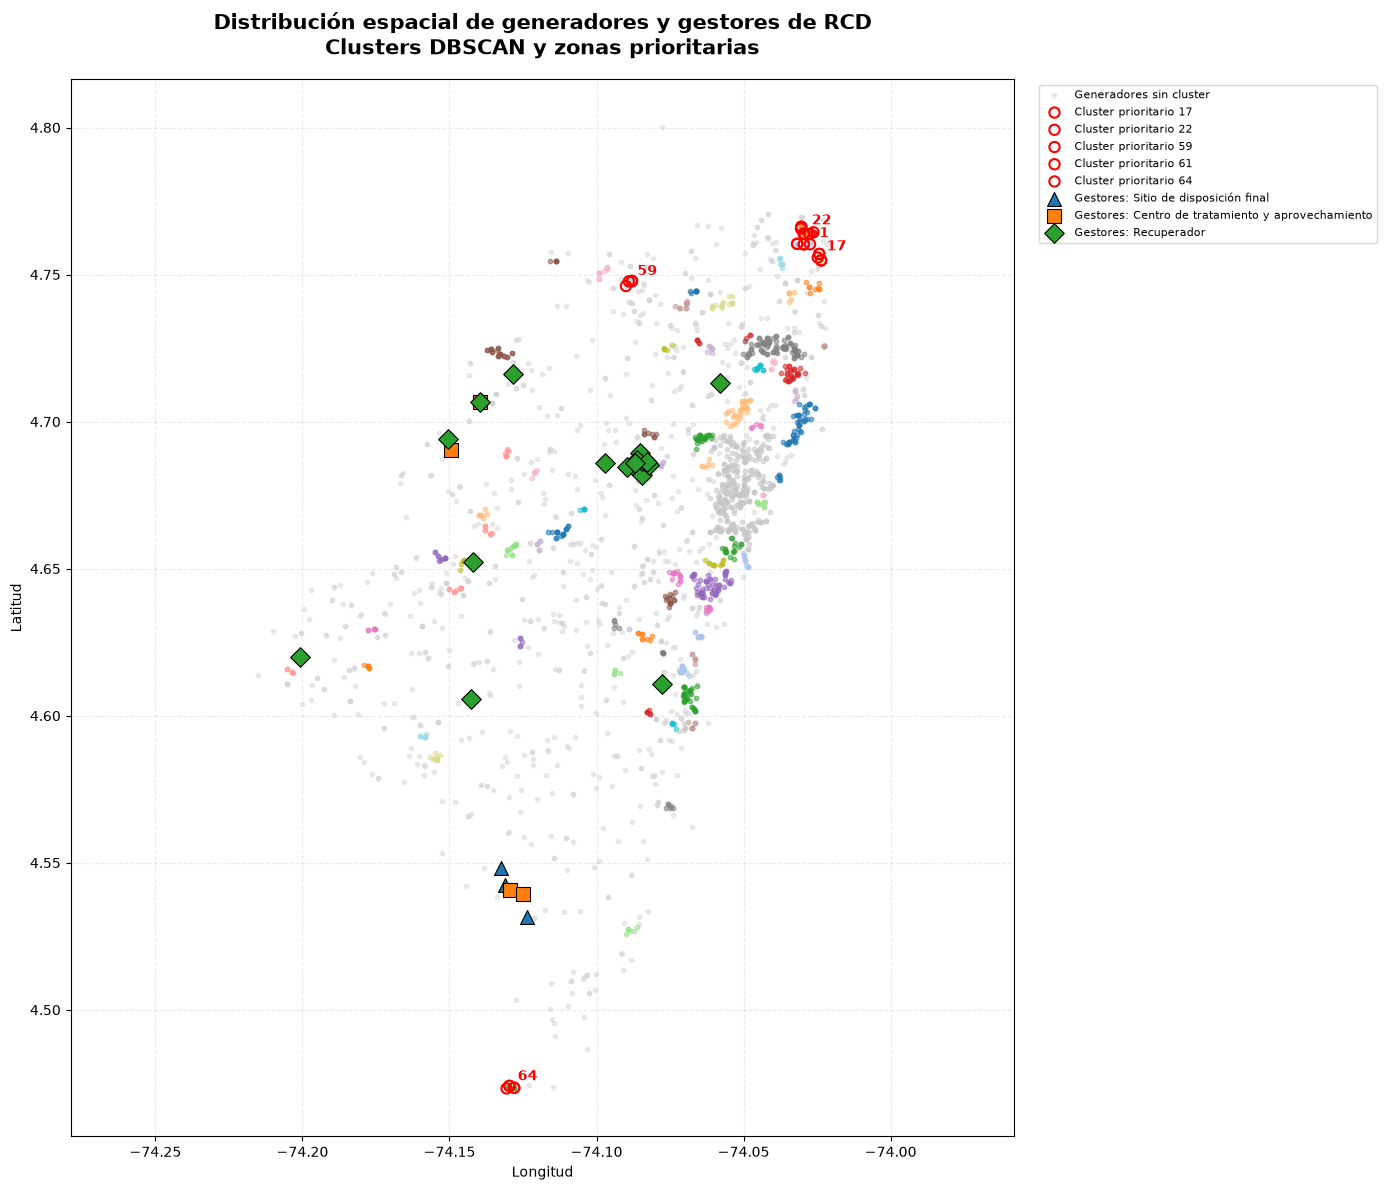


MAPA GENERADO: mapa_general_clusters_prioritarios.png
Generadores representados: 1990
Gestores representados: 28
Clusters prioritarios: [17, 22, 59, 61, 64]


In [119]:

# ============================================================
# 13.8.10. MAPA GENERAL DE GENERADORES, GESTORES Y ZONAS
# PRIORITARIAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. VALIDAR BASES
# ------------------------------------------------------------

columnas_generadores = [
    "longitud", "latitud", "cluster_dbscan"
]

columnas_gestores = [
    "longitud_gestor", "latitud_gestor",
    "Nombre_gestor", "Categoria_gestor"
]

for columna in columnas_generadores:
    if columna not in datos_generadores.columns:
        raise ValueError(f"Falta la columna {columna} en datos_generadores")

for columna in columnas_gestores:
    if columna not in datos_gestores.columns:
        raise ValueError(f"Falta la columna {columna} en datos_gestores")


# ------------------------------------------------------------
# 2. PREPARAR COPIAS PARA VISUALIZACIÓN
# ------------------------------------------------------------

mapa_generadores = datos_generadores.copy()
mapa_gestores = datos_gestores.copy()

# Asegurar coordenadas numéricas
for columna in ["longitud", "latitud"]:
    mapa_generadores[columna] = pd.to_numeric(
        mapa_generadores[columna], errors="coerce"
    )

for columna in ["longitud_gestor", "latitud_gestor"]:
    mapa_gestores[columna] = pd.to_numeric(
        mapa_gestores[columna], errors="coerce"
    )

# Eliminar únicamente coordenadas inválidas de las copias
mapa_generadores = mapa_generadores.dropna(
    subset=["longitud", "latitud", "cluster_dbscan"]
)

mapa_gestores = mapa_gestores.dropna(
    subset=["longitud_gestor", "latitud_gestor"]
)



# ------------------------------------------------------------
# 3. IDENTIFICAR LOS CINCO CLUSTERS PRIORITARIOS
# ------------------------------------------------------------

ranking_mapa = ranking_general_clusters.copy()

top_5_clusters = (
    ranking_mapa
    .sort_values("puesto")
    .head(5)["cluster_dbscan"]
    .astype(int)
    .tolist()
)

print("CLUSTERS PRIORITARIOS:", top_5_clusters)



# ------------------------------------------------------------
# 4. CREAR MAPA
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 12))

# Separar generadores con y sin cluster
generadores_sin_cluster = mapa_generadores[
    mapa_generadores["cluster_dbscan"] == -1
]

generadores_con_cluster = mapa_generadores[
    mapa_generadores["cluster_dbscan"] != -1
]

# Puntos sin cluster
ax.scatter(
    generadores_sin_cluster["longitud"],
    generadores_sin_cluster["latitud"],
    c="lightgray",
    s=9,
    alpha=0.45,
    label="Generadores sin cluster",
    zorder=2
)

# Puntos pertenecientes a clusters
clusters = sorted(
    generadores_con_cluster["cluster_dbscan"].unique()
)

colores = plt.cm.tab20(
    np.linspace(0, 1, 20)
)

for cluster in clusters:
    datos_cluster = generadores_con_cluster[
        generadores_con_cluster["cluster_dbscan"] == cluster
    ]

    ax.scatter(
        datos_cluster["longitud"],
        datos_cluster["latitud"],
        color=colores[int(cluster) % 20],
        s=10,
        alpha=0.55,
        zorder=3
    )

# Resaltar los cinco clusters prioritarios
for cluster in top_5_clusters:

    datos_prioritarios = mapa_generadores[
        mapa_generadores["cluster_dbscan"] == cluster
    ]

    if len(datos_prioritarios) == 0:
        continue

    ax.scatter(
        datos_prioritarios["longitud"],
        datos_prioritarios["latitud"],
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        s=55,
        label=f"Cluster prioritario {cluster}",
        zorder=5
    )

    # Etiqueta en el centro geográfico del cluster
    centro_x = datos_prioritarios["longitud"].mean()
    centro_y = datos_prioritarios["latitud"].mean()

    ax.annotate(
        str(cluster),
        (centro_x, centro_y),
        fontsize=10,
        fontweight="bold",
        color="red",
        xytext=(5, 5),
        textcoords="offset points",
        zorder=7
    )


# ------------------------------------------------------------
# 5. INCORPORAR GESTORES
# ------------------------------------------------------------

categorias = mapa_gestores["Categoria_gestor"].dropna().unique()

marcadores = ["^", "s", "D", "P", "X"]

for i, categoria in enumerate(categorias):

    gestores_categoria = mapa_gestores[
        mapa_gestores["Categoria_gestor"] == categoria
    ]

    ax.scatter(
        gestores_categoria["longitud_gestor"],
        gestores_categoria["latitud_gestor"],
        marker=marcadores[i % len(marcadores)],
        s=100,
        edgecolors="black",
        linewidths=0.8,
        label=f"Gestores: {categoria}",
        zorder=8
    )


# ------------------------------------------------------------
# 6. FORMATO FINAL
# ------------------------------------------------------------

ax.set_title(
    "Distribución espacial de generadores y gestores de RCD\n"
    "Clusters DBSCAN y zonas prioritarias",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=8
)

ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()

# Guardar resultado
ruta_mapa = "mapa_general_clusters_prioritarios.png"

plt.savefig(
    ruta_mapa,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMAPA GENERADO:", ruta_mapa)
print("Generadores representados:", len(mapa_generadores))
print("Gestores representados:", len(mapa_gestores))
print("Clusters prioritarios:", top_5_clusters)


In [120]:
# ============================================================
# 13.8.13 - IDENTIFICACIÓN DE LA BASE ESPACIAL
# ============================================================

import pandas as pd

print("DATAFRAMES DISPONIBLES CON INFORMACIÓN ESPACIAL")
print("=" * 70)

for nombre, variable in globals().copy().items():
    if isinstance(variable, pd.DataFrame):
        columnas = variable.columns.tolist()

        tiene_cluster = "cluster_dbscan" in columnas
        tiene_lon = "longitud" in columnas
        tiene_lat = "latitud" in columnas

        if tiene_cluster and tiene_lon and tiene_lat:
            print(f"\nVariable: {nombre}")
            print(f"Dimensiones: {variable.shape}")
            print("Columnas relevantes:")
            print([
                c for c in columnas
                if any(p in c.lower() for p in
                       ["cluster", "longitud", "latitud", "distancia",
                        "idproy", "gestor"])
            ])

DATAFRAMES DISPONIBLES CON INFORMACIÓN ESPACIAL

Variable: datos_generadores
Dimensiones: (1990, 18)
Columnas relevantes:
['idproy', 'longitud', 'latitud', 'cluster_dbscan', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia']

Variable: distancias
Dimensiones: (55720, 13)
Columnas relevantes:
['idproy', 'cluster_dbscan', 'longitud', 'latitud', 'ID_gestor', 'Nombre_gestor', 'longitud_gestor', 'latitud_gestor', 'distancia_km']

Variable: datos_cluster
Dimensiones: (5, 18)
Columnas relevantes:
['idproy', 'longitud', 'latitud', 'cluster_dbscan', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia']

Variable: ruido
Dimensiones: (833, 17)
Columnas relevantes:
['idproy', 'longitud', 'latitud', 'cluster_dbscan', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distanc

In [121]:

# ============================================================
# 13.8.13 - DIAGNÓSTICO DE ACCESIBILIDAD POR CLUSTER
# ============================================================

import pandas as pd
import numpy as np

# Trabajamos sobre una copia de la base completa
base_accesibilidad = datos_generadores.copy()

# Asegurar que las distancias sean numéricas
base_accesibilidad["distancia_gestor_cercano_km"] = pd.to_numeric(
    base_accesibilidad["distancia_gestor_cercano_km"],
    errors="coerce"
)

print("=" * 70)
print("1. DISPONIBILIDAD DE INFORMACIÓN DE DISTANCIAS")
print("=" * 70)

print("Total de generadores:", len(base_accesibilidad))
print(
    "Con distancia válida:",
    base_accesibilidad["distancia_gestor_cercano_km"].notna().sum()
)
print(
    "Sin distancia válida:",
    base_accesibilidad["distancia_gestor_cercano_km"].isna().sum()
)

print("\n" + "=" * 70)
print("2. DISTRIBUCIÓN DE GENERADORES POR CLUSTER")
print("=" * 70)

print(
    base_accesibilidad["cluster_dbscan"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\n" + "=" * 70)
print("3. DISTANCIAS VÁLIDAS POR CLUSTER")
print("=" * 70)

diagnostico_clusters = (
    base_accesibilidad
    .groupby("cluster_dbscan", dropna=False)
    .agg(
        total_generadores=("idproy", "count"),
        distancias_validas=("distancia_gestor_cercano_km", "count"),
        distancia_media=("distancia_gestor_cercano_km", "mean"),
        distancia_maxima=("distancia_gestor_cercano_km", "max")
    )
    .reset_index()
)

diagnostico_clusters["porcentaje_con_distancia"] = (
    diagnostico_clusters["distancias_validas"] /
    diagnostico_clusters["total_generadores"] * 100
)

display(diagnostico_clusters.round(2))

print("\n" + "=" * 70)
print("4. GESTORES ASIGNADOS")
print("=" * 70)

print(
    "Generadores con gestor identificado:",
    base_accesibilidad["nombre_gestor_cercano"].notna().sum()
)

print(
    "Gestores diferentes identificados:",
    base_accesibilidad["nombre_gestor_cercano"].nunique()
)


1. DISPONIBILIDAD DE INFORMACIÓN DE DISTANCIAS
Total de generadores: 1990
Con distancia válida: 1990
Sin distancia válida: 0

2. DISTRIBUCIÓN DE GENERADORES POR CLUSTER
cluster_dbscan
-1     833
 0       6
 1      10
 2       6
 3       7
      ... 
 70      8
 71      6
 72      5
 73      5
 74      5
Name: count, Length: 76, dtype: int64

3. DISTANCIAS VÁLIDAS POR CLUSTER


,cluster_dbscan,total_generadores,distancias_validas,distancia_media,distancia_maxima,porcentaje_con_distancia
0,-1,833,833,2.80,9.89,100.0
1,0,6,6,4.22,4.32,100.0
2,1,10,10,2.28,2.31,100.0
3,2,6,6,2.58,2.63,100.0
4,3,7,7,4.25,4.40,100.0
...,...,...,...,...,...,...
71,70,8,8,0.84,0.96,100.0
72,71,6,6,1.54,1.61,100.0
73,72,5,5,2.15,2.27,100.0
74,73,5,5,4.43,4.43,100.0



4. GESTORES ASIGNADOS
Generadores con gestor identificado: 1990
Gestores diferentes identificados: 19


In [122]:

# ============================================================
# 13.8.14 - RANKING DE ACCESIBILIDAD POR CLUSTER
# ============================================================

import pandas as pd
import numpy as np

# Copia de trabajo
base_ranking_accesibilidad = base_accesibilidad.copy()

# Identificar generadores a más de 5 km
base_ranking_accesibilidad["mas_5km"] = (
    base_ranking_accesibilidad["distancia_gestor_cercano_km"] > 5
)

# ------------------------------------------------------------
# 1. RESUMEN DE LOS 75 CLUSTERS
# ------------------------------------------------------------

ranking_accesibilidad = (
    base_ranking_accesibilidad[
        base_ranking_accesibilidad["cluster_dbscan"] != -1
    ]
    .groupby("cluster_dbscan")
    .agg(
        generadores=("idproy", "count"),
        distancia_media_km=("distancia_gestor_cercano_km", "mean"),
        distancia_mediana_km=("distancia_gestor_cercano_km", "median"),
        distancia_maxima_km=("distancia_gestor_cercano_km", "max"),
        generadores_mas_5km=("mas_5km", "sum")
    )
    .reset_index()
)

# Porcentaje de generadores a más de 5 km
ranking_accesibilidad["porcentaje_mas_5km"] = (
    ranking_accesibilidad["generadores_mas_5km"] /
    ranking_accesibilidad["generadores"] * 100
)

# ------------------------------------------------------------
# 2. ORDENAR POR DIFICULTAD DE ACCESO
# ------------------------------------------------------------

ranking_accesibilidad = ranking_accesibilidad.sort_values(
    by=[
        "porcentaje_mas_5km",
        "generadores_mas_5km",
        "distancia_media_km"
    ],
    ascending=[False, False, False]
).reset_index(drop=True)

ranking_accesibilidad.insert(
    0,
    "puesto",
    range(1, len(ranking_accesibilidad) + 1)
)

# ------------------------------------------------------------
# 3. MOSTRAR RESULTADOS
# ------------------------------------------------------------

print("=" * 75)
print("RANKING DE ACCESIBILIDAD A GESTORES POR CLUSTER")
print("=" * 75)

display(ranking_accesibilidad.round(2))

print("\n" + "=" * 75)
print("TOP 10 CLUSTERS CON MAYORES BRECHAS DE ACCESIBILIDAD")
print("=" * 75)

display(ranking_accesibilidad.head(10).round(2))

# ------------------------------------------------------------
# 4. RESUMEN GENERAL DE LOS CLUSTERS
# ------------------------------------------------------------

total_clusterizados = ranking_accesibilidad["generadores"].sum()
total_mas_5km = ranking_accesibilidad["generadores_mas_5km"].sum()

print("\nRESUMEN GENERAL")
print("-" * 50)
print("Clusters analizados:", len(ranking_accesibilidad))
print("Generadores en clusters:", total_clusterizados)
print("Generadores a más de 5 km:", total_mas_5km)

print(
    "Porcentaje de generadores a más de 5 km:",
    round(total_mas_5km / total_clusterizados * 100, 2), "%"
)

# ------------------------------------------------------------
# 5. ANALIZAR POR SEPARADO LOS REGISTROS SIN CLUSTER
# ------------------------------------------------------------

generadores_ruido = base_ranking_accesibilidad[
    base_ranking_accesibilidad["cluster_dbscan"] == -1
].copy()

print("\nREGISTROS SIN CLUSTER (RUIDO DBSCAN)")
print("-" * 50)
print("Total:", len(generadores_ruido))
print(
    "Distancia media:",
    round(generadores_ruido["distancia_gestor_cercano_km"].mean(), 2),
    "km"
)
print(
    "Generadores a más de 5 km:",
    int(generadores_ruido["mas_5km"].sum())
)
print(
    "Porcentaje a más de 5 km:",
    round(generadores_ruido["mas_5km"].mean() * 100, 2), "%"
)


RANKING DE ACCESIBILIDAD A GESTORES POR CLUSTER


,puesto,cluster_dbscan,generadores,distancia_media_km,distancia_mediana_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km
0,1,22,8,6.56,6.57,6.69,8,100.0
1,2,59,6,5.08,5.07,5.13,6,100.0
2,3,64,5,6.45,6.46,6.51,5,100.0
3,4,61,5,6.10,6.11,6.24,5,100.0
4,5,17,5,6.06,6.00,6.14,5,100.0
...,...,...,...,...,...,...,...,...
70,71,70,8,0.84,0.82,0.96,0,0.0
71,72,67,5,0.66,0.66,0.67,0,0.0
72,73,29,6,0.44,0.43,0.53,0,0.0
73,74,16,6,0.41,0.39,0.56,0,0.0



TOP 10 CLUSTERS CON MAYORES BRECHAS DE ACCESIBILIDAD


,puesto,cluster_dbscan,generadores,distancia_media_km,distancia_mediana_km,distancia_maxima_km,generadores_mas_5km,porcentaje_mas_5km
0,1,22,8,6.56,6.57,6.69,8,100.00
1,2,59,6,5.08,5.07,5.13,6,100.00
2,3,64,5,6.45,6.46,6.51,5,100.00
3,4,61,5,6.10,6.11,6.24,5,100.00
4,5,17,5,6.06,6.00,6.14,5,100.00
5,6,39,7,5.10,5.05,5.22,6,85.71
6,7,53,13,5.10,5.01,5.38,11,84.62
7,8,42,9,5.06,5.04,5.32,6,66.67
8,9,41,11,5.08,5.05,5.30,7,63.64
9,10,34,6,4.65,4.67,4.71,0,0.00



RESUMEN GENERAL
--------------------------------------------------
Clusters analizados: 75
Generadores en clusters: 1157
Generadores a más de 5 km: 59
Porcentaje de generadores a más de 5 km: 5.1 %

REGISTROS SIN CLUSTER (RUIDO DBSCAN)
--------------------------------------------------
Total: 833
Distancia media: 2.8 km
Generadores a más de 5 km: 55
Porcentaje a más de 5 km: 6.6 %


In [123]:

# ============================================================
# 13.8.15 - PRIORIZACIÓN INTEGRAL DE CLUSTERS
# ============================================================

# 1. Preparar ranking de disponibilidad de materiales
ranking_materiales = ranking_general_clusters.copy()

ranking_materiales = ranking_materiales.rename(columns={
    "puesto": "puesto_materiales",
    "materiales_evaluados": "materiales_evaluados",
    "materiales_brecha_critica": "materiales_brecha_critica",
    "materiales_brecha_alta": "materiales_brecha_alta",
    "promedio_porcentaje_mas_5km": "porcentaje_brecha_materiales",
    "total_generadores_mas_5km": "generadores_brecha_materiales"
})

# 2. Preparar ranking de accesibilidad
ranking_distancias = ranking_accesibilidad.copy()

ranking_distancias = ranking_distancias.rename(columns={
    "puesto": "puesto_accesibilidad",
    "generadores": "generadores_cluster",
    "distancia_media_km": "distancia_media_km",
    "distancia_mediana_km": "distancia_mediana_km",
    "distancia_maxima_km": "distancia_maxima_km",
    "generadores_mas_5km": "generadores_acceso_mas_5km",
    "porcentaje_mas_5km": "porcentaje_acceso_mas_5km"
})

# 3. Cruzar ambos rankings por cluster
priorizacion_integral = ranking_materiales.merge(
    ranking_distancias,
    on="cluster_dbscan",
    how="inner"
)

# 4. Calcular posición conjunta
priorizacion_integral["suma_puestos"] = (
    priorizacion_integral["puesto_materiales"] +
    priorizacion_integral["puesto_accesibilidad"]
)

# 5. Identificar coincidencias en los primeros 10 puestos
priorizacion_integral["top10_materiales"] = (
    priorizacion_integral["puesto_materiales"] <= 10
)

priorizacion_integral["top10_accesibilidad"] = (
    priorizacion_integral["puesto_accesibilidad"] <= 10
)

priorizacion_integral["coincide_top10"] = (
    priorizacion_integral["top10_materiales"] &
    priorizacion_integral["top10_accesibilidad"]
)

# 6. Clasificación de prioridad conjunta
def clasificar_prioridad(fila):
    if fila["coincide_top10"]:
        return "Prioridad muy alta"
    elif fila["puesto_materiales"] <= 10 or fila["puesto_accesibilidad"] <= 10:
        return "Prioridad alta"
    elif (
        fila["materiales_brecha_critica"] >= 6 and
        fila["porcentaje_acceso_mas_5km"] >= 50
    ):
        return "Prioridad media"
    else:
        return "Prioridad baja"

priorizacion_integral["prioridad_integral"] = (
    priorizacion_integral.apply(clasificar_prioridad, axis=1)
)

# 7. Ordenar por mejor posición conjunta
priorizacion_integral = priorizacion_integral.sort_values(
    by=[
        "suma_puestos",
        "puesto_materiales",
        "puesto_accesibilidad"
    ]
).reset_index(drop=True)

priorizacion_integral.insert(
    0, "puesto_integral",
    range(1, len(priorizacion_integral) + 1)
)

# 8. Mostrar tabla completa
columnas_resultado = [
    "puesto_integral",
    "cluster_dbscan",
    "prioridad_integral",
    "puesto_materiales",
    "puesto_accesibilidad",
    "materiales_brecha_critica",
    "materiales_brecha_alta",
    "porcentaje_brecha_materiales",
    "porcentaje_acceso_mas_5km",
    "generadores_acceso_mas_5km",
    "distancia_media_km",
    "suma_puestos"
]

print("=" * 90)
print("RANKING INTEGRAL DE PRIORIDAD DE CLUSTERS")
print("=" * 90)

display(priorizacion_integral[columnas_resultado].round(2))

# 9. TOP 10
print("\n" + "=" * 90)
print("TOP 10 ZONAS DE INTERVENCIÓN PRIORITARIA")
print("=" * 90)

display(
    priorizacion_integral[columnas_resultado]
    .head(10)
    .round(2)
)

# 10. Clusters con coincidencia en ambos TOP 10
print("\n" + "=" * 90)
print("CLUSTERS QUE COINCIDEN EN AMBOS TOP 10")
print("=" * 90)

display(
    priorizacion_integral[
        priorizacion_integral["coincide_top10"]
    ][columnas_resultado].round(2)
)

# 11. Distribución de prioridades
print("\nDISTRIBUCIÓN DE NIVELES DE PRIORIDAD")

display(
    priorizacion_integral["prioridad_integral"]
    .value_counts()
    .to_frame("numero_clusters")
)


RANKING INTEGRAL DE PRIORIDAD DE CLUSTERS


,puesto_integral,cluster_dbscan,prioridad_integral,puesto_materiales,puesto_accesibilidad,materiales_brecha_critica,materiales_brecha_alta,porcentaje_brecha_materiales,porcentaje_acceso_mas_5km,generadores_acceso_mas_5km,distancia_media_km,suma_puestos
0,1,22,Prioridad muy alta,2,1,12,0,100.00,100.0,8,6.56,3
1,2,59,Prioridad muy alta,3,2,12,0,100.00,100.0,6,5.08,5
2,3,17,Prioridad muy alta,1,5,12,0,100.00,100.0,5,6.06,6
3,4,61,Prioridad muy alta,4,4,12,0,100.00,100.0,5,6.10,8
4,5,64,Prioridad muy alta,5,3,12,0,100.00,100.0,5,6.45,8
...,...,...,...,...,...,...,...,...,...,...,...,...
70,71,47,Prioridad baja,64,63,5,0,41.67,0.0,0,1.31,127
71,72,29,Prioridad baja,58,73,5,0,41.67,0.0,0,0.44,131
72,73,55,Prioridad baja,66,75,5,0,41.67,0.0,0,0.20,141
73,74,70,Prioridad baja,70,71,5,0,41.67,0.0,0,0.84,141



TOP 10 ZONAS DE INTERVENCIÓN PRIORITARIA


,puesto_integral,cluster_dbscan,prioridad_integral,puesto_materiales,puesto_accesibilidad,materiales_brecha_critica,materiales_brecha_alta,porcentaje_brecha_materiales,porcentaje_acceso_mas_5km,generadores_acceso_mas_5km,distancia_media_km,suma_puestos
0,1,22,Prioridad muy alta,2,1,12,0,100.00,100.00,8,6.56,3
1,2,59,Prioridad muy alta,3,2,12,0,100.00,100.00,6,5.08,5
2,3,17,Prioridad muy alta,1,5,12,0,100.00,100.00,5,6.06,6
3,4,61,Prioridad muy alta,4,4,12,0,100.00,100.00,5,6.10,8
4,5,64,Prioridad muy alta,5,3,12,0,100.00,100.00,5,6.45,8
5,6,39,Prioridad muy alta,6,6,12,0,94.05,85.71,6,5.10,12
6,7,53,Prioridad muy alta,7,7,12,0,92.31,84.62,11,5.10,14
7,8,42,Prioridad muy alta,8,8,7,5,86.11,66.67,6,5.06,16
8,9,3,Prioridad alta,10,16,7,0,58.33,0.00,0,4.25,26
9,10,20,Prioridad baja,13,24,7,0,58.33,0.00,0,3.43,37



CLUSTERS QUE COINCIDEN EN AMBOS TOP 10


,puesto_integral,cluster_dbscan,prioridad_integral,puesto_materiales,puesto_accesibilidad,materiales_brecha_critica,materiales_brecha_alta,porcentaje_brecha_materiales,porcentaje_acceso_mas_5km,generadores_acceso_mas_5km,distancia_media_km,suma_puestos
0,1,22,Prioridad muy alta,2,1,12,0,100.00,100.00,8,6.56,3
1,2,59,Prioridad muy alta,3,2,12,0,100.00,100.00,6,5.08,5
2,3,17,Prioridad muy alta,1,5,12,0,100.00,100.00,5,6.06,6
3,4,61,Prioridad muy alta,4,4,12,0,100.00,100.00,5,6.10,8
4,5,64,Prioridad muy alta,5,3,12,0,100.00,100.00,5,6.45,8
5,6,39,Prioridad muy alta,6,6,12,0,94.05,85.71,6,5.10,12
6,7,53,Prioridad muy alta,7,7,12,0,92.31,84.62,11,5.10,14
7,8,42,Prioridad muy alta,8,8,7,5,86.11,66.67,6,5.06,16



DISTRIBUCIÓN DE NIVELES DE PRIORIDAD


,numero_clusters
prioridad_integral,
Prioridad baja,63
Prioridad muy alta,8
Prioridad alta,4


Ranking encontrado: priorizacion_integral


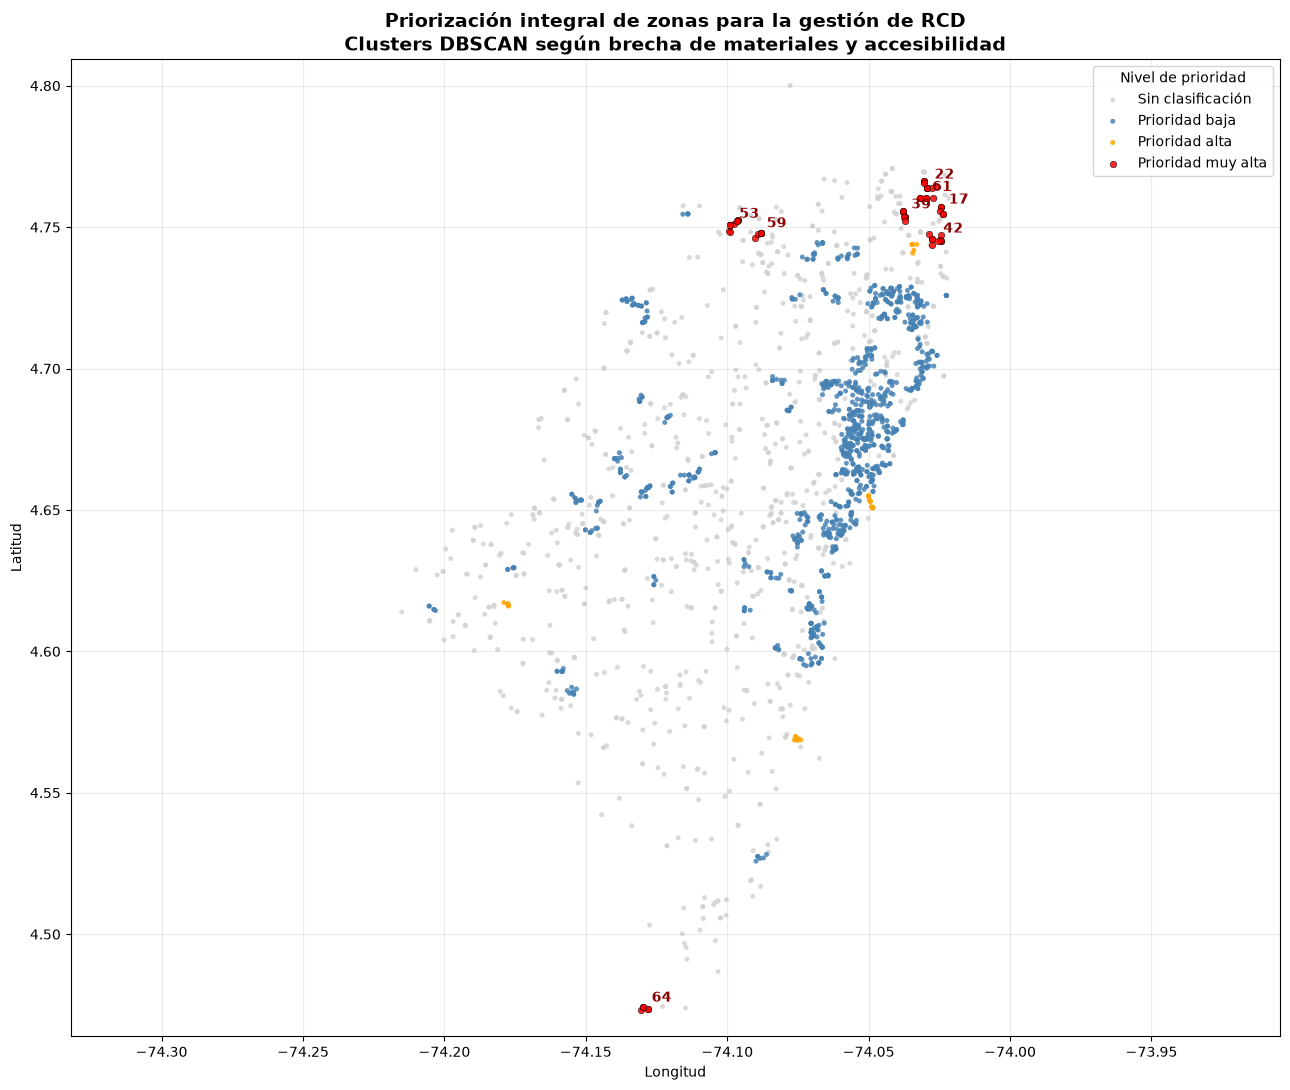

Clusters de prioridad muy alta: [22, 59, 17, 61, 64, 39, 53, 42]
Generadores representados: 1990
Mapa guardado: mapa_prioridad_integral_clusters.png


In [124]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# 1. IDENTIFICAR EL RANKING INTEGRAL
# ============================================================

columnas_ranking = {
    "cluster_dbscan",
    "prioridad_integral",
    "puesto_integral"
}

ranking_mapa = None

for nombre, variable in globals().copy().items():
    if isinstance(variable, pd.DataFrame):
        if columnas_ranking.issubset(variable.columns):
            ranking_mapa = variable.copy()
            print(f"Ranking encontrado: {nombre}")
            break

if ranking_mapa is None:
    raise NameError(
        "No se encontró el ranking integral. "
        "Revisa el nombre de la variable."
    )

# ============================================================
# 2. PREPARAR LOS GENERADORES
# ============================================================

generadores_mapa = datos_generadores.copy()

# Incorporar la prioridad integral a cada generador
generadores_mapa = generadores_mapa.merge(
    ranking_mapa[
        ["cluster_dbscan", "prioridad_integral"]
    ],
    on="cluster_dbscan",
    how="left"
)

generadores_mapa["prioridad_integral"] = (
    generadores_mapa["prioridad_integral"]
    .fillna("Sin clasificación")
)

# ============================================================
# 3. DEFINIR COLORES
# ============================================================

colores = {
    "Prioridad muy alta": "red",
    "Prioridad alta": "orange",
    "Prioridad baja": "steelblue",
    "Sin clasificación": "lightgray"
}

# ============================================================
# 4. CREAR EL MAPA
# ============================================================

fig, ax = plt.subplots(figsize=(13, 11))

# Primero, los generadores de prioridad baja
for prioridad in [
    "Sin clasificación",
    "Prioridad baja",
    "Prioridad alta",
    "Prioridad muy alta"
]:
    subset = generadores_mapa[
        generadores_mapa["prioridad_integral"] == prioridad
    ]

    ax.scatter(
        subset["longitud"],
        subset["latitud"],
        c=colores[prioridad],
        label=prioridad,
        s=22 if prioridad == "Prioridad muy alta" else 13,
        alpha=0.85,
        edgecolors="black" if prioridad == "Prioridad muy alta" else "none",
        linewidths=0.4
    )

# ============================================================
# 5. ETIQUETAR LOS CLUSTERS DE PRIORIDAD MUY ALTA
# ============================================================

top_clusters = ranking_mapa[
    ranking_mapa["prioridad_integral"] == "Prioridad muy alta"
]["cluster_dbscan"].tolist()

for cluster in top_clusters:

    subset = generadores_mapa[
        generadores_mapa["cluster_dbscan"] == cluster
    ]

    if not subset.empty:
        x = subset["longitud"].mean()
        y = subset["latitud"].mean()

        ax.annotate(
            str(cluster),
            (x, y),
            fontsize=10,
            fontweight="bold",
            color="darkred",
            xytext=(5, 5),
            textcoords="offset points"
        )

# ============================================================
# 6. FORMATO FINAL
# ============================================================

ax.set_title(
    "Priorización integral de zonas para la gestión de RCD\n"
    "Clusters DBSCAN según brecha de materiales y accesibilidad",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.grid(alpha=0.25)
ax.legend(title="Nivel de prioridad", loc="best")
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()

plt.savefig(
    "mapa_prioridad_integral_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Clusters de prioridad muy alta:", top_clusters)
print("Generadores representados:", len(generadores_mapa))
print("Mapa guardado: mapa_prioridad_integral_clusters.png")


In [125]:

# ============================================================
# IDENTIFICAR DATAFRAMES DE GESTORES
# ============================================================

import pandas as pd

print("=" * 75)
print("DATAFRAMES QUE PODRÍAN CONTENER INFORMACIÓN DE GESTORES")
print("=" * 75)

for nombre, variable in globals().copy().items():

    if not isinstance(variable, pd.DataFrame):
        continue

    columnas = variable.columns.tolist()

    tiene_coordenadas = (
        "longitud" in columnas and
        "latitud" in columnas
    )

    tiene_nombre = any(
        "nombre" in str(col).lower()
        or "gestor" in str(col).lower()
        for col in columnas
    )

    if tiene_coordenadas and tiene_nombre:

        print(f"\nVariable: {nombre}")
        print("Dimensiones:", variable.shape)
        print("Columnas:", columnas)

        print("\nMuestra:")
        display(variable.head(3))



DATAFRAMES QUE PODRÍAN CONTENER INFORMACIÓN DE GESTORES

Variable: datos_generadores
Dimensiones: (1990, 18)
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador']

Muestra:


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia,indice_generador
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,-1,False,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km,0
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,CL 139 94 55,AAA0130LZKL,9.89026032000e+04,1.15624393800e+05,30/06/2015,30/06/2015,-74.087416,4.737463,-1,True,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,1
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",AK 80 2 51,AAA0050YDFT,9.09102454000e+04,1.03801857400e+05,30/06/2015,30/06/2015,-74.159426,4.630596,-1,True,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,2



Variable: distancias
Dimensiones: (55720, 13)
Columnas: ['_id_fila', 'idproy', 'nombproy', 'dirproy', 'cluster_dbscan', 'longitud', 'latitud', 'ID_gestor', 'Nombre_gestor', 'Categoria', 'longitud_gestor', 'latitud_gestor', 'distancia_km']

Muestra:


,_id_fila,idproy,nombproy,dirproy,cluster_dbscan,longitud,latitud,ID_gestor,Nombre_gestor,Categoria,longitud_gestor,latitud_gestor,distancia_km
0,0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,-1,-74.172282,4.634849,7,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,-74.149480,4.690445,6.678525
1,0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,-1,-74.172282,4.634849,8,ECOPLANET SOLUCIONES AR SAS,Centro de tratamiento y aprovechamiento,-74.139655,4.706700,8.769660
2,0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,-1,-74.172282,4.634849,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Centro de tratamiento y aprovechamiento,-74.124917,4.539283,11.852530



Variable: recomendaciones_generador
Dimensiones: (1, 16)
Columnas: ['Orden_recomendacion', 'id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'distancia_linea_recta_km', 'ID_gestor', 'Estado_general']

Muestra:


,Orden_recomendacion,id_sitio_d,nomb_disp_,municipio,capacidad_,categoria,fech_creac,fech_actua,categoria_,mat_a_disp,aprobacion,longitud,latitud,distancia_linea_recta_km,ID_gestor,Estado_general
0,1,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,None,0.0,2,2020-12-10,2022-11-30,Centro de tratamiento y aprovechamiento,"RCD petreos, arenas , gravas, gravillas, rocas...",Radicado SDA: 2020IE223591,-74.124917,4.539283,18.597684,9,Compatible reportado


... (60 outputs left out)


Variable: generadores_mapa
Dimensiones: (1990, 19)
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador', 'prioridad_integral']

Muestra:


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia,indice_generador,prioridad_integral
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,-1,False,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km,0,Sin clasificación
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,CL 139 94 55,AAA0130LZKL,9.89026032000e+04,1.15624393800e+05,30/06/2015,30/06/2015,-74.087416,4.737463,-1,True,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,1,Sin clasificación
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",AK 80 2 51,AAA0050YDFT,9.09102454000e+04,1.03801857400e+05,30/06/2015,30/06/2015,-74.159426,4.630596,-1,True,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,2,Sin clasificación



Variable: subset
Dimensiones: (9, 19)
Columnas: ['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador', 'prioridad_integral']

Muestra:


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia,indice_generador,prioridad_integral
189,001408,Urbanismo Ciudadela San Juan Bosco,AC 170 7 60,,1.05912795789e+05,1.16700890624e+05,27/12/2018,7/03/2019,-74.024251,4.747186,42,True,5.323185,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Más de 5 km,189,Prioridad muy alta
464,000900,PROYECTO MIRAMONT ETAPA 1,CL 167D 7F 28,,1.05899930000e+05,1.16469860000e+05,30/06/2015,30/06/2015,-74.024367,4.745097,42,True,5.151901,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Más de 5 km,464,Prioridad muy alta
498,000177,PROYECTO MIRAMONT ETAPA 1,CL 167D 7F 28,,1.05899930000e+05,1.16469860000e+05,30/09/2013,30/09/2013,-74.024367,4.745097,42,True,5.151901,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Más de 5 km,498,Prioridad muy alta


In [126]:
# ============================================================
# 13.8.12 CONSOLIDACIÓN DE COBERTURA TOTAL POR TIPO DE RESIDUO
# Integra clusters identificados y registros sin cluster (ruido)
# ============================================================

import pandas as pd

print("=" * 75)
print("13.8.12 CONSOLIDACIÓN DE COBERTURA TOTAL POR RESIDUO")
print("=" * 75)

# 1. Verificar que existan las dos fuentes
fuentes_requeridas = [
    "resumen_clusters_prioridad",
    "resumen_ruido_prioridad"
]

for variable in fuentes_requeridas:
    if variable not in globals():
        raise NameError(
            f"No se encontró la variable '{variable}'. "
            "Revisa que las celdas anteriores se hayan ejecutado."
        )

# 2. Copiar las fuentes para no modificar los resultados anteriores
cobertura_clusters = resumen_clusters_prioridad.copy()
cobertura_ruido = resumen_ruido_prioridad.copy()

print("\nDimensiones de las fuentes:")
print("Clusters:", cobertura_clusters.shape)
print("Ruido:", cobertura_ruido.shape)

print("\nColumnas de resumen_clusters_prioridad:")
print(cobertura_clusters.columns.tolist())

print("\nColumnas de resumen_ruido_prioridad:")
print(cobertura_ruido.columns.tolist())

# 3. Identificar el origen de cada registro
cobertura_clusters["origen_registro"] = "Clusters DBSCAN"
cobertura_ruido["origen_registro"] = "Ruido DBSCAN"

# 4. Unificar las dos fuentes
cobertura_total_residuo = pd.concat(
    [cobertura_clusters, cobertura_ruido],
    ignore_index=True,
    sort=False
)

# 5. Mostrar resultados de la consolidación
print("\n" + "=" * 75)
print("RESULTADO DE LA CONSOLIDACIÓN")
print("=" * 75)

print("Registros provenientes de clusters:",
      len(cobertura_clusters))

print("Registros provenientes de ruido:",
      len(cobertura_ruido))

print("Total de registros consolidados:",
      len(cobertura_total_residuo))

print("\nDistribución por origen:")
display(
    cobertura_total_residuo["origen_registro"]
    .value_counts()
    .to_frame("numero_registros")
)

print("\nPrimeros registros de la base consolidada:")
display(cobertura_total_residuo.head(10))

print("\nDimensiones finales:", cobertura_total_residuo.shape)

13.8.12 CONSOLIDACIÓN DE COBERTURA TOTAL POR RESIDUO

Dimensiones de las fuentes:
Clusters: (13, 6)
Ruido: (13, 5)

Columnas de resumen_clusters_prioridad:
['Codigo_residuo', 'Tipo_residuo', 'clusters_identificados', 'generadores_evaluados', 'generadores_mas_5km', 'porcentaje_mas_5km']

Columnas de resumen_ruido_prioridad:
['Codigo_residuo', 'Tipo_residuo', 'generadores_sin_cluster', 'generadores_mas_5km', 'porcentaje_mas_5km']

RESULTADO DE LA CONSOLIDACIÓN
Registros provenientes de clusters: 13
Registros provenientes de ruido: 13
Total de registros consolidados: 26

Distribución por origen:


,numero_registros
origen_registro,
Clusters DBSCAN,13
Ruido DBSCAN,13



Primeros registros de la base consolidada:


,Codigo_residuo,Tipo_residuo,clusters_identificados,generadores_evaluados,generadores_mas_5km,porcentaje_mas_5km,origen_registro,generadores_sin_cluster
0,R01,Concreto y residuos cementicios,75.0,1157.0,1151,99.481417,Clusters DBSCAN,NaN
1,R02,"Ladrillos, bloques y ceramicos",75.0,1157.0,1151,99.481417,Clusters DBSCAN,NaN
2,R03,Material de excavacion y tierras,75.0,1157.0,1144,98.876404,Clusters DBSCAN,NaN
3,R04,"Arenas, gravas y materiales petreos",75.0,1157.0,1048,90.579084,Clusters DBSCAN,NaN
4,R05,Madera,75.0,1157.0,65,5.617978,Clusters DBSCAN,NaN
5,R06,Metales,75.0,1157.0,65,5.617978,Clusters DBSCAN,NaN
6,R07,Plastico y PVC,75.0,1157.0,65,5.617978,Clusters DBSCAN,NaN
7,R08,Papel y carton,75.0,1157.0,65,5.617978,Clusters DBSCAN,NaN
8,R09,Drywall,75.0,1157.0,91,7.865169,Clusters DBSCAN,NaN
9,R10,Icopor,75.0,1157.0,349,30.164218,Clusters DBSCAN,NaN



Dimensiones finales: (26, 8)


In [127]:

# ================================================================
# 13.8.13 CONSOLIDACIÓN FINAL DE COBERTURA POR TIPO DE RESIDUO
# ================================================================

# Copiar las bases de resumen
clusters_final = resumen_clusters_prioridad.copy()
ruido_final = resumen_ruido_prioridad.copy()

# Seleccionar y renombrar columnas para evitar confusiones
clusters_final = clusters_final[
    [
        "Codigo_residuo",
        "Tipo_residuo",
        "clusters_identificados",
        "generadores_evaluados",
        "generadores_mas_5km",
        "porcentaje_mas_5km"
    ]
].rename(columns={
    "generadores_evaluados": "generadores_en_clusters",
    "generadores_mas_5km": "mas_5km_clusters",
    "porcentaje_mas_5km": "porcentaje_clusters"
})

ruido_final = ruido_final[
    [
        "Codigo_residuo",
        "generadores_sin_cluster",
        "generadores_mas_5km",
        "porcentaje_mas_5km"
    ]
].rename(columns={
    "generadores_mas_5km": "mas_5km_ruido",
    "porcentaje_mas_5km": "porcentaje_ruido"
})

# Unir ambas fuentes por código de residuo
cobertura_total_residuos = clusters_final.merge(
    ruido_final,
    on="Codigo_residuo",
    how="outer",
    validate="one_to_one"
)

# Consolidar cantidades
cobertura_total_residuos["generadores_en_clusters"] = (
    cobertura_total_residuos["generadores_en_clusters"].fillna(0)
)

cobertura_total_residuos["generadores_sin_cluster"] = (
    cobertura_total_residuos["generadores_sin_cluster"].fillna(0)
)

cobertura_total_residuos["mas_5km_clusters"] = (
    cobertura_total_residuos["mas_5km_clusters"].fillna(0)
)

cobertura_total_residuos["mas_5km_ruido"] = (
    cobertura_total_residuos["mas_5km_ruido"].fillna(0)
)

cobertura_total_residuos["generadores_evaluados_total"] = (
    cobertura_total_residuos["generadores_en_clusters"]
    + cobertura_total_residuos["generadores_sin_cluster"]
)

cobertura_total_residuos["generadores_mas_5km_total"] = (
    cobertura_total_residuos["mas_5km_clusters"]
    + cobertura_total_residuos["mas_5km_ruido"]
)

# Calcular porcentaje ponderado sobre el total evaluado
cobertura_total_residuos["porcentaje_mas_5km_total"] = (
    cobertura_total_residuos["generadores_mas_5km_total"]
    / cobertura_total_residuos["generadores_evaluados_total"]
    * 100
)

# Ordenar y redondear
cobertura_total_residuos = cobertura_total_residuos.sort_values(
    "Codigo_residuo"
).reset_index(drop=True)

cobertura_total_residuos["porcentaje_mas_5km_total"] = (
    cobertura_total_residuos["porcentaje_mas_5km_total"].round(2)
)

# Mostrar resultados
print("=" * 85)
print("13.8.13 CONSOLIDACIÓN FINAL POR TIPO DE RESIDUO")
print("=" * 85)

print("\nTotal de tipos de residuos:", len(cobertura_total_residuos))

display(cobertura_total_residuos)

print("\n" + "=" * 85)
print("VALIDACIÓN DE LA CONSOLIDACIÓN")
print("=" * 85)

print(
    "Total de generadores evaluados:",
    cobertura_total_residuos["generadores_evaluados_total"].sum()
)

print(
    "Total de registros a más de 5 km:",
    cobertura_total_residuos["generadores_mas_5km_total"].sum()
)

print(
    "Porcentaje global a más de 5 km:",
    round(
        cobertura_total_residuos["generadores_mas_5km_total"].sum()
        / cobertura_total_residuos["generadores_evaluados_total"].sum()
        * 100, 2
    ),
    "%"
)


13.8.13 CONSOLIDACIÓN FINAL POR TIPO DE RESIDUO

Total de tipos de residuos: 13


,Codigo_residuo,Tipo_residuo,clusters_identificados,generadores_en_clusters,mas_5km_clusters,porcentaje_clusters,generadores_sin_cluster,mas_5km_ruido,porcentaje_ruido,generadores_evaluados_total,generadores_mas_5km_total,porcentaje_mas_5km_total
0,R01,Concreto y residuos cementicios,75,1157,1151,99.481417,833,755,90.636255,1990,1906,95.78
1,R02,"Ladrillos, bloques y ceramicos",75,1157,1151,99.481417,833,755,90.636255,1990,1906,95.78
2,R03,Material de excavacion y tierras,75,1157,1144,98.876404,833,737,88.475390,1990,1881,94.52
3,R04,"Arenas, gravas y materiales petreos",75,1157,1048,90.579084,833,656,78.751501,1990,1704,85.63
4,R05,Madera,75,1157,65,5.617978,833,116,13.925570,1990,181,9.10
5,R06,Metales,75,1157,65,5.617978,833,116,13.925570,1990,181,9.10
6,R07,Plastico y PVC,75,1157,65,5.617978,833,116,13.925570,1990,181,9.10
7,R08,Papel y carton,75,1157,65,5.617978,833,116,13.925570,1990,181,9.10
8,R09,Drywall,75,1157,91,7.865169,833,220,26.410564,1990,311,15.63
9,R10,Icopor,75,1157,349,30.164218,833,404,48.499400,1990,753,37.84



VALIDACIÓN DE LA CONSOLIDACIÓN
Total de generadores evaluados: 25870
Total de registros a más de 5 km: 12099
Porcentaje global a más de 5 km: 46.77 %


In [128]:

# ================================================================
# 13.8.14 VALIDACIÓN DE DISTANCIAS Y BRECHAS DE ACCESIBILIDAD
# ================================================================

import pandas as pd

# Copiar la base original de generadores
base_validacion = datos_generadores.copy()

# Asegurar que la distancia sea numérica
base_validacion["distancia_gestor_cercano_km"] = pd.to_numeric(
    base_validacion["distancia_gestor_cercano_km"],
    errors="coerce"
)

# Clasificar registros según DBSCAN
base_validacion["origen"] = base_validacion["cluster_dbscan"].apply(
    lambda x: "Ruido DBSCAN" if x == -1 else "Clusters DBSCAN"
)

# Calcular resultados directamente desde la base original
base_validacion["mas_5km_real"] = (
    base_validacion["distancia_gestor_cercano_km"] > 5
)

print("=" * 75)
print("13.8.14 VALIDACIÓN DE DISTANCIAS")
print("=" * 75)

print("\n1. RESULTADOS DIRECTOS DE LA BASE ORIGINAL")

validacion_general = base_validacion.groupby("origen").agg(
    generadores=("idproy", "count"),
    distancias_validas=("distancia_gestor_cercano_km", "count"),
    generadores_mas_5km=("mas_5km_real", "sum"),
    distancia_media=("distancia_gestor_cercano_km", "mean")
)

validacion_general["porcentaje_mas_5km"] = (
    validacion_general["generadores_mas_5km"]
    / validacion_general["generadores"]
    * 100
)

display(validacion_general.round(2))

print("\n2. COMPARACIÓN CON LOS RESÚMENES POR RESIDUO")

print("\nResumen de clusters:")
display(
    resumen_clusters_prioridad[
        ["Codigo_residuo", "generadores_evaluados", "generadores_mas_5km"]
    ]
)

print("\nResumen de ruido:")
display(
    resumen_ruido_prioridad[
        ["Codigo_residuo", "generadores_sin_cluster", "generadores_mas_5km"]
    ]
)

print("\n3. VALIDACIÓN DE LOS TOTALES ÚNICOS")

print("Total de generadores:", len(base_validacion))
print(
    "Generadores únicos:",
    base_validacion["idproy"].nunique()
)
print(
    "Total real a más de 5 km:",
    base_validacion["mas_5km_real"].sum()
)
print(
    "Porcentaje real a más de 5 km:",
    round(base_validacion["mas_5km_real"].mean() * 100, 2),
    "%"
)


13.8.14 VALIDACIÓN DE DISTANCIAS

1. RESULTADOS DIRECTOS DE LA BASE ORIGINAL


,generadores,distancias_validas,generadores_mas_5km,distancia_media,porcentaje_mas_5km
origen,,,,,
Clusters DBSCAN,1157,1157,59,2.94,5.1
Ruido DBSCAN,833,833,55,2.80,6.6



2. COMPARACIÓN CON LOS RESÚMENES POR RESIDUO

Resumen de clusters:


,Codigo_residuo,generadores_evaluados,generadores_mas_5km
0,R01,1157,1151
1,R02,1157,1151
2,R03,1157,1144
3,R04,1157,1048
4,R05,1157,65
5,R06,1157,65
6,R07,1157,65
7,R08,1157,65
8,R09,1157,91
9,R10,1157,349



Resumen de ruido:


,Codigo_residuo,generadores_sin_cluster,generadores_mas_5km
0,R01,833,755
1,R02,833,755
2,R03,833,737
3,R04,833,656
4,R05,833,116
5,R06,833,116
6,R07,833,116
7,R08,833,116
8,R09,833,220
9,R10,833,404



3. VALIDACIÓN DE LOS TOTALES ÚNICOS
Total de generadores: 1990
Generadores únicos: 1990
Total real a más de 5 km: 114
Porcentaje real a más de 5 km: 5.73 %


In [129]:

# ================================================================
# 13.8.15 REVISIÓN DE VARIABLES Y COLUMNAS DE LOS RESÚMENES
# ================================================================

variables_revisar = [
    "resumen_clusters_prioridad",
    "resumen_ruido_prioridad",
    "datos_generadores",
    "datos_cluster",
    "ruido"
]

for nombre in variables_revisar:
    if nombre in globals():
        df = globals()[nombre]

        print("\n" + "=" * 75)
        print("VARIABLE:", nombre)
        print("DIMENSIONES:", df.shape)
        print("COLUMNAS:")
        print(df.columns.tolist())

        columnas_relevantes = [
            c for c in df.columns
            if any(p in c.lower() for p in [
                "distancia", "material", "gestor",
                "5km", "brecha", "residuo", "cluster"
            ])
        ]

        print("\nCOLUMNAS RELEVANTES:")
        display(df[columnas_relevantes].head(5))



VARIABLE: resumen_clusters_prioridad
DIMENSIONES: (13, 6)
COLUMNAS:
['Codigo_residuo', 'Tipo_residuo', 'clusters_identificados', 'generadores_evaluados', 'generadores_mas_5km', 'porcentaje_mas_5km']

COLUMNAS RELEVANTES:


,Codigo_residuo,Tipo_residuo,clusters_identificados,generadores_mas_5km,porcentaje_mas_5km
0,R01,Concreto y residuos cementicios,75,1151,99.481417
1,R02,"Ladrillos, bloques y ceramicos",75,1151,99.481417
2,R03,Material de excavacion y tierras,75,1144,98.876404
3,R04,"Arenas, gravas y materiales petreos",75,1048,90.579084
4,R05,Madera,75,65,5.617978



VARIABLE: resumen_ruido_prioridad
DIMENSIONES: (13, 5)
COLUMNAS:
['Codigo_residuo', 'Tipo_residuo', 'generadores_sin_cluster', 'generadores_mas_5km', 'porcentaje_mas_5km']

COLUMNAS RELEVANTES:


,Codigo_residuo,Tipo_residuo,generadores_sin_cluster,generadores_mas_5km,porcentaje_mas_5km
0,R01,Concreto y residuos cementicios,833,755,90.636255
1,R02,"Ladrillos, bloques y ceramicos",833,755,90.636255
2,R03,Material de excavacion y tierras,833,737,88.475390
3,R04,"Arenas, gravas y materiales petreos",833,656,78.751501
4,R05,Madera,833,116,13.925570



VARIABLE: datos_generadores
DIMENSIONES: (1990, 18)
COLUMNAS:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador']

COLUMNAS RELEVANTES:


,cluster_dbscan,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia
0,-1,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km
1,-1,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
2,-1,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
3,35,1.472826,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km
4,18,1.796332,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km



VARIABLE: datos_cluster
DIMENSIONES: (5, 18)
COLUMNAS:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador']

COLUMNAS RELEVANTES:


,cluster_dbscan,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia
81,74,2.681112,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km
1216,74,3.020101,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 3 y 5 km
1429,74,3.001486,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 3 y 5 km
1761,74,2.798592,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km
1975,74,2.862578,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 1 y 3 km



VARIABLE: ruido
DIMENSIONES: (833, 17)
COLUMNAS:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia']

COLUMNAS RELEVANTES:


,cluster_dbscan,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia
0,-1,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km
1,-1,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
2,-1,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
5,-1,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km
7,-1,3.787019,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...",Entre 3 y 5 km


In [130]:
# ============================================================
# 13.8.15 AUDITORÍA DE DISTANCIAS Y RESÚMENES POR RESIDUO
# ============================================================

import pandas as pd
import numpy as np

# 1. Recalcular distancias desde la base original
auditoria = datos_generadores.copy()

auditoria["distancia_gestor_cercano_km"] = pd.to_numeric(
    auditoria["distancia_gestor_cercano_km"],
    errors="coerce"
)

auditoria["mas_5km"] = (
    auditoria["distancia_gestor_cercano_km"] > 5
)

# 2. Validación general
print("=" * 70)
print("1. VALIDACIÓN DIRECTA DE LA BASE ORIGINAL")
print("=" * 70)

print("Total de registros:", len(auditoria))
print("Distancias válidas:",
      auditoria["distancia_gestor_cercano_km"].notna().sum())
print("Generadores a más de 5 km:",
      auditoria["mas_5km"].sum())
print("Porcentaje a más de 5 km:",
      round(auditoria["mas_5km"].mean() * 100, 2), "%")

# 3. Separar clusters y ruido
auditoria["origen"] = np.where(
    auditoria["cluster_dbscan"] == -1,
    "Ruido DBSCAN",
    "Clusters DBSCAN"
)

resumen_directo = (
    auditoria
    .groupby("origen")
    .agg(
        generadores=("idproy", "size"),
        distancias_validas=(
            "distancia_gestor_cercano_km", "count"
        ),
        generadores_mas_5km=("mas_5km", "sum"),
        distancia_media=(
            "distancia_gestor_cercano_km", "mean"
        )
    )
    .reset_index()
)

resumen_directo["porcentaje_mas_5km"] = (
    resumen_directo["generadores_mas_5km"]
    / resumen_directo["generadores"]
    * 100
)

print("\n2. RESULTADOS POR ORIGEN")
display(resumen_directo.round(2))

# 4. Comparar con los resúmenes por residuo
print("\n3. VALORES REGISTRADOS EN LOS RESÚMENES POR RESIDUO")

print("\nClusters:")
display(
    resumen_clusters_prioridad[
        ["Codigo_residuo", "generadores_evaluados",
         "generadores_mas_5km", "porcentaje_mas_5km"]
    ]
)

print("\nRuido:")
display(
    resumen_ruido_prioridad[
        ["Codigo_residuo", "generadores_sin_cluster",
         "generadores_mas_5km", "porcentaje_mas_5km"]
    ]
)

# 5. Comprobar si los resúmenes están repitiendo
# los mismos generadores por cada tipo de residuo
print("\n4. CONTROL DE IDENTIFICADORES")

print(
    "Generadores únicos en la base:",
    auditoria["idproy"].nunique()
)

print(
    "Registros duplicados por idproy:",
    auditoria["idproy"].duplicated().sum()
)

1. VALIDACIÓN DIRECTA DE LA BASE ORIGINAL
Total de registros: 1990
Distancias válidas: 1990
Generadores a más de 5 km: 114
Porcentaje a más de 5 km: 5.73 %

2. RESULTADOS POR ORIGEN


,origen,generadores,distancias_validas,generadores_mas_5km,distancia_media,porcentaje_mas_5km
0,Clusters DBSCAN,1157,1157,59,2.94,5.1
1,Ruido DBSCAN,833,833,55,2.80,6.6



3. VALORES REGISTRADOS EN LOS RESÚMENES POR RESIDUO

Clusters:


,Codigo_residuo,generadores_evaluados,generadores_mas_5km,porcentaje_mas_5km
0,R01,1157,1151,99.481417
1,R02,1157,1151,99.481417
2,R03,1157,1144,98.876404
3,R04,1157,1048,90.579084
4,R05,1157,65,5.617978
5,R06,1157,65,5.617978
6,R07,1157,65,5.617978
7,R08,1157,65,5.617978
8,R09,1157,91,7.865169
9,R10,1157,349,30.164218



Ruido:


,Codigo_residuo,generadores_sin_cluster,generadores_mas_5km,porcentaje_mas_5km
0,R01,833,755,90.636255
1,R02,833,755,90.636255
2,R03,833,737,88.475390
3,R04,833,656,78.751501
4,R05,833,116,13.925570
5,R06,833,116,13.925570
6,R07,833,116,13.925570
7,R08,833,116,13.925570
8,R09,833,220,26.410564
9,R10,833,404,48.499400



4. CONTROL DE IDENTIFICADORES
Generadores únicos en la base: 1990
Registros duplicados por idproy: 0


In [131]:
# ============================================================
# 13.8.16 AUDITORÍA DE COBERTURA DE MATERIALES
# ============================================================

import pandas as pd

# 1. Revisar materiales que reciben los gestores
print("=" * 70)
print("1. MATERIALES REGISTRADOS EN LOS GESTORES")
print("=" * 70)

materiales_gestores = (
    datos_generadores[
        ["nombre_gestor_cercano", "categoria_gestor_cercano",
         "materiales_gestor_cercano"]
    ]
    .drop_duplicates()
    .sort_values("nombre_gestor_cercano")
)

display(materiales_gestores)

# 2. Revisar tipos de residuos disponibles
print("\n" + "=" * 70)
print("2. CÓDIGOS Y TIPOS DE RESIDUOS")
print("=" * 70)

display(
    resumen_clusters_prioridad[
        ["Codigo_residuo", "Tipo_residuo"]
    ].drop_duplicates()
)

# 3. Revisar distribución de gestores
print("\n" + "=" * 70)
print("3. DISTRIBUCIÓN DE GENERADORES POR GESTOR")
print("=" * 70)

distribucion_gestores = (
    datos_generadores
    .groupby(
        ["nombre_gestor_cercano", "categoria_gestor_cercano"],
        dropna=False
    )
    .agg(
        generadores=("idproy", "nunique"),
        distancia_media=("distancia_gestor_cercano_km", "mean"),
        distancia_maxima=("distancia_gestor_cercano_km", "max")
    )
    .reset_index()
    .sort_values("generadores", ascending=False)
)

display(distribucion_gestores)

# 4. Revisar valores únicos de materiales
print("\n" + "=" * 70)
print("4. VALORES ÚNICOS DE MATERIALES")
print("=" * 70)

print(
    "Número de descripciones diferentes:",
    datos_generadores["materiales_gestor_cercano"].nunique()
)

display(
    datos_generadores["materiales_gestor_cercano"]
    .value_counts(dropna=False)
    .reset_index()
    .head(30)
)

1. MATERIALES REGISTRADOS EN LOS GESTORES


,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano
128,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,Tratamiento y aprovechamiento de residuos de o...
2,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi..."
19,CAR INGENIERÍA S.A.S.,Recuperador,"Papel- Cartón, Plástico, Madera, Metales, otro..."
12,CEMEX-LA FISCALA,Sitio de disposición final,"Escombros, excavación y materiales esteriles"
432,CEMEX-TUNJUELO,Sitio de disposición final,"Escombros, excavación y materiales esteriles"
26,CENTRAL DE MEZCLAS,Sitio de disposición final,"Escombros, excavación y materiales esteriles"
740,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,"La empresa Chatarrería Ambiental FM S.A.S., de..."
15,CHATARRERÍA AMBIENTAL LA ESMERALDA,Recuperador,"Recolección, acopio y comercialización de los ..."
13,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi..."
52,ECOPLANET SOLUCIONES AR SAS,Recuperador,"Recolección, acopio de materiales aprovechable..."



2. CÓDIGOS Y TIPOS DE RESIDUOS


,Codigo_residuo,Tipo_residuo
0,R01,Concreto y residuos cementicios
1,R02,"Ladrillos, bloques y ceramicos"
2,R03,Material de excavacion y tierras
3,R04,"Arenas, gravas y materiales petreos"
4,R05,Madera
5,R06,Metales
6,R07,Plastico y PVC
7,R08,Papel y carton
8,R09,Drywall
9,R10,Icopor



3. DISTRIBUCIÓN DE GENERADORES POR GESTOR


,nombre_gestor_cercano,categoria_gestor_cercano,generadores,distancia_media,distancia_maxima
15,PAPELES EL NORTE,Recuperador,644,3.201795,9.892158
14,GREEN WORLD J.E. SAS,Recuperador,329,2.651640,5.533950
11,EXIRECICLABLES MC S.A.S.,Recuperador,253,3.333374,4.870643
1,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,154,2.055211,4.259642
17,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,130,3.563834,5.302341
8,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Recuperador,93,2.618472,4.712882
2,CAR INGENIERÍA S.A.S.,Recuperador,84,2.354639,5.852764
19,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,72,2.181213,4.621894
7,CHATARRERÍA AMBIENTAL LA ESMERALDA,Recuperador,71,2.331142,3.498101
3,CEMEX-LA FISCALA,Sitio de disposición final,49,3.808080,6.510388



4. VALORES ÚNICOS DE MATERIALES
Número de descripciones diferentes: 17


,materiales_gestor_cercano,count
0,"Recolección, acopio y comercialización de resi...",644
1,"Papel, cartón, plástico, PVC, Drywall, icopor ...",329
2,Tipo de material autorizado para disponer: pap...,253
3,"Recolección, acopio y comercialización de resi...",154
4,La empresa Recolectora El Triunfo S.A.S. reali...,130
5,"Recolección, acopio y comercialización de resi...",93
6,"Escombros, excavación y materiales esteriles",91
7,"Papel- Cartón, Plástico, Madera, Metales, otro...",84
8,"Recolección, almacenamiento y comercialización...",72
9,"Recolección, acopio y comercialización de los ...",71


In [132]:
print("\n" + "="*100)
print("DESCRIPCIONES COMPLETAS DE MATERIALES AUTORIZADOS")
print("="*100)

for i, material in enumerate(
    sorted(datos_generadores["materiales_gestor_cercano"].dropna().unique()),
    start=1
):
    print(f"\n{i}. {material}")


DESCRIPCIONES COMPLETAS DE MATERIALES AUTORIZADOS

1. Acopio y transformación de Drywall

2. Aprobado como Recuperador Específico de RCD aprovechables: Papel , cartón, plástico, madera y otros (drywall - icopor)

3. Aprobado como Recuperador Específico de RCD: Papel- Cartón, Plástico, PVC, Drywall , icopor, Madera y Metales (acero, hierro, cobre, aluminio, zinc, estaño).

4. Escombros, excavación y materiales esteriles

5. La empresa Chatarrería Ambiental FM S.A.S., dentro de sus actividades económicas realiza recolección, transporte almacenamiento y comercialización de residuos aprovechables dentro de los que se puede mencionar: Chatarra y otros metales, aluminio, Car

6. La empresa Recolectora El Triunfo S.A.S. realiza dentro de sus actividades la recolección, acopio y comercialización de residuos aprovechables como lo son: Papel- Cartón, Plástico, madera, Metales, Otros como PVC- Drywall- Cable eléctrico.

7. Papel, cartón, plástico, PVC, Drywall, icopor (poliestireno expandido), m

In [133]:

import pandas as pd
import re
import unicodedata
import html

# ============================================================
# 13.8.15 NORMALIZACIÓN DE MATERIALES AUTORIZADOS POR GESTOR
# ============================================================

# 1. Extraer gestores y descripciones únicas
gestores_materiales = (
    datos_generadores[
        [
            "nombre_gestor_cercano",
            "categoria_gestor_cercano",
            "materiales_gestor_cercano"
        ]
    ]
    .dropna(subset=["nombre_gestor_cercano"])
    .drop_duplicates()
    .copy()
)

# 2. Función para normalizar texto
def normalizar_texto(texto):
    if pd.isna(texto):
        return ""

    texto = html.unescape(str(texto)).lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        c for c in texto
        if not unicodedata.combining(c)
    )
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()


gestores_materiales["descripcion_normalizada"] = (
    gestores_materiales["materiales_gestor_cercano"]
    .apply(normalizar_texto)
)

# 3. Diccionario de reglas por material
# Solo se asigna compatibilidad cuando existe evidencia textual.

reglas_materiales = {
    "R01": [
        r"\bconcreto\b",
        r"\bresiduos cementicios\b",
        r"\bcemento\b"
    ],
    "R02": [
        r"\bladrillos?\b",
        r"\bbloques?\b",
        r"\bceramicas?\b"
    ],
    "R03": [
        r"\bexcavacion\b",
        r"\btierras\b",
        r"\bmateriales esteriles\b"
    ],
    "R04": [
        r"\baren(a|as)\b",
        r"\bgravas?\b",
        r"\bmateriales petreos\b",
        r"\bresiduos de origen petreo\b"
    ],
    "R05": [
        r"\bmadera\b"
    ],
    "R06": [
        r"\bmetales\b",
        r"\bchatarra\b",
        r"\bacero\b",
        r"\bhierro\b",
        r"\bcobre\b",
        r"\baluminio\b",
        r"\bzinc\b",
        r"\bestano\b"
    ],
    "R07": [
        r"\bplasticos?\b",
        r"\bpvc\b"
    ],
    "R08": [
        r"\bpapel\b",
        r"\bcarton\b"
    ],
    "R09": [
        r"\bdrywall\b"
    ],
    "R10": [
        r"\bicopor\b",
        r"\bpoliestireno expandido\b"
    ],
    "R11": [
        r"\bvidrio\b"
    ],
    "R12": [
        r"\bmezclas asfalticas\b",
        r"\basfalto\b"
    ]
}

codigos_residuos = [
    "R01", "R02", "R03", "R04", "R05", "R06",
    "R07", "R08", "R09", "R10", "R11", "R12"
]

# 4. Identificar materiales expresamente mencionados
def identificar_materiales(descripcion):
    resultado = {}

    for codigo, patrones in reglas_materiales.items():
        encontrado = any(
            re.search(patron, descripcion)
            for patron in patrones
        )
        resultado[codigo] = int(encontrado)

    return pd.Series(resultado)


matriz_materiales = gestores_materiales[
    [
        "nombre_gestor_cercano",
        "categoria_gestor_cercano",
        "materiales_gestor_cercano",
        "descripcion_normalizada"
    ]
].copy()

clasificacion = matriz_materiales[
    "descripcion_normalizada"
].apply(identificar_materiales)

matriz_materiales = pd.concat(
    [
        matriz_materiales.reset_index(drop=True),
        clasificacion.reset_index(drop=True)
    ],
    axis=1
)

# 5. Identificar descripciones sin materiales específicos reconocidos
matriz_materiales["materiales_identificados"] = (
    matriz_materiales[codigos_residuos].sum(axis=1)
)

matriz_materiales["requiere_revision"] = (
    matriz_materiales["materiales_identificados"] == 0
)

# 6. Crear matriz simplificada por gestor
matriz_binaria_gestores = (
    matriz_materiales
    .groupby(
        ["nombre_gestor_cercano", "categoria_gestor_cercano"]
    )[codigos_residuos]
    .max()
    .reset_index()
)

# 7. Reportar resultados
print("=" * 80)
print("13.8.15 NORMALIZACIÓN DE MATERIALES POR GESTOR")
print("=" * 80)

print("\nGestores identificados:")
print(matriz_materiales["nombre_gestor_cercano"].nunique())

print("\nRegistros de descripciones evaluadas:")
print(len(matriz_materiales))

print("\nCompatibilidad identificada por material:")
print(
    matriz_materiales[codigos_residuos]
    .sum()
    .sort_values(ascending=False)
)

print("\nDescripciones que requieren revisión:")
print(
    matriz_materiales.loc[
        matriz_materiales["requiere_revision"],
        [
            "nombre_gestor_cercano",
            "materiales_gestor_cercano"
        ]
    ].to_string(index=False)
)

print("\nMATRIZ BINARIA POR GESTOR:")
display(matriz_binaria_gestores)

print("\nDESCRIPCIONES COMPLETAS Y CLASIFICACIÓN:")
display(matriz_materiales)

# 8. Guardar resultados
matriz_materiales.to_csv(
    "matriz_materiales_detallada.csv",
    index=False,
    encoding="utf-8-sig"
)

matriz_binaria_gestores.to_csv(
    "matriz_materiales_por_gestor.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos generados correctamente.")


13.8.15 NORMALIZACIÓN DE MATERIALES POR GESTOR

Gestores identificados:
19

Registros de descripciones evaluadas:
20

Compatibilidad identificada por material:
R06    12
R07    12
R05    12
R08    11
R09    11
R10     7
R03     4
R11     3
R04     1
R02     0
R01     0
R12     0
dtype: int64

Descripciones que requieren revisión:
Empty DataFrame
Columns: [nombre_gestor_cercano, materiales_gestor_cercano]
Index: []

MATRIZ BINARIA POR GESTOR:


,nombre_gestor_cercano,categoria_gestor_cercano,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12
0,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,0,0,0,1,0,0,0,0,0,0,0,0
1,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,0,0,0,0,1,1,1,1,1,0,0,0
2,CAR INGENIERÍA S.A.S.,Recuperador,0,0,0,0,1,1,1,1,1,1,0,0
3,CEMEX-LA FISCALA,Sitio de disposición final,0,0,1,0,0,0,0,0,0,0,0,0
4,CEMEX-TUNJUELO,Sitio de disposición final,0,0,1,0,0,0,0,0,0,0,0,0
5,CENTRAL DE MEZCLAS,Sitio de disposición final,0,0,1,0,0,0,0,0,0,0,0,0
6,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,0,0,0,0,0,1,0,0,0,0,0,0
7,CHATARRERÍA AMBIENTAL LA ESMERALDA,Recuperador,0,0,0,0,0,1,0,0,0,0,0,0
8,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Recuperador,0,0,0,0,1,1,1,1,0,0,1,0
9,ECOPLANET SOLUCIONES AR SAS,Centro de tratamiento y aprovechamiento,0,0,0,0,0,0,0,0,1,0,0,0



DESCRIPCIONES COMPLETAS Y CLASIFICACIÓN:


,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,descripcion_normalizada,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,materiales_identificados,requiere_revision
0,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...","recoleccion, almacenamiento y comercializacion...",0,0,0,0,1,1,1,1,0,0,1,0,5,False
1,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...","recoleccion, acopio y comercializacion de resi...",0,0,0,0,1,1,1,1,1,0,0,0,5,False
2,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...","recoleccion, acopio y comercializacion de resi...",0,0,0,0,1,1,1,1,1,0,0,0,5,False
3,GREEN WORLD J.E. SAS,Recuperador,"Papel, cartón, plástico, PVC, Drywall, icopor ...","papel, carton, plastico, pvc, drywall, icopor ...",0,0,0,0,1,1,1,1,1,1,0,0,6,False
4,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,La empresa Recolectora El Triunfo S.A.S. reali...,la empresa recolectora el triunfo s.a.s. reali...,0,0,0,0,1,1,1,1,1,0,0,0,5,False
5,CEMEX-LA FISCALA,Sitio de disposición final,"Escombros, excavación y materiales esteriles","escombros, excavacion y materiales esteriles",0,0,1,0,0,0,0,0,0,0,0,0,1,False
6,ECO ENVIRONMENT DE COLOMBIA S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...","recoleccion, acopio y comercializacion de resi...",0,0,0,0,1,1,1,1,0,0,1,0,5,False
7,CHATARRERÍA AMBIENTAL LA ESMERALDA,Recuperador,"Recolección, acopio y comercialización de los ...","recoleccion, acopio y comercializacion de los ...",0,0,0,0,0,1,0,0,0,0,0,0,1,False
8,CAR INGENIERÍA S.A.S.,Recuperador,"Papel- Cartón, Plástico, Madera, Metales, otro...","papel- carton, plastico, madera, metales, otro...",0,0,0,0,1,1,1,1,1,1,0,0,6,False
9,CENTRAL DE MEZCLAS,Sitio de disposición final,"Escombros, excavación y materiales esteriles","escombros, excavacion y materiales esteriles",0,0,1,0,0,0,0,0,0,0,0,0,1,False



Archivos generados correctamente.


In [134]:

print("=" * 80)
print("13.8.16.1 DIAGNÓSTICO DE VARIABLES")
print("=" * 80)

# Revisar las variables disponibles
for nombre in [
    "generadores",
    "gestores",
    "matriz_compatibilidad",
    "datos_generadores",
    "datos_gestores",
    "matriz_binaria"
]:
    if nombre in globals():
        df = globals()[nombre]
        if isinstance(df, pd.DataFrame):
            print(f"\n{nombre}: {df.shape}")
            print(df.columns.tolist())

# Revisar los datos que ya validamos
print("\nDATOS_GENERADORES:")
if "datos_generadores" in globals():
    display(datos_generadores.head(3))

print("\nDATOS_GESTORES:")
if "datos_gestores" in globals():
    display(datos_gestores.head(3))

print("\nVARIABLES RELACIONADAS CON COMPATIBILIDAD:")
for nombre in globals():
    if any(x in nombre.lower() for x in [
        "compatibilidad", "matriz", "material", "gestor"
    ]):
        objeto = globals()[nombre]
        if isinstance(objeto, pd.DataFrame):
            print(nombre, objeto.shape, objeto.columns.tolist())


13.8.16.1 DIAGNÓSTICO DE VARIABLES

generadores: (2913, 10)
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud']

gestores: (28, 12)
['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']

matriz_compatibilidad: (364, 10)
['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'Evidencia', 'Descripcion_original', 'Aprobacion_reportada']

datos_generadores: (1990, 18)
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_km', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'materiales_gestor_cercano', 'rango_distancia', 'indice_generador']

datos_gestores: (28, 5)
['ID_gestor', 'Nombre_gestor', 'Categoria_gestor', 'longitud_gestor', 'latit

,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,cluster_dbscan,es_punto_nucleo,distancia_gestor_cercano_km,nombre_gestor_cercano,categoria_gestor_cercano,materiales_gestor_cercano,rango_distancia,indice_generador
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,-1,False,3.568983,SOLUCIONES AMBIENTALES A&J S.A.S,Recuperador,"Recolección, almacenamiento y comercialización...",Entre 3 y 5 km,0
1,000743,REQUERIMIENTOS ACTA DE VISITA SEGUIMIENTO Y CO...,CL 139 94 55,AAA0130LZKL,9.89026032000e+04,1.15624393800e+05,30/06/2015,30/06/2015,-74.087416,4.737463,-1,True,4.213131,PAPELES EL NORTE,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,1
2,000321,"CONSTRUCC,DISEÃO,MANTENIMIENTO MALLA VIAL COR...",AK 80 2 51,AAA0050YDFT,9.09102454000e+04,1.03801857400e+05,30/06/2015,30/06/2015,-74.159426,4.630596,-1,True,3.095289,C&L SOLUCIONES EMPRESARIALES S.A.S.,Recuperador,"Recolección, acopio y comercialización de resi...",Entre 3 y 5 km,2



DATOS_GESTORES:


,ID_gestor,Nombre_gestor,Categoria_gestor,longitud_gestor,latitud_gestor
0,2,HOLCIM MAQUINAS AMARILLAS,Sitio de disposición final,-74.129290,4.540869
1,3,FUNDACIÓN SAN ANTONIO,Sitio de disposición final,-74.124917,4.539283
2,5,CENTRAL DE MEZCLAS,Sitio de disposición final,-74.132539,4.548119



VARIABLES RELACIONADAS CON COMPATIBILIDAD:
datos_gestores (28, 5) ['ID_gestor', 'Nombre_gestor', 'Categoria_gestor', 'longitud_gestor', 'latitud_gestor']
gestores (28, 12) ['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud']
inventario_gestores (28, 7) ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Materiales_aceptados_reportados', 'Aprobacion_reportada', 'Longitud', 'Latitud']
matriz_compatibilidad (364, 10) ['ID_gestor', 'Nombre_gestor', 'Categoria', 'Modalidad', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'Evidencia', 'Descripcion_original', 'Aprobacion_reportada']
resultados_gestores (7, 4) ['ID_gestor', 'Nombre_gestor', 'Estado_general', 'Categoria']
gestores_cercanos_seleccionado (28, 13) ['id_sitio_d', 'nomb_disp_', 'municipio', 'capacidad_', 'categoria', 'fech_creac', 'fech_actua', 'categoria_', 'mat_a_disp', 'aprobacion', 'longitud', 'latitud', 'distancia_

In [135]:

print("=" * 80)
print("13.8.16.2 VERIFICACIÓN DE COMPATIBILIDAD")
print("=" * 80)

print("\n1. ESTADOS DE COMPATIBILIDAD:")
display(
    matriz_compatibilidad["Estado_compatibilidad"]
    .value_counts(dropna=False)
)

print("\n2. MODALIDADES:")
display(
    matriz_compatibilidad["Modalidad"]
    .value_counts(dropna=False)
)

print("\n3. REGISTROS POR CÓDIGO DE RESIDUO:")
display(
    matriz_compatibilidad.groupby(
        ["Codigo_residuo", "Estado_compatibilidad"]
    ).size().unstack(fill_value=0)
)

print("\n4. MATRIZ GESTOR-RESIDUO:")
display(matriz_gestor_residuo.head(10))

print("\n5. IDENTIFICADORES DE GESTORES:")
print("En datos_gestores:")
display(datos_gestores[["ID_gestor", "Nombre_gestor"]].head(10))

print("\nEn matriz_compatibilidad:")
display(
    matriz_compatibilidad[
        ["ID_gestor", "Nombre_gestor"]
    ].drop_duplicates().head(10)
)


13.8.16.2 VERIFICACIÓN DE COMPATIBILIDAD

1. ESTADOS DE COMPATIBILIDAD:


Estado_compatibilidad
No identificado como compatible    240
Compatible reportado               106
Pendiente de verificacion           18
Name: count, dtype: int64


2. MODALIDADES:


Modalidad
Separado    336
Mezclado     28
Name: count, dtype: int64


3. REGISTROS POR CÓDIGO DE RESIDUO:


Estado_compatibilidad,Compatible reportado,No identificado como compatible,Pendiente de verificacion
Codigo_residuo,,,
R01,1,26,1
R02,1,26,1
R03,6,21,1
R04,2,25,1
R05,16,11,1
R06,17,10,1
R07,17,10,1
R08,16,11,1
R09,16,11,1


... (2 outputs left out)


5. IDENTIFICADORES DE GESTORES:
En datos_gestores:


,ID_gestor,Nombre_gestor
0,2,HOLCIM MAQUINAS AMARILLAS
1,3,FUNDACIÓN SAN ANTONIO
2,5,CENTRAL DE MEZCLAS
3,6,MAQUINAS AMARILLAS SAS
4,7,AMCON COLOMBIA SAS
5,8,ECOPLANET SOLUCIONES AR SAS
6,10,RECOLECTORA EL TRIUNFO S.A.S.
7,11,CHATARRERIA AMBIENTAL FM S.A.S.
8,12,METALES & VARILLAS A.M S.A.S.
9,13,RECICLAJES MARTHA SAS



En matriz_compatibilidad:


,ID_gestor,Nombre_gestor
0,2,HOLCIM MAQUINAS AMARILLAS
13,3,FUNDACIÓN SAN ANTONIO
26,5,CENTRAL DE MEZCLAS
39,6,MAQUINAS AMARILLAS SAS
52,7,AMCON COLOMBIA SAS
65,8,ECOPLANET SOLUCIONES AR SAS
78,10,RECOLECTORA EL TRIUNFO S.A.S.
91,11,CHATARRERIA AMBIENTAL FM S.A.S.
104,12,METALES & VARILLAS A.M S.A.S.
117,13,RECICLAJES MARTHA SAS


In [136]:
print("=" * 80)
print("VERIFICACIÓN DE IDENTIFICADORES Y NOMBRES")
print("=" * 80)

print("\n1. DATOS_GESTORES")
print(
    datos_gestores[
        ["ID_gestor", "Nombre_gestor"]
    ].sort_values("ID_gestor").to_string(index=False)
)

print("\n2. MATRIZ_COMPATIBILIDAD")
print(
    matriz_compatibilidad[
        ["ID_gestor", "Nombre_gestor"]
    ].drop_duplicates().sort_values("ID_gestor").to_string(index=False)
)

print("\n3. IDENTIFICADORES PRESENTES EN UNA TABLA Y NO EN LA OTRA")

ids_datos = set(datos_gestores["ID_gestor"])
ids_matriz = set(matriz_compatibilidad["ID_gestor"])

print("Solo en datos_gestores:", sorted(ids_datos - ids_matriz))
print("Solo en matriz_compatibilidad:", sorted(ids_matriz - ids_datos))

print("\n4. NOMBRES PRESENTES EN UNA TABLA Y NO EN LA OTRA")

nombres_datos = set(datos_gestores["Nombre_gestor"].str.strip().str.upper())
nombres_matriz = set(matriz_compatibilidad["Nombre_gestor"].str.strip().str.upper())

print("Solo en datos_gestores:", nombres_datos - nombres_matriz)
print("Solo en matriz_compatibilidad:", nombres_matriz - nombres_datos)

VERIFICACIÓN DE IDENTIFICADORES Y NOMBRES

1. DATOS_GESTORES
 ID_gestor                               Nombre_gestor
         1                            CEMEX-LA FISCALA
         2                   HOLCIM MAQUINAS AMARILLAS
         3                       FUNDACIÓN SAN ANTONIO
         4                              CEMEX-TUNJUELO
         5                          CENTRAL DE MEZCLAS
         6                      MAQUINAS AMARILLAS SAS
         7                          AMCON COLOMBIA SAS
         8                 ECOPLANET SOLUCIONES AR SAS
         9 GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS
        10               RECOLECTORA EL TRIUNFO S.A.S.
        11             CHATARRERIA AMBIENTAL FM S.A.S.
        12               METALES & VARILLAS A.M S.A.S.
        13                       RECICLAJES MARTHA SAS
        14            RECUPERADORA AMBIENTAL LAS VEGAS
        15                    EXIRECICLABLES MC S.A.S.
        16            SOLUCIONES AMBIENTALES A&J S.A.S
    

In [137]:
print("=" * 80)
print("VERIFICACIÓN DE CORRESPONDENCIA ID-GESTOR")
print("=" * 80)

# Correspondencia en datos_gestores
ids_datos = (
    datos_gestores[["ID_gestor", "Nombre_gestor"]]
    .drop_duplicates()
    .sort_values("ID_gestor")
)

# Correspondencia en matriz_compatibilidad
ids_matriz = (
    matriz_compatibilidad[["ID_gestor", "Nombre_gestor"]]
    .drop_duplicates()
    .sort_values("ID_gestor")
)

# Comparar ambas tablas
comparacion_ids = ids_datos.merge(
    ids_matriz,
    on="ID_gestor",
    how="outer",
    suffixes=("_datos", "_matriz"),
    indicator=True
)

display(comparacion_ids)

# Identificar inconsistencias
inconsistencias = comparacion_ids[
    (comparacion_ids["_merge"] != "both") |
    (comparacion_ids["Nombre_gestor_datos"] !=
     comparacion_ids["Nombre_gestor_matriz"])
]

print("\nInconsistencias encontradas:", len(inconsistencias))
display(inconsistencias)

VERIFICACIÓN DE CORRESPONDENCIA ID-GESTOR


,ID_gestor,Nombre_gestor_datos,Nombre_gestor_matriz,_merge
0,1,CEMEX-LA FISCALA,CEMEX-LA FISCALA,both
1,2,HOLCIM MAQUINAS AMARILLAS,HOLCIM MAQUINAS AMARILLAS,both
2,3,FUNDACIÓN SAN ANTONIO,FUNDACIÓN SAN ANTONIO,both
3,4,CEMEX-TUNJUELO,CEMEX-TUNJUELO,both
4,5,CENTRAL DE MEZCLAS,CENTRAL DE MEZCLAS,both
5,6,MAQUINAS AMARILLAS SAS,MAQUINAS AMARILLAS SAS,both
6,7,AMCON COLOMBIA SAS,AMCON COLOMBIA SAS,both
7,8,ECOPLANET SOLUCIONES AR SAS,ECOPLANET SOLUCIONES AR SAS,both
8,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,both
9,10,RECOLECTORA EL TRIUNFO S.A.S.,RECOLECTORA EL TRIUNFO S.A.S.,both



Inconsistencias encontradas: 0


,ID_gestor,Nombre_gestor_datos,Nombre_gestor_matriz,_merge


In [138]:
print("=" * 80)
print("13.8.16.3 VERIFICACIÓN DE COBERTURA")
print("=" * 80)

# 1. Gestores presentes en la matriz
gestores_matriz = matriz_compatibilidad["ID_gestor"].nunique()
gestores_datos = datos_gestores["ID_gestor"].nunique()

print("Gestores en datos_gestores:", gestores_datos)
print("Gestores en matriz:", gestores_matriz)

# 2. Número de registros por gestor
cobertura = (
    matriz_compatibilidad
    .groupby(["ID_gestor", "Nombre_gestor"])
    .agg(
        registros=("Codigo_residuo", "count"),
        residuos_identificados=("Estado_compatibilidad",
            lambda x: (x == "Compatible reportado").sum()),
        pendientes=("Estado_compatibilidad",
            lambda x: (x == "Pendiente de verificacion").sum()),
        no_identificados=("Estado_compatibilidad",
            lambda x: (x == "No identificado como compatible").sum())
    )
    .reset_index()
)

display(cobertura)

# 3. Gestores sin registros
sin_registros = datos_gestores[
    ~datos_gestores["ID_gestor"].isin(
        matriz_compatibilidad["ID_gestor"]
    )
]

print("\nGestores sin registros de compatibilidad:")
display(sin_registros)

# 4. Verificar duplicados
duplicados = matriz_compatibilidad.duplicated(
    subset=["ID_gestor", "Codigo_residuo"]
).sum()

print("\nDuplicados gestor-residuo:", duplicados)

13.8.16.3 VERIFICACIÓN DE COBERTURA
Gestores en datos_gestores: 28
Gestores en matriz: 28


,ID_gestor,Nombre_gestor,registros,residuos_identificados,pendientes,no_identificados
0,1,CEMEX-LA FISCALA,13,1,1,11
1,2,HOLCIM MAQUINAS AMARILLAS,13,1,1,11
2,3,FUNDACIÓN SAN ANTONIO,13,1,1,11
3,4,CEMEX-TUNJUELO,13,1,1,11
4,5,CENTRAL DE MEZCLAS,13,1,1,11
5,6,MAQUINAS AMARILLAS SAS,13,0,13,0
6,7,AMCON COLOMBIA SAS,13,1,0,12
7,8,ECOPLANET SOLUCIONES AR SAS,13,1,0,12
8,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,13,5,0,8
9,10,RECOLECTORA EL TRIUNFO S.A.S.,13,5,0,8



Gestores sin registros de compatibilidad:


,ID_gestor,Nombre_gestor,Categoria_gestor,longitud_gestor,latitud_gestor



Duplicados gestor-residuo: 0


In [139]:
print("=" * 80)
print("13.8.16.4 VALIDACIÓN FINAL DE LA MATRIZ")
print("=" * 80)

# 1. Duplicados por gestor y residuo
duplicados = matriz_compatibilidad[
    matriz_compatibilidad.duplicated(
        subset=["ID_gestor", "Codigo_residuo"],
        keep=False
    )
].sort_values(["ID_gestor", "Codigo_residuo"])

print("Número de registros duplicados:", len(duplicados))
display(duplicados)

# 2. Distribución de estados por modalidad
tabla_modalidad = pd.crosstab(
    matriz_compatibilidad["Modalidad"],
    matriz_compatibilidad["Estado_compatibilidad"]
)

print("\nEstados por modalidad:")
display(tabla_modalidad)

# 3. Distribución de compatibilidad por categoría
tabla_categoria = pd.crosstab(
    matriz_compatibilidad["Categoria"],
    matriz_compatibilidad["Estado_compatibilidad"]
)

print("\nEstados por categoría de gestor:")
display(tabla_categoria)

# 4. Resumen final
print("\nTotal de registros:", len(matriz_compatibilidad))
print("Gestores únicos:", matriz_compatibilidad["ID_gestor"].nunique())
print("Residuos únicos:", matriz_compatibilidad["Codigo_residuo"].nunique())

13.8.16.4 VALIDACIÓN FINAL DE LA MATRIZ
Número de registros duplicados: 0


,ID_gestor,Nombre_gestor,Categoria,Modalidad,Codigo_residuo,Tipo_residuo,Estado_compatibilidad,Evidencia,Descripcion_original,Aprobacion_reportada



Estados por modalidad:


Estado_compatibilidad,Compatible reportado,No identificado como compatible,Pendiente de verificacion
Modalidad,,,
Mezclado,0,22,6
Separado,106,218,12



Estados por categoría de gestor:


Estado_compatibilidad,Compatible reportado,No identificado como compatible,Pendiente de verificacion
Categoria,,,
Centro de tratamiento y aprovechamiento,7,32,13
Recuperador,94,153,0
Sitio de disposición final,5,55,5



Total de registros: 364
Gestores únicos: 28
Residuos únicos: 13


In [140]:
print("=" * 80)
print("13.8.16.5 REVISIÓN DE COMPATIBILIDAD PARA RCD MEZCLADOS")
print("=" * 80)

revision_mix = matriz_compatibilidad[
    matriz_compatibilidad["Codigo_residuo"] == "RCD_MIX"
][[
    "ID_gestor",
    "Nombre_gestor",
    "Categoria",
    "Modalidad",
    "Estado_compatibilidad",
    "Evidencia",
    "Descripcion_original"
]]

display(revision_mix)

print("\nResumen de estados:")
print(revision_mix["Estado_compatibilidad"].value_counts())

print("\nResumen por modalidad:")
display(pd.crosstab(
    revision_mix["Modalidad"],
    revision_mix["Estado_compatibilidad"]
))

13.8.16.5 REVISIÓN DE COMPATIBILIDAD PARA RCD MEZCLADOS


,ID_gestor,Nombre_gestor,Categoria,Modalidad,Estado_compatibilidad,Evidencia,Descripcion_original
12,2,HOLCIM MAQUINAS AMARILLAS,Sitio de disposición final,Mezclado,Pendiente de verificacion,"Menciona escombros, pero no especifica si reci...","Escombros, excavación y materiales esteriles"
25,3,FUNDACIÓN SAN ANTONIO,Sitio de disposición final,Mezclado,Pendiente de verificacion,"Menciona escombros, pero no especifica si reci...","Escombros, excavación y materiales esteriles"
38,5,CENTRAL DE MEZCLAS,Sitio de disposición final,Mezclado,Pendiente de verificacion,"Menciona escombros, pero no especifica si reci...","Escombros, excavación y materiales esteriles"
51,6,MAQUINAS AMARILLAS SAS,Centro de tratamiento y aprovechamiento,Mezclado,Pendiente de verificacion,Mencion general de RCD; no confirma recepcion ...,Aprovechamiento y tratamiento de RCD
64,7,AMCON COLOMBIA SAS,Centro de tratamiento y aprovechamiento,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,Tratamiento y aprovechamiento de residuos de o...
77,8,ECOPLANET SOLUCIONES AR SAS,Centro de tratamiento y aprovechamiento,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,Acopio y transformación de Drywall
90,10,RECOLECTORA EL TRIUNFO S.A.S.,Recuperador,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,La empresa Recolectora El Triunfo S.A.S. reali...
103,11,CHATARRERIA AMBIENTAL FM S.A.S.,Recuperador,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,"La empresa Chatarrería Ambiental FM S.A.S., de..."
116,12,METALES & VARILLAS A.M S.A.S.,Recuperador,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,La empresa Metales y varillas realiza dentro d...
129,13,RECICLAJES MARTHA SAS,Recuperador,Mezclado,No identificado como compatible,No se encontro evidencia de recepcion de resid...,Aprobado como Recuperador Específico de RCD ap...



Resumen de estados:
Estado_compatibilidad
No identificado como compatible    22
Pendiente de verificacion           6
Name: count, dtype: int64

Resumen por modalidad:


Estado_compatibilidad,No identificado como compatible,Pendiente de verificacion
Modalidad,,
Mezclado,22,6


In [141]:

# ============================================================
# 13.8.17 - CONSOLIDACIÓN CORRECTA DE COBERTURA
# Evitar doble conteo de generadores entre tipos de residuos
# ============================================================

import pandas as pd
import numpy as np

print("=" * 85)
print("13.8.17 - CONSOLIDACIÓN DE RESULTADOS DE COBERTURA")
print("=" * 85)

# ------------------------------------------------------------
# 1. RESULTADOS POR TIPO DE RESIDUO
# ------------------------------------------------------------

columnas_residuo = [
    "Codigo_residuo",
    "Tipo_residuo",
    "generadores_evaluados_total",
    "generadores_mas_5km_total",
    "porcentaje_mas_5km_total"
]

resumen_por_residuo = cobertura_total_residuos[
    columnas_residuo
].copy()

resumen_por_residuo = resumen_por_residuo.sort_values(
    "porcentaje_mas_5km_total",
    ascending=False
).reset_index(drop=True)

print("\n1. COBERTURA POR TIPO DE RESIDUO")
display(resumen_por_residuo.round(2))

# ------------------------------------------------------------
# 2. RESULTADO GLOBAL DE GENERADORES ÚNICOS
# ------------------------------------------------------------

base_unica = datos_generadores.copy()

base_unica["distancia_gestor_cercano_km"] = pd.to_numeric(
    base_unica["distancia_gestor_cercano_km"],
    errors="coerce"
)

base_unica = base_unica.drop_duplicates(
    subset="idproy"
).copy()

base_unica["mas_5km"] = (
    base_unica["distancia_gestor_cercano_km"] > 5
)

total_generadores = base_unica["idproy"].nunique()
total_mas_5km = int(base_unica["mas_5km"].sum())

porcentaje_global = (
    total_mas_5km / total_generadores * 100
    if total_generadores > 0 else np.nan
)

print("\n2. COBERTURA GLOBAL DE GENERADORES ÚNICOS")
print("Generadores únicos:", total_generadores)
print("Generadores a más de 5 km:", total_mas_5km)
print("Porcentaje a más de 5 km:", round(porcentaje_global, 2), "%")

# ------------------------------------------------------------
# 3. COMPROBAR QUE CADA RESIDUO USA LA MISMA BASE
# ------------------------------------------------------------

print("\n3. VALIDACIÓN DE LA BASE POR RESIDUO")

display(
    resumen_por_residuo[
        [
            "Codigo_residuo",
            "generadores_evaluados_total"
        ]
    ]
)

print(
    "\nTotal de generadores únicos:",
    total_generadores
)

print(
    "Evaluaciones por residuo:",
    resumen_por_residuo["generadores_evaluados_total"].unique()
)

# ------------------------------------------------------------
# 4. ACLARACIÓN METODOLÓGICA
# ------------------------------------------------------------

print("\n4. INTERPRETACIÓN")

print(
    "El porcentaje global corresponde a la distancia al gestor "
    "más cercano, sin distinguir compatibilidad por material."
)

print(
    "Los porcentajes por residuo corresponden a evaluaciones "
    "individuales para cada tipo de material."
)

print(
    "No se deben sumar las evaluaciones de distintos residuos "
    "para calcular el número de generadores únicos."
)

# ------------------------------------------------------------
# 5. EXPORTAR RESULTADOS
# ------------------------------------------------------------

resumen_por_residuo.to_csv(
    "cobertura_corregida_por_residuo.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_global = pd.DataFrame({
    "indicador": [
        "Generadores únicos",
        "Generadores a más de 5 km",
        "Porcentaje a más de 5 km"
    ],
    "valor": [
        total_generadores,
        total_mas_5km,
        round(porcentaje_global, 2)
    ]
})

resumen_global.to_csv(
    "cobertura_global_generadores_unicos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos exportados correctamente.")


13.8.17 - CONSOLIDACIÓN DE RESULTADOS DE COBERTURA

1. COBERTURA POR TIPO DE RESIDUO


,Codigo_residuo,Tipo_residuo,generadores_evaluados_total,generadores_mas_5km_total,porcentaje_mas_5km_total
0,R01,Concreto y residuos cementicios,1990,1906,95.78
1,R02,"Ladrillos, bloques y ceramicos",1990,1906,95.78
2,R12,Mezclas asfalticas,1990,1906,95.78
3,R03,Material de excavacion y tierras,1990,1881,94.52
4,R04,"Arenas, gravas y materiales petreos",1990,1704,85.63
5,R11,Vidrio,1990,1008,50.65
6,R10,Icopor,1990,753,37.84
7,R09,Drywall,1990,311,15.63
8,R05,Madera,1990,181,9.10
9,R08,Papel y carton,1990,181,9.10



2. COBERTURA GLOBAL DE GENERADORES ÚNICOS
Generadores únicos: 1990
Generadores a más de 5 km: 114
Porcentaje a más de 5 km: 5.73 %

3. VALIDACIÓN DE LA BASE POR RESIDUO


,Codigo_residuo,generadores_evaluados_total
0,R01,1990
1,R02,1990
2,R12,1990
3,R03,1990
4,R04,1990
5,R11,1990
6,R10,1990
7,R09,1990
8,R05,1990
9,R08,1990



Total de generadores únicos: 1990
Evaluaciones por residuo: [1990]

4. INTERPRETACIÓN
El porcentaje global corresponde a la distancia al gestor más cercano, sin distinguir compatibilidad por material.
Los porcentajes por residuo corresponden a evaluaciones individuales para cada tipo de material.
No se deben sumar las evaluaciones de distintos residuos para calcular el número de generadores únicos.

Archivos exportados correctamente.


13.8.18 - VISUALIZACIÓN DE BRECHAS DE COBERTURA


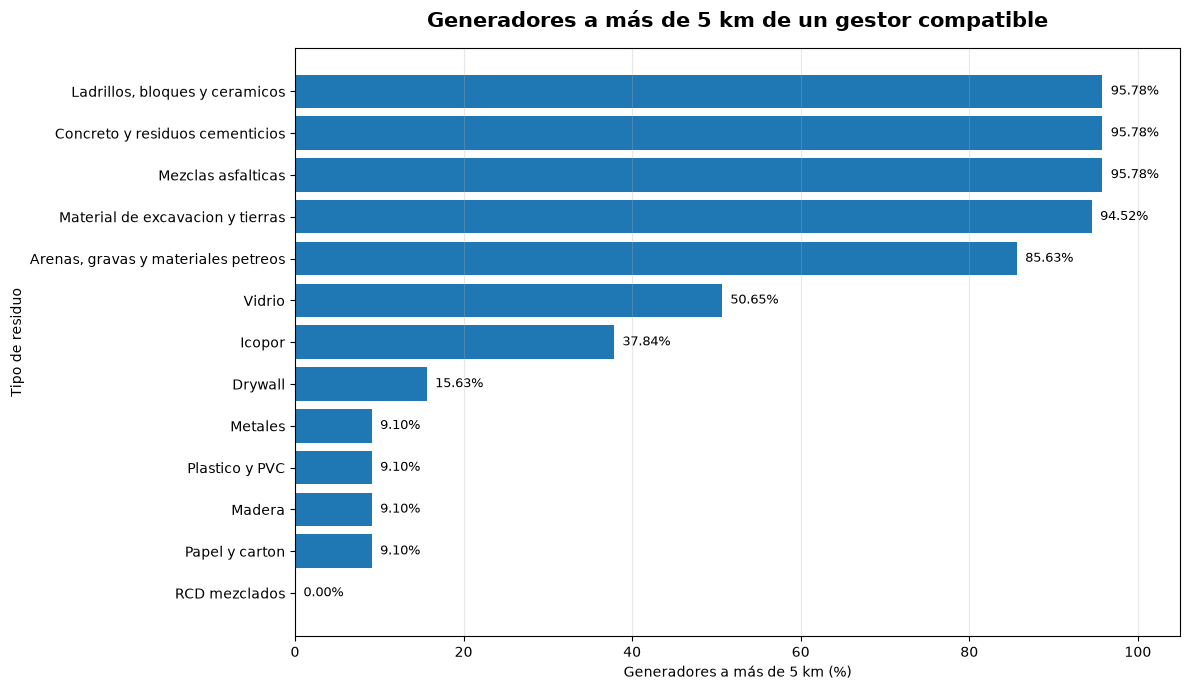


RESIDUOS CON MAYORES BRECHAS DE COBERTURA


,Codigo_residuo,Tipo_residuo,generadores_mas_5km_total,porcentaje_mas_5km_total
0,R01,Concreto y residuos cementicios,1906,95.78
1,R02,"Ladrillos, bloques y ceramicos",1906,95.78
2,R12,Mezclas asfalticas,1906,95.78
3,R03,Material de excavacion y tierras,1881,94.52
4,R04,"Arenas, gravas y materiales petreos",1704,85.63


In [142]:

# ============================================================
# 13.8.18 - VISUALIZACIÓN DE BRECHAS DE COBERTURA
# Comparación de cobertura por tipo de residuo
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

print("=" * 85)
print("13.8.18 - VISUALIZACIÓN DE BRECHAS DE COBERTURA")
print("=" * 85)

# ------------------------------------------------------------
# 1. PREPARAR DATOS
# ------------------------------------------------------------

datos_grafico = resumen_por_residuo.sort_values(
    "porcentaje_mas_5km_total",
    ascending=True
).copy()

# ------------------------------------------------------------
# 2. GRÁFICO DE BRECHAS POR TIPO DE RESIDUO
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    datos_grafico["Tipo_residuo"],
    datos_grafico["porcentaje_mas_5km_total"]
)

ax.set_title(
    "Generadores a más de 5 km de un gestor compatible",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Generadores a más de 5 km (%)")
ax.set_ylabel("Tipo de residuo")

ax.set_xlim(0, 105)
ax.grid(axis="x", alpha=0.3)

# Etiquetas de porcentaje
for barra, valor in zip(
    barras,
    datos_grafico["porcentaje_mas_5km_total"]
):
    ax.text(
        valor + 1,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. IDENTIFICAR LOS RESIDUOS CON MAYORES BRECHAS
# ------------------------------------------------------------

print("\nRESIDUOS CON MAYORES BRECHAS DE COBERTURA")

display(
    resumen_por_residuo[
        [
            "Codigo_residuo",
            "Tipo_residuo",
            "generadores_mas_5km_total",
            "porcentaje_mas_5km_total"
        ]
    ].head(5).round(2)
)


In [143]:

# ============================================================
# ETAPA 13.9.1
# IDENTIFICACION DE GESTORES CANDIDATOS POR GENERADOR Y RESIDUO
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PREPARAR GENERADORES
# ------------------------------------------------------------

generadores_logistica = generadores_cobertura.copy()

generadores_logistica = generadores_logistica.reset_index(drop=True)

generadores_logistica["_id_fila"] = np.arange(
    len(generadores_logistica)
)

# ------------------------------------------------------------
# 2. PREPARAR GESTORES
# ------------------------------------------------------------

gestores_logistica = inventario_gestores.copy()

gestores_logistica = gestores_logistica.rename(columns={
    "Longitud": "longitud_gestor",
    "Latitud": "latitud_gestor"
})

gestores_logistica["ID_gestor"] = (
    gestores_logistica["ID_gestor"].astype(str)
)

# ------------------------------------------------------------
# 3. PREPARAR COMPATIBILIDADES CONFIRMADAS
# ------------------------------------------------------------

compatibles_logistica = matriz_compatibilidad.copy()

compatibles_logistica["ID_gestor"] = (
    compatibles_logistica["ID_gestor"].astype(str)
)

compatibles_logistica = compatibles_logistica[
    compatibles_logistica["Estado_compatibilidad"]
    == "Compatible reportado"
].copy()

# Excluir residuos mezclados:
# no tienen compatibilidad confirmada en la matriz.

compatibles_logistica = compatibles_logistica[
    compatibles_logistica["Codigo_residuo"] != "RCD_MIX"
].copy()

# ------------------------------------------------------------
# 4. GENERAR COMBINACIONES GENERADOR-GESTOR-RESIDUO
# ------------------------------------------------------------

generadores_logistica["_key"] = 1
gestores_logistica["_key"] = 1

combinaciones_logistica = generadores_logistica.merge(
    gestores_logistica,
    on="_key",
    how="inner"
).drop(columns="_key")

# Incorporar únicamente las combinaciones compatibles
candidatos_logistica = combinaciones_logistica.merge(
    compatibles_logistica[
        [
            "ID_gestor",
            "Codigo_residuo",
            "Tipo_residuo",
            "Estado_compatibilidad"
        ]
    ].drop_duplicates(
        subset=["ID_gestor", "Codigo_residuo"]
    ),
    on="ID_gestor",
    how="inner"
)

# ------------------------------------------------------------
# 5. CALCULAR DISTANCIA EN LINEA RECTA
# ------------------------------------------------------------

lat1 = np.radians(
    candidatos_logistica["latitud"].to_numpy()
)

lon1 = np.radians(
    candidatos_logistica["longitud"].to_numpy()
)

lat2 = np.radians(
    candidatos_logistica["latitud_gestor"].to_numpy()
)

lon2 = np.radians(
    candidatos_logistica["longitud_gestor"].to_numpy()
)

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

candidatos_logistica["distancia_linea_recta_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

# ------------------------------------------------------------
# 6. ORDENAR CANDIDATOS
# ------------------------------------------------------------

candidatos_logistica = candidatos_logistica.sort_values(
    [
        "_id_fila",
        "Codigo_residuo",
        "distancia_linea_recta_km"
    ]
).reset_index(drop=True)

candidatos_logistica["orden_candidato"] = (
    candidatos_logistica.groupby(
        ["_id_fila", "Codigo_residuo"]
    ).cumcount() + 1
)

# ------------------------------------------------------------
# 7. RESULTADOS
# ------------------------------------------------------------

print("ETAPA 13.9.1 - GESTORES CANDIDATOS")
print("-----------------------------------")

print(
    "Generadores:",
    generadores_logistica["_id_fila"].nunique()
)

print(
    "Gestores:",
    gestores_logistica["ID_gestor"].nunique()
)

print(
    "Tipos de residuos:",
    candidatos_logistica["Codigo_residuo"].nunique()
)

print(
    "Combinaciones generador-gestor-residuo:",
    len(candidatos_logistica)
)

print(
    "Generadores con al menos un gestor candidato:",
    candidatos_logistica["_id_fila"].nunique()
)

print(
    "Gestores candidatos únicos:",
    candidatos_logistica["ID_gestor"].nunique()
)

print("\nPRIMEROS CANDIDATOS")
display(
    candidatos_logistica[
        [
            "idproy",
            "nombproy",
            "cluster_dbscan",
            "Codigo_residuo",
            "Tipo_residuo",
            "ID_gestor",
            "Nombre_gestor",
            "distancia_linea_recta_km",
            "orden_candidato"
        ]
    ].head(20)
)

print("\nCANTIDAD DE CANDIDATOS POR RESIDUO")
display(
    candidatos_logistica.groupby(
        ["Codigo_residuo", "Tipo_residuo"]
    ).agg(
        gestores_candidatos_promedio=(
            "ID_gestor",
            "count"
        ),
        generadores_evaluados=(
            "_id_fila",
            "nunique"
        )
    ).reset_index()
)


ETAPA 13.9.1 - GESTORES CANDIDATOS
-----------------------------------
Generadores: 1990
Gestores: 28
Tipos de residuos: 12
Combinaciones generador-gestor-residuo: 210940
Generadores con al menos un gestor candidato: 1990
Gestores candidatos únicos: 27

PRIMEROS CANDIDATOS


,idproy,nombproy,cluster_dbscan,Codigo_residuo,Tipo_residuo,ID_gestor,Nombre_gestor,distancia_linea_recta_km,orden_candidato
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R01,Concreto y residuos cementicios,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,1
1,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R02,"Ladrillos, bloques y ceramicos",9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,1
2,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,5,CENTRAL DE MEZCLAS,10.602250,1
3,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,4,CEMEX-TUNJUELO,11.247359,2
4,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,2,HOLCIM MAQUINAS AMARILLAS,11.485193,3
5,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,4
6,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,3,FUNDACIÓN SAN ANTONIO,11.852530,5
7,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R03,Material de excavacion y tierras,1,CEMEX-LA FISCALA,12.706223,6
8,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R04,"Arenas, gravas y materiales petreos",7,AMCON COLOMBIA SAS,6.678525,1
9,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,-1,R04,"Arenas, gravas y materiales petreos",9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,2



CANTIDAD DE CANDIDATOS POR RESIDUO


,Codigo_residuo,Tipo_residuo,gestores_candidatos_promedio,generadores_evaluados
0,R01,Concreto y residuos cementicios,1990,1990
1,R02,"Ladrillos, bloques y ceramicos",1990,1990
2,R03,Material de excavacion y tierras,11940,1990
3,R04,"Arenas, gravas y materiales petreos",3980,1990
4,R05,Madera,31840,1990
5,R06,Metales,33830,1990
6,R07,Plastico y PVC,33830,1990
7,R08,Papel y carton,31840,1990
8,R09,Drywall,31840,1990
9,R10,Icopor,19900,1990


In [144]:

# ============================================================
# ETAPA 13.9.2
# SELECCION DE CANDIDATOS PARA CALCULO DE RUTAS
# ============================================================

# 1. Seleccionar los 3 gestores más cercanos por generador y residuo

candidatos_top3 = candidatos_logistica[
    candidatos_logistica["orden_candidato"] <= 3
].copy()

# 2. Conservar pares únicos generador-gestor
# Un mismo recorrido puede servir para varios tipos de residuos.

rutas_candidatas = candidatos_top3.drop_duplicates(
    subset=["_id_fila", "ID_gestor"]
).copy()

# 3. Verificar coordenadas
rutas_candidatas = rutas_candidatas.dropna(
    subset=[
        "longitud",
        "latitud",
        "longitud_gestor",
        "latitud_gestor"
    ]
)

# 4. Identificar rutas únicas
rutas_candidatas = rutas_candidatas.reset_index(drop=True)

rutas_candidatas["id_ruta"] = (
    np.arange(len(rutas_candidatas)) + 1
)

# 5. Resumen
print("ETAPA 13.9.2 - PREPARACION DE RUTAS")
print("-----------------------------------")

print(
    "Combinaciones originales:",
    len(candidatos_logistica)
)

print(
    "Candidatos dentro del top 3:",
    len(candidatos_top3)
)

print(
    "Rutas únicas generador-gestor:",
    len(rutas_candidatas)
)

print(
    "Generadores con rutas candidatas:",
    rutas_candidatas["_id_fila"].nunique()
)

print(
    "Gestores incluidos:",
    rutas_candidatas["ID_gestor"].nunique()
)

print("\nPRIMERAS RUTAS CANDIDATAS")

display(
    rutas_candidatas[
        [
            "id_ruta",
            "idproy",
            "cluster_dbscan",
            "Codigo_residuo",
            "ID_gestor",
            "Nombre_gestor",
            "distancia_linea_recta_km",
            "longitud",
            "latitud",
            "longitud_gestor",
            "latitud_gestor"
        ]
    ].head(15)
)


ETAPA 13.9.2 - PREPARACION DE RUTAS
-----------------------------------
Combinaciones originales: 210940
Candidatos dentro del top 3: 57710
Rutas únicas generador-gestor: 23423
Generadores con rutas candidatas: 1990
Gestores incluidos: 27

PRIMERAS RUTAS CANDIDATAS


,id_ruta,idproy,cluster_dbscan,Codigo_residuo,ID_gestor,Nombre_gestor,distancia_linea_recta_km,longitud,latitud,longitud_gestor,latitud_gestor
0,1,000991,-1,R01,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,-74.172282,4.634849,-74.124917,4.539283
1,2,000991,-1,R03,5,CENTRAL DE MEZCLAS,10.602250,-74.172282,4.634849,-74.132539,4.548119
2,3,000991,-1,R03,4,CEMEX-TUNJUELO,11.247359,-74.172282,4.634849,-74.131046,4.542427
3,4,000991,-1,R03,2,HOLCIM MAQUINAS AMARILLAS,11.485193,-74.172282,4.634849,-74.129290,4.540869
4,5,000991,-1,R04,7,AMCON COLOMBIA SAS,6.678525,-74.172282,4.634849,-74.149480,4.690445
5,6,000991,-1,R05,16,SOLUCIONES AMBIENTALES A&J S.A.S,3.568983,-74.172282,4.634849,-74.200740,4.619829
6,7,000991,-1,R05,21,C&L SOLUCIONES EMPRESARIALES S.A.S.,3.878179,-74.172282,4.634849,-74.142026,4.652370
7,8,000991,-1,R05,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,4.618682,-74.172282,4.634849,-74.142579,4.605715
8,9,000991,-1,R09,25,GLOBO METAL F.M S.A.S,7.006909,-74.172282,4.634849,-74.150633,4.694054
9,10,000991,-1,R09,18,ECOPLANET SOLUCIONES AR SAS,8.761533,-74.172282,4.634849,-74.139688,4.706635


In [145]:

# ============================================================
# ETAPA 13.9.3
# CALCULO DE DISTANCIAS Y TIEMPOS POR CARRETERA CON OSRM
# ============================================================

import requests
import pandas as pd
import numpy as np
import time

# ------------------------------------------------------------
# 1. PREPARAR ORIGENES Y DESTINOS UNICOS
# ------------------------------------------------------------

origenes = (
    rutas_candidatas[
        ["_id_fila", "longitud", "latitud"]
    ]
    .drop_duplicates("_id_fila")
    .dropna(subset=["longitud", "latitud"])
    .reset_index(drop=True)
)

destinos = (
    gestores_logistica[
        [
            "ID_gestor",
            "Nombre_gestor",
            "longitud_gestor",
            "latitud_gestor"
        ]
    ]
    .drop_duplicates("ID_gestor")
    .dropna(
        subset=["longitud_gestor", "latitud_gestor"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. CONFIGURACION
# ------------------------------------------------------------

URL_OSRM = "https://router.project-osrm.org/table/v1/driving/"

TAMANO_BLOQUE = 60

resultados_rutas = []
errores_osrm = []

# ------------------------------------------------------------
# 3. CONSULTAR OSRM POR BLOQUES
# ------------------------------------------------------------

total_bloques = int(
    np.ceil(len(origenes) / TAMANO_BLOQUE)
)

for numero_bloque, inicio in enumerate(
    range(0, len(origenes), TAMANO_BLOQUE),
    start=1
):

    bloque = origenes.iloc[
        inicio:inicio + TAMANO_BLOQUE
    ].copy()

    n_origenes = len(bloque)
    n_destinos = len(destinos)

    # Coordenadas en formato longitud,latitud
    coordenadas = []

    for _, fila in bloque.iterrows():
        coordenadas.append(
            f'{fila["longitud"]},{fila["latitud"]}'
        )

    for _, fila in destinos.iterrows():
        coordenadas.append(
            f'{fila["longitud_gestor"]},{fila["latitud_gestor"]}'
        )

    coordenadas_url = ";".join(coordenadas)

    indices_origenes = ";".join(
        str(i) for i in range(n_origenes)
    )

    indices_destinos = ";".join(
        str(i)
        for i in range(n_origenes, n_origenes + n_destinos)
    )

    parametros = {
        "sources": indices_origenes,
        "destinations": indices_destinos,
        "annotations": "distance,duration"
    }

    try:

        respuesta = requests.get(
            URL_OSRM + coordenadas_url,
            params=parametros,
            timeout=120
        )

        respuesta.raise_for_status()
        datos_osrm = respuesta.json()

        if datos_osrm.get("code") != "Ok":
            raise ValueError(
                datos_osrm.get("message", "Error de OSRM")
            )

        matriz_distancias = datos_osrm["distances"]
        matriz_duraciones = datos_osrm["durations"]

        # Guardar resultados para las rutas candidatas
        for i, (_, origen) in enumerate(bloque.iterrows()):

            for j, (_, destino) in enumerate(destinos.iterrows()):

                distancia = matriz_distancias[i][j]
                duracion = matriz_duraciones[i][j]

                resultados_rutas.append({
                    "_id_fila": origen["_id_fila"],
                    "ID_gestor": str(destino["ID_gestor"]),
                    "distancia_carretera_m": distancia,
                    "tiempo_ruta_segundos": duracion
                })

        print(
            f"Bloque {numero_bloque}/{total_bloques} "
            f"completado: {n_origenes} generadores"
        )

    except Exception as error:

        errores_osrm.append({
            "bloque": numero_bloque,
            "error": str(error)
        })

        print(
            f"Error en bloque {numero_bloque}: {error}"
        )

    # Pausa para no saturar el servicio público
    time.sleep(1)

# ------------------------------------------------------------
# 4. CONVERTIR RESULTADOS EN DATAFRAME
# ------------------------------------------------------------

rutas_osrm = pd.DataFrame(resultados_rutas)

if rutas_osrm.empty:
    raise RuntimeError(
        "OSRM no devolvió rutas. Revisa la conexión "
        "o los errores registrados."
    )

rutas_osrm["ID_gestor"] = (
    rutas_osrm["ID_gestor"].astype(str)
)

# Convertir unidades
rutas_osrm["distancia_carretera_km"] = (
    rutas_osrm["distancia_carretera_m"] / 1000
)

rutas_osrm["tiempo_ruta_minutos"] = (
    rutas_osrm["tiempo_ruta_segundos"] / 60
)

# ------------------------------------------------------------
# 5. INTEGRAR RESULTADOS A LAS RUTAS CANDIDATAS
# ------------------------------------------------------------

rutas_candidatas["ID_gestor"] = (
    rutas_candidatas["ID_gestor"].astype(str)
)

rutas_carretera = rutas_candidatas.merge(
    rutas_osrm,
    on=["_id_fila", "ID_gestor"],
    how="left"
)

# ------------------------------------------------------------
# 6. VALIDACION
# ------------------------------------------------------------

print("\nETAPA 13.9.3 - RESULTADOS OSRM")
print("--------------------------------")

print("Rutas candidatas:", len(rutas_candidatas))
print("Registros devueltos por OSRM:", len(rutas_osrm))

print(
    "Rutas con distancia calculada:",
    rutas_carretera["distancia_carretera_km"].notna().sum()
)

print(
    "Rutas sin distancia:",
    rutas_carretera["distancia_carretera_km"].isna().sum()
)

print("Bloques con error:", len(errores_osrm))

print("\nPRIMERAS RUTAS CALCULADAS")

display(
    rutas_carretera[
        [
            "idproy",
            "Codigo_residuo",
            "Nombre_gestor",
            "distancia_linea_recta_km",
            "distancia_carretera_km",
            "tiempo_ruta_minutos"
        ]
    ].head(15)
)

if errores_osrm:
    print("\nERRORES OSRM")
    display(pd.DataFrame(errores_osrm))


Bloque 1/34 completado: 60 generadores
Bloque 2/34 completado: 60 generadores
Bloque 3/34 completado: 60 generadores
Bloque 4/34 completado: 60 generadores
Bloque 5/34 completado: 60 generadores
Bloque 6/34 completado: 60 generadores
Bloque 7/34 completado: 60 generadores
Bloque 8/34 completado: 60 generadores
Bloque 9/34 completado: 60 generadores
Bloque 10/34 completado: 60 generadores
Bloque 11/34 completado: 60 generadores
Bloque 12/34 completado: 60 generadores
Bloque 13/34 completado: 60 generadores
Bloque 14/34 completado: 60 generadores
Bloque 15/34 completado: 60 generadores
Bloque 16/34 completado: 60 generadores
Bloque 17/34 completado: 60 generadores
Bloque 18/34 completado: 60 generadores
Bloque 19/34 completado: 60 generadores
Bloque 20/34 completado: 60 generadores
Bloque 21/34 completado: 60 generadores
Bloque 22/34 completado: 60 generadores
Bloque 23/34 completado: 60 generadores
Bloque 24/34 completado: 60 generadores
Bloque 25/34 completado: 60 generadores
Bloque 26

,idproy,Codigo_residuo,Nombre_gestor,distancia_linea_recta_km,distancia_carretera_km,tiempo_ruta_minutos
0,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,11.852530,15.0986,16.686667
1,000991,R03,CENTRAL DE MEZCLAS,10.602250,12.1195,13.865000
2,000991,R03,CEMEX-TUNJUELO,11.247359,13.0924,17.765000
3,000991,R03,HOLCIM MAQUINAS AMARILLAS,11.485193,15.4209,17.231667
4,000991,R04,AMCON COLOMBIA SAS,6.678525,11.1194,19.016667
5,000991,R05,SOLUCIONES AMBIENTALES A&J S.A.S,3.568983,4.9405,6.798333
6,000991,R05,C&L SOLUCIONES EMPRESARIALES S.A.S.,3.878179,4.7588,7.930000
7,000991,R05,ECO ENVIRONMENT DE COLOMBIA S.A.S.,4.618682,5.7543,8.846667
8,000991,R09,GLOBO METAL F.M S.A.S,7.006909,11.3407,18.190000
9,000991,R09,ECOPLANET SOLUCIONES AR SAS,8.761533,14.0722,21.460000


In [146]:

# ============================================================
# ETAPA 13.9.4
# COMPARACION Y SELECCION DE GESTORES POR GENERADOR Y RESIDUO
# ============================================================

# 1. Conservar únicamente rutas calculadas correctamente

rutas_validas = rutas_carretera.dropna(
    subset=[
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
).copy()

# 2. Ordenar por distancia y tiempo

rutas_validas = rutas_validas.sort_values(
    [
        "_id_fila",
        "Codigo_residuo",
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
)

# 3. Seleccionar gestor con menor distancia por carretera

mejor_distancia = (
    rutas_validas
    .drop_duplicates(
        subset=["_id_fila", "Codigo_residuo"],
        keep="first"
    )
    .copy()
)

mejor_distancia = mejor_distancia.rename(
    columns={
        "ID_gestor": "ID_gestor_menor_distancia",
        "Nombre_gestor": "gestor_menor_distancia",
        "distancia_carretera_km": "menor_distancia_carretera_km",
        "tiempo_ruta_minutos": "tiempo_gestor_menor_distancia_min"
    }
)

# 4. Seleccionar gestor con menor tiempo

mejor_tiempo = (
    rutas_validas
    .sort_values(
        [
            "_id_fila",
            "Codigo_residuo",
            "tiempo_ruta_minutos",
            "distancia_carretera_km"
        ]
    )
    .drop_duplicates(
        subset=["_id_fila", "Codigo_residuo"],
        keep="first"
    )
    .copy()
)

mejor_tiempo = mejor_tiempo.rename(
    columns={
        "ID_gestor": "ID_gestor_menor_tiempo",
        "Nombre_gestor": "gestor_menor_tiempo",
        "distancia_carretera_km": "distancia_gestor_menor_tiempo_km",
        "tiempo_ruta_minutos": "menor_tiempo_min"
    }
)

# 5. Construir tabla comparativa

columnas_distancia = [
    "_id_fila",
    "Codigo_residuo",
    "Tipo_residuo",
    "idproy",
    "cluster_dbscan",
    "ID_gestor_menor_distancia",
    "gestor_menor_distancia",
    "distancia_linea_recta_km",
    "menor_distancia_carretera_km",
    "tiempo_gestor_menor_distancia_min"
]

columnas_tiempo = [
    "_id_fila",
    "Codigo_residuo",
    "ID_gestor_menor_tiempo",
    "gestor_menor_tiempo",
    "distancia_gestor_menor_tiempo_km",
    "menor_tiempo_min"
]

comparacion_gestores = mejor_distancia[
    columnas_distancia
].merge(
    mejor_tiempo[columnas_tiempo],
    on=["_id_fila", "Codigo_residuo"],
    how="inner"
)

# 6. Identificar si ambas alternativas coinciden

comparacion_gestores["coincide_mejor_alternativa"] = (
    comparacion_gestores["ID_gestor_menor_distancia"]
    == comparacion_gestores["ID_gestor_menor_tiempo"]
)

# 7. Calcular diferencia entre alternativas

comparacion_gestores["diferencia_tiempo_min"] = (
    comparacion_gestores["tiempo_gestor_menor_distancia_min"]
    - comparacion_gestores["menor_tiempo_min"]
)

comparacion_gestores["diferencia_distancia_km"] = (
    comparacion_gestores["menor_distancia_carretera_km"]
    - comparacion_gestores["distancia_gestor_menor_tiempo_km"]
)

# 8. Mostrar resultados

print("ETAPA 13.9.4 - COMPARACION DE GESTORES")
print("---------------------------------------")

print(
    "Combinaciones generador-residuo evaluadas:",
    len(comparacion_gestores)
)

print(
    "Casos donde coincide el gestor más cercano y más rápido:",
    comparacion_gestores[
        "coincide_mejor_alternativa"
    ].sum()
)

print(
    "Casos donde distancia y tiempo llevan a gestores distintos:",
    (~comparacion_gestores[
        "coincide_mejor_alternativa"
    ]).sum()
)

print("\nPRIMERAS COMPARACIONES")

display(
    comparacion_gestores[
        [
            "idproy",
            "Codigo_residuo",
            "gestor_menor_distancia",
            "menor_distancia_carretera_km",
            "tiempo_gestor_menor_distancia_min",
            "gestor_menor_tiempo",
            "distancia_gestor_menor_tiempo_km",
            "menor_tiempo_min",
            "coincide_mejor_alternativa"
        ]
    ].head(20)
)

# 9. Resumen por tipo de residuo

resumen_comparacion = (
    comparacion_gestores
    .groupby("Codigo_residuo")
    .agg(
        combinaciones_evaluadas=("idproy", "count"),
        distancia_promedio_km=(
            "menor_distancia_carretera_km", "mean"
        ),
        tiempo_promedio_min=(
            "menor_tiempo_min", "mean"
        ),
        casos_mismo_gestor=(
            "coincide_mejor_alternativa", "sum"
        )
    )
    .reset_index()
)

print("\nRESUMEN POR TIPO DE RESIDUO")
display(resumen_comparacion)


ETAPA 13.9.4 - COMPARACION DE GESTORES
---------------------------------------
Combinaciones generador-residuo evaluadas: 13308
Casos donde coincide el gestor más cercano y más rápido: 13006
Casos donde distancia y tiempo llevan a gestores distintos: 302

PRIMERAS COMPARACIONES


,idproy,Codigo_residuo,gestor_menor_distancia,menor_distancia_carretera_km,tiempo_gestor_menor_distancia_min,gestor_menor_tiempo,distancia_gestor_menor_tiempo_km,menor_tiempo_min,coincide_mejor_alternativa
0,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,15.0986,16.686667,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,15.0986,16.686667,True
1,000991,R03,CENTRAL DE MEZCLAS,12.1195,13.865000,CENTRAL DE MEZCLAS,12.1195,13.865000,True
2,000991,R04,AMCON COLOMBIA SAS,11.1194,19.016667,AMCON COLOMBIA SAS,11.1194,19.016667,True
3,000991,R05,C&L SOLUCIONES EMPRESARIALES S.A.S.,4.7588,7.930000,SOLUCIONES AMBIENTALES A&J S.A.S,4.9405,6.798333,False
4,000991,R09,GLOBO METAL F.M S.A.S,11.3407,18.190000,GLOBO METAL F.M S.A.S,11.3407,18.190000,True
5,000991,R10,CAR INGENIERÍA S.A.S.,15.4245,23.940000,CAR INGENIERÍA S.A.S.,15.4245,23.940000,True
6,000991,R11,EXIRECICLABLES MC S.A.S.,16.3200,20.346667,EXIRECICLABLES MC S.A.S.,16.3200,20.346667,True
7,000743,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,31.0317,39.846667,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,31.0317,39.846667,True
8,000743,R03,CENTRAL DE MEZCLAS,28.0526,37.025000,CENTRAL DE MEZCLAS,28.0526,37.025000,True
9,000743,R04,AMCON COLOMBIA SAS,13.5501,21.213333,AMCON COLOMBIA SAS,13.5501,21.213333,True



RESUMEN POR TIPO DE RESIDUO


,Codigo_residuo,combinaciones_evaluadas,distancia_promedio_km,tiempo_promedio_min,casos_mismo_gestor
0,R01,1990,23.344708,30.398262,1990
1,R03,1990,20.431436,27.647185,1949
2,R04,1990,15.468085,23.823853,1990
3,R05,1990,4.796681,8.015033,1856
4,R06,818,8.246991,11.594232,812
5,R07,19,8.824332,11.946404,19
6,R08,104,8.925224,12.078205,104
7,R09,613,12.826116,17.390299,613
8,R10,1811,9.958724,13.968683,1733
9,R11,1983,16.074105,20.138387,1940


In [147]:

# ============================================================
# ETAPA 13.9.5 - ESTIMACION DE COMBUSTIBLE Y EMISIONES
# ============================================================

# 1. Parametros del escenario
consumo_km_por_litro = 3.0
factor_emision_diesel = 2.68  # kg CO2 por litro
factor_ida_vuelta = 2

# 2. Escenario 1: gestor con menor distancia
escenario_distancia = comparacion_gestores[
    [
        "idproy",
        "Codigo_residuo",
        "gestor_menor_distancia",
        "menor_distancia_carretera_km",
        "tiempo_gestor_menor_distancia_min"
    ]
].copy()

escenario_distancia = escenario_distancia.rename(columns={
    "gestor_menor_distancia": "gestor_seleccionado",
    "menor_distancia_carretera_km": "distancia_ida_km",
    "tiempo_gestor_menor_distancia_min": "tiempo_ida_min"
})

escenario_distancia["criterio_seleccion"] = "Menor distancia"


# 3. Escenario 2: gestor con menor tiempo
escenario_tiempo = comparacion_gestores[
    [
        "idproy",
        "Codigo_residuo",
        "gestor_menor_tiempo",
        "distancia_gestor_menor_tiempo_km",
        "menor_tiempo_min"
    ]
].copy()

escenario_tiempo = escenario_tiempo.rename(columns={
    "gestor_menor_tiempo": "gestor_seleccionado",
    "distancia_gestor_menor_tiempo_km": "distancia_ida_km",
    "menor_tiempo_min": "tiempo_ida_min"
})

escenario_tiempo["criterio_seleccion"] = "Menor tiempo"


# 4. Unir los dos escenarios
alternativas_emisiones = pd.concat(
    [escenario_distancia, escenario_tiempo],
    ignore_index=True
)

# 5. Calcular recorrido completo, combustible y emisiones
alternativas_emisiones["distancia_total_km"] = (
    alternativas_emisiones["distancia_ida_km"] * factor_ida_vuelta
)

alternativas_emisiones["combustible_litros"] = (
    alternativas_emisiones["distancia_total_km"] / consumo_km_por_litro
)

alternativas_emisiones["emisiones_kg_co2"] = (
    alternativas_emisiones["combustible_litros"] * factor_emision_diesel
)

# 6. Resumen general por escenario
resumen_emisiones = (
    alternativas_emisiones
    .groupby("criterio_seleccion")
    .agg(
        combinaciones=("idproy", "count"),
        distancia_promedio_km=("distancia_total_km", "mean"),
        combustible_promedio_l=("combustible_litros", "mean"),
        emisiones_promedio_kg=("emisiones_kg_co2", "mean"),
        emisiones_totales_kg=("emisiones_kg_co2", "sum")
    )
    .reset_index()
)

# 7. Resumen por tipo de residuo y escenario
resumen_emisiones_residuo = (
    alternativas_emisiones
    .groupby(["Codigo_residuo", "criterio_seleccion"])
    .agg(
        combinaciones=("idproy", "count"),
        distancia_promedio_km=("distancia_total_km", "mean"),
        combustible_promedio_l=("combustible_litros", "mean"),
        emisiones_promedio_kg=("emisiones_kg_co2", "mean"),
        emisiones_totales_kg=("emisiones_kg_co2", "sum")
    )
    .reset_index()
)

# 8. Mostrar resultados
print("ETAPA 13.9.5 - ESTIMACION DE COMBUSTIBLE Y EMISIONES")
print("----------------------------------------------------")

print("\nPARAMETROS UTILIZADOS")
print(f"Consumo del vehiculo: {consumo_km_por_litro} km/L")
print(f"Factor de emision: {factor_emision_diesel} kg CO2/L")
print(f"Tipo de recorrido: {'Ida y vuelta' if factor_ida_vuelta == 2 else 'Solo ida'}")

print("\nRESUMEN GENERAL")
display(resumen_emisiones.round(3))

print("\nRESUMEN POR TIPO DE RESIDUO")
display(resumen_emisiones_residuo.round(3))

print("\nPRIMERAS ALTERNATIVAS EVALUADAS")
display(alternativas_emisiones.head(20).round(3))


ETAPA 13.9.5 - ESTIMACION DE COMBUSTIBLE Y EMISIONES
----------------------------------------------------

PARAMETROS UTILIZADOS
Consumo del vehiculo: 3.0 km/L
Factor de emision: 2.68 kg CO2/L
Tipo de recorrido: Ida y vuelta

RESUMEN GENERAL


,criterio_seleccion,combinaciones,distancia_promedio_km,combustible_promedio_l,emisiones_promedio_kg,emisiones_totales_kg
0,Menor distancia,13308,29.014,9.671,25.919,344926.617
1,Menor tiempo,13308,29.043,9.681,25.945,345276.568



RESUMEN POR TIPO DE RESIDUO


,Codigo_residuo,criterio_seleccion,combinaciones,distancia_promedio_km,combustible_promedio_l,emisiones_promedio_kg,emisiones_totales_kg
0,R01,Menor distancia,1990,46.689,15.563,41.709,83001.330
1,R01,Menor tiempo,1990,46.689,15.563,41.709,83001.330
2,R03,Menor distancia,1990,40.863,13.621,36.504,72643.288
3,R03,Menor tiempo,1990,40.913,13.638,36.549,72731.761
4,R04,Menor distancia,1990,30.936,10.312,27.636,54996.260
5,R04,Menor tiempo,1990,30.936,10.312,27.636,54996.260
6,R05,Menor distancia,1990,9.593,3.198,8.570,17054.438
7,R05,Menor tiempo,1990,9.669,3.223,8.637,17188.020
8,R06,Menor distancia,818,16.494,5.498,14.735,12052.922
9,R06,Menor tiempo,818,16.505,5.502,14.744,12060.844



PRIMERAS ALTERNATIVAS EVALUADAS


,idproy,Codigo_residuo,gestor_seleccionado,distancia_ida_km,tiempo_ida_min,criterio_seleccion,distancia_total_km,combustible_litros,emisiones_kg_co2
0,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,15.099,16.687,Menor distancia,30.197,10.066,26.976
1,000991,R03,CENTRAL DE MEZCLAS,12.120,13.865,Menor distancia,24.239,8.080,21.654
2,000991,R04,AMCON COLOMBIA SAS,11.119,19.017,Menor distancia,22.239,7.413,19.867
3,000991,R05,C&L SOLUCIONES EMPRESARIALES S.A.S.,4.759,7.930,Menor distancia,9.518,3.173,8.502
4,000991,R09,GLOBO METAL F.M S.A.S,11.341,18.190,Menor distancia,22.681,7.560,20.262
5,000991,R10,CAR INGENIERÍA S.A.S.,15.424,23.940,Menor distancia,30.849,10.283,27.558
6,000991,R11,EXIRECICLABLES MC S.A.S.,16.320,20.347,Menor distancia,32.640,10.880,29.158
7,000743,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,31.032,39.847,Menor distancia,62.063,20.688,55.443
8,000743,R03,CENTRAL DE MEZCLAS,28.053,37.025,Menor distancia,56.105,18.702,50.121
9,000743,R04,AMCON COLOMBIA SAS,13.550,21.213,Menor distancia,27.100,9.033,24.210


In [148]:

# ============================================================
# ETAPA 13.9.6 - ANALISIS DE SENSIBILIDAD DEL CONSUMO
# ============================================================

# 1. Escenarios de consumo
escenarios_consumo = [2.0, 3.0, 4.0]

factor_emision_diesel = 2.68
factor_ida_vuelta = 2

resultados_sensibilidad = []

# 2. Calcular emisiones para cada escenario
for consumo in escenarios_consumo:

    temporal = alternativas_emisiones[
        [
            "idproy",
            "Codigo_residuo",
            "criterio_seleccion",
            "distancia_ida_km"
        ]
    ].copy()

    temporal["consumo_km_l"] = consumo

    temporal["distancia_total_km"] = (
        temporal["distancia_ida_km"] * factor_ida_vuelta
    )

    temporal["combustible_litros"] = (
        temporal["distancia_total_km"] / consumo
    )

    temporal["emisiones_kg_co2"] = (
        temporal["combustible_litros"] * factor_emision_diesel
    )

    resultados_sensibilidad.append(temporal)

# 3. Unir todos los escenarios
sensibilidad_emisiones = pd.concat(
    resultados_sensibilidad,
    ignore_index=True
)

# 4. Resumen por consumo y criterio
resumen_sensibilidad = (
    sensibilidad_emisiones
    .groupby(["consumo_km_l", "criterio_seleccion"])
    .agg(
        combinaciones=("idproy", "count"),
        combustible_total_l=("combustible_litros", "sum"),
        emisiones_totales_kg=("emisiones_kg_co2", "sum"),
        emisiones_promedio_kg=("emisiones_kg_co2", "mean")
    )
    .reset_index()
)

# 5. Mostrar resultados
print("ETAPA 13.9.6 - ANALISIS DE SENSIBILIDAD")
print("---------------------------------------")

display(resumen_sensibilidad.round(3))


ETAPA 13.9.6 - ANALISIS DE SENSIBILIDAD
---------------------------------------


,consumo_km_l,criterio_seleccion,combinaciones,combustible_total_l,emisiones_totales_kg,emisiones_promedio_kg
0,2.0,Menor distancia,13308,193055.942,517389.925,38.878
1,2.0,Menor tiempo,13308,193251.810,517914.852,38.918
2,3.0,Menor distancia,13308,128703.961,344926.617,25.919
3,3.0,Menor tiempo,13308,128834.540,345276.568,25.945
4,4.0,Menor distancia,13308,96527.971,258694.962,19.439
5,4.0,Menor tiempo,13308,96625.905,258957.426,19.459


In [149]:

# ============================================================
# ETAPA 13.9.7 - ESCENARIOS DE CARGA Y NUMERO DE VIAJES
# ============================================================

import numpy as np
import pandas as pd

# 1. Parametros de simulacion
generacion_escenarios = [2, 5, 10]  # toneladas por generador-residuo
capacidades_vehiculo = [5, 10, 15]  # toneladas por viaje

consumo_km_por_litro = 3.0
factor_emision_diesel = 2.68  # kg CO2 por litro

# 2. Usar las alternativas calculadas en la etapa 13.9.5
base_simulacion = alternativas_emisiones[
    [
        "idproy",
        "Codigo_residuo",
        "gestor_seleccionado",
        "criterio_seleccion",
        "distancia_ida_km"
    ]
].copy()

# 3. Crear combinaciones de generacion y capacidad
escenarios = pd.MultiIndex.from_product(
    [generacion_escenarios, capacidades_vehiculo],
    names=["generacion_toneladas", "capacidad_vehiculo_toneladas"]
).to_frame(index=False)

# 4. Combinar cada alternativa con todos los escenarios
simulacion_viajes = base_simulacion.merge(
    escenarios,
    how="cross"
)

# 5. Calcular numero de viajes necesarios
simulacion_viajes["numero_viajes"] = np.ceil(
    simulacion_viajes["generacion_toneladas"] /
    simulacion_viajes["capacidad_vehiculo_toneladas"]
).astype(int)

# 6. Calcular distancia total recorrida
simulacion_viajes["distancia_total_km"] = (
    simulacion_viajes["distancia_ida_km"]
    * 2
    * simulacion_viajes["numero_viajes"]
)

# 7. Calcular combustible y emisiones
simulacion_viajes["combustible_litros"] = (
    simulacion_viajes["distancia_total_km"] /
    consumo_km_por_litro
)

simulacion_viajes["emisiones_kg_co2"] = (
    simulacion_viajes["combustible_litros"] *
    factor_emision_diesel
)

# 8. Calcular emisiones por tonelada transportada
simulacion_viajes["emisiones_kg_co2_por_tonelada"] = (
    simulacion_viajes["emisiones_kg_co2"] /
    simulacion_viajes["generacion_toneladas"]
)

# 9. Resumen por escenario y criterio
resumen_viajes = (
    simulacion_viajes
    .groupby([
        "generacion_toneladas",
        "capacidad_vehiculo_toneladas",
        "criterio_seleccion"
    ])
    .agg(
        combinaciones=("idproy", "count"),
        viajes_totales=("numero_viajes", "sum"),
        distancia_total_km=("distancia_total_km", "sum"),
        combustible_total_l=("combustible_litros", "sum"),
        emisiones_totales_kg=("emisiones_kg_co2", "sum"),
        emisiones_promedio_por_tonelada=(
            "emisiones_kg_co2_por_tonelada", "mean"
        )
    )
    .reset_index()
)

# 10. Mostrar resultados
print("ETAPA 13.9.7 - ESCENARIOS DE CARGA Y VIAJES")
print("-------------------------------------------")

print("\nPARAMETROS DE SIMULACION")
print("Generacion hipotetica:", generacion_escenarios, "toneladas")
print("Capacidad de vehiculo:", capacidades_vehiculo, "toneladas")
print("Consumo:", consumo_km_por_litro, "km/L")

print("\nRESUMEN DE ESCENARIOS")
display(resumen_viajes.round(3))

print("\nEJEMPLOS DE COMBINACIONES")
display(simulacion_viajes.head(15).round(3))


ETAPA 13.9.7 - ESCENARIOS DE CARGA Y VIAJES
-------------------------------------------

PARAMETROS DE SIMULACION
Generacion hipotetica: [2, 5, 10] toneladas
Capacidad de vehiculo: [5, 10, 15] toneladas
Consumo: 3.0 km/L

RESUMEN DE ESCENARIOS


,generacion_toneladas,capacidad_vehiculo_toneladas,criterio_seleccion,combinaciones,viajes_totales,distancia_total_km,combustible_total_l,emisiones_totales_kg,emisiones_promedio_por_tonelada
0,2,5,Menor distancia,13308,13308,386111.884,128703.961,344926.617,12.959
1,2,5,Menor tiempo,13308,13308,386503.621,128834.540,345276.568,12.973
2,2,10,Menor distancia,13308,13308,386111.884,128703.961,344926.617,12.959
3,2,10,Menor tiempo,13308,13308,386503.621,128834.540,345276.568,12.973
4,2,15,Menor distancia,13308,13308,386111.884,128703.961,344926.617,12.959
5,2,15,Menor tiempo,13308,13308,386503.621,128834.540,345276.568,12.973
6,5,5,Menor distancia,13308,13308,386111.884,128703.961,344926.617,5.184
7,5,5,Menor tiempo,13308,13308,386503.621,128834.540,345276.568,5.189
8,5,10,Menor distancia,13308,13308,386111.884,128703.961,344926.617,5.184
9,5,10,Menor tiempo,13308,13308,386503.621,128834.540,345276.568,5.189



EJEMPLOS DE COMBINACIONES


,idproy,Codigo_residuo,gestor_seleccionado,criterio_seleccion,distancia_ida_km,generacion_toneladas,capacidad_vehiculo_toneladas,numero_viajes,distancia_total_km,combustible_litros,emisiones_kg_co2,emisiones_kg_co2_por_tonelada
0,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,2,5,1,30.197,10.066,26.976,13.488
1,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,2,10,1,30.197,10.066,26.976,13.488
2,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,2,15,1,30.197,10.066,26.976,13.488
3,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,5,5,1,30.197,10.066,26.976,5.395
4,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,5,10,1,30.197,10.066,26.976,5.395
5,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,5,15,1,30.197,10.066,26.976,5.395
6,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,10,5,2,60.394,20.131,53.952,5.395
7,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,10,10,1,30.197,10.066,26.976,2.698
8,000991,R01,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,Menor distancia,15.099,10,15,1,30.197,10.066,26.976,2.698
9,000991,R03,CENTRAL DE MEZCLAS,Menor distancia,12.120,2,5,1,24.239,8.080,21.654,10.827


In [150]:

# ============================================================
# ETAPA 13.9.8 - EFICIENCIA DE LOS ESCENARIOS LOGISTICOS
# ============================================================

# 1. Crear resumen por escenario
resumen_eficiencia = (
    simulacion_viajes
    .groupby([
        "generacion_toneladas",
        "capacidad_vehiculo_toneladas",
        "criterio_seleccion"
    ])
    .agg(
        combinaciones=("idproy", "count"),
        viajes_totales=("numero_viajes", "sum"),
        toneladas_totales=("generacion_toneladas", "sum"),
        combustible_total_l=("combustible_litros", "sum"),
        emisiones_totales_kg=("emisiones_kg_co2", "sum")
    )
    .reset_index()
)

# 2. Calcular eficiencia de utilización del vehículo
resumen_eficiencia["capacidad_total_disponible_ton"] = (
    resumen_eficiencia["viajes_totales"] *
    resumen_eficiencia["capacidad_vehiculo_toneladas"]
)

resumen_eficiencia["utilizacion_capacidad_pct"] = (
    resumen_eficiencia["toneladas_totales"] /
    resumen_eficiencia["capacidad_total_disponible_ton"] * 100
)

# 3. Calcular emisiones por tonelada usando totales
resumen_eficiencia["emisiones_kg_co2_por_ton"] = (
    resumen_eficiencia["emisiones_totales_kg"] /
    resumen_eficiencia["toneladas_totales"]
)

# 4. Definir escenario de referencia:
# 10 toneladas generadas y vehículo de 5 toneladas
referencia = resumen_eficiencia[
    (resumen_eficiencia["generacion_toneladas"] == 10) &
    (resumen_eficiencia["capacidad_vehiculo_toneladas"] == 5) &
    (resumen_eficiencia["criterio_seleccion"] == "Menor distancia")
]["emisiones_totales_kg"].iloc[0]

# 5. Calcular ahorro frente al escenario de referencia
resumen_eficiencia["ahorro_emisiones_kg"] = (
    referencia - resumen_eficiencia["emisiones_totales_kg"]
)

resumen_eficiencia["ahorro_emisiones_pct"] = (
    resumen_eficiencia["ahorro_emisiones_kg"] /
    referencia * 100
)

# 6. Mostrar resultados
print("ETAPA 13.9.8 - EFICIENCIA DE ESCENARIOS")
print("---------------------------------------")

print("\nESCENARIO DE REFERENCIA:")
print("Generacion: 10 toneladas")
print("Capacidad: 5 toneladas")
print(f"Emisiones: {referencia:,.2f} kg CO2")

print("\nCOMPARACION DE ESCENARIOS:")
display(
    resumen_eficiencia[
        [
            "generacion_toneladas",
            "capacidad_vehiculo_toneladas",
            "criterio_seleccion",
            "viajes_totales",
            "toneladas_totales",
            "utilizacion_capacidad_pct",
            "emisiones_totales_kg",
            "emisiones_kg_co2_por_ton",
            "ahorro_emisiones_kg",
            "ahorro_emisiones_pct"
        ]
    ].round(3)
)

# 7. Comparar solamente el criterio de menor distancia
comparacion_capacidades = resumen_eficiencia[
    resumen_eficiencia["criterio_seleccion"] == "Menor distancia"
].copy()

print("\nCOMPARACION DE CAPACIDADES - MENOR DISTANCIA:")
display(
    comparacion_capacidades[
        [
            "generacion_toneladas",
            "capacidad_vehiculo_toneladas",
            "viajes_totales",
            "utilizacion_capacidad_pct",
            "emisiones_totales_kg",
            "emisiones_kg_co2_por_ton",
            "ahorro_emisiones_pct"
        ]
    ].round(3)
)


ETAPA 13.9.8 - EFICIENCIA DE ESCENARIOS
---------------------------------------

ESCENARIO DE REFERENCIA:
Generacion: 10 toneladas
Capacidad: 5 toneladas
Emisiones: 689,853.23 kg CO2

COMPARACION DE ESCENARIOS:


,generacion_toneladas,capacidad_vehiculo_toneladas,criterio_seleccion,viajes_totales,toneladas_totales,utilizacion_capacidad_pct,emisiones_totales_kg,emisiones_kg_co2_por_ton,ahorro_emisiones_kg,ahorro_emisiones_pct
0,2,5,Menor distancia,13308,26616,40.000,344926.617,12.959,344926.617,50.000
1,2,5,Menor tiempo,13308,26616,40.000,345276.568,12.973,344576.665,49.949
2,2,10,Menor distancia,13308,26616,20.000,344926.617,12.959,344926.617,50.000
3,2,10,Menor tiempo,13308,26616,20.000,345276.568,12.973,344576.665,49.949
4,2,15,Menor distancia,13308,26616,13.333,344926.617,12.959,344926.617,50.000
5,2,15,Menor tiempo,13308,26616,13.333,345276.568,12.973,344576.665,49.949
6,5,5,Menor distancia,13308,66540,100.000,344926.617,5.184,344926.617,50.000
7,5,5,Menor tiempo,13308,66540,100.000,345276.568,5.189,344576.665,49.949
8,5,10,Menor distancia,13308,66540,50.000,344926.617,5.184,344926.617,50.000
9,5,10,Menor tiempo,13308,66540,50.000,345276.568,5.189,344576.665,49.949



COMPARACION DE CAPACIDADES - MENOR DISTANCIA:


,generacion_toneladas,capacidad_vehiculo_toneladas,viajes_totales,utilizacion_capacidad_pct,emisiones_totales_kg,emisiones_kg_co2_por_ton,ahorro_emisiones_pct
0,2,5,13308,40.000,344926.617,12.959,50.0
2,2,10,13308,20.000,344926.617,12.959,50.0
4,2,15,13308,13.333,344926.617,12.959,50.0
6,5,5,13308,100.000,344926.617,5.184,50.0
8,5,10,13308,50.000,344926.617,5.184,50.0
10,5,15,13308,33.333,344926.617,5.184,50.0
12,10,5,26616,100.000,689853.233,5.184,0.0
14,10,10,13308,100.000,344926.617,2.592,50.0
16,10,15,13308,66.667,344926.617,2.592,50.0


In [152]:

# ============================================================
# 13.9.8 - COMPARACION JUSTA DE CAPACIDADES (CORREGIDA)
# ============================================================

# Filtrar el criterio de menor distancia
comparacion_justa = resumen_eficiencia[
    resumen_eficiencia["criterio_seleccion"] == "Menor distancia"
].copy()

# Obtener las emisiones de referencia para cada generación:
# vehículo con capacidad de 5 toneladas
referencias = (
    comparacion_justa[
        comparacion_justa["capacidad_vehiculo_toneladas"] == 5
    ]
    .set_index("generacion_toneladas")["emisiones_totales_kg"]
    .to_dict()
)

# Asignar la referencia correspondiente a cada generación
comparacion_justa["emisiones_referencia_kg"] = (
    comparacion_justa["generacion_toneladas"].map(referencias)
)

# Calcular ahorro absoluto y porcentual
comparacion_justa["ahorro_emisiones_kg"] = (
    comparacion_justa["emisiones_referencia_kg"] -
    comparacion_justa["emisiones_totales_kg"]
)

comparacion_justa["ahorro_emisiones_pct"] = (
    comparacion_justa["ahorro_emisiones_kg"] /
    comparacion_justa["emisiones_referencia_kg"] * 100
)

print("COMPARACION JUSTA DE CAPACIDADES")
print("--------------------------------")

display(
    comparacion_justa[
        [
            "generacion_toneladas",
            "capacidad_vehiculo_toneladas",
            "viajes_totales",
            "utilizacion_capacidad_pct",
            "emisiones_totales_kg",
            "emisiones_kg_co2_por_ton",
            "ahorro_emisiones_kg",
            "ahorro_emisiones_pct"
        ]
    ].round(3)
)


COMPARACION JUSTA DE CAPACIDADES
--------------------------------


,generacion_toneladas,capacidad_vehiculo_toneladas,viajes_totales,utilizacion_capacidad_pct,emisiones_totales_kg,emisiones_kg_co2_por_ton,ahorro_emisiones_kg,ahorro_emisiones_pct
0,2,5,13308,40.000,344926.617,12.959,0.000,0.0
2,2,10,13308,20.000,344926.617,12.959,0.000,0.0
4,2,15,13308,13.333,344926.617,12.959,0.000,0.0
6,5,5,13308,100.000,344926.617,5.184,0.000,0.0
8,5,10,13308,50.000,344926.617,5.184,0.000,0.0
10,5,15,13308,33.333,344926.617,5.184,0.000,0.0
12,10,5,26616,100.000,689853.233,5.184,0.000,0.0
14,10,10,13308,100.000,344926.617,2.592,344926.617,50.0
16,10,15,13308,66.667,344926.617,2.592,344926.617,50.0


In [153]:

# ============================================================
# 13.10.1 - REVISION DE LA MATRIZ COMPLETA DE RUTAS
# ============================================================

print("CANDIDATOS LOGISTICOS")
print("---------------------")
print("Dimensiones:", candidatos_logistica.shape)
print("Columnas:")
print(candidatos_logistica.columns.tolist())

print("\nMATRIZ DE RUTAS OSRM")
print("--------------------")
print("Dimensiones:", rutas_osrm.shape)
print("Columnas:")
print(rutas_osrm.columns.tolist())

print("\nPRIMERAS FILAS DE LA MATRIZ OSRM")
display(rutas_osrm.head())

print("\nPRIMERAS FILAS DE LOS CANDIDATOS")
display(candidatos_logistica.head())


CANDIDATOS LOGISTICOS
---------------------
Dimensiones: (210940, 31)
Columnas:
['idproy', 'nombproy', 'dirproy', 'chip', 'coordx', 'coordy', 'fechcreaci', 'fechactual', 'longitud', 'latitud', 'cluster_dbscan', 'es_punto_nucleo', 'distancia_gestor_cercano_m', 'id_gestor_cercano', 'nombre_gestor_cercano', 'categoria_gestor_cercano', 'distancia_gestor_cercano_km', 'rango_distancia', '_id_fila', 'ID_gestor', 'Nombre_gestor', 'Categoria', 'Materiales_aceptados_reportados', 'Aprobacion_reportada', 'longitud_gestor', 'latitud_gestor', 'Codigo_residuo', 'Tipo_residuo', 'Estado_compatibilidad', 'distancia_linea_recta_km', 'orden_candidato']

MATRIZ DE RUTAS OSRM
--------------------
Dimensiones: (55720, 6)
Columnas:
['_id_fila', 'ID_gestor', 'distancia_carretera_m', 'tiempo_ruta_segundos', 'distancia_carretera_km', 'tiempo_ruta_minutos']

PRIMERAS FILAS DE LA MATRIZ OSRM


,_id_fila,ID_gestor,distancia_carretera_m,tiempo_ruta_segundos,distancia_carretera_km,tiempo_ruta_minutos
0,0.0,7,11119.4,1141.0,11.1194,19.016667
1,0.0,8,14073.6,1287.7,14.0736,21.461667
2,0.0,9,15098.6,1001.2,15.0986,16.686667
3,0.0,6,15420.9,1033.9,15.4209,17.231667
4,0.0,19,16458.7,1209.6,16.4587,20.160000



PRIMERAS FILAS DE LOS CANDIDATOS


,idproy,nombproy,dirproy,chip,coordx,coordy,fechcreaci,fechactual,longitud,latitud,...,Categoria,Materiales_aceptados_reportados,Aprobacion_reportada,longitud_gestor,latitud_gestor,Codigo_residuo,Tipo_residuo,Estado_compatibilidad,distancia_linea_recta_km,orden_candidato
0,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,...,Centro de tratamiento y aprovechamiento,"RCD petreos, arenas , gravas, gravillas, rocas...",Radicado SDA: 2020IE223591,-74.124917,4.539283,R01,Concreto y residuos cementicios,Compatible reportado,11.852530,1
1,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,...,Centro de tratamiento y aprovechamiento,"RCD petreos, arenas , gravas, gravillas, rocas...",Radicado SDA: 2020IE223591,-74.124917,4.539283,R02,"Ladrillos, bloques y ceramicos",Compatible reportado,11.852530,1
2,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,...,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución 1280/ 15 Junio 2017,-74.132539,4.548119,R03,Material de excavacion y tierras,Compatible reportado,10.602250,1
3,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,...,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 1480 /04 Diciembre 2014,-74.131046,4.542427,R03,Material de excavacion y tierras,Compatible reportado,11.247359,2
4,000991,CTO 3719-2015. SUMINISTRO AULAS MÃVILES PRIME...,CL 42F SUR 88A 55,,8.94832192106e+04,1.04272313998e+05,27/12/2018,7/03/2019,-74.172282,4.634849,...,Sitio de disposición final,"Escombros, excavación y materiales esteriles",Resolución ANLA 1480 /04 Diciembre 2014,-74.129290,4.540869,R03,Material de excavacion y tierras,Compatible reportado,11.485193,3


In [154]:

# ============================================================
# 13.10.1 - MATRIZ COMPLETA DE ALTERNATIVAS LOGISTICAS
# ============================================================

# Seleccionar las columnas necesarias de OSRM
rutas_osrm_reducidas = rutas_osrm[
    [
        "_id_fila",
        "ID_gestor",
        "distancia_carretera_m",
        "tiempo_ruta_segundos",
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
].copy()

# Unir todos los candidatos compatibles con las rutas OSRM
alternativas_completas = candidatos_logistica.merge(
    rutas_osrm_reducidas,
    on=["_id_fila", "ID_gestor"],
    how="left",
    validate="many_to_one"
)

# ============================================================
# VALIDACION DE RESULTADOS
# ============================================================

print("MATRIZ LOGISTICA COMPLETA")
print("-------------------------")

print("Total de alternativas:", len(alternativas_completas))
print("Generadores:", alternativas_completas["_id_fila"].nunique())
print("Gestores:", alternativas_completas["ID_gestor"].nunique())
print("Tipos de residuos:", alternativas_completas["Codigo_residuo"].nunique())

print(
    "Alternativas sin distancia OSRM:",
    alternativas_completas["distancia_carretera_km"].isna().sum()
)

print(
    "Alternativas sin tiempo OSRM:",
    alternativas_completas["tiempo_ruta_minutos"].isna().sum()
)

print("\nPRIMERAS ALTERNATIVAS")
display(
    alternativas_completas[
        [
            "idproy",
            "ID_gestor",
            "Nombre_gestor",
            "Codigo_residuo",
            "Tipo_residuo",
            "distancia_linea_recta_km",
            "distancia_carretera_km",
            "tiempo_ruta_minutos"
        ]
    ].head(10).round(3)
)


MATRIZ LOGISTICA COMPLETA
-------------------------
Total de alternativas: 210940
Generadores: 1990
Gestores: 27
Tipos de residuos: 12
Alternativas sin distancia OSRM: 0
Alternativas sin tiempo OSRM: 0

PRIMERAS ALTERNATIVAS


,idproy,ID_gestor,Nombre_gestor,Codigo_residuo,Tipo_residuo,distancia_linea_recta_km,distancia_carretera_km,tiempo_ruta_minutos
0,000991,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R01,Concreto y residuos cementicios,11.853,15.099,16.687
1,000991,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R02,"Ladrillos, bloques y ceramicos",11.853,15.099,16.687
2,000991,5,CENTRAL DE MEZCLAS,R03,Material de excavacion y tierras,10.602,12.120,13.865
3,000991,4,CEMEX-TUNJUELO,R03,Material de excavacion y tierras,11.247,13.092,17.765
4,000991,2,HOLCIM MAQUINAS AMARILLAS,R03,Material de excavacion y tierras,11.485,15.421,17.232
5,000991,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R03,Material de excavacion y tierras,11.853,15.099,16.687
6,000991,3,FUNDACIÓN SAN ANTONIO,R03,Material de excavacion y tierras,11.853,15.099,16.687
7,000991,1,CEMEX-LA FISCALA,R03,Material de excavacion y tierras,12.706,17.542,19.840
8,000991,7,AMCON COLOMBIA SAS,R04,"Arenas, gravas y materiales petreos",6.679,11.119,19.017
9,000991,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R04,"Arenas, gravas y materiales petreos",11.853,15.099,16.687


In [155]:

# ============================================================
# 13.10.2 - RANKING DE GESTORES POR GENERADOR Y RESIDUO
# ============================================================

# Crear una copia para conservar la matriz original
ranking_logistico = alternativas_completas.copy()

# ------------------------------------------------------------
# 1. CALCULAR EMISIONES ESTIMADAS
# ------------------------------------------------------------

consumo_km_por_litro = 3.0
factor_emision_diesel = 2.68

# Se considera un recorrido de ida y regreso
ranking_logistico["distancia_total_km"] = (
    ranking_logistico["distancia_carretera_km"] * 2
)

ranking_logistico["combustible_estimado_l"] = (
    ranking_logistico["distancia_total_km"] /
    consumo_km_por_litro
)

ranking_logistico["emisiones_estimadas_kg"] = (
    ranking_logistico["combustible_estimado_l"] *
    factor_emision_diesel
)

# ------------------------------------------------------------
# 2. DEFINIR EL GRUPO DE COMPARACION
# ------------------------------------------------------------

grupo = ["_id_fila", "Codigo_residuo"]

# ------------------------------------------------------------
# 3. CALCULAR LOS RANKINGS
# ------------------------------------------------------------

ranking_logistico["ranking_distancia"] = (
    ranking_logistico.groupby(grupo)["distancia_carretera_km"]
    .rank(method="first")
)

ranking_logistico["ranking_tiempo"] = (
    ranking_logistico.groupby(grupo)["tiempo_ruta_minutos"]
    .rank(method="first")
)

ranking_logistico["ranking_emisiones"] = (
    ranking_logistico.groupby(grupo)["emisiones_estimadas_kg"]
    .rank(method="first")
)

# ------------------------------------------------------------
# 4. IDENTIFICAR EL MEJOR GESTOR SEGUN CADA CRITERIO
# ------------------------------------------------------------

mejor_distancia = (
    ranking_logistico
    .sort_values("distancia_carretera_km")
    .groupby(grupo)
    .head(1)
    .copy()
)

mejor_tiempo = (
    ranking_logistico
    .sort_values("tiempo_ruta_minutos")
    .groupby(grupo)
    .head(1)
    .copy()
)

mejor_emisiones = (
    ranking_logistico
    .sort_values("emisiones_estimadas_kg")
    .groupby(grupo)
    .head(1)
    .copy()
)

# ------------------------------------------------------------
# 5. RESULTADOS GENERALES
# ------------------------------------------------------------

print("RANKING LOGISTICO COMPLETO")
print("-------------------------")
print("Alternativas evaluadas:", len(ranking_logistico))
print("Combinaciones generador-residuo:", 
      ranking_logistico[grupo].drop_duplicates().shape[0])

print("\nMEJORES GESTORES POR MENOR DISTANCIA")
display(
    mejor_distancia[
        [
            "idproy",
            "Nombre_gestor",
            "Codigo_residuo",
            "distancia_carretera_km",
            "tiempo_ruta_minutos",
            "emisiones_estimadas_kg"
        ]
    ].head(10).round(3)
)

print("\nMEJORES GESTORES POR MENOR TIEMPO")
display(
    mejor_tiempo[
        [
            "idproy",
            "Nombre_gestor",
            "Codigo_residuo",
            "distancia_carretera_km",
            "tiempo_ruta_minutos",
            "emisiones_estimadas_kg"
        ]
    ].head(10).round(3)
)

print("\nMEJORES GESTORES POR MENORES EMISIONES")
display(
    mejor_emisiones[
        [
            "idproy",
            "Nombre_gestor",
            "Codigo_residuo",
            "distancia_carretera_km",
            "tiempo_ruta_minutos",
            "emisiones_estimadas_kg"
        ]
    ].head(10).round(3)
)



RANKING LOGISTICO COMPLETO
-------------------------
Alternativas evaluadas: 210940
Combinaciones generador-residuo: 23880

MEJORES GESTORES POR MENOR DISTANCIA


,idproy,Nombre_gestor,Codigo_residuo,distancia_carretera_km,tiempo_ruta_minutos,emisiones_estimadas_kg
152292,000772,CAR INGENIERÍA S.A.S.,R09,0.156,0.558,0.279
152308,000772,CAR INGENIERÍA S.A.S.,R10,0.156,0.558,0.279
159662,000114,CAR INGENIERÍA S.A.S.,R06,0.156,0.558,0.279
159696,000114,CAR INGENIERÍA S.A.S.,R08,0.156,0.558,0.279
152226,000772,CAR INGENIERÍA S.A.S.,R05,0.156,0.558,0.279
152242,000772,CAR INGENIERÍA S.A.S.,R06,0.156,0.558,0.279
152276,000772,CAR INGENIERÍA S.A.S.,R08,0.156,0.558,0.279
152259,000772,CAR INGENIERÍA S.A.S.,R07,0.156,0.558,0.279
159679,000114,CAR INGENIERÍA S.A.S.,R07,0.156,0.558,0.279
159728,000114,CAR INGENIERÍA S.A.S.,R10,0.156,0.558,0.279



MEJORES GESTORES POR MENOR TIEMPO


,idproy,Nombre_gestor,Codigo_residuo,distancia_carretera_km,tiempo_ruta_minutos,emisiones_estimadas_kg
145720,001119,CAR INGENIERÍA S.A.S.,R09,0.188,0.417,0.336
147220,001630,CAR INGENIERÍA S.A.S.,R10,0.188,0.417,0.336
157559,001458,CAR INGENIERÍA S.A.S.,R07,0.188,0.417,0.336
161286,001373,CAR INGENIERÍA S.A.S.,R08,0.188,0.417,0.336
145670,001119,CAR INGENIERÍA S.A.S.,R06,0.188,0.417,0.336
156516,001703,CAR INGENIERÍA S.A.S.,R08,0.188,0.417,0.336
157184,001473,CAR INGENIERÍA S.A.S.,R10,0.188,0.417,0.336
157542,001458,CAR INGENIERÍA S.A.S.,R06,0.188,0.417,0.336
157102,001473,CAR INGENIERÍA S.A.S.,R05,0.188,0.417,0.336
145687,001119,CAR INGENIERÍA S.A.S.,R07,0.188,0.417,0.336



MEJORES GESTORES POR MENORES EMISIONES


,idproy,Nombre_gestor,Codigo_residuo,distancia_carretera_km,tiempo_ruta_minutos,emisiones_estimadas_kg
152292,000772,CAR INGENIERÍA S.A.S.,R09,0.156,0.558,0.279
152308,000772,CAR INGENIERÍA S.A.S.,R10,0.156,0.558,0.279
159662,000114,CAR INGENIERÍA S.A.S.,R06,0.156,0.558,0.279
159696,000114,CAR INGENIERÍA S.A.S.,R08,0.156,0.558,0.279
152226,000772,CAR INGENIERÍA S.A.S.,R05,0.156,0.558,0.279
152242,000772,CAR INGENIERÍA S.A.S.,R06,0.156,0.558,0.279
152276,000772,CAR INGENIERÍA S.A.S.,R08,0.156,0.558,0.279
152259,000772,CAR INGENIERÍA S.A.S.,R07,0.156,0.558,0.279
159679,000114,CAR INGENIERÍA S.A.S.,R07,0.156,0.558,0.279
159728,000114,CAR INGENIERÍA S.A.S.,R10,0.156,0.558,0.279


In [156]:

# ============================================================
# 13.10.3 - VALIDACION Y FRECUENCIA DE GESTORES
# ============================================================

# ------------------------------------------------------------
# 1. FRECUENCIA DE SELECCION DE CADA GESTOR
# ------------------------------------------------------------

frecuencia_distancia = (
    mejor_distancia.groupby(
        ["ID_gestor", "Nombre_gestor"]
    )
    .size()
    .reset_index(name="veces_seleccionado")
    .sort_values("veces_seleccionado", ascending=False)
)

frecuencia_tiempo = (
    mejor_tiempo.groupby(
        ["ID_gestor", "Nombre_gestor"]
    )
    .size()
    .reset_index(name="veces_seleccionado")
    .sort_values("veces_seleccionado", ascending=False)
)

print("GESTORES MAS SELECCIONADOS POR DISTANCIA")
display(frecuencia_distancia.head(15))

print("\nGESTORES MAS SELECCIONADOS POR TIEMPO")
display(frecuencia_tiempo.head(15))


# ------------------------------------------------------------
# 2. REVISAR RUTAS MUY CORTAS
# ------------------------------------------------------------

rutas_cortas = (
    ranking_logistico[
        ranking_logistico["distancia_carretera_km"] < 0.5
    ]
    .sort_values("distancia_carretera_km")
    .copy()
)

print("\nRUTAS INFERIORES A 500 METROS")
print("Cantidad:", len(rutas_cortas))

display(
    rutas_cortas[
        [
            "idproy",
            "Nombre_gestor",
            "Codigo_residuo",
            "distancia_linea_recta_km",
            "distancia_carretera_km",
            "tiempo_ruta_minutos"
        ]
    ].head(20).round(4)
)


# ------------------------------------------------------------
# 3. RESUMEN DE DISTANCIAS MUY CORTAS
# ------------------------------------------------------------

print("\nRESUMEN DE RUTAS CORTAS")

if len(rutas_cortas) > 0:
    print(
        "Generadores diferentes:",
        rutas_cortas["_id_fila"].nunique()
    )

    print(
        "Gestores involucrados:",
        rutas_cortas["ID_gestor"].nunique()
    )

    print(
        "Distancia mínima en línea recta:",
        round(rutas_cortas["distancia_linea_recta_km"].min(), 4),
        "km"
    )

    print(
        "Distancia mínima por carretera:",
        round(rutas_cortas["distancia_carretera_km"].min(), 4),
        "km"
    )

    print(
        "Distancia máxima por carretera:",
        round(rutas_cortas["distancia_carretera_km"].max(), 4),
        "km"
    )


GESTORES MAS SELECCIONADOS POR DISTANCIA


,ID_gestor,Nombre_gestor,veces_seleccionado
18,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6198
4,15,EXIRECICLABLES MC S.A.S.,3478
6,17,PAPELES EL NORTE,2837
15,28,GREEN WORLD J.E. SAS,2504
17,7,AMCON COLOMBIA SAS,1762
16,5,CENTRAL DE MEZCLAS,1491
1,10,RECOLECTORA EL TRIUNFO S.A.S.,1185
8,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1010
9,21,C&L SOLUCIONES EMPRESARIALES S.A.S.,699
13,26,CAR INGENIERÍA S.A.S.,499



GESTORES MAS SELECCIONADOS POR TIEMPO


,ID_gestor,Nombre_gestor,veces_seleccionado
18,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6300
4,15,EXIRECICLABLES MC S.A.S.,4150
6,17,PAPELES EL NORTE,2639
15,28,GREEN WORLD J.E. SAS,2591
16,5,CENTRAL DE MEZCLAS,1834
17,7,AMCON COLOMBIA SAS,1660
8,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1133
1,10,RECOLECTORA EL TRIUNFO S.A.S.,980
9,21,C&L SOLUCIONES EMPRESARIALES S.A.S.,628
3,13,RECICLAJES MARTHA SAS,421



RUTAS INFERIORES A 500 METROS
Cantidad: 81


,idproy,Nombre_gestor,Codigo_residuo,distancia_linea_recta_km,distancia_carretera_km,tiempo_ruta_minutos
152292,000772,CAR INGENIERÍA S.A.S.,R09,0.1098,0.1560,0.5583
152308,000772,CAR INGENIERÍA S.A.S.,R10,0.1098,0.1560,0.5583
152226,000772,CAR INGENIERÍA S.A.S.,R05,0.1098,0.1560,0.5583
152242,000772,CAR INGENIERÍA S.A.S.,R06,0.1098,0.1560,0.5583
152259,000772,CAR INGENIERÍA S.A.S.,R07,0.1098,0.1560,0.5583
152276,000772,CAR INGENIERÍA S.A.S.,R08,0.1098,0.1560,0.5583
159662,000114,CAR INGENIERÍA S.A.S.,R06,0.1098,0.1560,0.5583
159646,000114,CAR INGENIERÍA S.A.S.,R05,0.1098,0.1560,0.5583
159696,000114,CAR INGENIERÍA S.A.S.,R08,0.1098,0.1560,0.5583
159679,000114,CAR INGENIERÍA S.A.S.,R07,0.1098,0.1560,0.5583



RESUMEN DE RUTAS CORTAS
Generadores diferentes: 16
Gestores involucrados: 6
Distancia mínima en línea recta: 0.1098 km
Distancia mínima por carretera: 0.156 km
Distancia máxima por carretera: 0.4955 km


In [157]:

# ============================================================
# 13.10.4 - COMPARACION ENTRE DISTANCIA Y TIEMPO
# ============================================================

# ------------------------------------------------------------
# 1. FRECUENCIA Y PARTICIPACION DE LOS GESTORES
# ------------------------------------------------------------

total_combinaciones = len(mejor_distancia)

resumen_gestores = (
    frecuencia_distancia
    .merge(
        frecuencia_tiempo,
        on=["ID_gestor", "Nombre_gestor"],
        how="outer",
        suffixes=("_distancia", "_tiempo")
    )
    .fillna(0)
)

resumen_gestores["participacion_distancia_pct"] = (
    resumen_gestores["veces_seleccionado_distancia"] /
    total_combinaciones * 100
)

resumen_gestores["participacion_tiempo_pct"] = (
    resumen_gestores["veces_seleccionado_tiempo"] /
    total_combinaciones * 100
)

resumen_gestores = resumen_gestores.sort_values(
    "veces_seleccionado_distancia",
    ascending=False
)

print("DISTRIBUCION DE SELECCION DE GESTORES")
display(resumen_gestores.round(2))


# ------------------------------------------------------------
# 2. COMPARAR EL GESTOR ELEGIDO POR CADA CRITERIO
# ------------------------------------------------------------

comparacion_criterios = mejor_distancia[
    [
        "_id_fila",
        "Codigo_residuo",
        "ID_gestor",
        "Nombre_gestor",
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
].merge(
    mejor_tiempo[
        [
            "_id_fila",
            "Codigo_residuo",
            "ID_gestor",
            "Nombre_gestor",
            "distancia_carretera_km",
            "tiempo_ruta_minutos"
        ]
    ],
    on=["_id_fila", "Codigo_residuo"],
    suffixes=("_distancia", "_tiempo")
)

# Identificar si ambos criterios seleccionan el mismo gestor
comparacion_criterios["mismo_gestor"] = (
    comparacion_criterios["ID_gestor_distancia"] ==
    comparacion_criterios["ID_gestor_tiempo"]
)

coincidencias = comparacion_criterios["mismo_gestor"].sum()
diferencias = len(comparacion_criterios) - coincidencias

print("\nCOINCIDENCIA ENTRE CRITERIOS")
print("----------------------------")
print("Combinaciones evaluadas:", len(comparacion_criterios))
print("Mismo gestor:", coincidencias)
print("Gestor diferente:", diferencias)
print(
    "Porcentaje de coincidencia:",
    round(coincidencias / len(comparacion_criterios) * 100, 2),
    "%"
)


# ------------------------------------------------------------
# 3. EJEMPLOS DONDE CAMBIA EL GESTOR
# ------------------------------------------------------------

diferencias_criterios = comparacion_criterios[
    comparacion_criterios["mismo_gestor"] == False
].copy()

print("\nEJEMPLOS DONDE CAMBIA EL GESTOR")
display(
    diferencias_criterios[
        [
            "_id_fila",
            "Codigo_residuo",
            "Nombre_gestor_distancia",
            "distancia_carretera_km_distancia",
            "tiempo_ruta_minutos_distancia",
            "Nombre_gestor_tiempo",
            "distancia_carretera_km_tiempo",
            "tiempo_ruta_minutos_tiempo"
        ]
    ].head(15).round(3)
)


DISTRIBUCION DE SELECCION DE GESTORES


,ID_gestor,Nombre_gestor,veces_seleccionado_distancia,veces_seleccionado_tiempo,participacion_distancia_pct,participacion_tiempo_pct
19,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6198.0,6300.0,25.95,26.38
5,15,EXIRECICLABLES MC S.A.S.,3478.0,4150.0,14.56,17.38
7,17,PAPELES EL NORTE,2837.0,2639.0,11.88,11.05
16,28,GREEN WORLD J.E. SAS,2504.0,2591.0,10.49,10.85
18,7,AMCON COLOMBIA SAS,1762.0,1660.0,7.38,6.95
17,5,CENTRAL DE MEZCLAS,1491.0,1834.0,6.24,7.68
1,10,RECOLECTORA EL TRIUNFO S.A.S.,1185.0,980.0,4.96,4.10
9,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1010.0,1133.0,4.23,4.74
10,21,C&L SOLUCIONES EMPRESARIALES S.A.S.,699.0,628.0,2.93,2.63
14,26,CAR INGENIERÍA S.A.S.,499.0,383.0,2.09,1.60



COINCIDENCIA ENTRE CRITERIOS
----------------------------
Combinaciones evaluadas: 23880
Mismo gestor: 22120
Gestor diferente: 1760
Porcentaje de coincidencia: 92.63 %

EJEMPLOS DONDE CAMBIA EL GESTOR


,_id_fila,Codigo_residuo,Nombre_gestor_distancia,distancia_carretera_km_distancia,tiempo_ruta_minutos_distancia,Nombre_gestor_tiempo,distancia_carretera_km_tiempo,tiempo_ruta_minutos_tiempo
77,1376,R09,GESTIONES AMBIENTALES CASTAÑEDA S.A.S.,0.496,1.272,RECICLAJES MARTHA SAS,0.559,1.272
78,1376,R08,GESTIONES AMBIENTALES CASTAÑEDA S.A.S.,0.496,1.272,RECICLAJES MARTHA SAS,0.559,1.272
500,198,R06,CHATARRERÍA AMBIENTAL LA ESMERALDA,1.424,3.735,CHATARRERIA AMBIENTAL FM S.A.S.,1.926,3.015
578,960,R08,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,EXIRECICLABLES MC S.A.S.,2.307,2.447
579,960,R09,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,EXIRECICLABLES MC S.A.S.,2.307,2.447
580,960,R07,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,EXIRECICLABLES MC S.A.S.,2.307,2.447
581,960,R06,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,CHATARRERIA AMBIENTAL FM S.A.S.,1.829,2.302
582,960,R05,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,EXIRECICLABLES MC S.A.S.,2.307,2.447
583,960,R10,RECUPERADORA AMBIENTAL LAS VEGAS,1.530,2.640,EXIRECICLABLES MC S.A.S.,2.307,2.447
611,1166,R08,DEPÓSITO SAN VICENTE 1 S.A.S,1.576,4.138,GESTIONES AMBIENTALES CASTAÑEDA S.A.S.,1.809,3.813


In [158]:

# ============================================================
# 13.10.5 - COSTO DE ELEGIR EL GESTOR MAS RAPIDO
# ============================================================

# Diferencias entre las dos alternativas
comparacion_criterios["km_adicionales_por_menor_tiempo"] = (
    comparacion_criterios["distancia_carretera_km_tiempo"] -
    comparacion_criterios["distancia_carretera_km_distancia"]
)

comparacion_criterios["minutos_ahorrados"] = (
    comparacion_criterios["tiempo_ruta_minutos_distancia"] -
    comparacion_criterios["tiempo_ruta_minutos_tiempo"]
)

# ------------------------------------------------------------
# 1. RESULTADOS GENERALES
# ------------------------------------------------------------

print("COMPARACION GENERAL")
print("-------------------")

print(
    "Kilómetros adicionales promedio:",
    round(
        comparacion_criterios["km_adicionales_por_menor_tiempo"].mean(),
        4
    )
)

print(
    "Minutos ahorrados promedio:",
    round(comparacion_criterios["minutos_ahorrados"].mean(), 4)
)

print(
    "Kilómetros adicionales en casos diferentes:",
    round(
        comparacion_criterios.loc[
            ~comparacion_criterios["mismo_gestor"],
            "km_adicionales_por_menor_tiempo"
        ].mean(),
        4
    )
)

print(
    "Minutos ahorrados en casos diferentes:",
    round(
        comparacion_criterios.loc[
            ~comparacion_criterios["mismo_gestor"],
            "minutos_ahorrados"
        ].mean(),
        4
    )
)

# ------------------------------------------------------------
# 2. RESUMEN POR TIPO DE RESIDUO
# ------------------------------------------------------------

resumen_por_residuo = (
    comparacion_criterios
    .groupby("Codigo_residuo")
    .agg(
        combinaciones=("mismo_gestor", "count"),
        gestores_diferentes=("mismo_gestor", lambda x: (~x).sum()),
        km_adicionales_promedio=(
            "km_adicionales_por_menor_tiempo", "mean"
        ),
        minutos_ahorrados_promedio=("minutos_ahorrados", "mean")
    )
    .reset_index()
)

resumen_por_residuo["porcentaje_cambio"] = (
    resumen_por_residuo["gestores_diferentes"] /
    resumen_por_residuo["combinaciones"] * 100
)

print("\nRESULTADOS POR TIPO DE RESIDUO")
display(resumen_por_residuo.round(4))


# ------------------------------------------------------------
# 3. CASOS CON MAYOR DIFERENCIA DE DISTANCIA
# ------------------------------------------------------------

print("\nCASOS DONDE ELEGIR EL GESTOR MAS RAPIDO IMPLICA MAS KM")

display(
    diferencias_criterios
    .assign(
        km_adicionales=(
            diferencias_criterios["distancia_carretera_km_tiempo"] -
            diferencias_criterios["distancia_carretera_km_distancia"]
        ),
        minutos_ahorrados=(
            diferencias_criterios["tiempo_ruta_minutos_distancia"] -
            diferencias_criterios["tiempo_ruta_minutos_tiempo"]
        )
    )
    .sort_values("km_adicionales", ascending=False)
    [[
        "_id_fila",
        "Codigo_residuo",
        "Nombre_gestor_distancia",
        "Nombre_gestor_tiempo",
        "distancia_carretera_km_distancia",
        "distancia_carretera_km_tiempo",
        "km_adicionales",
        "minutos_ahorrados"
    ]]
    .head(15)
    .round(4)
)


COMPARACION GENERAL
-------------------
Kilómetros adicionales promedio: 0.0799
Minutos ahorrados promedio: 0.0864
Kilómetros adicionales en casos diferentes: 1.0837
Minutos ahorrados en casos diferentes: 1.1721

RESULTADOS POR TIPO DE RESIDUO


,Codigo_residuo,combinaciones,gestores_diferentes,km_adicionales_promedio,minutos_ahorrados_promedio,porcentaje_cambio
0,R01,1990,0,0.0000,0.0000,0.0000
1,R02,1990,0,0.0000,0.0000,0.0000
2,R03,1990,347,0.1997,0.1870,17.4372
3,R04,1990,102,0.1229,0.1836,5.1256
4,R05,1990,168,0.0748,0.0863,8.4422
5,R06,1990,168,0.0670,0.0892,8.4422
6,R07,1990,169,0.0757,0.0871,8.4925
7,R08,1990,165,0.0731,0.0864,8.2915
8,R09,1990,154,0.0718,0.0605,7.7387
9,R10,1990,344,0.1986,0.1860,17.2864



CASOS DONDE ELEGIR EL GESTOR MAS RAPIDO IMPLICA MAS KM


,_id_fila,Codigo_residuo,Nombre_gestor_distancia,Nombre_gestor_tiempo,distancia_carretera_km_distancia,distancia_carretera_km_tiempo,km_adicionales,minutos_ahorrados
13630,2,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.1714,16.1508,5.9794,1.2250
13629,170,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.1714,16.1508,5.9794,1.2250
13632,602,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.1714,16.1508,5.9794,1.2250
13631,1597,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.1714,16.1508,5.9794,1.2250
13227,459,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,9.4457,15.4250,5.9793,1.0350
13676,1164,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.2580,15.8953,5.6373,0.6283
13835,1154,R04,AMCON COLOMBIA SAS,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,10.5557,15.7013,5.1456,0.6717
11121,1095,R09,PAPELES EL NORTE,EXIRECICLABLES MC S.A.S.,6.9699,11.7210,4.7511,0.0400
11124,1095,R07,PAPELES EL NORTE,EXIRECICLABLES MC S.A.S.,6.9699,11.7210,4.7511,0.0400
11120,1095,R08,PAPELES EL NORTE,EXIRECICLABLES MC S.A.S.,6.9699,11.7210,4.7511,0.0400


In [159]:

# ============================================================
# 13.10.6 - MODELO DE RECOMENDACION EQUILIBRADA
# ============================================================

# Pesos de cada criterio
peso_distancia = 0.50
peso_tiempo = 0.50

# Copiar la matriz completa de alternativas
recomendaciones = ranking_logistico.copy()

# Identificar cada combinación de generador y residuo
grupo = ["_id_fila", "Codigo_residuo"]

# Normalizar los criterios dentro de cada combinación.
# Un valor menor representa una alternativa más favorable.

recomendaciones["puntaje_distancia"] = (
    recomendaciones.groupby(grupo)["distancia_carretera_km"]
    .rank(method="min", pct=True)
)

recomendaciones["puntaje_tiempo"] = (
    recomendaciones.groupby(grupo)["tiempo_ruta_minutos"]
    .rank(method="min", pct=True)
)

# Calcular el puntaje combinado
recomendaciones["puntaje_equilibrado"] = (
    peso_distancia * recomendaciones["puntaje_distancia"] +
    peso_tiempo * recomendaciones["puntaje_tiempo"]
)

# Ordenar las alternativas por puntaje
recomendaciones = recomendaciones.sort_values(
    ["_id_fila", "Codigo_residuo", "puntaje_equilibrado",
     "distancia_carretera_km", "tiempo_ruta_minutos"]
)

# Seleccionar la mejor alternativa por generador y residuo
mejor_equilibrado = (
    recomendaciones
    .groupby(grupo)
    .head(1)
    .copy()
)

# ------------------------------------------------------------
# RESULTADOS GENERALES
# ------------------------------------------------------------

print("RESULTADOS DEL MODELO EQUILIBRADO")
print("---------------------------------")

print("Combinaciones evaluadas:", len(mejor_equilibrado))
print("Generadores:", mejor_equilibrado["_id_fila"].nunique())
print("Gestores seleccionados:", mejor_equilibrado["ID_gestor"].nunique())

print(
    "Distancia promedio por trayecto:",
    round(mejor_equilibrado["distancia_carretera_km"].mean(), 3),
    "km"
)

print(
    "Tiempo promedio por trayecto:",
    round(mejor_equilibrado["tiempo_ruta_minutos"].mean(), 3),
    "minutos"
)

# ------------------------------------------------------------
# GESTORES MAS RECOMENDADOS
# ------------------------------------------------------------

frecuencia_equilibrada = (
    mejor_equilibrado
    .groupby(["ID_gestor", "Nombre_gestor"])
    .size()
    .reset_index(name="veces_recomendado")
    .sort_values("veces_recomendado", ascending=False)
)

frecuencia_equilibrada["participacion_pct"] = (
    frecuencia_equilibrada["veces_recomendado"] /
    len(mejor_equilibrado) * 100
)

print("\nGESTORES MAS RECOMENDADOS")
display(frecuencia_equilibrada.round(2).head(15))


# ------------------------------------------------------------
# COMPARACION DE LOS TRES MODELOS
# ------------------------------------------------------------

comparacion_modelos = pd.DataFrame({
    "Criterio": [
        "Menor distancia",
        "Menor tiempo",
        "Recomendacion equilibrada"
    ],
    "Distancia_promedio_km": [
        mejor_distancia["distancia_carretera_km"].mean(),
        mejor_tiempo["distancia_carretera_km"].mean(),
        mejor_equilibrado["distancia_carretera_km"].mean()
    ],
    "Tiempo_promedio_min": [
        mejor_distancia["tiempo_ruta_minutos"].mean(),
        mejor_tiempo["tiempo_ruta_minutos"].mean(),
        mejor_equilibrado["tiempo_ruta_minutos"].mean()
    ]
})

print("\nCOMPARACION DE LOS TRES MODELOS")
display(comparacion_modelos.round(3))


RESULTADOS DEL MODELO EQUILIBRADO
---------------------------------
Combinaciones evaluadas: 23880
Generadores: 1990
Gestores seleccionados: 21
Distancia promedio por trayecto: 12.006 km
Tiempo promedio por trayecto: 16.938 minutos

GESTORES MAS RECOMENDADOS


,ID_gestor,Nombre_gestor,veces_recomendado,participacion_pct
20,9,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6233,26.10
6,15,EXIRECICLABLES MC S.A.S.,3694,15.47
8,17,PAPELES EL NORTE,2680,11.22
17,28,GREEN WORLD J.E. SAS,2505,10.49
19,7,AMCON COLOMBIA SAS,1762,7.38
18,5,CENTRAL DE MEZCLAS,1533,6.42
10,20,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1046,4.38
1,10,RECOLECTORA EL TRIUNFO S.A.S.,1045,4.38
11,21,C&L SOLUCIONES EMPRESARIALES S.A.S.,696,2.91
4,13,RECICLAJES MARTHA SAS,459,1.92



COMPARACION DE LOS TRES MODELOS


,Criterio,Distancia_promedio_km,Tiempo_promedio_min
0,Menor distancia,11.984,16.981
1,Menor tiempo,12.064,16.895
2,Recomendacion equilibrada,12.006,16.938


In [160]:

# ============================================================
# 13.10.7 - SENSIBILIDAD DE LOS PESOS
# ============================================================

escenarios_pesos = {
    "Ambiental": (0.70, 0.30),
    "Equilibrado": (0.50, 0.50),
    "Operativo": (0.30, 0.70)
}

resultados_escenarios = []
recomendaciones_escenarios = {}

for nombre, (peso_d, peso_t) in escenarios_pesos.items():

    # Copiar alternativas y calcular puntaje
    temporal = ranking_logistico.copy()

    temporal["puntaje_distancia"] = (
        temporal.groupby(grupo)["distancia_carretera_km"]
        .rank(method="min", pct=True)
    )

    temporal["puntaje_tiempo"] = (
        temporal.groupby(grupo)["tiempo_ruta_minutos"]
        .rank(method="min", pct=True)
    )

    temporal["puntaje_total"] = (
        peso_d * temporal["puntaje_distancia"] +
        peso_t * temporal["puntaje_tiempo"]
    )

    # Seleccionar mejor alternativa
    seleccion = (
        temporal.sort_values(
            ["_id_fila", "Codigo_residuo", "puntaje_total",
             "distancia_carretera_km", "tiempo_ruta_minutos"]
        )
        .groupby(grupo)
        .head(1)
        .copy()
    )

    recomendaciones_escenarios[nombre] = seleccion

    resultados_escenarios.append({
        "Escenario": nombre,
        "Peso_distancia": peso_d,
        "Peso_tiempo": peso_t,
        "Distancia_promedio_km": seleccion["distancia_carretera_km"].mean(),
        "Tiempo_promedio_min": seleccion["tiempo_ruta_minutos"].mean(),
        "Gestores_seleccionados": seleccion["ID_gestor"].nunique()
    })

# Tabla comparativa
resumen_escenarios = pd.DataFrame(resultados_escenarios)

print("COMPARACION DE ESCENARIOS")
display(resumen_escenarios.round(3))


# ------------------------------------------------------------
# FRECUENCIA DE SELECCION POR ESCENARIO
# ------------------------------------------------------------

for nombre, seleccion in recomendaciones_escenarios.items():

    frecuencia = (
        seleccion.groupby("Nombre_gestor")
        .size()
        .reset_index(name="veces_recomendado")
        .sort_values("veces_recomendado", ascending=False)
    )

    print(f"\nGESTORES MAS RECOMENDADOS - {nombre.upper()}")
    display(frecuencia.head(10))


COMPARACION DE ESCENARIOS


,Escenario,Peso_distancia,Peso_tiempo,Distancia_promedio_km,Tiempo_promedio_min,Gestores_seleccionados
0,Ambiental,0.7,0.3,11.996,16.957,20
1,Equilibrado,0.5,0.5,12.006,16.938,21
2,Operativo,0.3,0.7,12.051,16.898,20



GESTORES MAS RECOMENDADOS - AMBIENTAL


,Nombre_gestor,veces_recomendado
13,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6199
10,EXIRECICLABLES MC S.A.S.,3528
15,PAPELES EL NORTE,2715
14,GREEN WORLD J.E. SAS,2516
0,AMCON COLOMBIA SAS,1762
4,CENTRAL DE MEZCLAS,1533
17,RECOLECTORA EL TRIUNFO S.A.S.,1180
8,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1010
1,C&L SOLUCIONES EMPRESARIALES S.A.S.,699
16,RECICLAJES MARTHA SAS,458



GESTORES MAS RECOMENDADOS - EQUILIBRADO


,Nombre_gestor,veces_recomendado
13,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6233
10,EXIRECICLABLES MC S.A.S.,3694
16,PAPELES EL NORTE,2680
14,GREEN WORLD J.E. SAS,2505
0,AMCON COLOMBIA SAS,1762
4,CENTRAL DE MEZCLAS,1533
8,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1046
18,RECOLECTORA EL TRIUNFO S.A.S.,1045
1,C&L SOLUCIONES EMPRESARIALES S.A.S.,696
17,RECICLAJES MARTHA SAS,459



GESTORES MAS RECOMENDADOS - OPERATIVO


,Nombre_gestor,veces_recomendado
13,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,6335
10,EXIRECICLABLES MC S.A.S.,3683
16,PAPELES EL NORTE,2645
14,GREEN WORLD J.E. SAS,2571
4,CENTRAL DE MEZCLAS,1799
0,AMCON COLOMBIA SAS,1660
8,ECO ENVIRONMENT DE COLOMBIA S.A.S.,1133
18,RECOLECTORA EL TRIUNFO S.A.S.,1020
1,C&L SOLUCIONES EMPRESARIALES S.A.S.,628
17,RECICLAJES MARTHA SAS,453


In [161]:

# ============================================================
# 13.10.8 - TOP 3 RECOMENDACIONES POR GENERADOR Y RESIDUO
# ============================================================

# Recuperar el escenario equilibrado
alternativas_recomendadas = (
    recomendaciones_escenarios["Equilibrado"].copy()
)

# Ordenar las alternativas por puntaje
alternativas_recomendadas = alternativas_recomendadas.sort_values(
    [
        "_id_fila",
        "Codigo_residuo",
        "puntaje_total",
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
)

# Seleccionar las tres mejores alternativas
top3_recomendaciones = (
    alternativas_recomendadas
    .groupby(["_id_fila", "Codigo_residuo"])
    .head(3)
    .copy()
)

# Crear el orden de recomendación
top3_recomendaciones["orden_recomendacion"] = (
    top3_recomendaciones
    .groupby(["_id_fila", "Codigo_residuo"])
    .cumcount() + 1
)

# Seleccionar columnas para la tabla final
columnas_recomendacion = [
    "idproy",
    "Nombre_gestor",
    "Codigo_residuo",
    "Tipo_residuo",
    "ID_gestor",
    "orden_recomendacion",
    "distancia_carretera_km",
    "tiempo_ruta_minutos",
    "puntaje_total"
]

tabla_recomendaciones = top3_recomendaciones[
    columnas_recomendacion
].sort_values(
    ["idproy", "Codigo_residuo", "orden_recomendacion"]
)

# ------------------------------------------------------------
# RESULTADOS
# ------------------------------------------------------------

print("RESUMEN DE RECOMENDACIONES")
print("--------------------------")
print("Alternativas recomendadas:", len(tabla_recomendaciones))
print("Generadores:", tabla_recomendaciones["idproy"].nunique())
print("Gestores disponibles:", tabla_recomendaciones["ID_gestor"].nunique())
print("Combinaciones generador-residuo:",
      tabla_recomendaciones.groupby(
          ["idproy", "Codigo_residuo"]
      ).ngroups)

print("\nEJEMPLO DE RECOMENDACIONES")
display(
    tabla_recomendaciones[
        tabla_recomendaciones["idproy"] == "000991"
    ].round(4)
)

# ------------------------------------------------------------
# VERIFICAR QUE CADA COMBINACION TENGA HASTA 3 ALTERNATIVAS
# ------------------------------------------------------------

alternativas_por_combinacion = (
    tabla_recomendaciones
    .groupby(["idproy", "Codigo_residuo"])
    .size()
)

print("\nCOMBINACIONES CON MENOS DE 3 ALTERNATIVAS:")
print((alternativas_por_combinacion < 3).sum())


RESUMEN DE RECOMENDACIONES
--------------------------
Alternativas recomendadas: 23880
Generadores: 1990
Gestores disponibles: 21
Combinaciones generador-residuo: 23880

EJEMPLO DE RECOMENDACIONES


,idproy,Nombre_gestor,Codigo_residuo,Tipo_residuo,ID_gestor,orden_recomendacion,distancia_carretera_km,tiempo_ruta_minutos,puntaje_total
0,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R01,Concreto y residuos cementicios,9,1,15.0986,16.6867,1.0000
1,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R02,"Ladrillos, bloques y ceramicos",9,1,15.0986,16.6867,1.0000
2,000991,CENTRAL DE MEZCLAS,R03,Material de excavacion y tierras,5,1,12.1195,13.8650,0.1667
8,000991,AMCON COLOMBIA SAS,R04,"Arenas, gravas y materiales petreos",7,1,11.1194,19.0167,0.7500
11,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R05,Madera,21,1,4.7588,7.9300,0.0938
27,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R06,Metales,21,1,4.7588,7.9300,0.0882
44,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R07,Plastico y PVC,21,1,4.7588,7.9300,0.0882
61,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R08,Papel y carton,21,1,4.7588,7.9300,0.0938
76,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R09,Drywall,21,1,4.7588,7.9300,0.0625
92,000991,GLOBO METAL F.M S.A.S,R10,Icopor,25,1,11.3407,18.1900,0.1500



COMBINACIONES CON MENOS DE 3 ALTERNATIVAS:
23880


In [162]:

# ============================================================
# 13.10.8 - TOP 3 RECOMENDACIONES POR GENERADOR Y RESIDUO
# ============================================================

# Recuperar TODAS las alternativas con puntaje equilibrado
alternativas_recomendadas = recomendaciones.copy()

# Ordenar por combinación y puntaje
alternativas_recomendadas = alternativas_recomendadas.sort_values(
    [
        "_id_fila",
        "Codigo_residuo",
        "puntaje_equilibrado",
        "distancia_carretera_km",
        "tiempo_ruta_minutos"
    ]
)

# Seleccionar hasta las tres mejores alternativas
top3_recomendaciones = (
    alternativas_recomendadas
    .groupby(["_id_fila", "Codigo_residuo"])
    .head(3)
    .copy()
)

# Asignar posición de cada recomendación
top3_recomendaciones["orden_recomendacion"] = (
    top3_recomendaciones
    .groupby(["_id_fila", "Codigo_residuo"])
    .cumcount() + 1
)

# Construir tabla final
columnas_recomendacion = [
    "idproy",
    "Nombre_gestor",
    "Codigo_residuo",
    "Tipo_residuo",
    "ID_gestor",
    "orden_recomendacion",
    "distancia_carretera_km",
    "tiempo_ruta_minutos",
    "puntaje_equilibrado"
]

tabla_recomendaciones = top3_recomendaciones[
    columnas_recomendacion
].sort_values(
    ["idproy", "Codigo_residuo", "orden_recomendacion"]
)

# ------------------------------------------------------------
# RESUMEN
# ------------------------------------------------------------

print("RESUMEN DE RECOMENDACIONES")
print("--------------------------")

print("Alternativas recomendadas:", len(tabla_recomendaciones))
print("Generadores:", tabla_recomendaciones["idproy"].nunique())
print("Gestores:", tabla_recomendaciones["ID_gestor"].nunique())

print(
    "Combinaciones generador-residuo:",
    tabla_recomendaciones.groupby(
        ["idproy", "Codigo_residuo"]
    ).ngroups
)

# ------------------------------------------------------------
# EJEMPLO DE UN GENERADOR
# ------------------------------------------------------------

print("\nRECOMENDACIONES PARA EL GENERADOR 000991")

display(
    tabla_recomendaciones[
        tabla_recomendaciones["idproy"] == "000991"
    ].round(4)
)

# ------------------------------------------------------------
# VERIFICAR CANTIDAD DE ALTERNATIVAS
# ------------------------------------------------------------

alternativas_por_combinacion = (
    tabla_recomendaciones
    .groupby(["idproy", "Codigo_residuo"])
    .size()
)

print("\nDISTRIBUCION DE ALTERNATIVAS POR COMBINACION")
display(alternativas_por_combinacion.value_counts().sort_index())

print(
    "\nCombinaciones con menos de 3 alternativas:",
    (alternativas_por_combinacion < 3).sum()
)


RESUMEN DE RECOMENDACIONES
--------------------------
Alternativas recomendadas: 57710
Generadores: 1990
Gestores: 25
Combinaciones generador-residuo: 23880

RECOMENDACIONES PARA EL GENERADOR 000991


,idproy,Nombre_gestor,Codigo_residuo,Tipo_residuo,ID_gestor,orden_recomendacion,distancia_carretera_km,tiempo_ruta_minutos,puntaje_equilibrado
0,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R01,Concreto y residuos cementicios,9,1,15.0986,16.6867,1.0000
1,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R02,"Ladrillos, bloques y ceramicos",9,1,15.0986,16.6867,1.0000
2,000991,CENTRAL DE MEZCLAS,R03,Material de excavacion y tierras,5,1,12.1195,13.8650,0.1667
5,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R03,Material de excavacion y tierras,9,2,15.0986,16.6867,0.4167
6,000991,FUNDACIÓN SAN ANTONIO,R03,Material de excavacion y tierras,3,3,15.0986,16.6867,0.4167
8,000991,AMCON COLOMBIA SAS,R04,"Arenas, gravas y materiales petreos",7,1,11.1194,19.0167,0.7500
9,000991,GRANULADOS RECICLADOS DE COLOMBIA GRECO SAS,R04,"Arenas, gravas y materiales petreos",9,2,15.0986,16.6867,0.7500
11,000991,C&L SOLUCIONES EMPRESARIALES S.A.S.,R05,Madera,21,1,4.7588,7.9300,0.0938
10,000991,SOLUCIONES AMBIENTALES A&J S.A.S,R05,Madera,16,2,4.9405,6.7983,0.0938
12,000991,ECO ENVIRONMENT DE COLOMBIA S.A.S.,R05,Madera,20,3,5.7543,8.8467,0.1875



DISTRIBUCION DE ALTERNATIVAS POR COMBINACION


1     5970
2     1990
3    15920
Name: count, dtype: int64


Combinaciones con menos de 3 alternativas: 7960


In [164]:
# Identificar DataFrames existentes con las columnas de recomendaciones
for nombre, objeto in globals().copy().items():
    if isinstance(objeto, pd.DataFrame):
        columnas = set(objeto.columns)
        if {"Codigo_residuo", "ID_gestor", "orden_recomendacion"}.issubset(columnas):
            print(f"{nombre}: {objeto.shape}")

top3_recomendaciones: (57710, 45)
tabla_recomendaciones: (57710, 9)


In [166]:

# VALIDACIÓN INTEGRAL DE RECOMENDACIONES

df = tabla_recomendaciones

# 1. Cantidad de alternativas por combinación
conteo_alternativas = (
    df.groupby(["idproy", "Codigo_residuo"])
    .size()
)

# 2. Duplicados de gestores por combinación
duplicados = df.duplicated(
    subset=["idproy", "Codigo_residuo", "ID_gestor"]
).sum()

# 3. Verificar orden de recomendación
orden_correcto = (
    df.groupby(["idproy", "Codigo_residuo"])["orden_recomendacion"]
    .apply(lambda x: sorted(x.tolist()) == list(range(1, len(x) + 1)))
    .all()
)

# 4. Valores faltantes
faltantes = df[
    ["Nombre_gestor", "distancia_carretera_km",
     "tiempo_ruta_minutos", "puntaje_equilibrado"]
].isna().sum()

# 5. Resultados
print("VALIDACIÓN DE RECOMENDACIONES")
print("-----------------------------")
print("Total de alternativas:", len(df))
print("Combinaciones:", len(conteo_alternativas))
print("Máximo de alternativas:", conteo_alternativas.max())
print("Mínimo de alternativas:", conteo_alternativas.min())
print("Duplicados:", duplicados)
print("Orden correcto:", orden_correcto)

print("\nVALORES FALTANTES")
display(faltantes)

print("\nDISTRIBUCIÓN DE ALTERNATIVAS")
display(conteo_alternativas.value_counts().sort_index())


VALIDACIÓN DE RECOMENDACIONES
-----------------------------
Total de alternativas: 57710
Combinaciones: 23880
Máximo de alternativas: 3
Mínimo de alternativas: 1
Duplicados: 0
Orden correcto: True

VALORES FALTANTES


Nombre_gestor             0
distancia_carretera_km    0
tiempo_ruta_minutos       0
puntaje_equilibrado       0
dtype: int64


DISTRIBUCIÓN DE ALTERNATIVAS


1     5970
2     1990
3    15920
Name: count, dtype: int64

In [168]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy

In [169]:
# EXPORTACIÓN DE RECOMENDACIONES RCD IA

tabla_recomendaciones.to_csv(
    "recomendaciones_RCD_IA.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_recomendaciones.to_excel(
    "recomendaciones_RCD_IA.xlsx",
    index=False
)

print("Archivos exportados correctamente:")
print("- recomendaciones_RCD_IA.csv")
print("- recomendaciones_RCD_IA.xlsx")
print(f"Total de registros exportados: {len(tabla_recomendaciones):,}")

Archivos exportados correctamente:
- recomendaciones_RCD_IA.csv
- recomendaciones_RCD_IA.xlsx
Total de registros exportados: 57,710
